# Predicting the 24-month risk of work disability in systemic lupus erythematosus with a dynamic LSTM

**At every routine clinic visit of an employed patient with SLE, the model gives the risk that the patient stops
working because of disability within the next 24 months.** It is meant to rank patients who go on to work
disability above patients who stay at work, to rise as the onset approaches, and to stay low in patients who stay
at work and look well.

| | |
|---|---|
| **Prediction** | At each employed visit (a *landmark*): the risk of a work-disability onset in the next **24 months** |
| **Main model** | **Dynamic LSTM (DYN)**: reads the patient's last 2 years on a 6-month calendar grid (current status and change from the patient's own baseline) and outputs a **constant onset hazard and a constant competing-exit hazard**; the 24-month risk is the cumulative incidence implied by the two hazards |
| **Primary metric** | **Time-matched patient AUROC**: each patient's mean 24-month risk over the 24 months before their onset, against every patient still working on the onset date, scored over the same calendar window |
| **Primary comparison** | DYN − **Baseline** (index-visit age, SDI and SLEDAI-2K; current age, education, race, calendar year) |
| **Secondary comparison** | DYN − **LogReg** (logistic regression of the 24-month label on the same inputs as DYN, read at the landmark visit) |
| **Clinical output** | **Risk tiers** of the 24-month risk (< 2 %, 2-4 %, 4-10 %, ≥ 10 %); the < 2 % tier as a rule-out |
| **Validation** | 5 × 5-fold patient-grouped cross-validation; temporal hold-out (develop before 2012, evaluate from 2012) |

**Objectives.** (1) Patients who go on to work disability score higher than patients still working on the same
dates. (2) The risk is higher the closer the onset. (3) Patients who stay at work, especially healthy-looking ones,
score low. (4) What drives the LSTM's risk (SHAP).

**Contents.** 1 Motivation · 2 Data and visit-level processing · 3 Outcome, competing events and censoring ·
4 Landmarks, the 24-month risk and the hazards · 5 Variables and the 6-month grid · 6 Models · 7 Calibration and
thresholds · 8 Validation, objectives and hypotheses · 9 Patient-level evaluation · 10 Limitations · 11 Code (data,
hazards, cross-validation, metrics) · 12 The models · 13-16 Objectives 1-4 · 17 Summary · 18 Secondary analyses ·
19 TRIPOD+AI reporting

The notebook runs on its own from the visit-level extract (`lupus_merged_visit_level.csv`). Every fit is stored in
`cv_state_update_v13.pkl` so that an interrupted run resumes; deleting that file refits everything. `SLE_SMOKE=1` runs
a quick test version. Figures are written to `figs/` as 300-dpi PNG and as PDF.

## 1. Motivation

Work disability is common in SLE and hard to reverse once it happens. Vocational support (occupational therapy,
workplace adjustments, social work) is most useful before a patient leaves work, so a clinic needs to know which
working patients are at risk. A risk score is useful if it does three things for each patient: it is **higher in
patients who will stop working** than in those who will not; it **rises as the onset approaches**; and it **stays low
in patients who are well**. This notebook builds a model that updates the risk at every visit from the patient's
recent course and evaluates it against these three requirements, at the level of the patient as well as the visit.

A 24-month horizon is used because work disability usually develops over months to years (a sick-leave spell must
last 6 months before it counts as an onset), because a clinic sees most patients two to four times a year, so a
24-month window spans several chances to act, and because the onset is rare (a few per 100 patient-years), so a
24-month horizon roughly doubles the events behind each risk estimate compared with 12 months.

## 2. Data and visit-level processing

**Source.** One row per clinic visit of the Toronto Lupus Clinic (a single centre; routinely collected, prospective
clinic data), with demographics, disease activity (SLEDAI-2K and its items), damage (SLICC/ACR damage index, SDI, and
its items), treatment and doses, symptoms, laboratory results, and the **employment status recorded at the visit**
(employed, sick leave, disabled, retired, homemaker, student, looking for work, other, or not recorded).

**Cleaning** (Section 11.2):
1. Visits without a patient identifier or a visit date are dropped; duplicate visits (same patient and date) keep
   the first record; visits are put in date order within each patient.
2. **Only information recorded on or before a visit is used to describe that visit.** Every derived variable
   (running means, counts in the last 12 months, change from the patient's usual value, cumulative exposures) looks
   backwards only.
3. **Clinical items not recorded at a visit are carried forward** from the patient's previous visit (SLEDAI-2K,
   SDI and its domains, fatigue, fibromyalgia, arthralgia, dyspnoea, tender points, smoking). Before the first
   recording they stay missing and are handled by the model's missing-value indicators (Section 5).
4. **Patient-constant items** (sex, race, highest education) are filled forwards and backwards within the patient.
   Race is grouped as White, Black, Asian (Chinese, Filipino) and other / mixed / not recorded.
5. **Doses**: an empty dose field means the patient is not on the drug (dose 0). Treatment is summarised by drug
   class so that it means the same in every era (antimalarial; conventional immunosuppressant: azathioprine,
   methotrexate, mycophenolate, ciclosporin; advanced therapy: IV cyclophosphamide and biologics), the EULAR 2023
   treatment step (0-4), the prednisone dose and its percentile among all clinic visits of the same calendar year
   (the usual dose fell over the decades), and an **acute visit** flag (an IV methylprednisolone pulse, a prednisone
   increase of ≥ 5 mg/day, or a new immunosuppressant or biologic).
6. **Care pattern**: visits per year over the last 12 months (per year of observed time, at least 3 months), years
   since the first clinic visit, the gap since the previous visit and that gap relative to the patient's usual gap.
7. **Work history** from the employment statuses recorded before the visit: months on sick leave so far, and years
   of continuous employment up to the visit.
8. **Calendar year** (decimal) and a restricted-cubic-spline term (knots at the 10th, 50th and 90th percentiles of the
   landmark dates) are model inputs: onset rates fell over the decades, and the year lets the model set the level of
   each era. They are an adjustment, not a risk driver (Section 16).

## 3. Outcome, competing events and censoring

Each recorded employment status is mapped to a state: **working** (employed), **sick leave**, **disabled**, **other
exit** (retired, homemaker, student, looking for work, other) or **unknown** (not recorded; skipped: the patient stays
at risk). Follow-up of a working patient ends at the first of:

| What happens next | Classified as | Dated at |
|---|---|---|
| A visit with status *disabled* (disability benefits) | **Work-disability onset** (the event) | that visit |
| A sick-leave spell with no return to work that lasts **≥ 6 months** | **Work-disability onset** | the start of the spell |
| A shorter sick-leave spell followed by *disabled* | **Work-disability onset** | the *disabled* visit |
| A sick-leave spell followed by a return to work | nothing: the patient is still at risk | – |
| A visit with an other-exit status (or a short sick-leave spell followed by one) | **Competing exit** | that visit (spell start) |
| An open sick-leave spell shorter than 6 months at the last visit | **Censored** | the start of the spell |
| The last visit with a known status, or age 65, or death | **Censored** | that date |

* A patient who **returns to paid work after an onset** re-enters the cohort at their next employed visit; a second
  onset is a new event.
* **Competing exits** (mostly retirement, homemaking and job loss) end the time at risk of work disability; they are
  modelled as a second cause rather than censored, so the risk is a **cumulative incidence** (the probability of an
  onset before a competing exit), not one minus a survival probability.
* **Censoring** (end of records, age 65, death) is handled by **inverse-probability-of-censoring weights (IPCW)**:
  the Kaplan-Meier distribution of the censoring times, *G*, over all landmark follow-up times; at horizon *h*, a
  landmark whose onset or competing exit happens before *h* gets weight 1/G(its event time), a landmark followed
  beyond *h* gets weight 1/G(*h*), and a landmark censored before *h* gets weight 0. The weighted landmarks stand in
  for the full cohort at that horizon.

## 4. Landmarks, the 24-month risk and the hazards

**Landmarks.** Every **employed visit before age 65 that is not the patient's last visit with a known status** is a
landmark: a point at which the model is asked for a prediction. A patient has as many landmarks as such visits, and
each landmark has its own follow-up (to the onset, a competing exit or censoring), so the follow-up of successive
landmarks of the same patient overlaps. Patients, not landmarks, are the unit of every split and every bootstrap.

**Two labels at each horizon *h*** (6, 12, ..., 48 months; primary 24):
* the **IPCW label** (used by every visit-level metric): onset within *h* = 1; competing exit within *h* or followed
  beyond *h* without an onset = 0; censored before *h* = weight 0 (Section 3);
* the **complete-case label** (used to fit the logistic regression, the recalibration and the thresholds, inside the
  training folds): the same, but a landmark whose **potential** follow-up (to the end of the extract or to age 65) is
  shorter than *h* is left out whatever happened, so recent and older-age landmarks are not enriched with cases.

**Hazards.** The survival models (the LSTMs, the Baseline and the hazard regressions) do not predict the label
directly. They predict two **cause-specific hazards** (rates per year) from each landmark: λ₁ for a work-disability
onset and λ₂ for a competing exit. Two forms are used:

* **One hazard** (the main model DYN, S0, S1, the Baseline, Reg-pooled). Each landmark gets one λ₁ and one λ₂,
  **assumed constant until the next landmark**. The patient's follow-up is cut at the landmarks into **at-risk
  intervals**: interval *j* runs from landmark *j* to the next landmark (or to the end of follow-up from landmark *j*)
  and ends in an onset (d₁ = 1), a competing exit (d₂ = 1) or nothing. With η = log λ, the model is fitted by the
  Poisson (piecewise-exponential) log-likelihood of the intervals,
  $\ell = \sum_j \left[d_{1j}\eta_{1j} + d_{2j}\eta_{2j} - (e^{\eta_{1j}} + e^{\eta_{2j}})\Delta_j\right]$,
  with Δⱼ the interval's length in years. Across a patient's follow-up the hazard is therefore **a step function
  that changes at every visit**, as the inputs change. The risk at horizon *h* assumes the current hazards hold:
  $F(h) = \frac{\lambda_1}{\lambda_1 + \lambda_2}\left(1 - e^{-(\lambda_1 + \lambda_2)h}\right)$.
  The intervals are short (a few months), so this extrapolation to 24 months is an assumption; the recalibration
  (Section 7) corrects its level and spread on held-out patients, and the shape of the hazards is shown in
  Section 11.6b.
* **Band hazards** (DYN-bands, S2, the two-part model, Reg-DYN). The 48 months after each landmark are split into
  **eight 6-month bands** (0-6, 6-12, ..., 42-48 months). The model gives a separate λ₁ᵦ and λ₂ᵦ for each band *b*
  (16 log-hazards per landmark), fitted on each landmark's own follow-up up to 48 months (a landmark *supermodel*):
  for each band, the time the landmark's follow-up spends in the band (Δᵦ, years) and whether the onset or the
  competing exit happens in it; $\ell = \sum_b \left[d_{1b}\eta_{1b} + d_{2b}\eta_{2b} - (e^{\eta_{1b}} + e^{\eta_{2b}})\Delta_b\right]$.
  The hazard can then differ with the time since the visit (near-term vs longer-term risk). The risk at *h* adds up
  the bands before *h*: $F(h) = \sum_{b} S(t_b)\,\frac{\lambda_{1b}}{\lambda_{1b}+\lambda_{2b}}\left(1 - e^{-(\lambda_{1b}+\lambda_{2b})\Delta_b}\right)$,
  where *S(t_b)* is the probability of being still at work and at risk at the start of band *b*.

The **logistic regression** (LogReg) is the exception: it is fitted directly on the complete-case 24-month label.

**Primary horizon: 24 months.** Every survival model gives the risk at every horizon from one fit; each horizon has
its own recalibration and thresholds (Section 7). Horizons of 6-48 months and exclusive 12-month intervals are
secondary analyses (Section 18).

## 5. Variables and the 6-month grid

**Variables read by the main model** (57 channels at every grid point, plus a missing-value indicator for each
channel that has missing values):

| Group | Variables |
|---|---|
| Demographics | age, race (Black; Asian; other / not recorded), higher education |
| Disease | disease duration, SLEDAI-2K, SDI, SDI neuropsychiatric and musculoskeletal domains |
| Treatment | prednisone dose and its era percentile, EULAR treatment step, antimalarial, conventional immunosuppressant, advanced therapy, acute visit |
| Symptoms | fatigue, fibromyalgia, fibromyalgia tender points (0-18), arthralgia, dyspnoea |
| Care pattern | visits per year (last 12 months), years in clinic, visits in the last 6 months, months since the last visit |
| Work and lifestyle | months on sick leave before, years continuously employed, current smoker |
| **Change from the patient's own baseline** | for SLEDAI-2K, SDI, prednisone, treatment step, visit rate, tender points, fatigue, arthralgia, dyspnoea, fibromyalgia and acute visits: the value now **minus the patient's usual value** (the mean over all their earlier visits) and **minus the value 12 months ago** (the latest visit at least 12 months earlier; 0 when there is none); the visit gap over the patient's usual gap; new damage in the last 24 months; months since the last flare; acute visits in the last 12 months |
| Calendar adjustment | calendar year (linear and spline) |

**The 6-month calendar grid.** Visits are irregular (a few months apart on average, with long gaps). For each
landmark, the LSTM reads the patient's history at **fixed 6-month steps back from the landmark date**: grid points at
t, t − 6, t − 12, t − 18 and t − 24 months (5 points for the main model's 2-year lookback; all history, up to 40
years, for S0). Each grid point is built **from the visits on or before the landmark only**:

* continuous items and symptoms (age, disease duration, years in clinic, calendar year, SLEDAI-2K, prednisone and
  its era percentile, fatigue, arthralgia, dyspnoea, visit rate, tender points) are **interpolated linearly** between
  the visits on either side of the point;
* acute visits: **any** acute visit in the 6 months up to the point;
* every other item: the **last value recorded** on or before the point;
* two care-pattern channels: the number of visits in the 6 months up to the point and the months since the last
  visit (so the model knows how fresh each point is);
* the last point is the landmark visit itself (checked in the code). A patient with less than 2 years in the clinic
  has fewer points (one at a first visit).

**Preprocessing** (fitted on the training patients of each fold only, then applied to the test patients): signed
log(1 + x) of skewed counts and doses; the calendar year clipped to the years seen in training (a model in use
cannot extrapolate the era trend); **median imputation plus a missing-value indicator** for each channel with missing
values (no landmark is dropped for a missing input); standardisation to mean 0, SD 1; values clipped at ±5 SD.

**The other models' inputs.** LogReg and Reg-DYN read the same variables at the landmark visit only (no grid).
Reg-pooled reads the landmark visit plus the minimum, maximum, mean and slope per year of each numeric item and the
share and "ever" of each binary item over the last year's visits. The **Baseline** reads age, SDI and SLEDAI-2K at
the index visit (the patient's first employed visit), current age, education, race and the calendar year.

## 6. Models

| Model | Input | Target | Role |
|---|---|---|---|
| **DYN** | grid, last 2 years, current + change | one hazard | **main model** |
| **Baseline** | index visit + demographics + calendar year | one hazard (Poisson regression) | **primary comparison** |
| **LogReg** | DYN's variables at the landmark visit | 24-month binary label (ridge logistic) | **secondary comparison** |
| DYN-bands | grid, last 2 years, current + change | band hazards | does a hazard per band help? |
| Reg-DYN | DYN's variables at the landmark visit | band hazards (ridge Poisson) | the network vs a regression with the same inputs and target |
| S0 pooled | grid, all history, current status only | one hazard; scores averaged over the patient's last 24 months | a "trait" model: stable patient-level risk |
| S1 no-pool | grid, last 2 years, current status only | one hazard | S0 without the pooling and with 2 years of history |
| S2 bands | grid, last 2 years, current status only | band hazards | S1 with band hazards |
| Two-part | the Baseline's log-hazards as a fixed offset + an LSTM on the change channels only | band hazards | trait and change separated |
| Reg-pooled | landmark visit + last-year summaries | one hazard, 24-month pool (ridge Poisson) | a pooled regression |
| Average | mean of DYN's and Reg-DYN's recalibrated logits | – | combining the network and the regression |

**The LSTMs** (one layer, 32 hidden units) read the landmark's window of grid points in date order; the last hidden
state, with dropout 0.3, is concatenated with the landmark point's own inputs (a skip connection) and a linear layer
gives the log-hazards (2 for one hazard, 16 for band hazards). The output bias starts at the training patients' crude
rates. Training: AdamW (learning rate 0.002, weight decay 0.01), batches of 32 patients, gradient clipping at 1,
early stopping (patience 15 epochs, at most 150) on the loss of 15 % of the training patients held out; **5 networks
with different seeds are averaged** for the test predictions. Nothing about the LSTMs is tuned: one fixed
configuration. **S0's pooling** averages the log-hazards over the patient's landmarks of the last 24 months, during
training as well as prediction. **The regressions** choose their ridge penalty on inner cross-validation (the
24-month AUROC of the out-of-fold scores; 8 values).

## 7. Calibration and thresholds

A survival model's raw 24-month risk rests on the constant-hazard (or band) assumption and on the training sample's
event rate, so each model's raw risk is **recalibrated** inside each training fold: a logistic regression of the
complete-case 24-month label on the logit of the raw risk (intercept and slope), fitted on the training patients'
**out-of-fold** scores (Section 11.5) and applied unchanged to the test patients. The **alarm threshold** of each
fold is chosen on the same out-of-fold risks: the maximum of Youden's J (equivalently, the maximum cost-weighted net
benefit with a false-negative:false-positive cost ratio equal to the inverse odds of the outcome), or, as an
alternative, the highest PPV with sensitivity ≥ 25 %. The calibration of the held-out predictions (slope, intercept,
O/E and the calibration plots) is therefore a test of whether the recalibration transports to new patients.

## 8. Validation, objectives and hypotheses

**5 × 5-fold patient-grouped cross-validation**, stratified by whether the patient ever has an onset; every landmark
of a patient is in the same fold. Inside each training fold, **3 inner patient-grouped folds** give out-of-fold
scores for every training landmark (for recalibration, thresholds and the regressions' penalty). Within each repeat
the 5 test folds cover every landmark once; each metric is computed on that pooled set and averaged over the 5
repeats. **95 % CIs** from a patient-cluster bootstrap (1,000 resamples of patients with all their landmarks, the same
resamples for every model, so differences between models are paired). Verdicts for model contrasts: **superior** if
the lower 95 % bound > 0, **inferior** if the upper bound < 0, **equivalent** if the CI lies within ±0.02, otherwise
inconclusive.

**Objective 1 — patients who go on to work disability score higher.**

| | Hypothesis | Estimand | Criterion |
|---|---|---|---|
| **H1a (primary)** | DYN separates patients better than the Baseline | DYN − Baseline, time-matched patient AUROC | lower bound > 0 |
| **H1b** | DYN separates patients better than a logistic regression on the same inputs | DYN − LogReg, time-matched patient AUROC | lower bound > 0 |
| **H1c** | The risks match what happened | visit calibration slope and intercept (24 months) | slope 0.8-1.2; intercept CI includes 0 |
| H1d | One hazard loses nothing against band hazards | DYN − DYN-bands, time-matched patient AUROC | reported (equivalence ±0.02) |

**Objective 2 — the risk is higher the closer the onset.**

| | Hypothesis | Estimand | Criterion |
|---|---|---|---|
| **H2a** | Patients are separated better close to the onset | DYN: time-matched AUROC 0-24 months before onset − 24-36 months before | lower bound > 0 |
| **H2b** | The risk rises within patients before the onset, more than in stayers | DYN: mixed model, extra slope per year in onset patients (year-centred logit) | lower bound > 0 |
| **H2c** | Alarms come early enough to act | DYN: median lead time | lower bound ≥ 3 months |

**Objective 3 — patients who stay at work, especially healthy-looking ones, score low.**

| | Hypothesis | Estimand | Criterion |
|---|---|---|---|
| **H3a** | Healthy-looking stayers are flagged less than other stayers | DYN: share flagged, healthy − other stayers | upper bound < 0 |
| **H3b** | DYN separates onset patients from healthy-looking stayers better than the Baseline | DYN − Baseline, time-matched AUROC vs healthy-looking controls | lower bound > 0 |
| **H3c** | ... and better than LogReg | DYN − LogReg, the same | lower bound > 0 |

**Objective 4 — what drives the LSTM's risk** (descriptive): SHAP by input, domain, grid point and time before the
onset; stability across folds. Calendar year is an adjustment: its share is reported separately and left out of the
rankings. A second pass explains recent-era landmarks (2012 on) against a recent-era background.

## 9. Patient-level evaluation

* **Time-matched patient AUROC (primary)**: for each onset (date *E*), the patient's mean 24-month risk logit over
  their landmarks in the 24 months before *E* (each of them has the onset within its 24-month horizon). The controls
  are every other patient at risk on *E*, each scored by their mean over their own landmarks in the same 24 calendar
  months (or their latest landmark before *E* if none falls in the window). AUROC = the share of case-control pairs
  in which the case scores higher (ties ½), pooled over onsets. Comparing patients **on the same dates** stops the
  fall in onset rates over the calendar years from inflating the AUROC. Moving the case window back (0-6 ... 36-48
  months before *E*) gives Objective 2's curve.
* **Patient sensitivity / specificity**: case or control above the fold's **time-matched threshold**: max Youden over
  the training patients' time-matched pairs, scored with their out-of-fold risks; each onset's controls weighted
  equally.
* **Patient windows** (the patient-level calibration and performance figures of Section 12): one score per patient,
  the mean logit over the landmarks of the 24 months before the first onset (patients with an onset) or of the last
  24 months of follow-up (patients without one); a fold threshold and a logistic map from that score to the
  probability of being an onset patient, both learned on the training patients. This gives a patient-level PPV and
  NPV at the cohort's share of onset patients; the two groups are scored at different calendar times, so it is
  secondary to the time-matched AUROC.
* **Risk tiers**: the recalibrated 24-month risk in four fixed tiers (< 2 %, 2-4 %, 4-10 %, ≥ 10 %), at each visit and
  for each patient's mean risk on the time-matched dates.
* **Healthy-looking** at a visit: modified LLDAS (SLEDAI-2K ≤ 4, no major-organ activity, no new activity,
  prednisone ≤ 7.5 mg/day), SDI 0, prednisone ≤ 5 mg/day, and none of fatigue, arthralgia, dyspnoea or
  fibromyalgia.

## 10. Known limitations

* About 150 patients with an onset: differences of about 0.03 AUROC are the smallest the design can detect.
* The model design, the variables and the evaluation were developed over many earlier analyses of the same patients
  and the same cross-validation folds; the CV estimates are optimistic by an unknown amount. The temporal hold-out
  (Section 19.6) is the least optimistic estimate, but its evaluation years were also seen in those analyses.
* Single centre; no external validation.
* The one-hazard models extrapolate hazards fitted on intervals of a few months to 24 months; the recalibration
  corrects the overall level and spread, but not a shape that differs between patients.
* Race and education are model inputs. They capture social determinants of leaving work, but a model that uses them
  can carry existing inequalities into decisions; performance and calibration by group are in Section 19.4.
* Few measured variables move before the onset (damage accrual and visit gaps do; laboratory values do not), which
  limits how much the risk can rise before the onset.
* "Healthy-looking" uses the recorded items only (no patient-reported outcomes, occupation or job demands).
* SHAP uses one CV repeat's refits (the same procedure as the CV, re-run with the networks kept) and attributes the
  onset log-hazard against a background of training landmarks; attributions describe the model, not causes. Leaving
  the calendar year out of the rankings does not remove its interactions with the clinical inputs inside the
  network; the recent-era pass shows the drivers with the era held almost fixed.

---
# 11. Code

## 11.1 Configuration

In [64]:
"""Configuration and shared settings (Sections 2-9). Everything the analysis can change is set here."""
import os, time, pickle, random, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, sparse
from scipy.optimize import brentq
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, message="Mean of empty slice")
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_rows", 200)

TAG = "update_v13"
SMOKE = os.environ.get("SLE_SMOKE") == "1"          # quick end-to-end test only (not for results)
RAW_PATH = "lupus_merged_visit_level.csv"
OUT_DIR = "figs"
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 240
random.seed(SEED); np.random.seed(SEED)
MONTH_DAYS = 365.25 / 12

# ---------------------------------------------------------------- cohort and outcome (Sections 2-3)
SICK_LEAVE_MIN_MONTHS = 6          # a sick-leave spell without return to work is an onset once it lasts this long
ONSET_DATING = "spell_start"       # the onset is dated at the start of that spell
EXTRA_EVENT_EXITS = ()             # no other exit is counted as work disability
EARLY_RETIREMENT_AGE = 60
UNEMPLOYED_STATES = {"looking for work"}
LANDMARKS_AFTER_DISABILITY = True  # a patient who returns to paid work after a disability onset re-enters at the next
                                   # employed visit; a second onset is an event
DEATH_AS_COMPETING_EVENT = False   # a death is censored at the last recorded employment status
DEATH_LINK_DAYS = 365
AGE_CAP_YEARS = 65                 # follow-up ends at age 65; no landmark at >= 65
WORKING_STATES = {"employed"}
SICK_STATES = {"sick leave"}
DISABLED_STATES = {"disabled"}
OTHER_EXIT_STATES = {"retired", "homemaker", "student", "looking for work", "other"}
CAUSE_NAMES = {0: "censored", 1: "work disability", 2: "other exit", 3: "death"}

# ---------------------------------------------------------------- horizons (Section 4)
PRIMARY_HORIZON_MONTHS = 24
HORIZON_DAYS = round(PRIMARY_HORIZON_MONTHS * MONTH_DAYS)
HORIZON_YEARS = HORIZON_DAYS / 365.25
HORIZONS = [6, 12, 18, 24, 30, 36, 42, 48]        # cumulative horizons (months), one fit gives all of them
INTERVALS = [(0, 12), (12, 24), (24, 36), (36, 48)]  # exclusive 12-month intervals (H2c)
H = PRIMARY_HORIZON_MONTHS

# ---------------------------------------------------------------- variables (Section 5): 27 clinical and social variables
V1_VARS = ["age_at_record", "disease_duration_yrs", "SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE",
           "FIBROMYALGIA", "RACE_BLACK", "RACE_ASIAN", "RACE_OTHER_UNKNOWN", "ARTHRALGIA", "DYSPNOEA",
           "ACUTE_VISIT", "TREAT_STEP", "VISIT_RATE_1Y", "YRS_IN_CLINIC"]
DOMAINS = {
    "Era of care": ["AM_CLASS", "IS_CLASS", "ADV_CLASS", "GC_ERA_PCTL"],
    "Mood / cognition (proxy)": ["SDI_NP"],
    "Pain": ["TENDER_POINTS"],
    "Function": ["MSK_DAMAGE"],
    "Work": ["SICK_MONTHS_PRIOR", "YRS_CONT_EMPLOYED", "EDU_HIGHER"],
    "Smoking": ["SMOKER"],
}
NEW_VARS = [c for cols in DOMAINS.values() for c in cols]
V2_VARS = V1_VARS + NEW_VARS                     # the 27 variables (every model except the Baseline)
DERIVED_DOMAINS = {                              # further derived variables: computed by the data code,
    "Disease course": ["LLDAS_NOW", "LLDAS_SHARE", "REMISSION_SHARE", "FLARE_RATE", "MONTHS_SINCE_FLARE"],
    "Damage accrual": ["SDI_RATE", "SDI_NEW_24M"],    # not read by any model (descriptive / Section 15 only)
    "Symptom burden": ["SYMPTOM_BURDEN", "TYPE2_DISCORDANT"],
    "Care use": ["GAP_RATIO"],
    "Steroid exposure": ["PRED_GRAMS_CUM", "YRS_PRED_GT75"],
    "Comorbidity": ["BMI", "INFECT_12M", "HYPOTHYROID", "APL_POS"],
}
DERIVED_VARS = [c for cols in DERIVED_DOMAINS.values() for c in cols]
YEAR_COLS = ["CAL_YEAR", "CAL_YEAR_NL"]          # calendar-year adjustment (linear + spline)
VIS_EXTRA = ["LOG_GAP"]                          # log(1 + months since the previous visit)
NUMERIC_TV = ["SLEDAI2_I", "score_n", "STERAVER_0", "TREAT_STEP", "VISIT_RATE_1Y", "GC_ERA_PCTL", "TENDER_POINTS"]
BINARY_TV = ["FATIGUE", "FIBROMYALGIA", "ARTHRALGIA", "DYSPNOEA", "ACUTE_VISIT", "AM_CLASS", "IS_CLASS", "ADV_CLASS"]
SUMMARY_STATS_NUM = ["MIN", "MAX", "MEAN", "SLOPE"]
SUMMARY_STATS_BIN = ["MEAN", "MAX"]


def seq_cols(current):
    """What the LSTM reads at every visit (and the regression at the landmark visit)."""
    return list(current) + YEAR_COLS + VIS_EXTRA


BASELINE_VARS = ["age_at_record", "AGE_INDEX", "SDI_INDEX", "SLEDAI_INDEX", "EDU_HIGHER", "RACE_BLACK",
                 "RACE_ASIAN", "RACE_OTHER_UNKNOWN"] + YEAR_COLS
CAL_YEAR_KNOT_PCTS = (10, 50, 90)

# the pooled regression's window summaries: the last year
LOOKBACKS = {"12": 12}
LOOKBACK_LABELS = {"12": "last year"}
REG_LOOKBACK = "12"


def visit_summary_cols(current, lb):
    keep = set(current)
    return ([f"{c}__{s}__V{lb}" for c in NUMERIC_TV if c in keep for s in SUMMARY_STATS_NUM]
            + [f"{c}__{s}__V{lb}" for c in BINARY_TV if c in keep for s in SUMMARY_STATS_BIN] + [f"N_VISITS__V{lb}"])


_LOGSUM = ["SLEDAI2_I", "score_n", "STERAVER_0", "VISIT_RATE_1Y", "TENDER_POINTS"]
LOG1P_VARS = ({"STERAVER_0", "score_n", "SLEDAI2_I", "disease_duration_yrs", "VISIT_RATE_1Y", "YRS_IN_CLINIC",
               "SDI_INDEX", "SLEDAI_INDEX", "TENDER_POINTS", "SDI_NP", "MSK_DAMAGE", "SICK_MONTHS_PRIOR",
               "YRS_CONT_EMPLOYED"}
              | {f"{c}__{s}__V{lb}" for c in _LOGSUM for s in ["MIN", "MAX", "MEAN"] for lb in LOOKBACKS}
              | {f"N_VISITS__V{lb}" for lb in LOOKBACKS})
CLIP_Z = 5.0
SLOPE_CLIP = 20.0

# ---------------------------------------------------------------- personal-baseline (change) variables (Section 5)
# For each item: the value now minus the patient's own usual value (the mean of all their EARLIER visits), and minus
# the value 12 months ago (the latest visit at least 12 months before). Earlier visits only.
DEV_ITEMS = ["SLEDAI2_I", "score_n", "STERAVER_0", "TREAT_STEP", "VISIT_RATE_1Y", "TENDER_POINTS", "FATIGUE",
             "ARTHRALGIA", "DYSPNOEA", "FIBROMYALGIA", "ACUTE_VISIT"]
DEV_VARS = ([f"{c}__DEV" for c in DEV_ITEMS] + [f"{c}__CHG12" for c in DEV_ITEMS]
            + ["GAP_RATIO", "SDI_NEW_24M", "MONTHS_SINCE_FLARE", "ACUTE_12M"])
LOG1P_VARS |= {"MONTHS_SINCE_FLARE", "GAP_RATIO", "ACUTE_12M"}

# ---------------------------------------------------------------- the 6-month calendar grid (Section 5)
GRID_STEP_MONTHS = 6
GRID_STEP_DAYS = GRID_STEP_MONTHS * MONTH_DAYS
GRID_MAX_POINTS = 81                             # 40 years of history at most
GRID_INTERP = {"age_at_record", "disease_duration_yrs", "YRS_IN_CLINIC", "CAL_YEAR", "SLEDAI2_I", "STERAVER_0",
               "FATIGUE", "ARTHRALGIA", "DYSPNOEA", "VISIT_RATE_1Y", "GC_ERA_PCTL", "TENDER_POINTS"}
GRID_ANY_IN_BIN = {"ACUTE_VISIT"}
GRID_EXTRA = ["GRID_N_VISITS", "GRID_STALE_MONTHS"]
GRID_COLS = V2_VARS + DEV_VARS + YEAR_COLS + GRID_EXTRA     # every channel the grid holds
GRID_LOOKBACKS = {"ALL": None, "24": 24}         # months of history read (None = all)
GRID_LOOKBACK_LABELS = {"ALL": "all history", "24": "last 2 years"}
LOG1P_VARS |= {"GRID_N_VISITS", "GRID_STALE_MONTHS"}
CUR_COLS = V2_VARS + YEAR_COLS + GRID_EXTRA                # current status only
DYN_COLS = V2_VARS + DEV_VARS + YEAR_COLS + GRID_EXTRA     # + change from the patient's own baseline
CHANGE_COLS = DEV_VARS + GRID_EXTRA                        # change only (the two-part model's dynamic part)

# ---------------------------------------------------------------- the 6-month risk bands (Section 4)
BAND_MONTHS = 6
N_BANDS = 8                                      # 0-6, 6-12, ..., 42-48 months after the landmark

# ---------------------------------------------------------------- models (Section 6)
#   input     cur = current status on the grid; dyn = + change from the patient's own baseline; chg = change only;
#             reg = landmark visit + last-year summaries; base = index visit + demographics
#   hazard    const = one hazard per landmark, fitted on the intervals between landmarks
#             band  = a separate hazard for every 6-month band after the landmark, fitted on the landmark's whole
#                     follow-up to 48 months (landmark supermodel); bin = the 24-month label (logistic)
#   pool      months of the patient's landmarks averaged into the score (0 = each visit scored on its own)
#   offset    trait = the Baseline's log-hazard (index-visit and demographic risk) added as a fixed offset
MODEL_SPEC = {
    "LSTM_GALL": dict(family="LSTM", input="cur", lookback="ALL", hazard="const", pool=24, offset=None),   # S0
    "S1_P0":     dict(family="LSTM", input="cur", lookback="24", hazard="const", pool=0, offset=None),
    "S2_BAND":   dict(family="LSTM", input="cur", lookback="24", hazard="band", pool=0, offset=None),
    "DYN":       dict(family="LSTM", input="dyn", lookback="24", hazard="band", pool=0, offset=None),     # DYN-bands
    "DYN1":      dict(family="LSTM", input="dyn", lookback="24", hazard="const", pool=0, offset=None),    # MAIN
    "DYN_2PART": dict(family="LSTM", input="chg", lookback="24", hazard="band", pool=0, offset="trait"),
    "REG_DYN":   dict(family="Reg", input="dyn", lookback=None, hazard="band", pool=0, offset=None),
    "LOGREG":    dict(family="Reg", input="dyn", lookback=None, hazard="bin", pool=0, offset=None, target="BIN"),
    "Reg_TTE_P24": dict(family="Reg", input="reg", lookback=None, hazard="const", pool=24, offset=None),
    "Base_TTE_P0": dict(family="Base", input="base", lookback=None, hazard="const", pool=0, offset=None),
}
MAIN_MODEL = "DYN1"
DYN_BANDS = "DYN"                     # the main model's inputs with band hazards
V8_MAIN = "LSTM_GALL"                 # S0: all-history grid LSTM, scores pooled over 24 months (a 'trait' model)
LOGREG = "LOGREG"                     # secondary comparison: logistic regression of the 24-month label, DYN's inputs
REG_DYN = "REG_DYN"
TWO_PART = "DYN_2PART"
REG_MODEL = "Reg_TTE_P24"             # pooled regression (landmark visit + last-year summaries)
BASELINE = "Base_TTE_P0"
ABLATION_CHAIN = [V8_MAIN, "S1_P0", MAIN_MODEL]
REF_MODELS = []
NEW_MODELS = list(MODEL_SPEC)
FIT_MODELS = list(MODEL_SPEC)
AVG_MODEL = "AVG"
AVG_PARTS = [MAIN_MODEL, REG_DYN]
ALL_MODELS = FIT_MODELS + [AVG_MODEL]
FIG_MODELS = [MAIN_MODEL, BASELINE, LOGREG, DYN_BANDS, REG_DYN, V8_MAIN, TWO_PART]
KEY_MODELS = [MAIN_MODEL, BASELINE, LOGREG]       # the primary and secondary comparisons
TRAIT_ALPHA = 1e-3                    # ridge penalty of the trait offset (the Baseline's variables; few inputs)


def parse_model(m):
    if m == AVG_MODEL:
        return {"family": "AVG", "input": "mixed", "lookback": None, "hazard": "band", "pool": 0, "offset": None,
                "target": "TTE"}
    return {"target": "TTE", **MODEL_SPEC[m]}


def is_grid(m):
    return parse_model(m)["family"] == "LSTM"


def is_seq(m):
    return False                                 # no visit-sequence LSTM in this version


def is_reg(m):
    return parse_model(m)["family"] in ("Reg", "Base")


def is_pooled(m):
    return parse_model(m)["pool"] > 0


def is_band(m):
    return parse_model(m)["hazard"] == "band"


def grid_cols_of(m):
    return {"cur": CUR_COLS, "dyn": DYN_COLS, "chg": CHANGE_COLS}[parse_model(m)["input"]]


_LABELS = {V8_MAIN: "S0: grid LSTM, all history, current status, one hazard, scores pooled over 24 months",
           "S1_P0": "S1: grid LSTM, last 2 years, current status, one hazard, each visit scored on its own",
           "S2_BAND": "S2: S1 with a hazard per 6-month band",
           MAIN_MODEL: "DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [main]",
           DYN_BANDS: "DYN-bands: DYN's inputs with a hazard per 6-month band",
           TWO_PART: "Two-part: Baseline offset (trait) + LSTM on change only, band hazards",
           REG_DYN: "Reg-DYN: Poisson regression on DYN's inputs at the landmark visit, band hazards",
           REG_MODEL: "Reg-pooled: Poisson regression, landmark visit + last-year summaries, pooled over 24 months",
           BASELINE: "Baseline: index visit + demographics + calendar year, one hazard",
           AVG_MODEL: "Average: DYN + Reg-DYN",
           LOGREG: "LogReg: logistic regression of the 24-month label on DYN's inputs at the landmark visit"}
_SHORT = {V8_MAIN: "S0 pooled", "S1_P0": "S1 no-pool", "S2_BAND": "S2 bands", MAIN_MODEL: "DYN", DYN_BANDS: "DYN-bands",
          TWO_PART: "Two-part", REG_DYN: "Reg-DYN", REG_MODEL: "Reg-pooled", BASELINE: "Baseline", AVG_MODEL: "Average",
          LOGREG: "LogReg"}


def model_label(m):
    return _LABELS.get(m, m)


def short_label(m):
    return _SHORT.get(m, m)


# colours: the three key models take the first three slots of a colour-blind-checked palette; the rest are muted
_COLORS = {MAIN_MODEL: "#2a78d6", LOGREG: "#eb6834", BASELINE: "#1baf7a", DYN_BANDS: "#eda100", REG_DYN: "#e87ba4",
           V8_MAIN: "#008300", TWO_PART: "#4a3aa7", REG_MODEL: "#e34948", "S1_P0": "#8d8d8d", "S2_BAND": "#b5b5b5",
           AVG_MODEL: "#2b2b2b"}


def model_color(m):
    return _COLORS.get(m, "#7f8c8d")


def model_ls(m):
    return "-" if is_band(m) else "--"


LOGREG_C_GRID = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1.0]
POISSON_ALPHA_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1]
SEQ_CFG = dict(hidden=32, dropout=0.3, weight_decay=1e-2)
SEQ_TRAIN = dict(lr=2e-3, batch_patients=32, max_epochs=8 if SMOKE else 150, patience=3 if SMOKE else 15,
                 val_share=0.15)
SEQ_SEEDS_INNER = 1
SEQ_SEEDS_FINAL = 1 if SMOKE else 5
SEQ_N_JOBS = int(os.environ.get("SLE_SEQ_JOBS", min(6, max(1, (os.cpu_count() or 2) - 2))))

# ---------------------------------------------------------------- validation (Section 8)
CV_N_SPLITS = 3 if SMOKE else 5
CV_N_REPEATS = 1 if SMOKE else 5
CV_INNER_SPLITS = 3
BOOT_N = 100 if SMOKE else 1000
N_CAL_BOOT = min(BOOT_N, 200)
CV_STATE_PATH = f"cv_state_{TAG}{'_smoke' if SMOKE else ''}.pkl"

# ---------------------------------------------------------------- the prespecified protocol (Section 8.1)
EQUIV_MARGIN = 0.02
LEAD_TIME_MIN_MONTHS = 3                         # H2c
CAL_SLOPE_RANGE = (0.8, 1.2)
NB_RANGE = (0.02, 0.10)                          # decision curves: the range of 24-month risk thresholds of interest
NB_GRID = np.round(np.arange(0.01, 0.1601, 0.005), 4)
NB_SHOW = [0.02, 0.04, 0.06, 0.10]
FIXED_RISKS = [0.05, 0.10]
RISK_TIERS = [(0.0, 0.02, "< 2 %"), (0.02, 0.04, "2-4 %"), (0.04, 0.10, "4-10 %"), (0.10, 1.01, ">= 10 %")]
RULE_OUT_TIERS = [(0.0, 0.02, "below 2 %"), (0.0, 0.04, "below 4 %")]   # cumulative: the rule-out use
TIER_LOW, TIER_HIGH = RISK_TIERS[0][2], RISK_TIERS[-1][2]
RULE_OUT_MAIN = RULE_OUT_TIERS[0][2]
TIER_RECENT_FROM = 2012                          # the recent era (the period closest to use)

# ---------------------------------------------------------------- decisions and alarms (Section 9)
THRESHOLD_RULES = ["cost", "ppv"]
THRESHOLD_LABELS = {"cost": "Max Youden (cost-weighted, R = (1 - pi) / pi)", "ppv": "Max PPV (sensitivity >= 25%)"}
MAIN_THRESHOLD = "cost"
PPV_MIN_SENS = 0.25
PATIENT_RULES = ["meanlogit", "run2"]
PATIENT_RULE_LABELS = {"meanlogit": "mean logit over the window", "run2": "2 consecutive alarms"}
MAIN_PATIENT_RULE = "meanlogit"
PATIENT_WINDOW_MONTHS = 24                       # patient windows: min(24, horizon) months
ASSESS_SCHEDULES = {"visit": 0, "6 months": 6, "12 months": 12}
ALARM_RULE_LABELS = {"level": "risk above the threshold", "confirmed": "above the threshold twice in a row",
                     "rise": "rise above the patient's own usual risk", "level_or_rise": "level or rise"}
EWMA_LAMBDA = 0.3                                # the patient's usual risk: EWMA of their earlier scores
WITHIN_NEAR_MONTHS, WITHIN_FAR_MONTHS = 12, 24   # within-patient C: <= 12 months before onset vs > 24 months before
CAL_WINDOW_YEARS, CAL_WINDOW_STEP = 4, 1
CAL_WINDOW_MIN_ONSETS = 10
ERA_BANDS = [(1900, 2000, "< 2000"), (2000, 2006, "2000-05"), (2006, 2012, "2006-11"), (2012, 2100, ">= 2012")]
AGE_BANDS = [(0, 40, "< 40"), (40, 50, "40-49"), (50, 60, "50-59"), (60, 200, ">= 60")]
H2D_MIN_PRIOR_VISITS = 18
H2D_MIN_YEARS_IN_CLINIC = 10
H2D_GAP_VISITS = 8
H2D_FLARE_MONTHS = 12

# ---------------------------------------------------------------- patient-level objectives (Sections 9 and 13-16)
TM_WINDOW_MONTHS = H                             # time-matched patient AUROC: the 24 months before each onset
TTO_BINS = [(0, 6), (6, 12), (12, 24), (24, 36), (36, 48)]   # months before the onset (Objective 2)
H2A_NEAR, H2A_FAR = (0, H), (24, 36)             # H2a: AUROC 0-24 months before onset minus 24-36 months before
NEAR_LABEL = f"Before an onset (within {H} months)"
TRAJ_MAX_MONTHS = 48
# "healthy-looking": low disease activity (modified LLDAS), no damage, prednisone <= 5 mg/day, and no fatigue,
# arthralgia, dyspnoea or fibromyalgia recorded at the visit
HEALTHY_PRED_MAX = 5.0
FP_PROFILE_VARS = ["age_at_record", "SLEDAI2_I", "score_n", "STERAVER_0", "FATIGUE", "FIBROMYALGIA", "ARTHRALGIA",
                   "DYSPNOEA", "TENDER_POINTS", "VISIT_RATE_1Y", "ACUTE_12M", "EDU_HIGHER", "YRS_IN_CLINIC", "CAL_YEAR"]
# SHAP (Objective 4): the main model refitted on the outer folds of CV repeat 1 with its networks kept
SHAP_REPEAT = 0
SHAP_N_EXPLAIN = 300 if SMOKE else 1500          # test landmarks explained per fold (all near-onset ones + a sample)
SHAP_N_BACKGROUND = 50 if SMOKE else 200
SHAP_SAMPLES = 50 if SMOKE else 200
SHAP_PATH = f"shap_{TAG}{'_smoke' if SMOKE else ''}.pkl"

# ---------------------------------------------------------------- figures: one publication style for every figure
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.6,
    "pdf.fonttype": 42, "ps.fonttype": 42, "figure.facecolor": "white", "axes.facecolor": "white"})
STATUS_COLORS = {"onset": "#e34948", "other exit": "#9e9e9e", "working": "#2a78d6"}   # outcome groups in histograms
INK_2 = "#52514e"                                                                   # secondary text / reference lines


def save_fig(name, fig=None):
    """Save the current (or given) figure as a 300-dpi PNG and a vector PDF in OUT_DIR, then show it."""
    fig = fig or plt.gcf()
    for ext in ("png", "pdf"):
        fig.savefig(f"{OUT_DIR}/{TAG}_{name}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def panel_label(ax, letter, dx=-0.12):
    """Bold panel letter at the top-left corner, outside the axes."""
    ax.text(dx, 1.04, letter, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="left")


print(f"{TAG}{' | SMOKE TEST' if SMOKE else ''} | main: {model_label(MAIN_MODEL)} | primary horizon {H} months | "
      f"CV {CV_N_REPEATS} x {CV_N_SPLITS}-fold | {len(FIT_MODELS)} models + average")

update_v13 | main: DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [main] | primary horizon 24 months | CV 5 x 5-fold | 10 models + average


## 11.2 Data: visits, outcome and landmarks

The steps of Sections 2-4 in order: (1) read the extract, drop visits without an identifier or a date, drop
duplicate visits, sort; (2) build every visit-level variable from that visit and earlier ones only (carry-forward of
clinical items, drug classes, treatment step, care pattern, work history, change from the patient's own baseline);
(3) map each employment status to a state and follow every employed visit before 65 to its onset, competing exit or
censoring (Section 3); (4) keep the landmarks and attach the 24-month complete-case label. A few further variables
(treatment adverse events, laboratory domains, cumulative exposures) are computed for description and for the
false-positive profile of Section 15.2; no model reads them.

In [65]:
"""Visit-level variables, competing-risk outcome, landmarks and the 24-month label (Sections 2-4)."""
STALE_MONTHS = 12
STALE_CONT = ["LOG_ESR", "LOG_HS_CRP", "C3", "C4", "BP_SYSTOLIC", "BP_DIASTOLIC", "WEIGHT_KG", "EGFR", "BMI"]
CHANGE_SYMPTOMS = ["FATIGUE", "ARTHRALGIA", "DYSPNOEA", "HEADACHE", "CHEST_PAIN", "WEIGHT_LOSS", "ALOPECIA"]
FLARE_MILD_INCREASE, FLARE_SEVERE_INCREASE = 3, 10
ACUTE_STEROID_INCREASE = 5
TREATMENT_DOSE_MAP = {"STERAVER": "STERAVER_0", "STPULSE": "STPULSE_0", "AMDOSE": "AMDOSE_0",
                      "IS_IMURAN_DOSE": "IS_IMURAN_DOSE_0", "IS_MYCOPHENOLATE_DOSE": "IS_MYCOPHENOLATE_DOSE_0",
                      "IS_METHOTREXATE_DOSE": "IS_METHOTREXATE_DOSE_0"}

COMPOSITE_LABELS = {
    "AE_GC_DAMAGE": "Glucocorticoid-attributable damage (cataract, AVN, osteoporotic fracture, diabetes; SDI points)",
    "AE_OTHER_TX_DAMAGE": "Other treatment-attributable damage (gonadal failure, malignancy, retinal; SDI points)",
    "AE_NEW_12M": "Treatment adverse events, last 12 months (new damage item, new AVN, fracture, infection)",
    "SDI_NON_TX": "SDI damage not attributable to treatment",
    "LAB_COMPLEMENT_LOW": "Low C3, C4 or CH50", "LAB_DSDNA": "Raised anti-dsDNA",
    "LAB_INFLAM": "Raised CRP, hs-CRP or ESR > 30",
    "LAB_RENAL": "Renal laboratory abnormality (creatinine, CrCl, proteinuria, casts, haematuria, pyuria)",
    "LAB_CYTOPENIA": "Leukopenia or thrombocytopenia", "LAB_ABN_COUNT": "Abnormal laboratory domains (0-5)",
    "LAB_ABN_12M": "Share of the last 12 months' visits with an abnormal laboratory domain",
    "IMMUNOSUPPRESSED": "Any immunosuppressant (conventional or advanced)",
    "YRS_AM": "Years on an antimalarial", "YRS_IS": "Years on a conventional immunosuppressant",
    "YRS_ADV": "Years on an advanced therapy", "TX_ERA_PCTL": "Treatment step, percentile within its calendar year"}
DISPLAY_NAMES = {
    "age_at_record": "Age", "disease_duration_yrs": "Disease duration (yrs)", "SLEDAI2_I": "SLEDAI-2K",
    "score_n": "SDI damage score", "STERAVER_0": "Prednisone, average dose since last visit (mg/day)",
    "FATIGUE": "Fatigue", "FIBROMYALGIA": "Fibromyalgia", "RACE_BLACK": "Race: Black",
    "RACE_ASIAN": "Race: Asian (Chinese, Filipino)", "RACE_OTHER_UNKNOWN": "Race: other / mixed / not recorded",
    "ARTHRALGIA": "Arthralgia", "DYSPNOEA": "Dyspnoea",
    "ACUTE_VISIT": "Acute visit (pulse, steroid increase or new immunosuppressant)",
    "TREAT_STEP": "EULAR treatment step (0-4)", "VISIT_RATE_1Y": "Clinic visits per year, last 12 mo",
    "YRS_IN_CLINIC": "Years since the first clinic visit", "CAL_YEAR": "Calendar year (adjustment)",
    "CAL_YEAR_NL": "Calendar year, spline term (adjustment)", "N_PRIOR_VISITS": "Clinic visits so far",
    "AGE_INDEX": "Age at index visit", "SDI_INDEX": "SDI at index visit", "SLEDAI_INDEX": "SLEDAI-2K at index visit",
    "EDU_HIGHER": "Education: higher", "GAP": "Visit gap",
    "AM_CLASS": "Antimalarial (HCQ; chloroquine in earlier years)",
    "IS_CLASS": "Conventional immunosuppressant (AZA, MTX, MMF)",
    "ADV_CLASS": "Advanced therapy (IV CYC; later biologics)",
    "GC_ERA_PCTL": "Prednisone dose, percentile within its calendar year",
    "SDI_NP": "SDI neuropsychiatric damage", "TENDER_POINTS": "Fibromyalgia tender points (0-18)",
    "MSK_DAMAGE": "SDI musculoskeletal damage", "SICK_MONTHS_PRIOR": "Months on sick leave before",
    "YRS_CONT_EMPLOYED": "Years continuously employed", "SMOKER": "Current smoker",
    "LOG_GAP": "Months since the previous visit (log)",
    "LLDAS_NOW": "In low disease activity state (modified LLDAS) now",
    "LLDAS_SHARE": "Share of visits so far in modified LLDAS",
    "REMISSION_SHARE": "Share of visits so far in clinical remission",
    "FLARE_RATE": "Flares per year in clinic so far", "MONTHS_SINCE_FLARE": "Months since the last flare",
    "SDI_RATE": "SDI accrual per year in clinic", "SDI_NEW_24M": "New damage in the last 24 months",
    "SYMPTOM_BURDEN": "Non-inflammatory symptom count (0-7)",
    "TYPE2_DISCORDANT": "Symptoms with low activity (>= 2 symptoms, clinical SLEDAI <= 2)",
    "GAP_RATIO": "Visit gap / the patient's usual gap", "PRED_GRAMS_CUM": "Cumulative prednisone (g)",
    "YRS_PRED_GT75": "Years on prednisone > 7.5 mg/day", "BMI": "Body-mass index",
    "INFECT_12M": "Infection recorded in the last 12 months", "HYPOTHYROID": "Hypothyroidism (ever)",
    "APL_POS": "Antiphospholipid antibody positive (ever; LA or aCL)",
}
DISPLAY_NAMES.update(COMPOSITE_LABELS)
DISPLAY_NAMES["ACUTE_12M"] = "Acute visits, last 12 months"
_STAT_NAMES = {"MIN": "minimum", "MAX": "maximum", "MEAN": "mean", "SLOPE": "slope per year"}
_BIN_NAMES = {"MEAN": "share of visits", "MAX": "ever"}
SHORT_NAMES = {"STERAVER_0": "Prednisone", "VISIT_RATE_1Y": "Visit rate", "TREAT_STEP": "EULAR step",
               "score_n": "SDI", "SLEDAI2_I": "SLEDAI-2K", "ACUTE_VISIT": "Acute visit",
               "GC_ERA_PCTL": "Prednisone era-percentile", "TENDER_POINTS": "Tender points",
               "AM_CLASS": "Antimalarial", "IS_CLASS": "Conventional immunosuppressant",
               "ADV_CLASS": "Advanced therapy"}
for lb in LOOKBACKS:
    for c in NUMERIC_TV:
        for s in SUMMARY_STATS_NUM:
            DISPLAY_NAMES[f"{c}__{s}__V{lb}"] = (f"{SHORT_NAMES.get(c, DISPLAY_NAMES[c])}, {_STAT_NAMES[s]}, "
                                                 f"{LOOKBACK_LABELS[lb]}")
    for c in BINARY_TV:
        for s in SUMMARY_STATS_BIN:
            DISPLAY_NAMES[f"{c}__{s}__V{lb}"] = (f"{SHORT_NAMES.get(c, DISPLAY_NAMES[c])}, {_BIN_NAMES[s]}, "
                                                 f"{LOOKBACK_LABELS[lb]}")
    DISPLAY_NAMES[f"N_VISITS__V{lb}"] = f"Visits, {LOOKBACK_LABELS[lb]}"
FEATURE_GROUP = {"age_at_record": "Demographics", "RACE_BLACK": "Demographics", "RACE_ASIAN": "Demographics",
                 "RACE_OTHER_UNKNOWN": "Demographics", "disease_duration_yrs": "Disease course",
                 "SLEDAI2_I": "Disease activity", "score_n": "Damage", "STERAVER_0": "Treatment",
                 "TREAT_STEP": "Treatment", "ACUTE_VISIT": "Treatment", "FATIGUE": "Symptoms",
                 "FIBROMYALGIA": "Symptoms", "ARTHRALGIA": "Symptoms", "DYSPNOEA": "Symptoms",
                 "VISIT_RATE_1Y": "Care pattern", "YRS_IN_CLINIC": "Care pattern", "GAP": "Care pattern",
                 "CAL_YEAR": "Calendar year", "CAL_YEAR_NL": "Calendar year"}
FEATURE_GROUP.update({c: k for k, cols in DOMAINS.items() for c in cols})
FEATURE_GROUP.update({c: k for k, cols in DERIVED_DOMAINS.items() for c in cols})
FEATURE_GROUP["LOG_GAP"] = "Care pattern"
for _c in DEV_ITEMS:
    DISPLAY_NAMES[f"{_c}__DEV"] = f"{SHORT_NAMES.get(_c, DISPLAY_NAMES[_c])}: now minus own usual"
    DISPLAY_NAMES[f"{_c}__CHG12"] = f"{SHORT_NAMES.get(_c, DISPLAY_NAMES[_c])}: change over 12 months"
for _c in DEV_VARS:
    FEATURE_GROUP[_c] = "Change from own baseline"
for _c in GRID_EXTRA:
    FEATURE_GROUP[_c] = "Care pattern"
DISPLAY_NAMES.update({"GRID_N_VISITS": "Visits in the last 6 months", "GRID_STALE_MONTHS": "Months since the last visit"})


def _rolling_by_patient(df, col, window, how):
    s = df.set_index("ASSDT").groupby("PTNO", sort=False)[col].rolling(window, min_periods=1)
    return pd.Series(getattr(s, how)().values, index=df.index)


def cal_year_nl(year, knots):
    """Nonlinear term of a 3-knot restricted cubic spline of the calendar year (Harrell)."""
    k1, k2, k3 = knots
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    x = np.asarray(year, float)
    return (p3(x - k1) - p3(x - k2) * (k3 - k1) / (k3 - k2) + p3(x - k3) * (k2 - k1) / (k3 - k2)) / (k3 - k1) ** 2


def load_visits(path=RAW_PATH):
    """The visit-level variables (this and earlier visits only)."""
    df = pd.read_csv(path, low_memory=False)
    audit = {"raw_rows": len(df), "raw_patients": df["PTNO"].nunique(dropna=True)}
    for c in ["ASSDT", "DATEOFDX", "DEATHDT", "BIRTHDT"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    df = df.dropna(subset=["PTNO", "ASSDT"]).drop_duplicates(["PTNO", "ASSDT"], keep="first")
    df = df.sort_values(["PTNO", "ASSDT"]).reset_index(drop=True)
    df["EMP"] = df["EMP"].astype(str).str.strip().str.lower()
    audit["usable_rows"], audit["usable_patients"] = len(df), df["PTNO"].nunique()
    g = df.groupby("PTNO", sort=False)

    df["age_at_record"] = df["AGE_AT_VISIT_YEARS"]
    df["score_n"] = df["SDI_TOTAL"]
    df["disease_duration_yrs"] = (df["ASSDT"] - df["DATEOFDX"]).dt.days / 365.25
    df["CAL_YEAR"] = df["ASSDT"].dt.year + (df["ASSDT"].dt.dayofyear - 1) / 365.25
    for src, dst in TREATMENT_DOSE_MAP.items():                      # empty dose = not on the drug
        df[dst] = pd.to_numeric(df[src], errors="coerce").fillna(0.0)
    df["ON_STEROID"] = (df["STERAVER_0"] > 0).astype(float)
    df["ON_ANTIMALARIAL"] = (df["AMDOSE_0"] > 0).astype(float)
    df["ON_AZA"] = (df["IS_IMURAN_DOSE_0"] > 0).astype(float)
    df["ON_MMF"] = (df["IS_MYCOPHENOLATE_DOSE_0"] > 0).astype(float)
    df["ON_CYC"] = df[["IS_CYCLOPHOSPHAMIDE_METH", "IS_CYCLOPHOSPHAMIDE_DATE", "IS_CYCLOPHOSPHAMIDE_DOSE",
                       "IS_CYCLOPHOSPHAMIDE_AVER"]].notna().any(axis=1).astype(float)
    df["ON_MTX"] = (df["IS_METHOTREXATE_DOSE_0"] > 0).astype(float)
    df["ON_BIOLOGIC"] = pd.to_numeric(df["HAS_BIOLOGIC_REC"], errors="coerce").fillna(0.0).clip(0, 1)
    for name, cols in [("RIT_NOW", ["RIT", "BIOG_RIT"]), ("BEL_NOW", ["BEL", "BIOG_BEL"])]:
        df[name] = np.column_stack([pd.to_numeric(df[c], errors="coerce").eq(1) for c in cols]).any(axis=1).astype(float)

    # sociodemographics (patient-constant)
    race = df["RACE_LABEL"]
    df["SEX_FEMALE"] = np.where(df["SEX"].isna(), np.nan, (df["SEX"] == "F").astype(float))
    for col, lab in [("RACE_BLACK", ["Black"]), ("RACE_CHINESE", ["Chinese"]), ("RACE_FILIPINO", ["Filipino"]),
                     ("RACE_OTHER", ["Other", "Mixed", "Native North American"])]:
        df[col] = np.where(race.isna(), np.nan, race.isin(lab).astype(float))
    df["EDU_HIGHER"] = df["DS_MAX_EDU"].astype(float)
    demo = ["SEX_FEMALE", "RACE_BLACK", "RACE_CHINESE", "RACE_FILIPINO", "RACE_OTHER", "EDU_HIGHER"]
    df[demo] = g[demo].transform(lambda s: s.ffill().bfill())
    known = df["RACE_BLACK"].notna()
    df["RACE_BLACK"] = df["RACE_BLACK"].fillna(0.0)
    df["RACE_ASIAN"] = (df["RACE_CHINESE"].fillna(0.0) + df["RACE_FILIPINO"].fillna(0.0)).clip(0, 1)
    df["RACE_OTHER_UNKNOWN"] = np.where(known, df["RACE_OTHER"], 1.0)
    df["RACE_GROUP"] = np.select([df["RACE_BLACK"] == 1, df["RACE_ASIAN"] == 1, df["RACE_OTHER_UNKNOWN"] == 1],
                                 ["Black", "Asian", "Other / not recorded"], "White")

    # clinic items: last observation carried forward
    sledai_recorded = df["SLEDAI2_I"].notna()
    locf = ["SLEDAI2_I", "FATIGUE", "FIBROMYA", "ARTHRALG", "DYSPNEA"]
    for c in locf:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[locf] = g[locf].ffill()
    df["SDI_TOTAL"] = g["SDI_TOTAL"].ffill()
    df["score_n"] = df["SDI_TOTAL"]
    df["FATIGUE"] = (df["FATIGUE"] > 0).astype(float).where(df["FATIGUE"].notna())
    df["FIBROMYALGIA"] = (df["FIBROMYA"] > 0).astype(float).where(df["FIBROMYA"].notna())
    df["ARTHRALGIA"] = (df["ARTHRALG"] > 0).astype(float).where(df["ARTHRALG"].notna())
    df["DYSPNOEA"] = (df["DYSPNEA"] > 0).astype(float).where(df["DYSPNEA"].notna())

    # care pattern
    gap_days = g["ASSDT"].diff().dt.days
    df["DAYS_SINCE_LAST_VISIT"] = gap_days
    df["YRS_IN_CLINIC"] = (df["ASSDT"] - g["ASSDT"].transform("min")).dt.days / 365.25
    tmp = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "one": 1.0})
    n1y = _rolling_by_patient(tmp, "one", "365D", "sum")
    obs_days = (df["ASSDT"] - g["ASSDT"].transform("min")).dt.days.clip(lower=90, upper=365)
    df["VISIT_RATE_1Y"] = n1y * 365.0 / obs_days                 # visits per year of OBSERVED time, last 12 months

    # flares (description only) and acute care at the visit
    sled = df["SLEDAI2_I"].fillna(0.0)
    delta = sled - sled.groupby(df["PTNO"]).shift(1)
    df["FLARE_AT_VISIT"] = (sledai_recorded & (delta > FLARE_MILD_INCREASE)).astype(float)
    prev_dose = g["STERAVER_0"].shift(1).fillna(0.0)
    df["STEROID_DELTA"] = df["STERAVER_0"] - prev_dose
    acute = (df["STPULSE_0"] > 0).astype(float) + (df["STEROID_DELTA"] >= ACUTE_STEROID_INCREASE).astype(float)
    for c in ["ON_AZA", "ON_MMF", "ON_MTX", "ON_BIOLOGIC"]:
        acute += ((df[c] == 1) & (g[c].shift(1) == 0)).astype(float)
    df["ACUTE_VISIT"] = (acute > 0).astype(float)

    # EULAR 2023 treatment step: 0 none; 1 antimalarial and/or GC <= 5; 2 conventional IS or GC > 5-7.5;
    # 3 GC > 7.5-30; 4 biologic, cyclophosphamide, GC > 30 or a pulse
    gc = df["STERAVER_0"].astype(float)
    pulse = df["STPULSE_0"] > 0
    conv = ((df["ON_AZA"] > 0) | (df["ON_MMF"] > 0) | (df["ON_MTX"] > 0)
            | (pd.to_numeric(df["IS_CYCLOSPORIN_DOSE"], errors="coerce").fillna(0.0) > 0) | df["IS_OTHER_DATE"].notna())
    bio = (df["ON_BIOLOGIC"] > 0) | (df["RIT_NOW"] > 0) | (df["BEL_NOW"] > 0)
    df["TREAT_STEP"] = np.select([(df["ON_CYC"] > 0) | bio | (gc > 30) | pulse, gc > 7.5, conv | (gc > 5),
                                  (df["ON_ANTIMALARIAL"] > 0) | (gc > 0)], [4, 3, 2, 1], 0).astype(float)

    # ---- era of care, mood / pain / function proxies, smoking and work history; this and earlier visits only
    # era of care: drug classes whose standard drug changed over the years, so the variable means the same in every era
    #   antimalarial: hydroxychloroquine, or chloroquine where it was used (the majority of antimalarial visits
    #   before 1995, ~2 % after 2015); conventional immunosuppressant: azathioprine, methotrexate, mycophenolate
    #   (MMF replaced AZA from ~2000); advanced therapy: IV cyclophosphamide, later biologics (rituximab, belimumab,
    #   others); prednisone: the dose as a percentile of all clinic visits' doses in the same calendar year (the
    #   median dose fell from 5 mg/day to 0 after 2010)
    df["AM_CLASS"] = df["ON_ANTIMALARIAL"]
    df["IS_CLASS"] = ((df["ON_AZA"] + df["ON_MMF"] + df["ON_MTX"]
                       + (pd.to_numeric(df["IS_CYCLOSPORIN_DOSE"], errors="coerce").fillna(0.0) > 0)) > 0).astype(float)
    df["ADV_CLASS"] = ((df["ON_CYC"] + df["ON_BIOLOGIC"] + df["RIT_NOW"] + df["BEL_NOW"]) > 0).astype(float)
    df["GC_ERA_PCTL"] = df.groupby(df["ASSDT"].dt.year)["STERAVER_0"].rank(pct=True)
    # mood / cognition (no depression, anxiety or PRO field in the data): SDI neuropsychiatric damage domain
    # (cognitive impairment, psychosis, seizures, stroke, neuropathy, myelitis); pain: fibromyalgia tender points
    # (0-18); function: SDI musculoskeletal damage domain (atrophy, deforming arthritis, osteoporotic fracture,
    # avascular necrosis, osteomyelitis, tendon rupture); smoking: current smoker. Carried forward.
    for src, dst in [("SDI_DOM_NEUROPSYCHIATRIC", "SDI_NP"), ("TPCOUNT", "TENDER_POINTS"),
                     ("SDI_DOM_MUSCULOSKELETAL", "MSK_DAMAGE"), ("CIGSMOK", "SMOKER")]:
        df[dst] = pd.to_numeric(df[src], errors="coerce")
    df[["SDI_NP", "TENDER_POINTS", "MSK_DAMAGE", "SMOKER"]] = g[["SDI_NP", "TENDER_POINTS", "MSK_DAMAGE",
                                                                  "SMOKER"]].ffill()
    df["SMOKER"] = (df["SMOKER"] > 0).astype(float).where(df["SMOKER"].notna())
    # work history from the recorded employment status at the visits before this one
    nxt = g["ASSDT"].shift(-1)
    sick = (df["EMP"].isin(SICK_STATES)).astype(float)
    sick_mo = sick * ((nxt - df["ASSDT"]).dt.days / MONTH_DAYS).clip(upper=12).fillna(0.0)
    df["SICK_MONTHS_PRIOR"] = sick_mo.groupby(df["PTNO"]).cumsum() - sick_mo     # months on sick leave before
    working = df["EMP"].isin(WORKING_STATES)
    block = (~working).astype(int).groupby(df["PTNO"]).cumsum()
    run_start = df["ASSDT"].where(working).groupby([df["PTNO"], block]).transform("min")
    df["YRS_CONT_EMPLOYED"] = ((df["ASSDT"] - run_start).dt.days / 365.25).where(working, 0.0)

    # ---- disease course, damage accrual, symptom burden, care use, steroid exposure, comorbidity; earlier visits only
    df["LOG_GAP"] = np.log1p(gap_days.fillna(0.0) / MONTH_DAYS)
    num = lambda c: pd.to_numeric(df[c], errors="coerce")
    first_visit = g.cumcount() == 0
    yrs_obs = df["YRS_IN_CLINIC"].clip(lower=1.0)                   # rates per year, at least 1 year of follow-up
    # disease course: modified LLDAS (no physician global in the data): SLEDAI-2K <= 4, no renal / CNS / vasculitis /
    # serositis / fever activity, no new activity (SLEDAI rise > 3), prednisone <= 7.5 mg/day; clinical remission:
    # SLEDAI-2K without the serology items = 0 and prednisone <= 5 mg/day. Shares are over the visits so far.
    major = sum(num(c).fillna(0.0) for c in ["SLEDAI_DOM_RENAL_ANY", "SLEDAI_DOM_CNS_ANY", "SLEDAI_DOM_VASCULAR_ANY",
                                             "SLEDAI_DOM_SEROSITIS_ANY", "SLEDAI_FEVER"]) > 0
    clin_sledai = (df["SLEDAI2_I"].fillna(0.0) - 2 * num("SLEDAI_LOW_COMPLEMENT").fillna(0.0)
                   - 2 * num("SLEDAI_INCREASED_DNA_BINDING").fillna(0.0)).clip(lower=0.0)
    df["LLDAS_NOW"] = ((df["SLEDAI2_I"].fillna(0.0) <= 4) & ~major & (df["FLARE_AT_VISIT"] == 0)
                       & (df["STERAVER_0"] <= 7.5)).astype(float)
    remission = ((clin_sledai == 0) & (df["STERAVER_0"] <= 5)).astype(float)
    df["LLDAS_SHARE"] = df["LLDAS_NOW"].groupby(df["PTNO"]).cumsum() / (g.cumcount() + 1)
    df["REMISSION_SHARE"] = remission.groupby(df["PTNO"]).cumsum() / (g.cumcount() + 1)
    # flares: SLEDAI rise > 3 or prednisone increase >= 5 mg/day (not at the first visit)
    flare = (((df["FLARE_AT_VISIT"] == 1) | (df["STEROID_DELTA"] >= ACUTE_STEROID_INCREASE)) & ~first_visit)
    df["FLARE_RATE"] = flare.astype(float).groupby(df["PTNO"]).cumsum() / yrs_obs
    last_flare = df["ASSDT"].where(flare).groupby(df["PTNO"]).ffill()
    since_first = df["YRS_IN_CLINIC"] * 12                          # no flare yet: the flare-free time observed
    df["MONTHS_SINCE_FLARE"] = ((df["ASSDT"] - last_flare).dt.days / MONTH_DAYS).fillna(since_first)
    # damage accrual
    df["SDI_RATE"] = (df["score_n"] - g["score_n"].transform("first")).clip(lower=0) / yrs_obs
    tmp_sdi = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "sdi": df["score_n"]})
    df["SDI_NEW_24M"] = (df["score_n"] - _rolling_by_patient(tmp_sdi, "sdi", "730D", "min") > 0).astype(float)
    # non-inflammatory symptom burden ("type 2 SLE"): fatigue, arthralgia, dyspnoea, headache, chest pain, proximal
    # muscle weakness, weight loss (each carried forward); discordance = >= 2 symptoms with clinical SLEDAI <= 2
    extra = [f"_{c}" for c in ["HEADACHE", "CHEST_PAIN", "PMWEAK", "WTLOSS"]]
    for c in extra:
        df[c] = num(c[1:])
    df[extra] = g[extra].ffill()
    symp = (df[["FATIGUE", "ARTHRALGIA", "DYSPNOEA"]].fillna(0.0) > 0).sum(1) + (df[extra].fillna(0.0) > 0).sum(1)
    df["SYMPTOM_BURDEN"] = symp.astype(float)
    df["TYPE2_DISCORDANT"] = ((symp >= 2) & (clin_sledai <= 2)).astype(float)
    # care use: this gap against the patient's median earlier gap (1 when there is no earlier gap)
    usual = gap_days.groupby(df["PTNO"]).transform(lambda s: s.expanding().median().shift(1))
    df["GAP_RATIO"] = (gap_days / usual.where(usual > 0)).fillna(1.0).clip(upper=20.0)
    # steroid exposure: average dose since the last visit x the interval (capped at 1 year)
    span = gap_days.fillna(0.0).clip(upper=365.0)
    df["PRED_GRAMS_CUM"] = (df["STERAVER_0"] * span).groupby(df["PTNO"]).cumsum() / 1000.0
    df["YRS_PRED_GT75"] = ((df["STERAVER_0"] > 7.5) * span).groupby(df["PTNO"]).cumsum() / 365.25
    # comorbidity: BMI (adult height is stable, so a patient's recorded height is carried both ways; weight carried
    # forward; implausible values removed), infection in the last 12 months, hypothyroidism ever, antiphospholipid
    # antibody ever positive (missing until first tested)
    h = num("HEIGHT").where(lambda x: x.between(120, 210)).groupby(df["PTNO"]).transform(lambda s: s.ffill().bfill())
    w = num("WEIGHT").where(lambda x: x.between(30, 250)).groupby(df["PTNO"]).ffill()
    df["BMI"] = (w / (h / 100) ** 2).clip(12, 70)
    tmp_inf = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"],
                            "inf": (num("INFECT").fillna(0.0) > 0).astype(float)})
    df["INFECT_12M"] = _rolling_by_patient(tmp_inf, "inf", "365D", "max")
    df["HYPOTHYROID"] = (num("HYPOTHYR").fillna(0.0) > 0).astype(float).groupby(df["PTNO"]).cummax()
    tested = num("LA").notna() | num("ACL_N").notna()
    pos = ((num("LA") == 1) | (num("ACL_N") == 1)).astype(float).where(tested)
    df["APL_POS"] = pos.groupby(df["PTNO"]).cummax()
    df["APL_POS"] = df["APL_POS"].groupby(df["PTNO"]).ffill()

    # ---- change from the patient's own baseline (Section 5); this and earlier visits only
    df = df.copy()
    g = df.groupby("PTNO", sort=False)
    tmp12 = pd.DataFrame({"PTNO": df["PTNO"].values, "key": df["ASSDT"] - pd.Timedelta(days=365), "_i": np.arange(len(df))})
    right = df[["PTNO", "ASSDT"] + DEV_ITEMS].rename(columns={"ASSDT": "key"}).astype({c: float for c in DEV_ITEMS})
    ago = pd.merge_asof(tmp12.sort_values("key"), right.sort_values("key"), on="key", by="PTNO",
                        direction="backward").sort_values("_i")
    for c in DEV_ITEMS:
        x = df[c].astype(float)
        usual = x.groupby(df["PTNO"]).transform(lambda s_: s_.expanding().mean().shift(1))
        df[f"{c}__DEV"] = (x - usual).fillna(0.0)                  # no earlier visit: no change
        df[f"{c}__CHG12"] = (x - ago[c].values).fillna(0.0)        # no visit >= 12 months earlier: no change
    tmp_ac = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "ac": df["ACUTE_VISIT"].astype(float)})
    df["ACUTE_12M"] = _rolling_by_patient(tmp_ac, "ac", "365D", "sum")

    # ---- composite variables (description only; no model reads them); this and earlier visits only.
    # Treatment adverse events: the data have no adverse-event table, so these are the recorded complications that are
    # known effects of a drug class. SDI items are cumulative (carried forward, never decreasing); a new event is a
    # 0 -> 1 rise after the first visit.
    #   glucocorticoid: cataract, avascular necrosis (1-2), osteoporosis with fracture, diabetes
    #   other treatment: premature gonadal failure (cyclophosphamide), malignancy (immunosuppression; 1-2), retinal
    #   change or optic atrophy (antimalarial; can also be lupus)
    df = df.copy()                                                  # defragment before adding columns
    g = df.groupby("PTNO", sort=False)
    gc_items, oth_items = ["ACATARACT", "AVASCNEC", "OSTEOPOR", "DIABETES"], ["GONADALF", "MALIGNAN", "RETOPT"]
    items = [f"_SDI_{c}" for c in gc_items + oth_items]
    for c in gc_items + oth_items:
        df[f"_SDI_{c}"] = num(c)
    df[items] = g[items].ffill()
    df[items] = df[items].groupby(df["PTNO"]).cummax().fillna(0.0)
    df["AE_GC_DAMAGE"] = df[[f"_SDI_{c}" for c in gc_items]].sum(1)
    df["AE_OTHER_TX_DAMAGE"] = df[[f"_SDI_{c}" for c in oth_items]].sum(1)
    df["SDI_NON_TX"] = (df["score_n"] - df["AE_GC_DAMAGE"] - df["AE_OTHER_TX_DAMAGE"]).clip(lower=0)
    prev = df[items].groupby(df["PTNO"]).shift(1)
    rise = (df[items] - prev.fillna(df[items])).clip(lower=0).sum(1).where(~first_visit, 0.0)
    ae = rise + (num("AVNNEW").fillna(0) > 0) + (num("FRACTUR").fillna(0) > 0) + (num("INFECT").fillna(0) > 0)
    tmp_ae = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "ae": ae.astype(float)})
    df["AE_NEW_12M"] = _rolling_by_patient(tmp_ae, "ae", "365D", "sum")
    # Laboratory domains, from each test's own normal-range flag (-1 low, 0 normal, 1 high), so a change of assay
    # across eras (CRP -> hs-CRP; CH50 in some years only) keeps the same meaning. Each result is carried forward for
    # up to 12 months; a domain is missing only when none of its tests is available.
    lab_src = ["C3_N", "C4_N", "CH50_N", "CRP_N", "HS_CRP_N", "SCR_N", "CRCL_N", "ESR", "SLEDAI_INCREASED_DNA_BINDING",
               "SLEDAI_PROTEINURIA", "SLEDAI_URINARY_CASTS", "SLEDAI_HEMATURIA", "SLEDAI_PYURIA", "SLEDAI_LEUKOPENIA",
               "SLEDAI_THROMBOCYTOPENIA"]
    L = {}
    for c in lab_src:
        x = num(c)
        seen = df["ASSDT"].where(x.notna()).groupby(df["PTNO"]).ffill()
        L[c] = x.groupby(df["PTNO"]).ffill().where((df["ASSDT"] - seen).dt.days <= 365)

    def lab_domain(hits, tests):
        avail = pd.concat([L[t] for t in tests], axis=1).notna().any(axis=1)
        return pd.concat([h.fillna(False) for h in hits], axis=1).any(axis=1).astype(float).where(avail)

    df["LAB_COMPLEMENT_LOW"] = lab_domain([L["C3_N"] == -1, L["C4_N"] == -1, L["CH50_N"] == -1],
                                          ["C3_N", "C4_N", "CH50_N"])
    df["LAB_DSDNA"] = lab_domain([L["SLEDAI_INCREASED_DNA_BINDING"] > 0], ["SLEDAI_INCREASED_DNA_BINDING"])
    df["LAB_INFLAM"] = lab_domain([L["CRP_N"] == 1, L["HS_CRP_N"] == 1, L["ESR"] > 30], ["CRP_N", "HS_CRP_N", "ESR"])
    df["LAB_RENAL"] = lab_domain([L["SCR_N"] == 1, L["CRCL_N"] == -1, L["SLEDAI_PROTEINURIA"] > 0,
                                  L["SLEDAI_URINARY_CASTS"] > 0, L["SLEDAI_HEMATURIA"] > 0, L["SLEDAI_PYURIA"] > 0],
                                 ["SCR_N", "CRCL_N", "SLEDAI_PROTEINURIA"])
    df["LAB_CYTOPENIA"] = lab_domain([L["SLEDAI_LEUKOPENIA"] > 0, L["SLEDAI_THROMBOCYTOPENIA"] > 0],
                                     ["SLEDAI_LEUKOPENIA", "SLEDAI_THROMBOCYTOPENIA"])
    lab_doms = ["LAB_COMPLEMENT_LOW", "LAB_DSDNA", "LAB_INFLAM", "LAB_RENAL", "LAB_CYTOPENIA"]
    df["LAB_ABN_COUNT"] = df[lab_doms].fillna(0.0).sum(1)
    tmp_lab = pd.DataFrame({"PTNO": df["PTNO"], "ASSDT": df["ASSDT"], "lab": (df["LAB_ABN_COUNT"] > 0).astype(float)})
    df["LAB_ABN_12M"] = _rolling_by_patient(tmp_lab, "lab", "365D", "mean")
    # Treatment classes across eras: drugs that do the same job form one class whatever the era's standard drug
    # (AM_CLASS, IS_CLASS, ADV_CLASS, GC_ERA_PCTL above); added: any immunosuppression, years of exposure per class
    # (interval since the last visit, capped at 1 year) and the overall treatment step ranked against the same
    # calendar year's visits ("intensive for its era")
    df["IMMUNOSUPPRESSED"] = ((df["IS_CLASS"] + df["ADV_CLASS"]) > 0).astype(float)
    for cls, dst in [("AM_CLASS", "YRS_AM"), ("IS_CLASS", "YRS_IS"), ("ADV_CLASS", "YRS_ADV")]:
        df[dst] = (df[cls] * span / 365.25).groupby(df["PTNO"]).cumsum()
    df["TX_ERA_PCTL"] = df.groupby(df["ASSDT"].dt.year)["TREAT_STEP"].rank(pct=True)
    df.drop(columns=items, inplace=True)

    # index visit (first employed visit before 65) and the Baseline's index-visit values
    at_work = df["EMP"].isin(WORKING_STATES) & ~(df["age_at_record"] >= AGE_CAP_YEARS)
    index_date = df["ASSDT"].where(at_work).groupby(df["PTNO"]).transform("min")
    is_index = at_work & (df["ASSDT"] == index_date)
    for src, dst in [("age_at_record", "AGE_INDEX"), ("score_n", "SDI_INDEX"), ("SLEDAI2_I", "SLEDAI_INDEX")]:
        df[dst] = df[src].where(is_index).groupby(df["PTNO"]).transform("first")
    return df.copy(), audit


# ============================================================================ OUTCOME / LANDMARKS (Sections 3-4)
def _exit_kind(emp, age):
    if emp in DISABLED_STATES:
        return "disability"
    if "early_retirement" in EXTRA_EVENT_EXITS and emp == "retired" and age < EARLY_RETIREMENT_AGE:
        return "disability"
    if "unemployment" in EXTRA_EVENT_EXITS and emp in UNEMPLOYED_STATES:
        return "disability"
    return "other_exit"


SICK_MIN_DAYS = SICK_LEAVE_MIN_MONTHS * MONTH_DAYS


def _resolve_nonworking(states, emps, ages, dates, j, n):
    """Outcome of the non-working spell starting at visit j: (kind, date, next_index)."""
    s = states[j]
    if s in ("D", "O"):
        return _exit_kind(emps[j], ages[j]), dates[j], None
    if s != "S":
        return "skip", None, j + 1
    r = j
    while r + 1 < n and states[r + 1] == "S":
        r += 1
    nxt = r + 1 if r + 1 < n else None
    if nxt is not None and states[nxt] in ("W", "U"):
        return None, None, nxt                        # back to work: still at risk
    start = dates[j]
    spell = list(range(j, r + 1)) + ([nxt] if nxt is not None else [])
    long_enough = [q for q in spell if (dates[q] - start).days >= SICK_MIN_DAYS]
    if long_enough:                                   # a sick-leave spell without return lasting >= 6 months
        return "disability", (start if ONSET_DATING == "spell_start" else dates[long_enough[0]]), None
    if nxt is None:                                   # open and shorter than the threshold: censored
        return "censored_sick", (start if ONSET_DATING == "spell_start" else dates[r]), None
    if emps[nxt] in DISABLED_STATES:                  # benefits after a short spell: dated at the disabled visit
        return "disability", dates[nxt], None
    kind = _exit_kind(emps[nxt], ages[nxt])
    return kind, (start if ONSET_DATING == "spell_start" else dates[nxt]), None


def _follow_up_from(i, states, emps, ages, dates, last_date, cap_date, death_date):
    """(end date, cause, exit type) of follow-up from visit i: 1 work disability, 2 other exit, 3 death, 0 censored."""
    n = len(states)
    j = i + 1
    while j < n:
        if states[j] == "W":
            j += 1
            continue
        kind, d, nxt = _resolve_nonworking(states, emps, ages, dates, j, n)
        if kind in ("disability", "other_exit", "censored_sick"):
            if d > cap_date:
                return cap_date, 0, "age_cap"
            return d, {"disability": 1, "other_exit": 2}.get(kind, 0), \
                {"censored_sick": "unresolved_sick_leave"}.get(kind, kind)
        j = nxt
    if death_date is not None:
        return (death_date, 3, "death") if death_date <= cap_date else (cap_date, 0, "age_cap")
    if cap_date < last_date:
        return cap_date, 0, "age_cap"
    return last_date, 0, "end_of_follow_up"


def _state_of(emp):
    if emp in WORKING_STATES:
        return "W"
    if emp in SICK_STATES:
        return "S"
    if emp in DISABLED_STATES:
        return "D"
    if emp in OTHER_EXIT_STATES:
        return "O"
    return "U"


def build_landmarks(visits):
    """Every employed visit before age 65 and the first onset (never the last observed visit) is a landmark."""
    rows, patients = [], []
    for pid, idx in visits.groupby("PTNO", sort=False).indices.items():
        p = visits.iloc[idx]
        states_all = [_state_of(e) for e in p["EMP"].values]
        known = [j for j, s in enumerate(states_all) if s != "U"]
        n_known = known[-1] + 1 if known else 0
        states, dates = states_all[:n_known], list(p["ASSDT"])[:n_known]
        emps = list(p["EMP"].values)[:n_known]
        ages = p["age_at_record"].values
        dead = (p["STATUS"].iloc[-1] == "D")
        birth = p["BIRTHDT"].dropna()
        cap_date = birth.iloc[0] + pd.DateOffset(years=AGE_CAP_YEARS) if len(birth) else pd.Timestamp.max
        ddt = p["DEATHDT"].dropna()
        death_date = None
        if DEATH_AS_COMPETING_EVENT and dead and dates and len(ddt) and (ddt.iloc[0] - dates[-1]).days <= DEATH_LINK_DAYS:
            death_date = max(ddt.iloc[0], dates[-1])
        work = [i for i, s in enumerate(states) if s == "W" and (np.isnan(ages[i]) or ages[i] < AGE_CAP_YEARS)]
        rec = {"pid": pid, "ever_employed": bool(work), "dead": dead,
               "final_emp": emps[-1] if emps else "unknown"}
        for i in work:
            if i == len(states) - 1:
                continue
            d_end, cause, typ = _follow_up_from(i, states, emps, ages, dates, dates[-1], cap_date, death_date)
            t = (d_end - dates[i]).days
            if t <= 0:
                continue
            rows.append({"pid": pid, "visit_row": int(idx[i]), "visit_date": dates[i], "time_days": t,
                         "event": int(cause == 1), "cause": cause, "exit_type": typ,
                         "event_date": d_end if cause == 1 else pd.NaT})
        patients.append(rec)
    land = pd.DataFrame(rows)
    pts = pd.DataFrame(patients).set_index("pid")
    if not LANDMARKS_AFTER_DISABILITY:
        first_onset = land.loc[land["cause"] == 1].groupby("pid")["event_date"].min()
        land = land[~(land["visit_date"] >= land["pid"].map(first_onset))]
    land = land.reset_index(drop=True)
    pts["n_landmarks"] = land.groupby("pid").size().reindex(pts.index).fillna(0).astype(int)
    return land, pts


visits, load_audit = load_visits()
land, patients_df = build_landmarks(visits)

# calendar-year spline (knots at percentiles of the landmark dates; no outcome used)
CAL_YEAR_KNOTS = np.percentile(visits.loc[land["visit_row"], "CAL_YEAR"].values, CAL_YEAR_KNOT_PCTS)
visits["CAL_YEAR_NL"] = cal_year_nl(visits["CAL_YEAR"].values, CAL_YEAR_KNOTS)

# ---- the 24-month label, WITHOUT weights (Section 4). 1 = onset within 24 months; 0 = followed beyond 24 months
# without onset, or a competing exit within 24 months (cumulative-incidence target); NaN = unresolved (censored before
# 24 months). A landmark whose POTENTIAL follow-up (to the end of the extract and to age 65) is shorter than 24 months
# is unresolved whatever happened, so recent and older-age landmarks are not enriched with cases.
DATA_END_DATE = visits["ASSDT"].max()
_age = visits.loc[land["visit_row"], "age_at_record"].values.astype(float)
land["admin_days"] = np.minimum((DATA_END_DATE - land["visit_date"]).dt.days.values.astype(float),
                                (AGE_CAP_YEARS - _age) * 365.25)
_h = land["time_days"] <= HORIZON_DAYS
land["label30"] = np.where((land["cause"] == 1) & _h, 1.0, np.where(~_h | (land["cause"] >= 2), 0.0, np.nan))
land.loc[land["admin_days"] < HORIZON_DAYS, "label30"] = np.nan
land["labelled"] = land["label30"].notna()
land["pt_event"] = land.groupby("pid")["event"].transform("max").astype(int)   # ever an onset (CV strata)
for c in ["age_at_record", "CAL_YEAR", "SEX_FEMALE", "RACE_GROUP", "YRS_IN_CLINIC"]:
    land[c] = visits.loc[land["visit_row"], c].values
_first_onset = land.loc[land["cause"] == 1].groupby("pid")["event_date"].min()
land["after_return"] = (land["visit_date"] >= land["pid"].map(_first_onset)).values   # back at work after an onset

print("=" * 100)
print(f"Patients in the extract: {load_audit['raw_patients']:,} | usable: {load_audit['usable_patients']:,} | "
      f"ever employed before {AGE_CAP_YEARS}: {int(patients_df['ever_employed'].sum()):,} | "
      f"with >= 1 landmark: {int((patients_df['n_landmarks'] > 0).sum()):,}")
print(f"Landmark visits: {len(land):,} from {land['pid'].nunique():,} patients "
      f"(median {land.groupby('pid').size().median():.0f} per patient)")
for c in range(4):
    d = land[land["cause"] == c]
    print(f"  follow-up ends in cause {c} ({CAUSE_NAMES[c]}): {len(d):,} landmarks, {d['pid'].nunique():,} patients")
lab = land["label30"]
print(f"{H}-month label: onset {int((lab == 1).sum()):,} | no onset {int((lab == 0).sum()):,} (of which a competing exit "
      f"within {H} months {int(((lab == 0) & (land['cause'] >= 2) & (land['time_days'] <= HORIZON_DAYS)).sum()):,}) | "
      f"unresolved {int(lab.isna().sum()):,} (potential follow-up < {H} months: "
      f"{int((land['admin_days'] < HORIZON_DAYS).sum()):,})")
_ar = land["after_return"]
print(f"After a return to paid work from disability (re-entry): {int(_ar.sum()):,} landmarks, "
      f"{land.loc[_ar, 'pid'].nunique()} patients, {int((lab[_ar] == 1).sum())} onset landmarks, "
      f"{land.loc[_ar & (land['event'] == 1), 'pid'].nunique()} patients with a second onset")
print(f"Onset rate among resolved landmarks: {np.nanmean(lab):.3f} | patients with an onset: "
      f"{land.loc[land['event'] == 1, 'pid'].nunique()} | patients with a resolved landmark: "
      f"{land.loc[land['labelled'], 'pid'].nunique()}")

Patients in the extract: 1,898 | usable: 1,898 | ever employed before 65: 1,112 | with >= 1 landmark: 1,059
Landmark visits: 17,338 from 1,059 patients (median 11 per patient)
  follow-up ends in cause 0 (censored): 13,188 landmarks, 798 patients
  follow-up ends in cause 1 (work disability): 1,753 landmarks, 150 patients
  follow-up ends in cause 2 (other exit): 2,397 landmarks, 203 patients
  follow-up ends in cause 3 (death): 0 landmarks, 0 patients
24-month label: onset 553 | no onset 14,595 (of which a competing exit within 24 months 669) | unresolved 2,190 (potential follow-up < 24 months: 1,238)
After a return to paid work from disability (re-entry): 487 landmarks, 30 patients, 25 onset landmarks, 8 patients with a second onset
Onset rate among resolved landmarks: 0.037 | patients with an onset: 150 | patients with a resolved landmark: 917


## 11.3 Model inputs, at-risk intervals, patient-level pools, horizons, patient windows and risk sets

* **Inputs.** The grid LSTMs read the 6-month grid (Section 11.3b). LogReg and Reg-DYN read DYN's variables at
  the landmark visit. Reg-pooled reads the landmark visit's values plus, over the last year's visits, the minimum,
  maximum, mean and slope per year of each numeric item, the share and "ever" of each binary item and the number of
  visits. The Baseline reads the index-visit values, age, education, race and the calendar year.
* **At-risk intervals** (time-to-event target): a patient's follow-up is cut at the landmarks; interval *j* runs
  from landmark *j* to the next landmark, or to the end of follow-up from landmark *j*, and ends in an onset, a
  competing exit or nothing. **Risk bands** (band-hazard target): for every landmark, the years its follow-up spends
  in each 6-month band after it (0-6, ..., 42-48 months) and the band in which its onset or competing exit falls.
* **Patient-level pools**: for each landmark, the same patient's landmarks of the last *k* months up to and
  including it (24 months: S0 and Reg-pooled average their scores over it).
* **Horizons**: at each horizon *h* (6-48 months) a censoring-weighted label on every landmark (onset within *h* =
  1; followed beyond *h*, or a competing exit first = 0; weights 1 / G) and a complete-case label (for recalibration
  and thresholds); the exclusive 12-month intervals among the landmarks still at risk at the interval's start.
* **Patient windows** (Section 9): per horizon, the landmarks of each patient whose mean score is that patient's
  patient-level score.
* **Risk sets**: for each onset, every other patient at risk on the onset date (robustness metric).

In [66]:
"""Inputs, intervals, pools, horizon labels and weights, patient windows, risk sets, subgroups, LSTM sequences."""
Y_ALL = land["label30"].values                     # NaN = unresolved
LABELLED = land["labelled"].values
PID_ALL = land["pid"].values
T_ALL = land["time_days"].values.astype(float)
C_ALL = land["cause"].values.astype(int)
ROWS_LAB = np.flatnonzero(LABELLED)
N_LAND = len(land)
_VDAYS = ((visits["ASSDT"] - pd.Timestamp("1970-01-01")).dt.days).values.astype(float)
_VIDX = visits.groupby("PTNO", sort=False).indices
LAND_VROW = land["visit_row"].values
_LAND_T = _VDAYS[LAND_VROW]
VISIT_DATE = land["visit_date"].values
assert (np.diff(_LAND_T)[PID_ALL[1:] == PID_ALL[:-1]] > 0).all(), "landmarks must be in date order within a patient"
assert pd.Series(PID_ALL).ne(pd.Series(PID_ALL).shift()).sum() == land["pid"].nunique(), "patients must be contiguous"


def window_slices(lb):
    mo = LOOKBACKS[lb]
    st = np.empty(N_LAND, np.int64)
    for pid, li in land.groupby("pid", sort=False).indices.items():
        vr = _VIDX[pid]
        st[li] = vr[0] + np.searchsorted(_VDAYS[vr], _LAND_T[li] - mo * MONTH_DAYS - 1e-9, side="left")
    return st, LAND_VROW - st + 1


def visit_window_summaries(lb):
    """Min / max / mean / slope per year (numeric) and share / ever (binary) over the window's visits; visit count."""
    st, ln = window_slices(lb)
    gid = np.repeat(np.arange(N_LAND), ln)
    rows = np.concatenate([np.arange(s, s + l) for s, l in zip(st, ln)])
    tpos = (_VDAYS[rows] - _LAND_T[gid]) / 365.25
    out = {}
    for c in NUMERIC_TV + BINARY_TV:
        x = pd.Series(visits[c].values[rows].astype(float))
        g_ = x.groupby(gid)
        out[f"{c}__MEAN__V{lb}"] = g_.mean().reindex(range(N_LAND)).values
        out[f"{c}__MAX__V{lb}"] = g_.max().reindex(range(N_LAND)).values
        if c in NUMERIC_TV:
            out[f"{c}__MIN__V{lb}"] = g_.min().reindex(range(N_LAND)).values
            ok = x.notna().values
            df_ = pd.DataFrame({"g": gid[ok], "t": tpos[ok], "x": x.values[ok]})
            df_["tt"], df_["tx"] = df_["t"] ** 2, df_["t"] * df_["x"]
            s_ = df_.groupby("g").agg(n=("x", "size"), st=("t", "sum"), sx=("x", "sum"), stt=("tt", "sum"),
                                      stx=("tx", "sum")).reindex(range(N_LAND))
            den = s_["n"] * s_["stt"] - s_["st"] ** 2
            slope = (s_["n"] * s_["stx"] - s_["st"] * s_["sx"]) / den.where(den > 1e-9)
            out[f"{c}__SLOPE__V{lb}"] = slope.fillna(0.0).where(s_["n"] > 0).clip(-SLOPE_CLIP, SLOPE_CLIP).values
    out[f"N_VISITS__V{lb}"] = ln.astype(float)
    return pd.DataFrame(out)


SEQ_ALL_COLS = seq_cols(V2_VARS)
LAND_X = visits.loc[LAND_VROW, list(dict.fromkeys(SEQ_ALL_COLS + BASELINE_VARS + DEV_VARS))].reset_index(drop=True)
LAND_X = pd.concat([LAND_X, visit_window_summaries(REG_LOOKBACK)], axis=1)
REG_COLS = seq_cols(V2_VARS) + visit_summary_cols(V2_VARS, REG_LOOKBACK)
REG_DYN_COLS = V2_VARS + DEV_VARS + YEAR_COLS + VIS_EXTRA        # the regression on the main model's inputs
VIS_RAW = visits[SEQ_ALL_COLS].astype(np.float32).values


def seq_cols_of(m):
    return seq_cols(V2_VARS)


def reg_cols_of(m):
    inp = parse_model(m)["input"]
    return BASELINE_VARS if inp == "base" else REG_DYN_COLS if inp == "dyn" else REG_COLS


print(f"Regression: {len(REG_COLS)} columns (landmark visit + last-year summaries) | LSTM: {len(SEQ_ALL_COLS)} per "
      f"visit | Baseline: {len(BASELINE_VARS)}")

# ---- at-risk intervals between landmarks (time-to-event target)
_END = _LAND_T + T_ALL                                         # end of follow-up from each landmark (days)
_same_next = np.r_[PID_ALL[1:] == PID_ALL[:-1], False]
_next = np.r_[_LAND_T[1:], np.inf]
_cont = _same_next & (_next < _END)                            # still at risk at the next landmark
INT_START = _LAND_T
INT_END = np.where(_cont, _next, _END)
INT_YRS = ((INT_END - INT_START) / 365.25).astype(np.float32)
D_ONSET = (~_cont & (C_ALL == 1)).astype(np.float32)
D_COMP = (~_cont & (C_ALL >= 2)).astype(np.float32)
# ---- 6-month risk bands after each landmark (band-hazard target): exposure and events in each band, to 48 months
_bs = np.arange(N_BANDS) * BAND_MONTHS * MONTH_DAYS
_be = _bs + BAND_MONTHS * MONTH_DAYS
BAND_DT = ((np.clip(T_ALL[:, None], _bs, _be) - _bs) / 365.25).astype(np.float32)
_inb = (T_ALL[:, None] > _bs) & (T_ALL[:, None] <= _be)
BAND_D1 = (_inb & (C_ALL == 1)[:, None]).astype(np.float32)
BAND_D2 = (_inb & (C_ALL >= 2)[:, None]).astype(np.float32)
print(f"Risk bands (6 months, to 48): onsets per band {BAND_D1.sum(0).astype(int).tolist()}, person-years "
      f"{BAND_DT.sum():,.0f} (landmark follow-up overlaps: each landmark contributes its own follow-up)")
print(f"At-risk intervals: {N_LAND:,} ({INT_YRS.sum():,.0f} person-years) | onsets {int(D_ONSET.sum())} (patients "
      f"{land.loc[land['event'] == 1, 'pid'].nunique()}) | competing exits {int(D_COMP.sum())} | crude onset rate "
      f"{100 * D_ONSET.sum() / INT_YRS.sum():.2f} per 100 person-years")

# ---- patient-level pools: for each landmark, the same patient's landmarks in (t - k months, t]
PT_ROWS = {pid: np.sort(li) for pid, li in land.groupby("pid", sort=False).indices.items()}


def pool_matrix(months):
    pi_, pk_ = [], []
    for pid, li in PT_ROWS.items():
        t = _LAND_T[li]
        lo = np.searchsorted(t, t - months * MONTH_DAYS, side="right")
        for j in range(len(li)):
            pi_.append(np.full(j + 1 - lo[j], li[j])); pk_.append(li[lo[j]:j + 1])
    pi_, pk_ = np.concatenate(pi_), np.concatenate(pk_)
    P1 = sparse.csr_matrix((np.ones(len(pi_), np.float32), (pi_, pk_)), shape=(N_LAND, N_LAND))
    n = np.asarray(P1.sum(1)).ravel()
    return P1, sparse.diags(1.0 / n) @ P1, (pi_, pk_, n)


POOL1, POOLS, _POOL_PAIRS = {}, {}, {}
for k in sorted(set(parse_model(m)["pool"] for m in FIT_MODELS + [AVG_MODEL]) | {24}):
    if k > 0:
        POOL1[k], POOLS[k], _POOL_PAIRS[k] = pool_matrix(k)
        print(f"{k:>2}-month pool: landmarks per pool median {np.median(_POOL_PAIRS[k][2]):.0f} "
              f"(max {_POOL_PAIRS[k][2].max():.0f})")


def pooled_logit(z, months=24):
    """Running mean over the patient's last `months` of logits z (NaN-aware)."""
    ok = ~np.isnan(z)
    num = POOL1[months] @ np.where(ok, z, 0.0)
    den = POOL1[months] @ ok.astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)


# ---- censoring weights (Kaplan-Meier of censoring) and labels at every horizon
def km_censoring(t, censored):
    """Kaplan-Meier of the censoring distribution; returns G(s-) (probability uncensored just before s)."""
    ut = np.unique(t[censored])
    at_risk = np.array([(t >= u).sum() for u in ut], float)
    n_c = np.array([((t == u) & censored).sum() for u in ut], float)
    surv = np.cumprod(1.0 - n_c / at_risk)

    def G_minus(s):
        idx = np.searchsorted(ut, s, side="left") - 1
        return np.where(idx >= 0, surv[np.clip(idx, 0, None)], 1.0)
    return G_minus


G_CENS = km_censoring(T_ALL, C_ALL == 0)
_ADMIN = land["admin_days"].values


def hdays(months):
    return round(months * MONTH_DAYS)


def ipcw_at(lo_m, hi_m):
    """Censoring-weighted label for an onset in (lo, hi] months among landmarks still at risk at lo: rows, y, w."""
    lo, hi = hdays(lo_m), hdays(hi_m)
    risk = T_ALL > lo
    on = risk & (C_ALL == 1) & (T_ALL <= hi)
    cmp = risk & (C_ALL >= 2) & (T_ALL <= hi)
    surv = T_ALL > hi
    w = np.zeros(N_LAND)
    w[on | cmp] = 1.0 / G_CENS(T_ALL[on | cmp])
    w[surv] = 1.0 / G_CENS(np.array([hi + 0.5]))[0]
    rows = np.flatnonzero(w > 0)
    return rows, on[rows].astype(int), w[rows].astype(np.float32)


def label_at(months):
    """Complete-case label at the horizon: 1 onset within h; 0 followed beyond h or a
    competing exit within h; NaN unresolved, including every landmark whose potential follow-up is shorter than h."""
    hd = hdays(months)
    within = T_ALL <= hd
    lab = np.where((C_ALL == 1) & within, 1.0, np.where(~within | (C_ALL >= 2), 0.0, np.nan))
    lab[_ADMIN < hd] = np.nan
    return lab


IPCW_H = {h: ipcw_at(0, h) for h in HORIZONS}
LABEL_H = {h: label_at(h) for h in HORIZONS}
IPCW_INT = {iv: ipcw_at(*iv) for iv in INTERVALS}
assert np.array_equal(np.isnan(LABEL_H[H]), np.isnan(Y_ALL)) and np.allclose(np.nan_to_num(LABEL_H[H]),
                                                                            np.nan_to_num(Y_ALL))
ROWS_IPCW, Y_IPCW, WI_IPCW = IPCW_H[H]
CIF_IPCW = {h: float(np.sum(IPCW_H[h][2] * IPCW_H[h][1]) / N_LAND) for h in HORIZONS}
print("Landmarks with a known status / observed cumulative onset risk (IPCW) by horizon: " + ", ".join(
    f"{h} mo {len(IPCW_H[h][0]):,} / {CIF_IPCW[h]:.3f}" for h in HORIZONS))
print("Exclusive intervals, landmarks at risk with a known status / onsets: " + ", ".join(
    f"{a}-{b} mo {len(IPCW_INT[(a, b)][0]):,} / {int(IPCW_INT[(a, b)][1].sum())}" for a, b in INTERVALS))

# ---- patient windows per horizon (Section 9.2)
FIRST_ONSET = land.loc[land["event"] == 1].groupby("pid")["event_date"].min()
EVER_ONSET = set(FIRST_ONSET.index)


def build_patient_windows(h):
    """Event patients: the landmarks with a known h-month status in the W months before the first onset; event-free
    patients (never an onset): those in the last W months of their landmarks with a known h-month status;
    W = min(24, h) months, the same for both groups."""
    W = pd.Timedelta(days=round(min(PATIENT_WINDOW_MONTHS, h) * MONTH_DAYS))
    ok = ~np.isnan(LABEL_H[h])
    sub = land.loc[ok, ["pid", "visit_date"]]
    pids, rows, ev, edate = [], [], [], []
    for pid, d in sub.groupby("pid", sort=False):
        if pid in EVER_ONSET:
            e = FIRST_ONSET[pid]
            w = d[(d["visit_date"] < e) & (d["visit_date"] >= e - W)]
            ev_, ed_ = 1, e
        else:
            last = d["visit_date"].max()
            w = d[d["visit_date"] > last - W]
            ev_, ed_ = 0, pd.NaT
        if len(w):
            pids.append(pid); rows.append(w.index.values); ev.append(ev_); edate.append(ed_)
    n = np.array([len(r) for r in rows])
    mat = sparse.csr_matrix((np.concatenate([np.full(len(r), 1.0 / len(r)) for r in rows]),
                             (np.repeat(np.arange(len(rows)), n), np.concatenate(rows))), shape=(len(rows), N_LAND))
    last_row = np.array([r[-1] for r in rows])
    return {"pids": np.array(pids), "rows": rows, "event": np.array(ev), "event_date":
            pd.to_datetime(pd.Series(edate)).values.astype("datetime64[ns]"), "mat": mat, "last_row": last_row, "n": n}


PTW = {h: build_patient_windows(h) for h in HORIZONS}
print("Patient windows (patients / with an onset): " + ", ".join(
    f"{h} mo {len(PTW[h]['pids'])} / {int(PTW[h]['event'].sum())}" for h in HORIZONS))

# ---- risk sets on calendar time (robustness metric): each onset vs every other patient at risk on its date
RS_EVENTS = np.flatnonzero(D_ONSET == 1)
_case, _ctrl = [], []
for e in RS_EVENTS:
    E = INT_END[e]
    k = np.flatnonzero((INT_START <= E) & (INT_END > E) & (PID_ALL != PID_ALL[e]))
    _case.append(np.full(len(k), e)); _ctrl.append(k)
RS_CASE, RS_CTRL = np.concatenate(_case), np.concatenate(_ctrl)
print(f"Risk sets: {len(RS_EVENTS)} onsets, {len(RS_CASE):,} case-control pairs")

# ---- subgroups (Sections 13.8 and 14.9)
_vg = visits.groupby("PTNO", sort=False)
_nprior = _vg.cumcount().values
_lgap = np.log1p(visits["DAYS_SINCE_LAST_VISIT"].values / MONTH_DAYS)
_gsd = pd.Series(_lgap).groupby(visits["PTNO"].values).transform(
    lambda s: s.rolling(H2D_GAP_VISITS, min_periods=3).std()).values
_tmp = pd.DataFrame({"PTNO": visits["PTNO"], "ASSDT": visits["ASSDT"], "fl": visits["FLARE_AT_VISIT"].astype(float)})
_fl12 = _rolling_by_patient(_tmp, "fl", f"{round(H2D_FLARE_MONTHS * MONTH_DAYS)}D", "max").values
LAND_SUB = pd.DataFrame({"n_prior": _nprior[LAND_VROW], "gap_sd": _gsd[LAND_VROW], "flare12": _fl12[LAND_VROW],
                         "sex": np.where(land["SEX_FEMALE"].values == 0, "Male", "Female"),
                         "race": land["RACE_GROUP"].values, "age": land["age_at_record"].values,
                         "year": land["CAL_YEAR"].values})
_gq = np.nanpercentile(LAND_SUB["gap_sd"], 75)


def _band(x, bands):
    out = np.full(len(x), None, object)
    for lo, hi, name in bands:
        out[(x >= lo) & (x < hi)] = name
    return out


LAND_SUB["age_band"] = _band(LAND_SUB["age"].values, AGE_BANDS)
LAND_SUB["era"] = _band(LAND_SUB["year"].values, ERA_BANDS)
SUBGROUPS = {}
for v_ in ["Female", "Male"]:
    SUBGROUPS[f"Sex: {v_}"] = LAND_SUB["sex"].values == v_
for v_ in ["White", "Black", "Asian", "Other / not recorded"]:
    SUBGROUPS[f"Race: {v_}"] = LAND_SUB["race"].values == v_
for _, _, v_ in AGE_BANDS:
    SUBGROUPS[f"Age: {v_}"] = LAND_SUB["age_band"].values == v_
for _, _, v_ in ERA_BANDS:
    SUBGROUPS[f"Era: {v_}"] = LAND_SUB["era"].values == v_
H2D_GROUPS = {f">= {H2D_MIN_PRIOR_VISITS} prior clinic visits": LAND_SUB["n_prior"].values >= H2D_MIN_PRIOR_VISITS,
              f">= {H2D_MIN_YEARS_IN_CLINIC} years in clinic": land["YRS_IN_CLINIC"].values >= H2D_MIN_YEARS_IN_CLINIC,
              "Irregular visits (top quarter, SD of log gaps, last 8 visits)": LAND_SUB["gap_sd"].values >= _gq,
              f"SLEDAI-2K flare at or in the {H2D_FLARE_MONTHS} months before": LAND_SUB["flare12"].values > 0}
SUBGROUPS.update(H2D_GROUPS)
print("Subgroups (landmarks): " + ", ".join(f"{k} {int(v.sum()):,}" for k, v in SUBGROUPS.items()))

# ---- the LSTM's per-patient sequences: every visit from the first clinic visit to the last landmark
SEQ_VROWS, SEQ_LPOS = {}, {}
for pid, li in PT_ROWS.items():
    vr = _VIDX[pid]
    SEQ_VROWS[pid] = vr[vr <= LAND_VROW[li].max()]
    SEQ_LPOS[pid] = np.searchsorted(SEQ_VROWS[pid], LAND_VROW[li])
    assert (SEQ_VROWS[pid][SEQ_LPOS[pid]] == LAND_VROW[li]).all()
_loc = np.empty(N_LAND, np.int64)
for pid, li in PT_ROWS.items():
    _loc[li] = np.arange(len(li))
_pi, _pk, _pn = _POOL_PAIRS[24]
PT_POOL = {}
_pp = pd.DataFrame({"pid": PID_ALL[_pi], "i": _loc[_pi], "k": _loc[_pk], "w": 1.0 / _pn[_pi]})
for pid, d in _pp.groupby("pid", sort=False):
    PT_POOL[pid] = (d["i"].values, d["k"].values, d["w"].values.astype(np.float32))
print(f"LSTM sequences: {len(SEQ_VROWS)} patients")

Regression: 75 columns (landmark visit + last-year summaries) | LSTM: 30 per visit | Baseline: 10
Risk bands (6 months, to 48): onsets per band [138, 163, 142, 121, 105, 88, 92, 90], person-years 56,666 (landmark follow-up overlaps: each landmark contributes its own follow-up)
At-risk intervals: 17,338 (8,626 person-years) | onsets 158 (patients 150) | competing exits 237 | crude onset rate 1.83 per 100 person-years
24-month pool: landmarks per pool median 5 (max 10)
Landmarks with a known status / observed cumulative onset risk (IPCW) by horizon: 6 mo 16,836 / 0.008, 12 mo 16,180 / 0.018, 18 mo 15,619 / 0.027, 24 mo 15,179 / 0.035, 30 mo 14,796 / 0.042, 36 mo 14,471 / 0.048, 42 mo 14,122 / 0.054, 48 mo 13,609 / 0.061
Exclusive intervals, landmarks at risk with a known status / onsets: 0-12 mo 16,180 / 301, 12-24 mo 14,502 / 263, 24-36 mo 13,218 / 193, 36-48 mo 11,885 / 182
Patient windows (patients / with an onset): 6 mo 986 / 110, 12 mo 970 / 131, 18 mo 943 / 136, 24 mo 904 / 136, 30

## 11.3b The 6-month calendar grid

For every landmark, grid points every 6 months back from the landmark date to the first clinic visit (at most 40
years), built from the visits on or before the landmark only (Section 5): linear interpolation between the visits
around each point for the continuous and symptom items, "any in the 6 months up to the point" for acute visits, the
last value carried forward for the rest, plus the number of visits in those 6 months and the months since the last
visit. The point at the landmark is the landmark visit. A lookback of 5 years / 1 year / 6 months reads the last
11 / 3 / 2 points of the landmark's grid.

In [67]:
"""The 6-month calendar grid of every landmark."""
_g_cols = GRID_COLS[:-len(GRID_EXTRA)]
_interp_mask = np.array([c in GRID_INTERP for c in _g_cols])
_anybin_idx = [i for i, c in enumerate(_g_cols) if c in GRID_ANY_IN_BIN]
_cal_idx, _calnl_idx = _g_cols.index("CAL_YEAR"), _g_cols.index("CAL_YEAR_NL")
_VVALS = visits[_g_cols].astype(float).values


def grid_values(vrows, G):
    """Raw grid values (len(G), len(GRID_COLS)) of one patient's visit rows `vrows` (date order, none after max(G))
    at the times G (days)."""
    d, V = _VDAYS[vrows], _VVALS[vrows]
    j = np.searchsorted(d, G, side="right") - 1
    jn = np.minimum(j + 1, len(d) - 1)
    w = np.where(jn > j, (G - d[j]) / np.maximum(d[jn] - d[j], 1e-9), 0.0)[:, None]
    lo, hi = V[j], V[jn]
    hi = np.where(np.isnan(hi), lo, hi)
    out = np.where(_interp_mask[None, :], lo + w * (hi - lo), lo)
    lo_bin = np.searchsorted(d, G - GRID_STEP_DAYS, side="right")
    nvis = (j + 1 - lo_bin).astype(float)
    for i in _anybin_idx:
        cs = np.r_[0.0, np.cumsum(np.nan_to_num(V[:, i]))]
        out[:, i] = (cs[j + 1] - cs[lo_bin] > 0).astype(float)
    out[:, _calnl_idx] = cal_year_nl(out[:, _cal_idx], CAL_YEAR_KNOTS)
    stale = (G - d[j]) / MONTH_DAYS
    return np.hstack([out, nvis[:, None], stale[:, None]]).astype(np.float32)


def build_landmark_grids():
    """GRID_RAW stacked over landmarks (chronological, the landmark point last); start / length per landmark."""
    blocks, start, length = [], np.zeros(N_LAND, np.int64), np.zeros(N_LAND, np.int64)
    pos = 0
    for pid, li in PT_ROWS.items():
        vrows = _VIDX[pid]
        d0 = _VDAYS[vrows[0]]
        for i in li:
            t = _LAND_T[i]
            K = min(int(np.floor((t - d0) / GRID_STEP_DAYS + 1e-9)), GRID_MAX_POINTS - 1)
            G = t - GRID_STEP_DAYS * np.arange(K, -1, -1)
            g = grid_values(vrows[_VDAYS[vrows] <= t], G)
            blocks.append(g); start[i] = pos; length[i] = len(G); pos += len(G)
    return np.vstack(blocks), start, length


t0_ = time.time()
GRID_RAW, LG_START, LG_LEN = build_landmark_grids()
_chk = [c for c in V2_VARS if c not in GRID_ANY_IN_BIN]          # the landmark point is the landmark visit
assert np.allclose(np.nan_to_num(GRID_RAW[LG_START + LG_LEN - 1][:, [GRID_COLS.index(c) for c in _chk]]),
                   np.nan_to_num(LAND_X[_chk].values.astype(np.float32)), atol=1e-3), "landmark point != landmark visit"


def lookback_points(lb):
    """Number of grid points a lookback reads (None = all)."""
    mo = GRID_LOOKBACKS[lb]
    return None if mo is None else mo // GRID_STEP_MONTHS + 1


def grid_window(lb):
    """(start, length) of each landmark's window of grid points for lookback lb."""
    n = lookback_points(lb)
    ln = LG_LEN if n is None else np.minimum(LG_LEN, n)
    return LG_START + LG_LEN - ln, ln


print(f"Grid: {len(GRID_RAW):,} points for {N_LAND:,} landmarks (per landmark: median {np.median(LG_LEN):.0f}, IQR "
      f"{np.percentile(LG_LEN, 25):.0f}-{np.percentile(LG_LEN, 75):.0f}, max {LG_LEN.max()}; {GRID_RAW.shape[1]} "
      f"channels) | {time.time() - t0_:.0f} s")
for lb in GRID_LOOKBACKS:
    n = lookback_points(lb)
    if n:
        print(f"  {GRID_LOOKBACK_LABELS[lb]:<14}: {n} points; landmarks with the full window {np.mean(LG_LEN >= n):.0%}")
_stale = GRID_RAW[:, GRID_COLS.index("GRID_STALE_MONTHS")]
print(f"  months since the last visit at a grid point: median {np.median(_stale):.1f}, 90th percentile "
      f"{np.percentile(_stale, 90):.1f}; points with no visit in their 6 months: "
      f"{np.mean(GRID_RAW[:, GRID_COLS.index('GRID_N_VISITS')] == 0):.0%}")

Grid: 263,954 points for 17,338 landmarks (per landmark: median 12, IQR 5-23, max 70; 57 channels) | 1 s
  last 2 years  : 5 points; landmarks with the full window 77%
  months since the last visit at a grid point: median 2.2, 90th percentile 7.9; points with no visit in their 6 months: 14%


## 11.3c The data handling, illustrated

**Figure 1** follows one patient with an onset through the steps of Sections 2-5: every clinic visit coloured by the
employment status recorded there, the landmarks (employed visits before 65 that are not the last), the onset, and the
five grid points the main model reads at one landmark (t, t − 6, ..., t − 24 months), with SLEDAI-2K and prednisone at
the visits (dots) and on the grid (interpolated, open squares). **Figure 2**: (a) months between consecutive visits
(why a calendar grid is used), (b) how fresh the grid points are (months since the last visit), and (c) what the
24-month label is at the landmarks: onset within 24 months, a competing exit first, followed 24 months without
either, or censored before 24 months (weight 0 in the IPCW metrics; left out of the complete-case label).

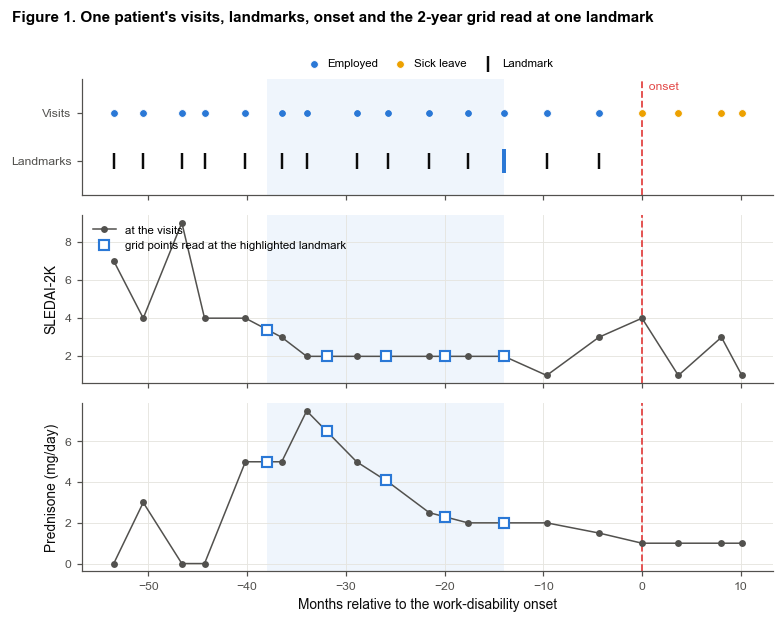

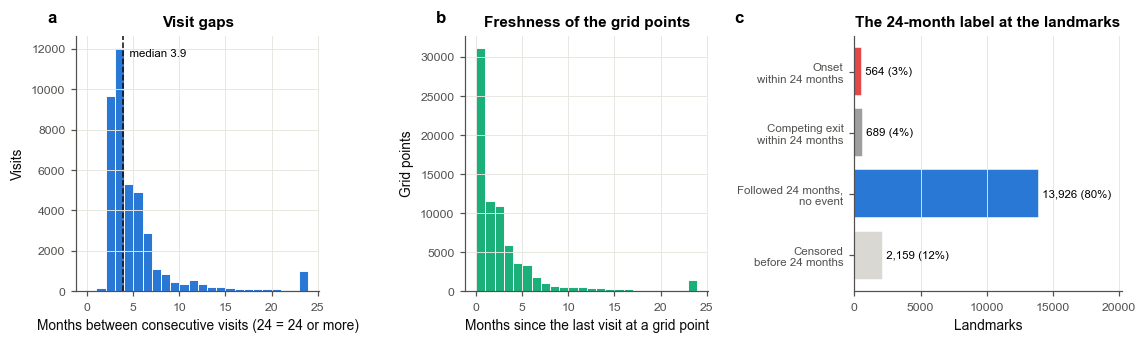

Example patient: 14 landmarks in the 6 years before the onset; highlighted landmark 14 months before the onset. Visit gaps: median 3.9 months, 90th percentile 9.0.


In [68]:
"""Figures 1-2: one patient's data handling; visit gaps, grid freshness and the 24-month label."""
_STATE_STYLE = {"W": ("Employed", "#2a78d6"), "S": ("Sick leave", "#eda100"), "D": ("Disabled", "#e34948"),
                "O": ("Other exit", "#9e9e9e"), "U": ("Not recorded", "#d9d8d3")}
_ev_pids = [p for p in FIRST_ONSET.index
            if (FIRST_ONSET[p] - visits.loc[_VIDX[p][0], "ASSDT"]).days > 4 * 365 and len(PT_ROWS.get(p, [])) >= 8]
EXAMPLE_PID = sorted(_ev_pids, key=lambda p: len(PT_ROWS[p]))[len(_ev_pids) // 2]
_vr = _VIDX[EXAMPLE_PID]
_pv = visits.iloc[_vr]
_e = FIRST_ONSET[EXAMPLE_PID]
_t0 = _e - pd.DateOffset(years=6)
_keep = (_pv["ASSDT"] >= _t0) & (_pv["ASSDT"] <= _e + pd.DateOffset(years=1))
_pv = _pv[_keep]
_li = PT_ROWS[EXAMPLE_PID]
_li = _li[(land["visit_date"].values[_li] >= np.datetime64(_t0)) & (land["visit_date"].values[_li] < np.datetime64(_e))]
_lshow = _li[np.argmin(np.abs((land["visit_date"].values[_li] - np.datetime64(_e - pd.DateOffset(months=12)))
                              / np.timedelta64(1, "D")))]                  # the landmark about a year before the onset
_gst, _gln = grid_window("24")
_gpts = GRID_RAW[_gst[_lshow]:_gst[_lshow] + _gln[_lshow]]
_gdates = land["visit_date"].values[_lshow] - (np.arange(_gln[_lshow])[::-1] * GRID_STEP_DAYS).astype("timedelta64[D]")

_rel = lambda d: (pd.to_datetime(np.asarray(d)) - _e).days.values / MONTH_DAYS if np.ndim(d) else \
    (pd.Timestamp(d) - _e).days / MONTH_DAYS                               # months relative to the onset (no dates shown)
_xl = _rel(land["visit_date"].values[_lshow])
fig, axes = plt.subplots(3, 1, figsize=(7.2, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.1, 1.6, 1.6]})
ax = axes[0]
for st_, (lab_, col_) in _STATE_STYLE.items():
    k = np.array([_state_of(e_) == st_ for e_ in _pv["EMP"].values])
    if k.any():
        ax.scatter(_rel(_pv["ASSDT"].values[k]), np.full(k.sum(), 1.0), s=26, color=col_, label=lab_, zorder=3,
                   edgecolor="white", linewidth=0.6)
ax.scatter(_rel(land["visit_date"].values[_li]), np.full(len(_li), 0.0), marker="|", s=120, color="#0b0b0b",
           label="Landmark", zorder=3)
ax.scatter([_xl], [0.0], marker="|", s=260, linewidths=2.6, color="#2a78d6", zorder=4)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Landmarks", "Visits"]); ax.set_ylim(-0.7, 1.7); ax.grid(False)
ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), handletextpad=0.2, columnspacing=0.9)
for a_ in axes:
    a_.axvline(0, color="#e34948", lw=1.2, ls="--")
    a_.axvspan(_rel(_gdates[0]), _xl, color="#2a78d6", alpha=0.07, lw=0)
axes[0].text(0, 1.55, "  onset", color="#e34948", fontsize=8, va="center")
for ax, col, lab_ in [(axes[1], "SLEDAI2_I", "SLEDAI-2K"), (axes[2], "STERAVER_0", "Prednisone (mg/day)")]:
    ax.plot(_rel(_pv["ASSDT"].values), _pv[col].values.astype(float), "-o", color=INK_2, ms=3.5, lw=1,
            label="at the visits")
    ax.plot(_rel(_gdates), _gpts[:, GRID_COLS.index(col)], "s", mfc="white", mec="#2a78d6", mew=1.4, ms=6,
            label="grid points read at the highlighted landmark")
    ax.set_ylabel(lab_)
axes[1].legend(loc="upper left")
axes[2].set_xlabel("Months relative to the work-disability onset")
fig.suptitle("Figure 1. One patient's visits, landmarks, onset and the 2-year grid read at one landmark", x=0.02,
             ha="left", fontsize=10, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig("fig01_data_handling_example")

_gap = (visits.groupby("PTNO")["ASSDT"].diff().dt.days / MONTH_DAYS).dropna()
_stale_pts = GRID_RAW[np.concatenate([np.arange(s_, s_ + l_) for s_, l_ in zip(*grid_window("24"))]),
                      GRID_COLS.index("GRID_STALE_MONTHS")]
rows_, y_, w_ = IPCW_H[H]
_lab_parts = {f"Onset\nwithin {H} months": int(((C_ALL == 1) & (T_ALL <= HORIZON_DAYS)).sum()),
              f"Competing exit\nwithin {H} months": int(((C_ALL >= 2) & (T_ALL <= HORIZON_DAYS)).sum()),
              f"Followed {H} months,\nno event": int((T_ALL > HORIZON_DAYS).sum()),
              f"Censored\nbefore {H} months": int(((C_ALL == 0) & (T_ALL <= HORIZON_DAYS)).sum())}
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), gridspec_kw={"width_ratios": [1, 1, 1.1]})
ax = axes[0]
ax.hist(np.clip(_gap, 0, 24), bins=np.arange(0, 24.5, 1), color="#2a78d6", edgecolor="white", linewidth=0.6)
ax.axvline(np.median(_gap), color="#0b0b0b", lw=1, ls="--")
ax.text(np.median(_gap), ax.get_ylim()[1] * 0.92, f"  median {np.median(_gap):.1f}", fontsize=7.5)
ax.set_xlabel("Months between consecutive visits (24 = 24 or more)"); ax.set_ylabel("Visits"); ax.set_title("Visit gaps")
ax = axes[1]
ax.hist(np.clip(_stale_pts, 0, 24), bins=np.arange(0, 24.5, 1), color="#1baf7a", edgecolor="white", linewidth=0.6)
ax.set_xlabel("Months since the last visit at a grid point"); ax.set_ylabel("Grid points")
ax.set_title("Freshness of the grid points")
ax = axes[2]
_cols = ["#e34948", "#9e9e9e", "#2a78d6", "#d9d8d3"]
_vals = np.array(list(_lab_parts.values()))
ax.barh(range(4), _vals, color=_cols, edgecolor="white")
for i_, v_ in enumerate(_vals):
    ax.text(v_, i_, f" {v_:,} ({v_ / _vals.sum():.0%})", va="center", fontsize=7.5)
ax.set_yticks(range(4)); ax.set_yticklabels(list(_lab_parts), fontsize=7.5); ax.invert_yaxis()
ax.set_xlim(0, _vals.max() * 1.45); ax.set_xlabel("Landmarks"); ax.set_title(f"The {H}-month label at the landmarks")
ax.grid(axis="y", visible=False)
for a_, l_, dx in zip(axes, "abc", [-0.12, -0.12, -0.45]):
    panel_label(a_, l_, dx)
plt.tight_layout()
save_fig("fig02_visits_grid_label")
print(f"Example patient: {len(_li)} landmarks in the 6 years before the onset; highlighted landmark {-_xl:.0f} months "
      f"before the onset. Visit gaps: median {np.median(_gap):.1f} months, 90th percentile "
      f"{np.percentile(_gap, 90):.1f}.")

## 11.4 Preprocessing and the models

Fitted on the training patients of each fold only (Section 5). Tabular inputs (the regressions): signed log1p of
skewed variables, the calendar year clipped to the training years, median imputation with a missing-value indicator,
standardisation. Grid inputs (the LSTMs): the same at every grid point, fitted on the grid points of the training
landmarks.

* **Grid LSTM**: a one-layer LSTM over the landmark's window of grid points (the last 2 years; S0: all history);
  its last hidden state plus a skip connection of the landmark point's inputs give the log-hazards.
  **One hazard** (DYN, S0, S1): two log-hazards (onset, competing exit), fitted on the intervals between landmarks
  (pooled over 24 months in S0). **Band hazards** (DYN-bands, S2, two-part): sixteen log-hazards (2 causes × eight
  6-month bands after the landmark), fitted on each landmark's whole follow-up to 48 months. **Two-part**: the
  Baseline's log-hazards (fitted on the same training patients) are added as a fixed offset, and the LSTM reads only
  the change channels.
* **Poisson regressions** (Baseline, Reg-pooled: one hazard; Reg-DYN: band hazards with a baseline per band and
  common covariate effects, i.e. proportional hazards across bands): ridge-penalised, fitted on the interval or band
  events with the exposure time as weight.
* **LogReg**: ridge logistic regression of the complete-case 24-month label.
* Risk at horizon *h* from the hazards (Section 4); an exclusive interval (a, b] uses the bands in it, starting from
  the patients still at risk at *a* (the one-hazard models give the same ranking in every interval).

In [69]:
"""Preprocessing, the cumulative incidence at any horizon, recalibration, thresholds and the model fit functions."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pack_sequence
from joblib import Parallel, delayed

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))


def _expit(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, float)))


def _logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def cif(eta, months):
    """Cumulative incidence of onset by `months` under constant cause-specific hazards exp(eta[:, 0]), exp(eta[:, 1])
    (per year)."""
    l1, l2 = np.exp(np.clip(eta[:, 0], -30, 5)), np.exp(np.clip(eta[:, 1], -30, 5))
    tot = l1 + l2
    return l1 / tot * -np.expm1(-tot * months / 12.0)


def cif_band(eta, a, b):
    """Cumulative incidence of onset in (a, b] months among those at risk at a, piecewise-constant hazards per 6-month
    band: eta[:, :N_BANDS] onset, eta[:, N_BANDS:] competing exit (log per year)."""
    l1 = np.exp(np.clip(eta[:, :N_BANDS], -30, 5)); l2 = np.exp(np.clip(eta[:, N_BANDS:], -30, 5))
    tot = l1 + l2
    out, S = np.zeros(len(eta)), np.ones(len(eta))
    for k in range(N_BANDS):
        dt = (min((k + 1) * BAND_MONTHS, b) - max(k * BAND_MONTHS, a)) / 12.0
        if dt <= 0:
            continue
        out += S * l1[:, k] / tot[:, k] * -np.expm1(-tot[:, k] * dt)
        S *= np.exp(-tot[:, k] * dt)
    return out


def raw_logit(eta, months):
    """Logit of a model's uncalibrated risk at `months` (cumulative incidence)."""
    if eta.shape[1] == 2 * N_BANDS:
        return _logit(cif_band(eta, 0, months))
    return _logit(cif(eta, months)) if eta.shape[1] == 2 else eta[:, 0].astype(float)


def raw_logit_iv(eta, a, b):
    """Logit of the uncalibrated risk of onset in (a, b] months among those at risk at a."""
    if eta.shape[1] == 2 * N_BANDS:
        return _logit(cif_band(eta, a, b))
    return raw_logit(eta, b - a)


class TabPrep:
    """Training-fold preprocessing of the landmark matrix for `cols`."""

    def __init__(self, cols):
        self.cols = list(cols)

    def _raw(self, X):
        Z = X[self.cols].astype(float).copy()
        for c in self.cols:
            if c in LOG1P_VARS:
                Z[c] = _slog1p(Z[c])
        return Z

    def fit(self, X):
        Z = self._raw(X)
        self.clip = {c: (Z[c].min(), Z[c].max()) for c in YEAR_COLS if c in self.cols}
        self.ind = [c for c in self.cols if LAND_X[c].isna().any()]
        self.med = Z.median()
        Zf = self._fill(Z)
        self.mu, self.sd = Zf.mean(), Zf.std().replace(0, 1.0).fillna(1.0)
        return self

    def _fill(self, Z):
        for c, (lo, hi) in self.clip.items():
            Z[c] = Z[c].clip(lo, hi)
        return Z.fillna(self.med)

    def transform(self, X):
        Z = self._raw(X)
        miss = Z[self.ind].isna().astype(float).values
        Z = ((self._fill(Z) - self.mu) / self.sd).clip(-CLIP_Z, CLIP_Z).values
        return np.hstack([Z, miss]).astype(np.float32)

    @property
    def names(self):
        return self.cols + [f"{c}__MISSING" for c in self.ind]


class VisPrep:
    """Training-fold preprocessing of the visit table (fitted on the training patients' visits)."""

    def __init__(self, cols):
        self.cols = list(cols)
        self.ci = [SEQ_ALL_COLS.index(c) for c in self.cols]
        self.log = np.array([c in LOG1P_VARS for c in self.cols])
        self.miss = [k for k, c in enumerate(self.cols) if np.isnan(VIS_RAW[:, self.ci[k]]).any()]

    def _raw(self, A):
        Z = A[:, self.ci].astype(np.float32)
        Z[:, self.log] = _slog1p(Z[:, self.log])
        return Z

    def fit(self, pids, max_day=None):
        rows = np.concatenate([_VIDX[p] for p in pids])
        if max_day is not None:
            rows = rows[_VDAYS[rows] < max_day]
        Z = self._raw(VIS_RAW[rows])
        self.yr = {k: (np.nanmin(Z[:, k]), np.nanmax(Z[:, k])) for k, c in enumerate(self.cols) if c in YEAR_COLS}
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        self.med = np.nan_to_num(np.nanmedian(Z, 0))
        Zf = np.where(np.isnan(Z), self.med, Z)
        self.mu, self.sd = Zf.mean(0), Zf.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def transform(self, A):
        Z = self._raw(A)
        miss = np.isnan(Z[:, self.miss]).astype(np.float32)
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        Z = np.where(np.isnan(Z), self.med, Z)
        Z = np.clip((Z - self.mu) / self.sd, -CLIP_Z, CLIP_Z)
        return np.hstack([Z, miss]).astype(np.float32)


class Recalibrator:
    """Logistic recalibration (intercept + slope on the logit)."""

    def fit(self, z, y, w=None):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(np.asarray(z, float)[:, None], np.asarray(y).astype(int),
                                                          sample_weight=w)
        self.a, self.b = float(lr.intercept_[0]), float(lr.coef_[0, 0])
        return self

    def transform_logit(self, z):
        return self.a + self.b * np.asarray(z, float)


def threshold_candidates(y, p):
    o = np.argsort(-p, kind="stable")
    ps, ys = p[o], y[o]
    tp, fp = np.cumsum(ys == 1), np.cumsum(ys == 0)
    last = np.r_[ps[1:] != ps[:-1], True]
    return np.r_[np.inf, ps[last]], np.r_[0, tp[last]], np.r_[0, fp[last]]


def choose_thresholds(y, p):
    """cost: max cost-weighted net benefit TP - FP / R with R = (1 - pi) / pi, which is the maximum of Youden's J
    (sensitivity + specificity - 1); ppv: the highest PPV among thresholds with sensitivity >= PPV_MIN_SENS."""
    y, p = np.asarray(y, int), np.asarray(p, float)
    cut, tp, fp = threshold_candidates(y, p)
    P, N = max(tp[-1], 1), max(fp[-1], 1)
    R = N / P
    out = {"cost": float(cut[int(np.argmax(tp - fp / R))])}
    sens = tp / P
    ppv = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0)
    ok = np.flatnonzero(sens >= PPV_MIN_SENS)
    out["ppv"] = float(cut[ok[np.argmax(ppv[ok])]]) if len(ok) else float(cut[-1])
    return out


# ---------------------------------------------------------------- the LSTM
class PatNet(nn.Module):
    """LSTM over a patient's visits; outputs at the landmark visits. n_out = 1 (binary logit) or 2 (log-hazards)."""

    def __init__(self, n_in, hidden, dropout, n_out):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, n_out)

    def forward(self, x_pad, lengths, pos_b, pos_t):
        packed = pack_padded_sequence(x_pad, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x_pad.shape[1])
        return self.head(torch.cat([self.drop(out[pos_b, pos_t]), x_pad[pos_b, pos_t]], -1))


def _patient_batch(pids, VX):
    """Padded visit tensors of `pids`, landmark positions, landmark rows and the batch's 24-month pooling matrix."""
    lens = [len(SEQ_VROWS[p]) for p in pids]
    T = max(lens)
    x = np.zeros((len(pids), T, VX.shape[1]), np.float32)
    pos_b, pos_t, rows, pi, pk, pw = [], [], [], [], [], []
    off = 0
    for b, p in enumerate(pids):
        x[b, :lens[b]] = VX[SEQ_VROWS[p]]
        lp = SEQ_LPOS[p]
        pos_b.append(np.full(len(lp), b)); pos_t.append(lp); rows.append(PT_ROWS[p])
        i_, k_, w_ = PT_POOL[p]
        pi.append(i_ + off); pk.append(k_ + off); pw.append(w_)
        off += len(lp)
    pool = torch.sparse_coo_tensor(np.vstack([np.concatenate(pi), np.concatenate(pk)]),
                                   np.concatenate(pw), (off, off)).coalesce()
    return (torch.from_numpy(x), torch.tensor(lens), torch.from_numpy(np.concatenate(pos_b)),
            torch.from_numpy(np.concatenate(pos_t)), np.concatenate(rows), pool)


def _split_patients(pids, ev, share, rng):
    pick = np.zeros(len(pids), bool)
    for g in (True, False):
        ix = np.flatnonzero(ev == g)
        if len(ix):
            pick[rng.choice(ix, max(1, int(round(share * len(ix)))), replace=False)] = True
    return pick


def default_arrays():
    """The training targets; temporal validation passes versions truncated at the end of development."""
    return {"D1": D_ONSET, "D2": D_COMP, "DT": INT_YRS, "Y": Y_ALL, "LAB": LABELLED, "USE": np.ones(N_LAND, bool)}


def fit_seq(cfg, VX, target, pooled, fit_pids, seed, pred_pids, arrs=None):
    """Train one LSTM on the patients `fit_pids`; return (landmark rows, raw scores) for `pred_pids` (scores: the two
    log-hazards for TTE, the logit for BIN; pooled over 24 months if `pooled`). Only rows with arrs['USE'] carry loss."""
    A = arrs or default_arrays()
    torch.set_num_threads(1)
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    fit_pids = np.asarray(fit_pids)
    has = (lambda p: (A["USE"][PT_ROWS[p]] & A["LAB"][PT_ROWS[p]]).any()) if target == "BIN" else \
        (lambda p: A["USE"][PT_ROWS[p]].any())
    fit_pids = np.array([p for p in fit_pids if has(p)])
    ev = np.array([(A["D1"][PT_ROWS[p]] * A["USE"][PT_ROWS[p]]).sum() > 0 for p in fit_pids])
    va_mask = _split_patients(fit_pids, ev, SEQ_TRAIN["val_share"], rng)
    tr_pts, va_pts = fit_pids[~va_mask], fit_pids[va_mask]
    n_out = 2 if target == "TTE" else 1
    net = PatNet(VX.shape[1], cfg["hidden"], cfg["dropout"], n_out)
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_pts])
    tr_rows = tr_rows[A["USE"][tr_rows]]
    with torch.no_grad():                      # start at the training patients' crude rates / onset share
        if target == "TTE":
            yrs = A["DT"][tr_rows].sum()
            net.head.bias[:] = torch.tensor([np.log(max(A["D1"][tr_rows].sum(), 1) / yrs),
                                             np.log(max(A["D2"][tr_rows].sum(), 1) / yrs)])
        else:
            net.head.bias[:] = float(_logit(np.nanmean(A["Y"][tr_rows])))
    opt = torch.optim.AdamW(net.parameters(), lr=SEQ_TRAIN["lr"], weight_decay=cfg["weight_decay"])
    use_t = torch.from_numpy(A["USE"])

    def scores(pids_b):
        x, lens, pb, pt, rows, pool = _patient_batch(pids_b, VX)
        z = net(x, lens, pb, pt)
        if pooled:
            z = torch.sparse.mm(pool, z)
        return z, rows

    def loss_of(pids_b):
        z, rows = scores(pids_b)
        use = use_t[rows]
        if target == "TTE":
            eta = z.clamp(-20, 5)
            d1, d2 = torch.from_numpy(A["D1"][rows]), torch.from_numpy(A["D2"][rows])
            dt = torch.from_numpy(A["DT"][rows])
            nll = -(d1 * eta[:, 0] + d2 * eta[:, 1] - (torch.exp(eta[:, 0]) + torch.exp(eta[:, 1])) * dt)
            return nll[use].sum(), float(use.sum())
        lab = torch.from_numpy(A["LAB"][rows]) & use
        y = torch.from_numpy(np.nan_to_num(A["Y"][rows]).astype(np.float32))
        bce = nn.functional.binary_cross_entropy_with_logits(z[:, 0][lab], y[lab], reduction="sum")
        return bce, float(lab.sum())

    def val_loss():
        l_, n_ = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_pts), 128):
                l, n = loss_of(va_pts[i:i + 128]); l_ += float(l); n_ += n
        return l_ / max(n_, 1.0)

    best, best_state, bad = np.inf, None, 0
    bp = SEQ_TRAIN["batch_patients"]
    for ep in range(SEQ_TRAIN["max_epochs"]):
        net.train()
        perm = rng.permutation(tr_pts)
        for i in range(0, len(perm), bp):
            l, n = loss_of(perm[i:i + bp])
            if n == 0:
                continue
            opt.zero_grad(); (l / n).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        vl = val_loss()
        if vl < best - 1e-6:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= SEQ_TRAIN["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    rows_out, z_out = [], []
    with torch.no_grad():
        pred_pids = np.asarray(pred_pids)
        for i in range(0, len(pred_pids), 128):
            z, rows = scores(pred_pids[i:i + 128])
            z_out.append(z.numpy().astype(float)); rows_out.append(rows)
    if return_net:
        return np.concatenate(rows_out), np.concatenate(z_out), {k: v.clone() for k, v in net.state_dict().items()}
    return np.concatenate(rows_out), np.concatenate(z_out)


# ---------------------------------------------------------------- the grid LSTM (main model)
class GridPrep:
    """Training-fold preprocessing of the grid points: signed log1p, calendar year clipped to the training years,
    median imputation + missing-value indicator, standardisation; fitted on the grid points of the training landmarks."""

    def __init__(self, cols=GRID_COLS):
        self.cols = list(cols)
        self.ci = [GRID_COLS.index(c) for c in self.cols]
        self.log = np.array([c in LOG1P_VARS for c in self.cols])
        self.miss = [k for k, c in enumerate(self.cols) if np.isnan(GRID_RAW[:, self.ci[k]]).any()]

    def _raw(self, A):
        Z = A[:, self.ci].astype(np.float32)
        Z[:, self.log] = _slog1p(Z[:, self.log])
        return Z

    def fit(self, land_rows, max_points=150_000, seed=SEED):
        pts = np.concatenate([np.arange(LG_START[i], LG_START[i] + LG_LEN[i]) for i in land_rows])
        if len(pts) > max_points:
            pts = np.random.RandomState(seed).choice(pts, max_points, replace=False)
        Z = self._raw(GRID_RAW[pts])
        self.yr = {k: (np.nanmin(Z[:, k]), np.nanmax(Z[:, k])) for k, c in enumerate(self.cols) if c in YEAR_COLS}
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        self.med = np.nan_to_num(np.nanmedian(Z, 0))
        Zf = np.where(np.isnan(Z), self.med, Z)
        self.mu, self.sd = Zf.mean(0), Zf.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def transform(self, A):
        Z = self._raw(A)
        miss = np.isnan(Z[:, self.miss]).astype(np.float32)
        for k, (lo, hi) in self.yr.items():
            Z[:, k] = np.clip(Z[:, k], lo, hi)
        Z = np.where(np.isnan(Z), self.med, Z)
        Z = np.clip((Z - self.mu) / self.sd, -CLIP_Z, CLIP_Z)
        return np.hstack([Z, miss]).astype(np.float32)

    @property
    def names(self):
        return self.cols + [f"{self.cols[k]}__MISSING" for k in self.miss]


class GridNet(nn.Module):
    """LSTM over a landmark's window of grid points; two log-hazards from its last hidden state + the landmark point."""

    def __init__(self, n_in, hidden, dropout, n_out=2):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + n_in, n_out)

    def forward(self, packed, x_last):
        _, (h, _) = self.rnn(packed)
        return self.head(torch.cat([self.drop(h[-1]), x_last], -1))


def _grid_batch(pids, VX, st, ln):
    """Packed grid windows of every landmark of `pids`, the landmark points, the landmark rows and the batch's
    24-month pooling matrix."""
    rows, pi, pk, pw = [], [], [], []
    off = 0
    for p in pids:
        r = PT_ROWS[p]
        i_, k_, w_ = PT_POOL[p]
        rows.append(r); pi.append(i_ + off); pk.append(k_ + off); pw.append(w_)
        off += len(r)
    rows = np.concatenate(rows)
    seqs = [torch.from_numpy(np.array(VX[st[i]:st[i] + ln[i]])) for i in rows]
    x_last = torch.from_numpy(np.array(VX[st[rows] + ln[rows] - 1]))
    pool = torch.sparse_coo_tensor(np.vstack([np.concatenate(pi), np.concatenate(pk)]),
                                   np.concatenate(pw), (off, off)).coalesce()
    return pack_sequence(seqs, enforce_sorted=False), x_last, rows, pool


def fit_grid(cfg, VX, st, ln, fit_pids, seed, pred_pids, hazard="band", pooled=False, offset=None, return_net=False,
             arrs=None):
    """Train one grid LSTM on the patients `fit_pids`, reading the window (st, ln) of each landmark; return (landmark
    rows, log-hazards incl. the offset) for `pred_pids`. hazard 'const': 2 log-hazards on the intervals between
    landmarks (pooled over 24 months if `pooled`); 'band': 2 x N_BANDS log-hazards on the landmark's follow-up to
    48 months. offset: (N_LAND, 2) fixed log-hazards added to every band (two-part model). arrs: one-hazard targets
    truncated at the end of development (temporal hold-out; only rows with arrs['USE'] carry loss)."""
    torch.set_num_threads(1)
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    A = arrs or default_arrays()
    assert arrs is None or hazard == "const", "truncated targets are implemented for the one-hazard models only"
    fit_pids = np.asarray(fit_pids)
    fit_pids = np.array([p for p in fit_pids if A["USE"][PT_ROWS[p]].any()])
    ev = np.array([(A["D1"][PT_ROWS[p]] * A["USE"][PT_ROWS[p]]).sum() > 0 for p in fit_pids])
    va_mask = _split_patients(fit_pids, ev, SEQ_TRAIN["val_share"], rng)
    tr_pts, va_pts = fit_pids[~va_mask], fit_pids[va_mask]
    band = hazard == "band"
    nb = N_BANDS if band else 1
    net = GridNet(VX.shape[1], cfg["hidden"], cfg["dropout"], n_out=2 * nb)
    tr_rows = np.concatenate([PT_ROWS[p] for p in tr_pts])
    tr_rows = tr_rows[A["USE"][tr_rows]]
    off_t = torch.from_numpy(np.zeros((N_LAND, 2), np.float32) if offset is None else offset.astype(np.float32))
    with torch.no_grad():                      # start at the training patients' crude rates (net of the offset)
        if band:
            yrs = np.maximum(BAND_DT[tr_rows].sum(0), 1e-6)
            r1 = np.log(np.maximum(BAND_D1[tr_rows].sum(0), 1) / yrs); r2 = np.log(np.maximum(BAND_D2[tr_rows].sum(0), 1) / yrs)
        else:
            yrs = A["DT"][tr_rows].sum()
            r1 = np.log([max(A["D1"][tr_rows].sum(), 1) / yrs]); r2 = np.log([max(A["D2"][tr_rows].sum(), 1) / yrs])
        if offset is not None:
            r1 = r1 - offset[tr_rows, 0].mean(); r2 = r2 - offset[tr_rows, 1].mean()
        net.head.bias[:] = torch.tensor(np.r_[r1, r2], dtype=torch.float32)
    opt = torch.optim.AdamW(net.parameters(), lr=SEQ_TRAIN["lr"], weight_decay=cfg["weight_decay"])

    def scores(pids_b):
        packed, x_last, rows, pool = _grid_batch(pids_b, VX, st, ln)
        z = net(packed, x_last)
        if pooled:
            z = torch.sparse.mm(pool, z)
        o = off_t[rows]
        z = torch.cat([z[:, :nb] + o[:, :1], z[:, nb:] + o[:, 1:]], 1)
        return z, rows

    def loss_of(pids_b):
        z, rows = scores(pids_b)
        eta = z.clamp(-20, 5)
        if band:
            d1, d2, dt = (torch.from_numpy(a_[rows]) for a_ in (BAND_D1, BAND_D2, BAND_DT))
            nll = -(d1 * eta[:, :nb] + d2 * eta[:, nb:] - (torch.exp(eta[:, :nb]) + torch.exp(eta[:, nb:])) * dt)
            return nll.sum(), float(len(rows))
        d1, d2, dt = (torch.from_numpy(np.asarray(a_[rows], np.float32)) for a_ in (A["D1"], A["D2"], A["DT"]))
        u = torch.from_numpy(A["USE"][rows].astype(np.float32))
        nll = -(d1 * eta[:, 0] + d2 * eta[:, 1] - (torch.exp(eta[:, 0]) + torch.exp(eta[:, 1])) * dt) * u
        return nll.sum(), float(u.sum())

    def val_loss():
        l_, n_ = 0.0, 0.0
        with torch.no_grad():
            for i in range(0, len(va_pts), 128):
                l, n = loss_of(va_pts[i:i + 128]); l_ += float(l); n_ += n
        return l_ / max(n_, 1.0)

    best, best_state, bad = np.inf, None, 0
    bp = SEQ_TRAIN["batch_patients"]
    for ep in range(SEQ_TRAIN["max_epochs"]):
        net.train()
        perm = rng.permutation(tr_pts)
        for i in range(0, len(perm), bp):
            l, n = loss_of(perm[i:i + bp])
            opt.zero_grad(); (l / n).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        vl = val_loss()
        if vl < best - 1e-6:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= SEQ_TRAIN["patience"]:
                break
    net.load_state_dict(best_state)
    net.eval()
    rows_out, z_out = [], []
    with torch.no_grad():
        pred_pids = np.asarray(pred_pids)
        for i in range(0, len(pred_pids), 128):
            z, rows = scores(pred_pids[i:i + 128])
            z_out.append(z.numpy().astype(float)); rows_out.append(rows)
    if return_net:
        return np.concatenate(rows_out), np.concatenate(z_out), {k: v.clone() for k, v in net.state_dict().items()}
    return np.concatenate(rows_out), np.concatenate(z_out)


# ---------------------------------------------------------------- the regressions
def reg_design(model, prep, rows):
    """Standardised regression inputs at `rows` (whole patients); Pk: their k-month running mean."""
    X = prep.transform(LAND_X.iloc[rows])
    k = parse_model(model)["pool"]
    if k > 0:
        X = np.asarray(POOLS[k][rows][:, rows] @ X, np.float32)
    return X


def fit_reg(model, cfg, prep_rows, fit_rows, pred_rows, arrs=None):
    """Fit a regression on the (whole-patient) rows fit_rows; loss on the rows with arrs['USE']. Returns the raw scores
    at pred_rows (n x 2 log-hazards for TTE, n x 1 logit for BIN) and (prep, fitted models)."""
    A = arrs or default_arrays()
    t = parse_model(model)["target"]
    prep = TabPrep(reg_cols_of(model)).fit(LAND_X.iloc[prep_rows])
    X, Xp = reg_design(model, prep, fit_rows), reg_design(model, prep, pred_rows)
    use = A["USE"][fit_rows]
    if t == "BIN":
        k = use & A["LAB"][fit_rows]
        m = LogisticRegression(C=cfg["C"], max_iter=3000).fit(X[k], A["Y"][fit_rows][k].astype(int))
        return m.decision_function(Xp)[:, None], (prep, [m])
    if is_band(model):
        return _fit_reg_band(cfg, prep, X[use], Xp, fit_rows[use])
    dt = A["DT"][fit_rows].astype(float)
    fits = [PoissonRegressor(alpha=cfg["alpha"], max_iter=3000).fit(X[use], (d[fit_rows] / np.maximum(dt, 1e-9))[use],
                                                                    sample_weight=dt[use])
            for d in (A["D1"], A["D2"])]
    eta = np.column_stack([np.log(np.maximum(f_.predict(Xp), 1e-12)) for f_ in fits])
    return eta, (prep, fits)


BAND_SCALE = 10.0                              # band indicators scaled up so the ridge penalty barely touches them


def _fit_reg_band(cfg, prep, X, Xp, fit_rows):
    """Band-hazard ridge Poisson regressions: one row per (landmark, band) with exposure; band indicators + inputs."""
    dt = BAND_DT[fit_rows]
    li, bi = np.nonzero(dt > 0)
    E = np.eye(N_BANDS, dtype=np.float32)[bi] * BAND_SCALE
    Xe = np.hstack([X[li], E])
    w = dt[li, bi].astype(float)
    fits = []
    for D in (BAND_D1, BAND_D2):
        y = D[fit_rows][li, bi] / np.maximum(w, 1e-9)
        fits.append(PoissonRegressor(alpha=cfg["alpha"], max_iter=3000).fit(Xe, y, sample_weight=w))
    eta = np.hstack([(Xp @ f_.coef_[:-N_BANDS] + f_.intercept_)[:, None] + BAND_SCALE * f_.coef_[-N_BANDS:][None, :]
                     for f_ in fits])
    return eta, (prep, fits)


def model_grid(model):
    if is_reg(model):
        if parse_model(model)["target"] == "BIN":
            return {f"C{c:g}": {"C": c} for c in LOGREG_C_GRID}
        return {f"a{a:g}": {"alpha": a} for a in POISSON_ALPHA_GRID}
    return {"fixed": SEQ_CFG}

## 11.5 Repeated cross-validation

5 × 5-fold, patient-grouped, stratified by whether the patient ever has an onset (fixed seeds, so the folds are the
same for every model). Inside each training fold, 3 patient-grouped inner folds give out-of-fold (OOF) scores at
every landmark of every training patient; they are kept for the recalibration and thresholds of Section 11.6, which
are learned per horizon on the training fold only. The regressions choose their penalty on the inner OOF 24-month
AUROC; the LSTMs have one fixed configuration (nothing is tuned) and are refitted on the whole training fold
(5 seeds) to score the test fold. Every fit is checkpointed in `cv_state_update_v13.pkl`, so an interrupted run
resumes where it stopped.

In [70]:
"""The cross-validation engine."""
ALL_PIDS = np.array(sorted(land["pid"].unique()))
PID_EVENT = land.groupby("pid")["pt_event"].max().reindex(ALL_PIDS).values
PID_INDEX = {p: i for i, p in enumerate(ALL_PIDS)}
ROW_PIDX = np.array([PID_INDEX[p] for p in PID_ALL])


def patient_folds(pids, n_splits, seed):
    from sklearn.model_selection import StratifiedKFold
    ev = PID_EVENT[[PID_INDEX[p] for p in pids]]
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return [(pids[a], pids[b]) for a, b in skf.split(np.zeros(len(pids)), ev)]


OUTER = {r: patient_folds(ALL_PIDS, CV_N_SPLITS, SEED + 1000 * r) for r in range(CV_N_REPEATS)}


def rows_of(pids):
    return np.flatnonzero(np.isin(PID_ALL, pids))


def _load(path, empty):
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return empty


def _save(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f)
    os.replace(tmp, path)


cv_state = _load(CV_STATE_PATH, {"folds": {}})


def fit_and_score(model, r, f, tr_p, te_p, tr_rows, tr_lab, te_rows, inner):
    """Tune (regression) on inner OOF scores, refit on the whole training fold and score te_rows. Returns the raw
    scores of the test rows and the OOF raw scores of the training rows."""
    t0 = time.time()
    grid = model_grid(model)
    d = parse_model(model)
    k_out = 2 * N_BANDS if d["hazard"] == "band" else 1 if d["target"] == "BIN" else 2
    oofs, coef = {}, None
    if is_grid(model):
        sets = [(a_p, b_p) for a_p, b_p in inner] + [(tr_p, te_p)]
        st, ln = grid_window(d["lookback"])
        VXs = [GridPrep(grid_cols_of(model)).fit(rows_of(a_p)).transform(GRID_RAW) for a_p, _ in sets]
        offs = [None] * len(sets)
        if d["offset"] == "trait":              # the Baseline fitted on each set's training patients
            for j, (a_p, b_p) in enumerate(sets):
                a_r, all_r = rows_of(a_p), rows_of(np.r_[a_p, b_p])
                o = np.zeros((N_LAND, 2), np.float32)
                o[all_r] = fit_reg(BASELINE, {"alpha": TRAIT_ALPHA}, a_r, a_r, all_r)[0]
                offs[j] = o
        k_out = 2 * N_BANDS if d["hazard"] == "band" else 2
        tasks = []
        for j, (a_p, b_p) in enumerate(sets):
            n = SEQ_SEEDS_FINAL if j == len(sets) - 1 else SEQ_SEEDS_INNER
            for s in range(n):
                tasks.append((j, delayed(fit_grid)(grid["fixed"], VXs[j], st, ln, a_p,
                                                   SEED + 1000 * j + 31 * s + 7 * r + f, b_p, d["hazard"],
                                                   d["pool"] > 0, offs[j])))
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")([t_[1] for t_ in tasks])
        z = [np.zeros((N_LAND, k_out)) for _ in sets]; cnt = [np.zeros(N_LAND) for _ in sets]
        for (j, _), (rows, zz) in zip(tasks, res):
            z[j][rows] += zz; cnt[j][rows] += 1
        oof = np.full((N_LAND, k_out), np.nan)
        for j in range(len(inner)):
            k = cnt[j] > 0
            oof[k] = z[j][k] / cnt[j][k][:, None]
        oofs["fixed"] = oof
        best = "fixed"
        eta_te = z[-1][te_rows] / np.maximum(cnt[-1][te_rows], 1)[:, None]
    elif is_seq(model):
        sets = [(a_p, b_p) for a_p, b_p in inner] + [(tr_p, te_p)]
        VXs = [VisPrep(seq_cols_of(model)).fit(a_p).transform(VIS_RAW) for a_p, _ in sets]
        tasks = []
        for j, (a_p, b_p) in enumerate(sets):
            n = SEQ_SEEDS_FINAL if j == len(sets) - 1 else SEQ_SEEDS_INNER
            for s in range(n):
                tasks.append((j, delayed(fit_seq)(grid["fixed"], VXs[j], d["target"], d["pool"] > 0, a_p,
                                                  SEED + 1000 * j + 31 * s + 7 * r + f, b_p)))
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")([t_[1] for t_ in tasks])
        z = [np.zeros((N_LAND, k_out)) for _ in sets]; cnt = [np.zeros(N_LAND) for _ in sets]
        for (j, _), (rows, zz) in zip(tasks, res):
            z[j][rows] += zz; cnt[j][rows] += 1
        oof = np.full((N_LAND, k_out), np.nan)
        for j in range(len(inner)):
            k = cnt[j] > 0
            oof[k] = z[j][k] / cnt[j][k][:, None]
        oofs["fixed"] = oof
        best = "fixed"
        eta_te = z[-1][te_rows] / np.maximum(cnt[-1][te_rows], 1)[:, None]
    else:
        prep_rows_of = (lambda rows: rows[LABELLED[rows]]) if d["target"] == "BIN" else (lambda rows: rows)
        for name, cfg in grid.items():
            oof = np.full((N_LAND, k_out), np.nan)
            for a_p, b_p in inner:
                a, b = rows_of(a_p), rows_of(b_p)
                oof[b] = fit_reg(model, cfg, prep_rows_of(a), a, b)[0]
            oofs[name] = oof
        scores = {name: roc_auc_score(Y_ALL[tr_lab], raw_logit(o[tr_lab], H)) for name, o in oofs.items()}
        best = max(scores, key=scores.get)
        eta_te, (prep, fits) = fit_reg(model, grid[best], prep_rows_of(tr_rows), tr_rows, te_rows)
        coef = {"names": prep.names, "coef": np.vstack([f_.coef_.ravel() for f_ in fits])}
    return {"model": model, "best": best, "te_rows": te_rows, "eta_te": eta_te.astype(np.float32),
            "tr_rows": tr_rows, "eta_oof": oofs[best][tr_rows].astype(np.float32), "coef": coef,
            "seconds": time.time() - t0}


def run_fold(model, r, f):
    tr_p, te_p = OUTER[r][f]
    tr_rows, te_rows = rows_of(tr_p), rows_of(te_p)
    tr_lab = tr_rows[LABELLED[tr_rows]]
    inner = patient_folds(tr_p, CV_INNER_SPLITS, SEED + 7 * r + 13 * f)
    res = fit_and_score(model, r, f, tr_p, te_p, tr_rows, tr_lab, te_rows, inner)
    res.update({"r": r, "f": f})
    return res


def run_cv(models=tuple(FIT_MODELS)):
    for model in models:
        for r in range(CV_N_REPEATS):
            for f in range(CV_N_SPLITS):
                key = (model, r, f)
                if key in cv_state["folds"]:
                    continue
                res = run_fold(model, r, f)
                cv_state["folds"][key] = res
                _save(cv_state, CV_STATE_PATH)
                print(f"  {short_label(model):<14} repeat {r + 1} fold {f + 1}: {res['best']:<8} | "
                      f"{res['seconds'] / 60:.1f} min", flush=True)


# The regressions first (fast), then the main model, then the other LSTMs
t_cv = time.time()
run_cv([m for m in FIT_MODELS if is_reg(m)] + [MAIN_MODEL] + [m for m in FIT_MODELS if is_grid(m) and m != MAIN_MODEL])
print(f"Cross-validation complete: {len(cv_state['folds'])} fits ({(time.time() - t_cv) / 60:.1f} min this session)")
for m in NEW_MODELS:
    sec = [cv_state["folds"][(m, r, f)]["seconds"] for r in range(CV_N_REPEATS) for f in range(CV_N_SPLITS)
           if (m, r, f) in cv_state["folds"]]
    if sec:
        print(f"  {short_label(m):<11} {len(sec)} folds, median {np.median(sec) / 60:.1f} min per fold")

Cross-validation complete: 250 fits (0.0 min this session)
  S0 pooled   25 folds, median 2.9 min per fold
  S1 no-pool  25 folds, median 1.3 min per fold
  S2 bands    25 folds, median 0.3 min per fold
  DYN-bands   25 folds, median 0.4 min per fold
  DYN         25 folds, median 0.4 min per fold
  Two-part    25 folds, median 0.3 min per fold
  Reg-DYN     25 folds, median 0.1 min per fold
  LogReg      25 folds, median 0.0 min per fold
  Reg-pooled  25 folds, median 0.1 min per fold
  Baseline    25 folds, median 0.0 min per fold


## 11.6 Recalibration, thresholds and patient scores at every horizon

For each fit and each horizon *h* (6-48 months), **inside the training fold**:

1. the model's raw *h*-month risk (the cumulative incidence for the survival models; the 24-month logit for LogReg) is
   recalibrated by a logistic regression of the complete-case *h*-month label on its logit, fitted on the training
   patients' OOF scores, and the same map is applied to the test fold;
2. the **visit alarm threshold** is chosen on the training patients' recalibrated OOF risks (max Youden, Section
   7; max PPV as an alternative);
3. each training patient's **patient score** (the mean logit of the recalibrated risk over the patient's window,
   Section 9) gives the **patient threshold** and a logistic map from patient score to the probability of being
   an event patient (patient-level calibration).

Exclusive intervals (a, b]: the raw risk of an onset in (a, b] among those at risk at *a* (from the bands in the
interval; for the one-hazard models the same ranking in every interval) is recalibrated on the training landmarks
still at risk at *a*. The **Average** is the mean of the recalibrated logits
of the dynamic LSTM and the dynamic regression, with its own thresholds from the averaged OOF risks.

In [71]:
"""Per-fold recalibration and thresholds at every horizon; pooled test-fold predictions."""
ALL_FOLDS = dict(cv_state["folds"])
COMPLETE = {m: [r for r in range(CV_N_REPEATS) if all((m, r, f) in ALL_FOLDS for f in range(CV_N_SPLITS))]
            for m in FIT_MODELS}
MODELS_RUN = [m for m in FIT_MODELS if COMPLETE[m]]
REPEATS = sorted(set.intersection(*[set(COMPLETE[m]) for m in MODELS_RUN]))
if all(m in MODELS_RUN for m in AVG_PARTS):
    MODELS_RUN.append(AVG_MODEL)
BEST_CFG = {m: [ALL_FOLDS[(m, r, f)]["best"] for r in REPEATS for f in range(CV_N_SPLITS)] for m in FIT_MODELS
            if m in MODELS_RUN}
print(f"Models with complete repeats: {len(MODELS_RUN)} | repeats used: {len(REPEATS)}")
for m in [m for m in MODELS_RUN if m != AVG_MODEL and is_reg(m)]:
    print(f"  {short_label(m):<14} penalty chosen: " + ", ".join(
        f"{k} x{v}" for k, v in pd.Series(BEST_CFG[m]).value_counts().items()))


def label_interval(a, b):
    """Complete-case label for an onset in (a, b] among landmarks at risk at a (NaN: not at risk or unresolved)."""
    lo, hi = hdays(a), hdays(b)
    lab = np.where((C_ALL == 1) & (T_ALL <= hi), 1.0, np.where((T_ALL > hi) | (C_ALL >= 2), 0.0, np.nan))
    lab[T_ALL <= lo] = np.nan
    lab[_ADMIN < hi] = np.nan
    return lab


LABEL_INT = {iv: label_interval(*iv) for iv in INTERVALS}
TARGETS_ = [("h", h) for h in HORIZONS] + [("iv",) + iv for iv in INTERVALS]


def _target_label(tg):
    return LABEL_H[tg[1]] if tg[0] == "h" else LABEL_INT[(tg[1], tg[2])]


def _target_months(tg):
    return tg[1] if tg[0] == "h" else tg[2] - tg[1]


_FOLD_CAL = {}


def fold_cal(m, r, f, tg):
    """(training rows, recalibrated OOF logits there, test rows, recalibrated test logits) for target tg."""
    key = (m, r, f, tg)
    if key in _FOLD_CAL:
        return _FOLD_CAL[key]
    if m == AVG_MODEL:
        parts = [fold_cal(p, r, f, tg) for p in AVG_PARTS]
        out = (parts[0][0], np.mean([p_[1] for p_ in parts], 0), parts[0][2], np.mean([p_[3] for p_ in parts], 0))
    else:
        res = ALL_FOLDS[(m, r, f)]
        eo, et = res["eta_oof"].astype(float), res["eta_te"].astype(float)
        if tg[0] == "h":
            zo, zt = raw_logit(eo, tg[1]), raw_logit(et, tg[1])
        else:
            zo, zt = raw_logit_iv(eo, tg[1], tg[2]), raw_logit_iv(et, tg[1], tg[2])
        lab = _target_label(tg)[res["tr_rows"]]
        k = ~np.isnan(lab) & ~np.isnan(zo)
        cal = Recalibrator().fit(zo[k], lab[k])
        out = (res["tr_rows"], cal.transform_logit(zo), res["te_rows"], cal.transform_logit(zt))
    _FOLD_CAL[key] = out
    return out


def run2_score(z, rows_list):
    """Highest logit reached at 2 consecutive landmarks of each window (the single landmark if only one)."""
    return np.array([z[r][0] if len(r) == 1 else np.minimum(z[r][1:], z[r][:-1]).max() for r in rows_list])


PRED, THR_V, THR_P, PCAL, THR_RUN2, OOF_H = {}, {}, {}, {}, {}, {}
t0 = time.time()
for m in MODELS_RUN:
    for r in REPEATS:
        for tg in TARGETS_:
            z_full = np.full(N_LAND, np.nan)
            tv = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            tp = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            pa, pb = np.full(N_LAND, np.nan), np.full(N_LAND, np.nan)
            t2 = {c: np.full(N_LAND, np.nan) for c in THRESHOLD_RULES}
            for f in range(CV_N_SPLITS):
                tr, zo, te, zt = fold_cal(m, r, f, tg)
                z_full[te] = zt
                if tg == ("h", H):
                    OOF_H[(m, r, f)] = (tr, zo)
                if tg[0] != "h":
                    continue
                h = tg[1]
                lab = LABEL_H[h][tr]
                k = ~np.isnan(lab)
                thr = choose_thresholds(lab[k], zo[k])
                for c in THRESHOLD_RULES:
                    tv[c][te] = thr[c]
                # patient level: the training patients' windows, scored with their OOF risks
                W = PTW[h]
                oof = np.full(N_LAND, np.nan); oof[tr] = zo
                in_tr = np.isin(W["pids"], OUTER[r][f][0])
                s = np.asarray(W["mat"][in_tr] @ np.nan_to_num(oof)).ravel()
                ev = W["event"][in_tr]
                thr_p = choose_thresholds(ev, s)
                pc = Recalibrator().fit(s, ev)
                for c in THRESHOLD_RULES:
                    tp[c][te] = thr_p[c]
                pa[te], pb[te] = pc.a, pc.b
                if h == H:
                    s2 = run2_score(oof, [W["rows"][i] for i in np.flatnonzero(in_tr)])
                    thr2 = choose_thresholds(ev, s2)
                    for c in THRESHOLD_RULES:
                        t2[c][te] = thr2[c]
            PRED.setdefault(m, {}).setdefault(r, {})[tg] = z_full
            if tg[0] == "h":
                THR_V.setdefault(m, {}).setdefault(r, {})[tg[1]] = tv
                THR_P.setdefault(m, {}).setdefault(r, {})[tg[1]] = tp
                PCAL.setdefault(m, {}).setdefault(r, {})[tg[1]] = (pa, pb)
                if tg[1] == H:
                    THR_RUN2.setdefault(m, {})[r] = t2
_FOLD_CAL.clear()
print(f"Recalibration and thresholds at {len(HORIZONS)} horizons and {len(INTERVALS)} intervals: "
      f"{(time.time() - t0) / 60:.1f} min")


def zpred(m, r, h=H):
    return PRED[m][r][("h", h)]


def mean_z(m, h=H):
    return np.nanmean(np.vstack([zpred(m, r, h) for r in REPEATS]), 0)


def patient_score_rs(m, z):
    """Risk-set score at every landmark: the model's own score (pooled models already average 24 months; the others
    are NOT averaged, so a recent change can count)."""
    return z

Models with complete repeats: 11 | repeats used: 5
  Reg-DYN        penalty chosen: a0.03 x12, a0.1 x7, a0.01 x4, a0.0003 x1, a0.3 x1
  LogReg         penalty chosen: C0.001 x12, C0.003 x11, C0.1 x1, C0.01 x1
  Reg-pooled     penalty chosen: a0.03 x11, a0.1 x8, a0.01 x5, a0.001 x1
  Baseline       penalty chosen: a0.0001 x10, a0.1 x6, a0.03 x4, a0.0003 x3, a0.3 x1, a0.001 x1
Recalibration and thresholds at 8 horizons and 4 intervals: 0.5 min


## 11.6b What the hazards look like

The survival models predict hazards, not risks (Section 4). **Figure 3** shows them on the held-out predictions
(each landmark scored by a model that never saw the patient; mean over the CV repeats):

* **(a) Hazard by time since the visit.** The observed onset and competing-exit rates (events per 100
  person-years) in each 6-month band after the landmark, pooled over all landmarks (95 % exact Poisson CI), against
  the mean hazard each model assigns to that band (exposure-weighted): DYN assumes one constant hazard from the visit
  onwards, DYN-bands lets it change by band. Overlapping follow-up of successive landmarks is counted for each
  landmark (the same quantity both models are fitted on).
* **(b) How spread out the hazards are.** DYN's onset hazard across landmarks (log scale), separately for landmarks
  followed by an onset within 24 months and the rest.
* **(c) From hazards to risk.** Landmarks in fifths of DYN's onset hazard: the cumulative incidence implied by the
  two constant hazards (lines; raw, before recalibration) against the observed cumulative incidence at 6-48 months
  (IPCW; points with an approximate 95 % CI that treats landmarks as independent). If the constant-hazard extrapolation holds, the points follow the lines; a systematic
  gap is what the recalibration (Section 7) corrects at the 24-month horizon.
* **(d) Within a patient.** DYN's onset hazard is a step function that changes at every visit: the hazard at each
  landmark of the example patient of Figure 1 before their onset, against a patient of similar age who stays at work.

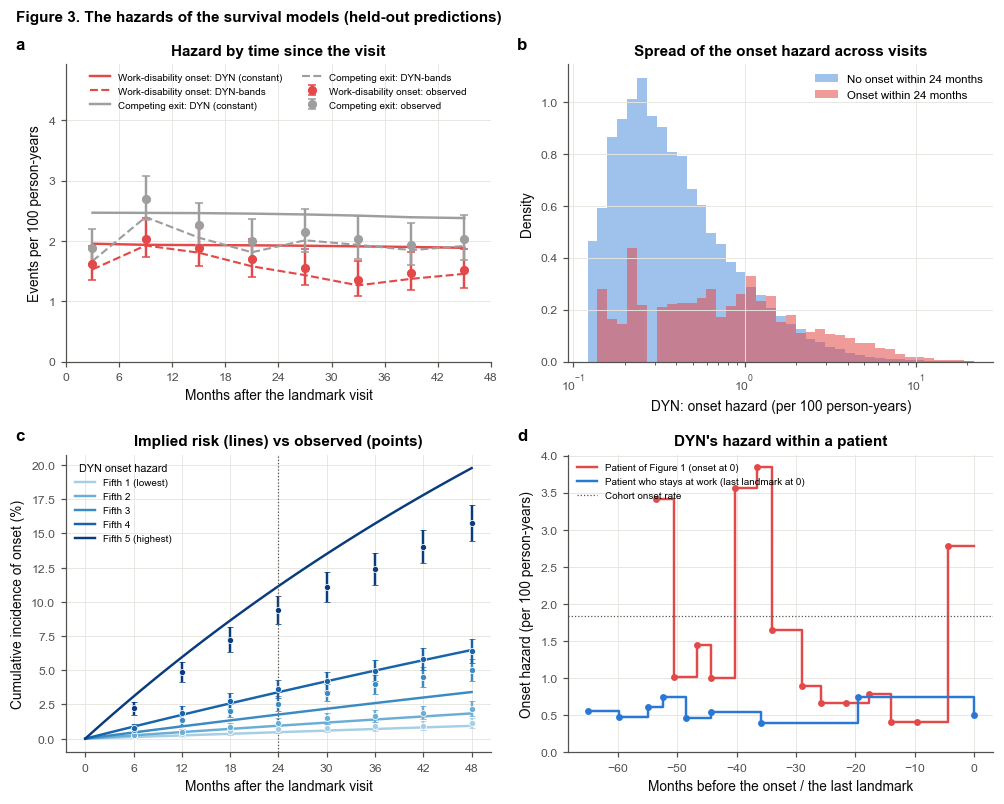

,Person-years,Onsets,Onset rate /100 py,Competing exits,Competing rate /100 py
Band (months),,,,,
0-6,8532.0,138,1.62,160,1.88
6-12,8008.0,163,2.04,216,2.70
12-18,7528.0,142,1.89,170,2.26
18-24,7131.0,121,1.70,143,2.01
24-30,6802.0,105,1.54,146,2.15
30-36,6510.0,88,1.35,132,2.03
36-42,6233.0,92,1.48,120,1.93
42-48,5923.0,90,1.52,120,2.03


DYN onset hazard per 100 person-years: median 0.90, 10th-90th percentile 0.24-4.56; competing-exit hazard median 1.36.


In [72]:
"""Figure 3: the hazards of the main model and of the band model."""


def mean_eta(m):
    """Held-out log-hazards of every landmark, mean over the CV repeats (n x 2 or n x 16)."""
    acc, cnt = None, np.zeros(N_LAND)
    for r in REPEATS:
        for f in range(CV_N_SPLITS):
            res = ALL_FOLDS[(m, r, f)]
            if acc is None:
                acc = np.zeros((N_LAND, res["eta_te"].shape[1]))
            acc[res["te_rows"]] += res["eta_te"]; cnt[res["te_rows"]] += 1
    return acc / np.maximum(cnt, 1)[:, None]


ETA_MAIN = mean_eta(MAIN_MODEL)
ETA_BANDS = mean_eta(DYN_BANDS) if DYN_BANDS in MODELS_RUN else None
_bm = (np.arange(N_BANDS) + 0.5) * BAND_MONTHS
_py = BAND_DT.sum(0)


def _pois_ci(d, py):
    lo = np.where(d > 0, stats.chi2.ppf(0.025, 2 * d) / 2, 0.0) / py
    hi = stats.chi2.ppf(0.975, 2 * (d + 1)) / 2 / py
    return lo, hi


fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))
ax = axes[0, 0]
for cause, D, lab_, col_ in [(0, BAND_D1, "Work-disability onset", STATUS_COLORS["onset"]),
                             (1, BAND_D2, "Competing exit", STATUS_COLORS["other exit"])]:
    d = D.sum(0); rate = d / _py; lo, hi = _pois_ci(d, _py)
    ax.errorbar(_bm, 100 * rate, yerr=[100 * (rate - lo), 100 * (hi - rate)], fmt="o", color=col_, capsize=2.5,
                ms=5, label=f"{lab_}: observed")
    lam_c = np.exp(np.clip(ETA_MAIN[:, cause], -30, 5))
    ax.plot(_bm, 100 * (BAND_DT * lam_c[:, None]).sum(0) / _py, "-", color=col_, lw=1.6,
            label=f"{lab_}: {short_label(MAIN_MODEL)} (constant)")
    if ETA_BANDS is not None:
        lam_b = np.exp(np.clip(ETA_BANDS[:, cause * N_BANDS:(cause + 1) * N_BANDS], -30, 5))
        ax.plot(_bm, 100 * (BAND_DT * lam_b).sum(0) / _py, "--", color=col_, lw=1.4,
                label=f"{lab_}: {short_label(DYN_BANDS)}")
ax.set_xticks(np.arange(0, 49, 6)); ax.set_xlabel("Months after the landmark visit")
ax.set_ylabel("Events per 100 person-years"); ax.set_title("Hazard by time since the visit")
ax.set_ylim(0, ax.get_ylim()[1] * 1.55); ax.legend(fontsize=6.5, loc="upper center", ncol=2)

ax = axes[0, 1]
lam1 = 100 * np.exp(ETA_MAIN[:, 0])
_on24 = (C_ALL == 1) & (T_ALL <= HORIZON_DAYS)
_bins = np.logspace(np.log10(np.percentile(lam1, 0.5)), np.log10(np.percentile(lam1, 99.5)), 40)
ax.hist(lam1[~_on24], bins=_bins, density=True, color=STATUS_COLORS["working"], alpha=0.45,
        label=f"No onset within {H} months")
ax.hist(lam1[_on24], bins=_bins, density=True, color=STATUS_COLORS["onset"], alpha=0.55,
        label=f"Onset within {H} months")
ax.set_xscale("log"); ax.set_xlabel(f"{short_label(MAIN_MODEL)}: onset hazard (per 100 person-years)")
ax.set_ylabel("Density"); ax.set_title("Spread of the onset hazard across visits"); ax.legend()

ax = axes[1, 0]
_q = pd.qcut(ETA_MAIN[:, 0], 5, labels=False)
_cmap = plt.get_cmap("Blues")
_mo = np.linspace(0, 48, 97)
for g in range(5):
    k = _q == g
    col_ = _cmap(0.35 + 0.15 * g)
    pred = np.array([cif(ETA_MAIN[k], mm).mean() for mm in _mo])
    ax.plot(_mo, 100 * pred, "-", color=col_, lw=1.6, label=f"Fifth {g + 1}" + (" (lowest)" if g == 0 else
                                                                                   " (highest)" if g == 4 else ""))
    obs = []
    for h in HORIZONS:
        rr, yy, ww = IPCW_H[h]
        kk = k[rr]
        n_g = k.sum()
        o = np.sum(ww[kk] * yy[kk]) / n_g
        se = np.sqrt(np.sum((ww[kk] * yy[kk] - o) ** 2) + (n_g - kk.sum()) * o ** 2) / n_g   # landmarks independent
        obs.append((o, se))
    obs = np.array(obs)
    ax.errorbar(HORIZONS, 100 * obs[:, 0], yerr=196 * obs[:, 1], fmt="o", color=col_, ms=4, capsize=2,
                mec="white", mew=0.5)
ax.axvline(H, color=INK_2, lw=0.8, ls=":")
ax.set_xticks(np.arange(0, 49, 6)); ax.set_xlabel("Months after the landmark visit")
ax.set_ylabel("Cumulative incidence of onset (%)"); ax.set_title("Implied risk (lines) vs observed (points)")
ax.legend(title=f"{short_label(MAIN_MODEL)} onset hazard", fontsize=6.5, title_fontsize=7)

ax = axes[1, 1]
_li_e = PT_ROWS[EXAMPLE_PID]
_li_e = _li_e[land["visit_date"].values[_li_e] < np.datetime64(FIRST_ONSET[EXAMPLE_PID])]
_age_e = land["age_at_record"].values[_li_e[-1]]
_ctrl_pids = [p for p in PT_ROWS if p not in EVER_ONSET and len(PT_ROWS[p]) >= len(_li_e)
              and abs(land["age_at_record"].values[PT_ROWS[p][-1]] - _age_e) < 5]
CTRL_PID = sorted(_ctrl_pids, key=lambda p: len(PT_ROWS[p]))[len(_ctrl_pids) // 2] if _ctrl_pids else None
for pid, lab_, col_, li in [(EXAMPLE_PID, "Patient of Figure 1 (onset at 0)", STATUS_COLORS["onset"], _li_e),
                            (CTRL_PID, "Patient who stays at work (last landmark at 0)", STATUS_COLORS["working"],
                             PT_ROWS.get(CTRL_PID, np.array([], int)))]:
    if pid is None or len(li) == 0:
        continue
    anchor = FIRST_ONSET[pid] if pid in EVER_ONSET else pd.Timestamp(land["visit_date"].values[li[-1]])
    x = (pd.to_datetime(land["visit_date"].values[li]) - anchor).days.values / MONTH_DAYS
    k = x >= -72
    ax.step(np.r_[x[k], 0], 100 * np.exp(np.r_[ETA_MAIN[li[k], 0], ETA_MAIN[li[k][-1], 0]]), where="post", color=col_,
            lw=1.6, label=lab_)
    ax.plot(x[k], 100 * np.exp(ETA_MAIN[li[k], 0]), "o", color=col_, ms=3.5)
ax.axhline(100 * D_ONSET.sum() / INT_YRS.sum(), color=INK_2, lw=0.8, ls=":", label="Cohort onset rate")
ax.set_xlabel("Months before the onset / the last landmark")
ax.set_ylabel("Onset hazard (per 100 person-years)"); ax.set_title(f"{short_label(MAIN_MODEL)}'s hazard within a patient")
ax.set_ylim(0, None); ax.legend(fontsize=6.5, loc="upper left")
for a_, l_ in zip(axes.ravel(), "abcd"):
    panel_label(a_, l_)
fig.suptitle("Figure 3. The hazards of the survival models (held-out predictions)", x=0.02, ha="left", fontsize=10,
             fontweight="bold")
plt.tight_layout()
save_fig("fig03_hazards")
_band_tab = pd.DataFrame({"Band (months)": [f"{b * BAND_MONTHS}-{(b + 1) * BAND_MONTHS}" for b in range(N_BANDS)],
                          "Person-years": _py.round(0), "Onsets": BAND_D1.sum(0).astype(int),
                          "Onset rate /100 py": (100 * BAND_D1.sum(0) / _py).round(2),
                          "Competing exits": BAND_D2.sum(0).astype(int),
                          "Competing rate /100 py": (100 * BAND_D2.sum(0) / _py).round(2)}).set_index("Band (months)")
display(_band_tab)
print(f"{short_label(MAIN_MODEL)} onset hazard per 100 person-years: median {np.median(lam1):.2f}, 10th-90th percentile "
      f"{np.percentile(lam1, 10):.2f}-{np.percentile(lam1, 90):.2f}; competing-exit hazard median "
      f"{np.median(100 * np.exp(ETA_MAIN[:, 1])):.2f}.")

## 11.7 The metric engine

Within each repeat the 5 test folds cover every landmark once; each metric is computed on that pooled set and
averaged over the repeats. **95 % CIs: patient-cluster bootstrap**, 1,000 resamples of patients (all their landmarks
together), the **same resamples for every model, repeat and horizon**, so every difference is paired.

* **Visit level** (every landmark with a known *h*-month status, censoring weights 1/G): AUROC; calibration slope
  and intercept; O/E (IPCW observed cumulative incidence over the mean predicted risk); sensitivity, specificity,
  PPV, NPV, balanced accuracy and share flagged at the fold's threshold; net benefit; risk tiers.
* **Patient level** (the windows of Section 9.2): **AUROC of the patient score (primary patient metric)**;
  sensitivity, specificity, PPV, NPV, balanced accuracy at the fold's patient threshold; lead time; patient-level
  calibration slope, intercept and O/E. Also the 2-consecutive-alarms rule.
* **Risk-set C** (robustness): each onset against every patient at risk on the onset date.

In [73]:
"""Bootstrap weights and every metric of every model."""
P_ = len(ALL_PIDS)
_rng = np.random.RandomState(SEED + 99)
W_BOOT = _rng.multinomial(P_, np.full(P_, 1 / P_), size=BOOT_N).astype(np.float32)
_BOTH = np.vstack([np.ones((1, P_), np.float32), W_BOOT])
_W_ALL = _BOTH[:, ROW_PIDX]
RS_PC, RS_PK = ROW_PIDX[RS_CASE], ROW_PIDX[RS_CTRL]


def _pair_sum_fast(Wp, M):
    return ((Wp @ M.astype(np.float32)) * Wp).sum(1)


_RS_A = sparse.coo_matrix((np.ones(len(RS_CASE)), (RS_PC, RS_PK)), shape=(P_, P_)).toarray()
_RS_DEN = _pair_sum_fast(_BOTH, _RS_A)
PTW_PIDX = {h: np.array([PID_INDEX[p] for p in PTW[h]["pids"]]) for h in HORIZONS}
_STAYED = set(patients_df.index[(patients_df["final_emp"] == "employed")]) - EVER_ONSET \
    - set(land.loc[land["cause"] >= 2, "pid"])
STAYED_ROWS = np.isin(PID_ALL, list(_STAYED))
PT_SUB = {}                                        # patient subgroups at the window's last landmark
for name, mask in SUBGROUPS.items():
    if name.split(":")[0] in ("Sex", "Race", "Age", "Era"):
        PT_SUB[name] = mask[PTW[H]["last_row"]]


def _chunks(n, size=250):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def wauc(y, p, Wr):
    """Weighted AUROC for every row of the weight matrix Wr (B, n); ties count 1/2."""
    o = np.argsort(p, kind="mergesort")
    ps, ys = p[o], y[o]
    starts = np.r_[0, np.flatnonzero(np.diff(ps)) + 1]
    out = np.empty(Wr.shape[0])
    for sl in _chunks(Wr.shape[0]):
        Ws = Wr[sl][:, o]
        pos = np.add.reduceat(Ws * (ys == 1), starts, axis=1)
        neg = np.add.reduceat(Ws * (ys == 0), starts, axis=1)
        cneg = np.cumsum(neg, 1) - neg
        with np.errstate(invalid="ignore", divide="ignore"):
            out[sl] = (pos * (cneg + 0.5 * neg)).sum(1) / (pos.sum(1) * neg.sum(1))
    return out


def wcalibration(y, z, w):
    """Calibration slope and intercept (offset logistic, calibration-in-the-large) of logits z, weights w."""
    k = w > 0
    if len(np.unique(y[k])) < 2:
        return np.nan, np.nan
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(z[k, None], y[k], sample_weight=w[k]).coef_[0, 0]
    f = lambda a: np.average(_expit(a + z[k]), weights=w[k]) - np.average(y[k], weights=w[k])
    try:
        icpt = brentq(f, -20, 20)
    except ValueError:
        icpt = np.nan
    return float(slope), float(icpt)


def _ratio(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(b > 0, a / b, np.nan)


def confusion_stats(y, a, Wr):
    y1, a1 = (y == 1).astype(np.float32), np.asarray(a, bool).astype(np.float32)
    tp, fn = Wr @ (y1 * a1), Wr @ (y1 * (1 - a1))
    fp, tn = Wr @ ((1 - y1) * a1), Wr @ ((1 - y1) * (1 - a1))
    sens, spec = _ratio(tp, tp + fn), _ratio(tn, tn + fp)
    return {"sensitivity": sens, "specificity": spec, "ppv": _ratio(tp, tp + fp), "npv": _ratio(tn, tn + fn),
            "balanced_accuracy": (sens + spec) / 2, "flagged": _ratio(tp + fp, tp + fp + fn + tn)}


def wmedian(x, Wr):
    if len(x) == 0:
        return np.full(Wr.shape[0], np.nan)
    o = np.argsort(x)
    cw = np.cumsum(Wr[:, o], 1)
    tot = cw[:, -1:]
    idx = (cw < 0.5 * tot).sum(1)
    out = x[o][np.minimum(idx, len(x) - 1)].astype(float)
    out[tot[:, 0] == 0] = np.nan
    return out


def fire_dates(z, thr_row, W):
    """Date at which each window's running mean logit first reaches the patient threshold (NaT if never)."""
    out = np.full(len(W["rows"]), np.datetime64("NaT"), dtype="datetime64[ns]")
    for k, r in enumerate(W["rows"]):
        run = np.cumsum(z[r]) / np.arange(1, len(r) + 1)
        hit = np.flatnonzero(run >= thr_row[r[-1]])
        if len(hit):
            out[k] = VISIT_DATE[r[hit[0]]]
    return out


CONF_METRICS = ["sensitivity", "specificity", "ppv", "npv", "balanced_accuracy", "flagged"]
METRIC_LABELS = {"auroc": "AUROC", "riskset_c": "Risk-set C", "cal_slope": "Calibration slope",
                 "cal_intercept": "Calibration intercept", "oe": "O/E", "sensitivity": "Sensitivity",
                 "specificity": "Specificity", "ppv": "PPV", "npv": "NPV", "balanced_accuracy": "Balanced accuracy",
                 "flagged": "Share flagged", "lead_median": "Median lead time (months)",
                 "lead_ge6": f"Onsets flagged >= {LEAD_TIME_MIN_MONTHS} months ahead", "nb": "Net benefit"}


def stats_one_repeat(m, r):
    """{key: (point, bootstrap array or None)} for model m, repeat r."""
    out = {}
    put = lambda key, a: out.__setitem__(key, (float(a[0]), np.asarray(a[1:], float)))
    point = lambda key, v: out.__setitem__(key, (float(v), None))
    for h in HORIZONS:
        z_all = zpred(m, r, h)
        rows, y, w = IPCW_H[h]
        z = z_all[rows]
        Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
        put(("visit", h, "auroc"), wauc(y, z, Wr))
        w_full = np.zeros(N_LAND); w_full[rows] = w
        y_full = np.zeros(N_LAND); y_full[rows] = y
        put(("visit", h, "oe"), (_W_ALL @ (w_full * y_full)) / (_W_ALL @ _expit(z_all)))
        nb_ = N_CAL_BOOT if h == H else 0
        cal = [wcalibration(y, z, (Wr[b] if b else w)) for b in range(nb_ + 1)]
        out[("visit", h, "cal_slope")] = (cal[0][0], np.array([c[0] for c in cal[1:]]) if nb_ else None)
        out[("visit", h, "cal_intercept")] = (cal[0][1], np.array([c[1] for c in cal[1:]]) if nb_ else None)
        for c in (THRESHOLD_RULES if h == H else [MAIN_THRESHOLD]):
            thr = THR_V[m][r][h][c]
            for k_, v_ in confusion_stats(y, z >= thr[rows], Wr).items():
                put(("visit", h, c, k_), v_)
            point(("visit", h, c, "threshold"), np.nanmedian(_expit(np.unique(thr[~np.isnan(thr)]))))
        # patient level
        W = PTW[h]
        s = np.asarray(W["mat"] @ np.nan_to_num(z_all)).ravel()
        ev = W["event"]
        Wp = _BOTH[:, PTW_PIDX[h]]
        put(("patient", h, "auroc"), wauc(ev, s, Wp))
        for c in (THRESHOLD_RULES if h == H else [MAIN_THRESHOLD]):
            thr_pt = THR_P[m][r][h][c][W["last_row"]]
            for k_, v_ in confusion_stats(ev, s >= thr_pt, Wp).items():
                put(("patient", h, c, k_), v_)
        if h != H:
            continue
        # ---- primary horizon only
        y1 = (y == 1).astype(np.float32)
        for t in FIXED_RISKS:
            for k_, v_ in confusion_stats(y, z >= _logit(t), Wr).items():
                put(("visit", h, "fixed", t, k_), v_)
        p = _expit(z)
        tot = Wr.sum(1)
        for t in NB_GRID:
            a = (p >= t).astype(np.float32)
            put(("visit", h, "nb", t), (Wr @ (y1 * a) - Wr @ ((1 - y1) * a) * t / (1 - t)) / tot)
            put(("visit", h, "nb_all", t), (Wr @ y1 - Wr @ (1 - y1) * t / (1 - t)) / tot)
        rec = (land["CAL_YEAR"].values >= TIER_RECENT_FROM)
        for lo, hi, name in RISK_TIERS + RULE_OUT_TIERS:
            inn = ((p >= lo) & (p < hi)).astype(np.float32)
            put(("visit", h, "tier", name, "observed"), _ratio(Wr @ (y1 * inn), Wr @ inn))
            put(("visit", h, "tier", name, "share_onsets"), _ratio(Wr @ (y1 * inn), Wr @ y1))
            inr, y1r = inn * rec[rows], y1 * rec[rows]                 # recent era only
            put(("visit", h, "tier_recent", name, "observed"), _ratio(Wr @ (y1r * inr), Wr @ inr))
            put(("visit", h, "tier_recent", name, "share_onsets"), _ratio(Wr @ (y1r * inr), Wr @ y1r))
            put(("visit", h, "tier_recent", name, "share_visits"), _ratio(Wr @ inr, Wr @ rec[rows].astype(np.float32)))
            inn_all = (_expit(z_all) >= lo) & (_expit(z_all) < hi)
            point(("visit", h, "tier", name, "share_visits"), inn_all.mean())
            point(("visit", h, "tier", name, "share_patients"), np.mean(
                pd.Series(inn_all).groupby(PID_ALL).max().values))
            point(("visit", h, "tier", name, "mean_pred"), _expit(z_all)[inn_all].mean() if inn_all.any() else np.nan)
        alarm = z_all >= THR_V[m][r][h][MAIN_THRESHOLD]
        point(("visit", h, "alerts_per_100"), 100 * alarm.mean())
        point(("visit", h, "alerts_per_py"), alarm.sum() / INT_YRS.sum())
        never = pd.Series(alarm[STAYED_ROWS]).groupby(PID_ALL[STAYED_ROWS]).max()
        point(("visit", h, "stayed_never_alerted"), 1 - never.mean())
        point(("visit", h, "stayed_alerts_per_py"), alarm[STAYED_ROWS].sum() / INT_YRS[STAYED_ROWS].sum())
        for name, mask in SUBGROUPS.items():
            k = mask[rows]
            if y[k].sum() >= 3 and (1 - y[k]).sum() >= 3:
                put(("visit", h, "sub", name, "auroc"), wauc(y[k], z[k], Wr[:, k]))
                point(("visit", h, "sub", name, "oe"), np.sum(w[k] * y[k]) / np.sum(w[k] * p[k]))
        # patient level, primary horizon: run2, lead time, calibration, subgroups
        s2 = run2_score(z_all, W["rows"])
        put(("patient", h, "run2", "auroc"), wauc(ev, s2, Wp))
        for k_, v_ in confusion_stats(ev, s2 >= THR_RUN2[m][r][MAIN_THRESHOLD][W["last_row"]], Wp).items():
            put(("patient", h, "run2", k_), v_)
        thr_row = THR_P[m][r][h][MAIN_THRESHOLD]
        fire = fire_dates(z_all, thr_row, W)
        ok = (ev == 1) & ~np.isnat(fire)
        lead = ((W["event_date"][ok] - fire[ok]) / np.timedelta64(1, "D")).astype(float) / MONTH_DAYS
        put(("patient", h, "lead_median"), wmedian(lead, Wp[:, ok]))
        ge6 = np.zeros(len(ev)); ge6[np.flatnonzero(ok)[lead >= LEAD_TIME_MIN_MONTHS]] = 1
        put(("patient", h, "lead_ge6"), _ratio(Wp @ ge6, Wp @ ev.astype(float)))
        out[("patient", h, "lead_values")] = (lead, None)
        a_, b_ = PCAL[m][r][h]
        zp = a_[W["last_row"]] + b_[W["last_row"]] * s
        put(("patient", h, "oe"), (Wp @ ev.astype(float)) / (Wp @ _expit(zp)))
        cal = [wcalibration(ev, zp, (Wp[b] if b else np.ones(len(ev)))) for b in range(N_CAL_BOOT + 1)]
        out[("patient", h, "cal_slope")] = (cal[0][0], np.array([c[0] for c in cal[1:]]))
        out[("patient", h, "cal_intercept")] = (cal[0][1], np.array([c[1] for c in cal[1:]]))
        for name, mask in PT_SUB.items():
            if ev[mask].sum() >= 3 and (1 - ev[mask]).sum() >= 3:
                put(("patient", h, "sub", name, "auroc"), wauc(ev[mask], s[mask], Wp[:, mask]))
        # risk-set C
        ps = patient_score_rs(m, z_all)
        a, b = ps[RS_CASE], ps[RS_CTRL]
        K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (RS_PC, RS_PK)), shape=(P_, P_)).toarray()
        put(("riskset", "riskset_c"), _pair_sum_fast(_BOTH, K) / _RS_DEN)
    for iv in INTERVALS:
        rows, y, w = IPCW_INT[iv]
        Wr = _BOTH[:, ROW_PIDX[rows]] * w[None, :]
        put(("interval", iv, "auroc"), wauc(y, PRED[m][r][("iv",) + iv][rows], Wr))
    return out


STATS_CACHE_PATH = f"stats_cache_{TAG}{'_smoke' if SMOKE else ''}.pkl"
_stats_cache = _load(STATS_CACHE_PATH, {})
_METRIC_VERSION = "v13.1"


def _signature(m):
    return (_METRIC_VERSION, tuple(REPEATS), BOOT_N,
            float(np.nansum([np.nansum(zpred(m, r)) for r in REPEATS])),
            float(np.nansum([np.nansum(THR_V[m][r][H]["cost"]) for r in REPEATS])))


STATS = {}
for m in MODELS_RUN:
    t0 = time.time()
    sig = _signature(m)
    if m in _stats_cache and _stats_cache[m][0] == sig:
        STATS.update(_stats_cache[m][1])
        continue
    per = [stats_one_repeat(m, r) for r in REPEATS]
    res = {}
    for key in per[0]:
        if key[-1] == "lead_values":
            res[(m,) + key] = (np.concatenate([d[key][0] for d in per if key in d]), None)
            continue
        pts = [d[key][0] for d in per if key in d]
        bts = [d[key][1] for d in per if key in d]
        res[(m,) + key] = (float(np.nanmean(pts)), None if bts[0] is None else np.nanmean(np.vstack(bts), 0))
    _stats_cache[m] = (sig, res)
    _save(_stats_cache, STATS_CACHE_PATH)
    STATS.update(res)
    print(f"  metrics of {short_label(m)} ({time.time() - t0:.0f} s)", flush=True)


def ci(key):
    if key not in STATS:
        return np.nan, np.nan, np.nan
    pt, bt = STATS[key]
    if bt is None:
        return pt, np.nan, np.nan
    return pt, float(np.nanpercentile(bt, 2.5)), float(np.nanpercentile(bt, 97.5))


def _diff_summary(pt, d, n_comp=1):
    a = 2.5 / n_comp
    pval = 2 * min(np.nanmean(d <= 0), np.nanmean(d >= 0))
    return pt, float(np.nanpercentile(d, a)), float(np.nanpercentile(d, 100 - a)), min(1.0, pval)


def diff(m1, m2, key, n_comp=1):
    """Paired difference m1 - m2: point, 95 % CI (Bonferroni-widened for n_comp), two-sided bootstrap p."""
    if (m1,) + key not in STATS or (m2,) + key not in STATS or STATS[(m1,) + key][1] is None:
        return np.nan, np.nan, np.nan, np.nan
    p1, b1 = STATS[(m1,) + key]; p2, b2 = STATS[(m2,) + key]
    return _diff_summary(p1 - p2, b1 - b2, n_comp)


def fmt(pt, lo=np.nan, hi=np.nan, nd=3):
    if pt is None or np.isnan(pt):
        return "-"
    if np.isnan(lo):
        return f"{pt:.{nd}f}"
    return f"{pt:.{nd}f} ({lo:.{nd}f} to {hi:.{nd}f})"


def fmtk(key, nd=3):
    return fmt(*ci(key), nd=nd)


def verdict_superiority(lo, hi, margin=None):
    if lo > 0:
        return "superior"
    if hi < 0:
        return "inferior"
    if margin is not None and lo > -margin and hi < margin:
        return "equivalent"
    return "inconclusive"


K_VIS = ("visit", H, "auroc")
K_PT = ("patient", H, "auroc")
K_RS = ("riskset", "riskset_c")
OBJ_CONCLUSIONS, HYP_ROWS = {}, []
print(f"Main model {short_label(MAIN_MODEL)}: patient AUROC {fmtk((MAIN_MODEL,) + K_PT)} | visit AUROC "
      f"{fmtk((MAIN_MODEL,) + K_VIS)} | risk-set C {fmtk((MAIN_MODEL,) + K_RS)}")

Main model DYN: patient AUROC 0.822 (0.784 to 0.859) | visit AUROC 0.727 (0.684 to 0.767) | risk-set C 0.748 (0.709 to 0.788)


## 11.8 Time-matched patient-level metrics (the primary metric)

For each onset (on date *E*), the **case** is the patient's mean 24-month risk logit over their landmarks in a
window before *E*; the **controls** are every other patient at risk on *E* (still working and followed), each scored
over their own landmarks **in the same calendar window** (if a patient has no landmark in the window, their latest
landmark before the window's end). AUROC = the share of case-control pairs in which the case scores higher (ties
1/2), pooled over onsets; 95 % CI from the same patient-cluster bootstrap as everything else.

* **Primary**: the window is the 24 months before the onset (every landmark in it has the onset within 24 months).
* **Objective 2**: windows 0-6, 6-12, 12-24, 24-36 and 36-48 months before the onset (the same controls, the same
  calendar window): discrimination by time before the onset. Here the case must have a landmark inside the window
  (no fallback), so each window uses only the onsets observed at that distance.
* Patient-level sensitivity (cases whose window score is above their fold's **time-matched threshold**), specificity
  (the same for controls, each onset's controls weighted equally) and balanced accuracy. The threshold of each fold
  is the max-Youden cut-off over the training patients' time-matched pairs, scored with their out-of-fold risks
  (the same rule as the visit threshold, applied to the patient comparison it is used for).

In [74]:
"""Time-matched patient AUROC: entities, pairs and metrics for every model."""
_PT_T = {pid: _LAND_T[li] for pid, li in PT_ROWS.items()}


def _window_rows(pid, lo_day, hi_day, fallback=True):
    """The patient's landmark rows with lo_day <= date < hi_day; else (fallback) the latest before hi_day; else empty."""
    li, t = PT_ROWS[pid], _PT_T[pid]
    a, b = np.searchsorted(t, lo_day, side="left"), np.searchsorted(t, hi_day, side="left")
    if b > a:
        return li[a:b]
    return li[b - 1:b] if (b > 0 and fallback) else li[:0]


def build_tm(lo_m, hi_m, case_fallback=True):
    """Entities (rows to average) and case-control pairs for the window [E - hi, E - lo) months before each onset."""
    ent_rows, ent_pid = [], []
    case_ent, pairs_c, pairs_k, pairs_w = {}, [], [], []
    for e in RS_EVENTS:
        E = INT_END[e]
        lo_day, hi_day = E - hi_m * MONTH_DAYS, E - lo_m * MONTH_DAYS
        pc = PID_ALL[e]
        rc = _window_rows(pc, lo_day, min(hi_day, E), case_fallback)
        if len(rc) == 0:
            continue
        ci_ = len(ent_rows); ent_rows.append(rc); ent_pid.append(PID_INDEX[pc])
        ctrl = np.unique(PID_ALL[RS_CTRL[RS_CASE == e]])
        ks = []
        for pk in ctrl:
            rk = _window_rows(pk, lo_day, hi_day)
            if len(rk):
                ks.append(len(ent_rows)); ent_rows.append(rk); ent_pid.append(PID_INDEX[pk])
        if ks:
            pairs_c += [ci_] * len(ks); pairs_k += ks; pairs_w += [1.0 / len(ks)] * len(ks)
            case_ent[e] = ci_
    n = np.array([len(r) for r in ent_rows])
    mat = sparse.csr_matrix((np.concatenate([np.full(len(r), 1.0 / len(r)) for r in ent_rows]),
                             (np.repeat(np.arange(len(ent_rows)), n), np.concatenate(ent_rows))),
                            shape=(len(ent_rows), N_LAND))
    last = np.array([r[-1] for r in ent_rows])
    pc, pk = np.array(pairs_c), np.array(pairs_k)
    ep = np.array(ent_pid)
    cases = np.array(sorted(set(pairs_c)))
    return {"mat": mat, "last": last, "pc": pc, "pk": pk, "w": np.array(pairs_w), "ppc": ep[pc], "ppk": ep[pk],
            "cases": cases, "case_pid": ep[cases], "n_onsets": len(cases), "ent_pid": ep}


TM_WINDOWS = {"main": (0, TM_WINDOW_MONTHS)} | {f"{a}-{b}": (a, b) for a, b in TTO_BINS}
TM = {k: build_tm(*v, case_fallback=(k == "main")) for k, v in TM_WINDOWS.items()}
for k, d in TM.items():
    d["den"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(len(d["pc"])), (d["ppc"], d["ppk"])),
                                                         shape=(P_, P_)).toarray())
    d["wden"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((d["w"], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray())
print("Time-matched pairs: " + ", ".join(f"{k}: {d['n_onsets']} onsets, {len(d['pc']):,} pairs" for k, d in TM.items()))


TEST_FOLD = {r: np.zeros(len(ALL_PIDS), int) for r in REPEATS}     # each patient's test fold in each repeat
for r in REPEATS:
    for f in range(CV_N_SPLITS):
        TEST_FOLD[r][[PID_INDEX[p] for p in OUTER[r][f][1]]] = f
_THR_TM = {}


def tm_fold_thresholds(m, r):
    """One time-matched threshold per fold: max Youden over the TRAINING patients' time-matched pairs (main 24-month
    window), each scored with its out-of-fold recalibrated logits; each onset's training controls weighted equally."""
    if (m, r) in _THR_TM:
        return _THR_TM[(m, r)]
    d = TM["main"]
    out = np.full(CV_N_SPLITS, np.nan)
    for f in range(CV_N_SPLITS):
        tr, zo = OOF_H[(m, r, f)]
        oof = np.full(N_LAND, np.nan); oof[tr] = zo
        s = np.asarray(d["mat"] @ np.nan_to_num(oof)).ravel()
        in_tr = TEST_FOLD[r][d["ent_pid"]] != f
        k = in_tr[d["pc"]] & in_tr[d["pk"]]
        pc, pk = d["pc"][k], d["pk"][k]
        if len(pc) == 0:
            continue
        cases, inv, n_per = np.unique(pc, return_inverse=True, return_counts=True)
        w = 1.0 / n_per[inv]
        sc, order = np.sort(s[cases]), np.argsort(s[pk])
        sk, cw = s[pk][order], np.r_[0.0, np.cumsum(w[order])]
        cand = np.unique(sc)
        sens = 1.0 - np.searchsorted(sc, cand, side="left") / len(sc)
        spec = cw[np.searchsorted(sk, cand, side="left")] / cw[-1]
        out[f] = cand[np.argmax(sens + spec)]
    _THR_TM[(m, r)] = out
    return out


def tm_stats_one(m, r, d):
    z = zpred(m, r)
    s = np.asarray(d["mat"] @ np.nan_to_num(z)).ravel()
    a, b = s[d["pc"]], s[d["pk"]]
    K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
    out = {"auroc": _pair_sum_fast(_BOTH, K) / d["den"]}
    thr = tm_fold_thresholds(m, r)[TEST_FOLD[r][d["ent_pid"]]]       # the entity's test fold's threshold
    flag = s >= thr
    Wc = _BOTH[:, d["case_pid"]]
    out["sensitivity"] = (Wc @ flag[d["cases"]].astype(np.float32)) / Wc.sum(1)
    Ks = sparse.coo_matrix((d["w"] * ~flag[d["pk"]], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
    out["specificity"] = _pair_sum_fast(_BOTH, Ks) / d["wden"]
    out["balanced_accuracy"] = (out["sensitivity"] + out["specificity"]) / 2
    return out


TM_CACHE_KEY = ("tm", _METRIC_VERSION, tuple(REPEATS), BOOT_N)
for m in MODELS_RUN:
    sig = _signature(m)
    hit = m in _stats_cache and len(_stats_cache[m]) > 2 and _stats_cache[m][2][0] == sig
    if hit:
        STATS.update(_stats_cache[m][2][1]); continue
    res = {}
    for k, d in TM.items():
        per = [tm_stats_one(m, r, d) for r in REPEATS]
        for met in per[0]:
            v = np.mean([p_[met] for p_ in per], 0)
            res[(m, "tm", k, met)] = (float(v[0]), v[1:])
    _stats_cache[m] = (_stats_cache[m][0], _stats_cache[m][1], (sig, res))
    _save(_stats_cache, STATS_CACHE_PATH)
    STATS.update(res)
K_TM = ("tm", "main", "auroc")
print(f"Main model {short_label(MAIN_MODEL)}: time-matched patient AUROC {fmtk((MAIN_MODEL,) + K_TM)} | "
      f"Baseline {fmtk((BASELINE,) + K_TM)} | LogReg {fmtk((LOGREG,) + K_TM)}")

Time-matched pairs: main: 158 onsets, 44,009 pairs, 0-6: 115 onsets, 32,231 pairs, 6-12: 111 onsets, 29,349 pairs, 12-24: 104 onsets, 26,797 pairs, 24-36: 86 onsets, 19,426 pairs, 36-48: 77 onsets, 16,520 pairs
Main model DYN: time-matched patient AUROC 0.735 (0.697 to 0.775) | Baseline 0.580 (0.529 to 0.633) | LogReg 0.724 (0.684 to 0.764)


---
# 12. The models

For each model: its table at the visit level (24-month risk, every landmark with a known status, censoring weights)
and the patient level (patient windows, Section 9), then two figures, both on the held-out predictions of the five
CV repeats stacked:

* **Calibration** (visit level and patient level). Each **dot is one tenth of the predictions** (deciles of the
  predicted risk): mean predicted against observed (IPCW at the visit level), with a 95 % patient-bootstrap CI. The
  black curve is a smoothed calibration curve (logistic regression on a restricted cubic spline of the logit, knots at
  the 5th/35th/65th/95th percentiles) with its 95 % patient-bootstrap band; the dashed line is the **logistic
  calibration line** whose slope is the calibration slope (logit of the outcome on the logit of the prediction); the
  dotted diagonal is perfect calibration. The box gives the calibration slope, the calibration intercept
  (calibration-in-the-large, slope fixed at 1) and O/E with 95 % CIs. Underneath, the distribution of the
  predictions by outcome (each group scaled to its own total). The x-axis stops at the 97.5th percentile of the
  predictions (where the data lie); the top decile's dot is drawn even if it lies beyond.
* **Performance** (four panels per level): (a) ROC with the AUROC (95 % CI) and the fold threshold's operating point,
  (b) precision-recall, (c) sensitivity and specificity against the risk threshold, (d) PPV and NPV against the risk
  threshold; dotted lines mark the fold thresholds' operating values (mean over folds and repeats). Top row: visits
  (IPCW-weighted); bottom row: patients (one probability per patient, Section 9).

## 12.1 Main model: DYN (grid, last 2 years, current status + change from the patient's own baseline, one hazard)

DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [main]


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.735 (0.697 to 0.775)
Time-matched patient sensitivity / specificity,-,0.649 / 0.682
Concordance (AUROC; patient: windows),0.727 (0.684 to 0.767),0.822 (0.784 to 0.859)
Risk-set C (calendar-time risk sets),-,0.748 (0.709 to 0.788)
Calibration slope,1.051 (0.868 to 1.261),1.065 (0.922 to 1.253)
Calibration intercept,-0.011 (-0.195 to 0.170),0.045 (-0.177 to 0.262)
Observed / expected,1.033 (0.855 to 1.231),1.031 (0.887 to 1.184)
"Threshold (24-month risk, median over folds)",3.7 %,fold patient threshold
Sensitivity,0.649 (0.582 to 0.717),0.706 (0.637 to 0.776)


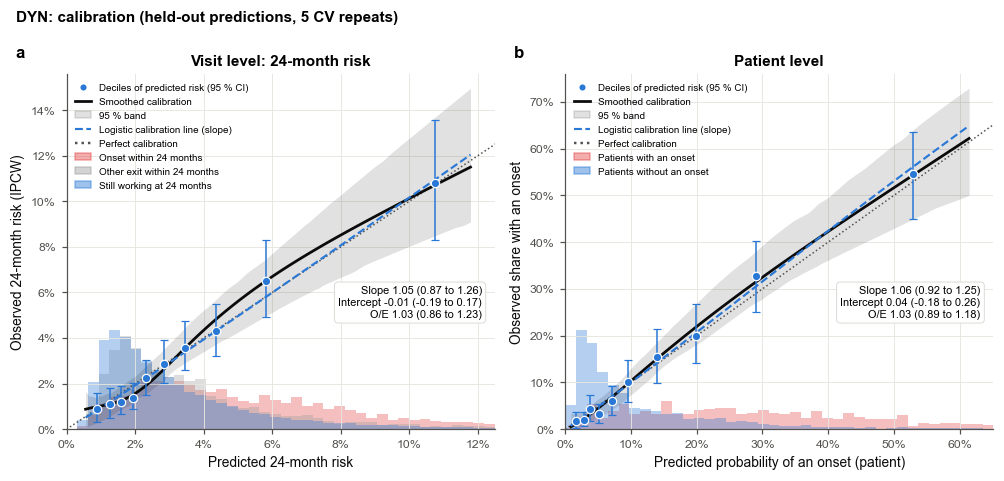

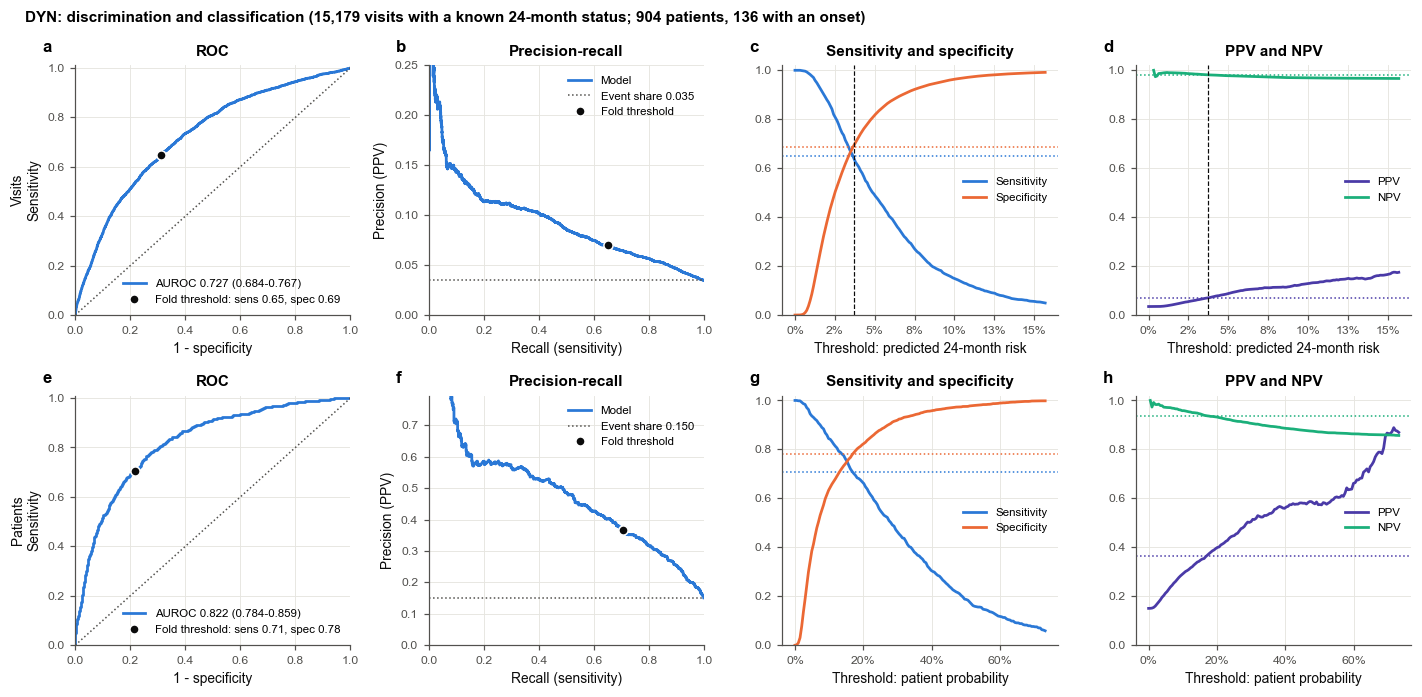

In [75]:
"""Per-model tables and figures (helpers), then the main model."""
from sklearn.metrics import precision_recall_curve
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

SMOOTH_BOOT = 50 if SMOKE else 200
CAL_DECILES = 10
HIST_FRAC = 0.28                                   # the tallest histogram bar reaches this share of the panel height


def patient_z(m, r, h=H):
    return np.asarray(PTW[h]["mat"] @ np.nan_to_num(zpred(m, r, h))).ravel()


def patient_prob(m, r):
    a, b = PCAL[m][r][H]
    lr = PTW[H]["last_row"]
    return _expit(a[lr] + b[lr] * patient_z(m, r))


def model_table(m):
    """One row per metric, visit level and patient level."""
    v, p = ("visit", H), ("patient", H)
    c = MAIN_THRESHOLD
    rows = [("Time-matched patient AUROC (primary)", "-", fmtk((m,) + K_TM)),
            ("Time-matched patient sensitivity / specificity", "-",
             f"{ci((m, 'tm', 'main', 'sensitivity'))[0]:.3f} / {ci((m, 'tm', 'main', 'specificity'))[0]:.3f}"),
            ("Concordance (AUROC; patient: windows)", fmtk((m,) + v + ("auroc",)), fmtk((m,) + p + ("auroc",))),
            ("Risk-set C (calendar-time risk sets)", "-", fmtk((m,) + K_RS)),
            ("Calibration slope", fmtk((m,) + v + ("cal_slope",)), fmtk((m,) + p + ("cal_slope",))),
            ("Calibration intercept", fmtk((m,) + v + ("cal_intercept",)), fmtk((m,) + p + ("cal_intercept",))),
            ("Observed / expected", fmtk((m,) + v + ("oe",)), fmtk((m,) + p + ("oe",))),
            (f"Threshold ({H}-month risk, median over folds)", f"{100 * ci((m,) + v + (c, 'threshold'))[0]:.1f} %",
             "fold patient threshold")]
    for x in CONF_METRICS:
        rows.append((METRIC_LABELS[x], fmtk((m,) + v + (c, x)), fmtk((m,) + p + (c, x))))
    rows += [("Median lead time (months), flagged event patients", "-", fmtk((m,) + p + ("lead_median",), 1)),
             (METRIC_LABELS["lead_ge6"] + " (share of event patients)", "-", fmtk((m,) + p + ("lead_ge6",))),
             ("Alerts per 100 landmark visits", f"{ci((m,) + v + ('alerts_per_100',))[0]:.1f}", "-"),
             ("Alerts per patient-year of employed follow-up", f"{ci((m,) + v + ('alerts_per_py',))[0]:.2f}", "-"),
             ("Stayed employed: never alerted / alerts per patient-year",
              f"{ci((m,) + v + ('stayed_never_alerted',))[0]:.2f} / {ci((m,) + v + ('stayed_alerts_per_py',))[0]:.2f}",
              "-"),
             ("Patient rule: 2 consecutive alarms, AUROC / sensitivity / specificity", "-",
              f"{ci((m,) + p + ('run2', 'auroc'))[0]:.3f} / {ci((m,) + p + ('run2', 'sensitivity'))[0]:.3f} / "
              f"{ci((m,) + p + ('run2', 'specificity'))[0]:.3f}")]
    return pd.DataFrame(rows, columns=["Metric", "Visit level", "Patient level"]).set_index("Metric")


# ---------------------------------------------------------------- held-out predictions, CV repeats stacked
_ROWS_V, _Y_V, _W_V = IPCW_H[H]
_STATUS_V = np.where(_Y_V == 1, "onset", np.where((C_ALL[_ROWS_V] >= 2) & (T_ALL[_ROWS_V] <= HORIZON_DAYS),
                                                   "other exit", "working"))
_STATUS_V_LABELS = {"onset": f"Onset within {H} months", "other exit": f"Other exit within {H} months",
                    "working": f"Still working at {H} months"}


def level_data(m, level):
    """Stacked over repeats: y, predicted probability, weight, patient index, outcome group, n repeats."""
    if level == "visit":
        ps = [_expit(zpred(m, r)[_ROWS_V]) for r in REPEATS]
        n = len(ps)
        return (np.tile(_Y_V, n).astype(float), np.concatenate(ps), np.tile(_W_V, n).astype(float),
                np.tile(ROW_PIDX[_ROWS_V], n), np.tile(_STATUS_V, n), n)
    ev = PTW[H]["event"].astype(float)
    ps = [patient_prob(m, r) for r in REPEATS]
    n = len(ps)
    return (np.tile(ev, n), np.concatenate(ps), np.ones(n * len(ev)), np.tile(PTW_PIDX[H], n),
            np.tile(np.where(ev == 1, "onset", "working"), n), n)


def rcs_basis(x, knots):
    """Restricted cubic spline basis (Harrell), linear beyond the outer knots: x and len(knots) - 2 terms."""
    k = np.asarray(knots, float)
    p3 = lambda u: np.maximum(u, 0.0) ** 3
    d = (k[-1] - k[0]) ** 2
    cols = [x] + [(p3(x - k[j]) - p3(x - k[-2]) * (k[-1] - k[j]) / (k[-1] - k[-2])
                   + p3(x - k[-1]) * (k[-2] - k[j]) / (k[-1] - k[-2])) / d for j in range(len(k) - 2)]
    return np.column_stack(cols)


_CAL_CACHE = {}


def calibration_curves(m, level):
    """Decile dots (mean predicted, observed, 95 % CI), the smoothed curve with its band, the logistic line."""
    if (m, level) in _CAL_CACHE:
        return _CAL_CACHE[(m, level)]
    y, p, w, pid, grp, n_rep = level_data(m, level)
    x = _logit(p)
    # decile dots: bins over every stacked prediction, CIs from the patient bootstrap (the same resamples throughout)
    cuts = np.quantile(p, np.linspace(0, 1, CAL_DECILES + 1))
    b = np.clip(np.searchsorted(cuts, p, side="right") - 1, 0, CAL_DECILES - 1)
    oh = np.zeros((len(p), CAL_DECILES), np.float32); oh[np.arange(len(p)), b] = 1
    L = len(p) // n_rep                                                 # the repeats are stacked blocks of L rows
    Wb = _BOTH[:, pid[:L]]                                              # (1 + B) x L, the same for every block
    num = sum(Wb @ (oh[i:i + L] * (w * y)[i:i + L, None]) for i in range(0, len(p), L))
    den = sum(Wb @ (oh[i:i + L] * w[i:i + L, None]) for i in range(0, len(p), L))
    obs = num / np.where(den > 0, den, np.nan)
    pred = (oh * (w * p)[:, None]).sum(0) / (oh * w[:, None]).sum(0)
    dec = {"pred": pred, "obs": obs[0], "lo": np.nanpercentile(obs[1:], 2.5, 0), "hi": np.nanpercentile(obs[1:], 97.5, 0)}
    # smoothed curve and its bootstrap band
    hi_x = float(np.percentile(p, 97.5))
    grid = np.linspace(max(float(np.percentile(p, 0.5)), 1e-4), max(hi_x, pred[-1]), 120)
    knots = np.percentile(x, [5, 35, 65, 95])
    B, Bg = rcs_basis(x, knots), rcs_basis(_logit(grid), knots)
    fit = lambda ww: LogisticRegression(C=1e4, max_iter=3000).fit(B, y, sample_weight=ww).predict_proba(Bg)[:, 1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        curve = fit(w)
        boots = [fit(w * np.tile(Wb[1 + k_], n_rep)) for k_ in range(SMOOTH_BOOT)]
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(x[:, None], y, sample_weight=w)
    out = {"dec": dec, "grid": grid, "curve": curve, "band": np.percentile(boots, [2.5, 97.5], 0),
           "line": _expit(lr.intercept_[0] + lr.coef_[0, 0] * _logit(grid)), "x_max": hi_x,
           "p": p, "w": w, "grp": grp, "n_rep": n_rep}
    _CAL_CACHE[(m, level)] = out
    return out


def plot_calibration(ax, m, level, title=None, legend=True):
    """The calibration panel described at the top of Section 12."""
    c = calibration_curves(m, level)
    d = c["dec"]
    x_max = max(c["x_max"], float(d["pred"][-1])) * 1.06
    y_top = max(x_max, float(np.nanmax(d["hi"])), float(np.nanmax(c["band"][1]))) * 1.04
    ax.fill_between(c["grid"], np.clip(c["band"][0], 0, 1), np.clip(c["band"][1], 0, 1), color="#0b0b0b", alpha=0.12,
                    lw=0, zorder=2)
    ax.plot(c["grid"], c["curve"], color="#0b0b0b", lw=1.8, zorder=3)
    ax.plot(c["grid"], c["line"], color=model_color(m), lw=1.4, ls="--", zorder=3)
    ax.plot([0, y_top], [0, y_top], ":", color=INK_2, lw=1, zorder=2)
    ax.errorbar(d["pred"], d["obs"], yerr=[np.clip(d["obs"] - d["lo"], 0, None), np.clip(d["hi"] - d["obs"], 0, None)],
                fmt="o", color=model_color(m), ms=5.5, mec="white", mew=0.8, capsize=2.5, elinewidth=1, zorder=4)
    # histograms of the predictions by outcome, underneath
    ins = ax.inset_axes([0, 0, 1, HIST_FRAC], sharex=ax)
    ins.set_zorder(0.5); ins.patch.set_alpha(0)
    labels = _STATUS_V_LABELS if level == "visit" else {"onset": "Patients with an onset",
                                                        "working": "Patients without an onset"}
    top = 0.0
    for g, lab_ in labels.items():
        k = c["grp"] == g
        if k.any():
            hh, _, _ = ins.hist(c["p"][k], bins=40, range=(0, x_max), weights=c["w"][k], density=True,
                                color=STATUS_COLORS[g], alpha=0.35, histtype="stepfilled", lw=0)
            top = max(top, float(hh.max()))
    if top > 0:
        ins.set_ylim(0, top)
    ins.axis("off")
    ax.set_xlim(0, x_max); ax.set_ylim(0, y_top)
    v = (m, level, H)
    txt = "\n".join([f"Slope {fmtk(v + ('cal_slope',), 2)}", f"Intercept {fmtk(v + ('cal_intercept',), 2)}",
                     f"O/E {fmtk(v + ('oe',), 2)}"])
    ax.text(0.97, HIST_FRAC + 0.03, txt, transform=ax.transAxes, ha="right", va="bottom", fontsize=7.2,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d9d8d3", lw=0.6))
    if level == "visit":
        ax.set_xlabel(f"Predicted {H}-month risk"); ax.set_ylabel(f"Observed {H}-month risk (IPCW)")
    else:
        ax.set_xlabel("Predicted probability of an onset (patient)"); ax.set_ylabel("Observed share with an onset")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.set_title(title or ("Visit level" if level == "visit" else "Patient level"))
    if legend:
        h_ = [Line2D([], [], color=model_color(m), marker="o", ls="", ms=5, mec="white"),
              Line2D([], [], color="#0b0b0b", lw=1.8), Patch(color="#0b0b0b", alpha=0.12),
              Line2D([], [], color=model_color(m), lw=1.4, ls="--"), Line2D([], [], color=INK_2, ls=":")]
        l_ = ["Deciles of predicted risk (95 % CI)", "Smoothed calibration", "95 % band",
              "Logistic calibration line (slope)", "Perfect calibration"]
        h_ += [Patch(color=STATUS_COLORS[g], alpha=0.45) for g in labels]
        l_ += list(labels.values())
        ax.legend(h_, l_, loc="upper left", fontsize=6.5, handlelength=1.6)


def weighted_rates(y, p, w, ts):
    """Sensitivity, specificity, PPV and NPV of p >= t for every t in ts (weights w)."""
    o = np.argsort(p)
    ps, ys, ws = p[o], y[o], w[o]
    c1 = np.r_[0, np.cumsum(ws * ys)]; c0 = np.r_[0, np.cumsum(ws * (1 - ys))]
    i = np.searchsorted(ps, ts, side="left")                          # rows below t
    fn, tn = c1[i], c0[i]
    tp, fp = c1[-1] - fn, c0[-1] - tn
    with np.errstate(invalid="ignore", divide="ignore"):
        return {"sens": tp / (tp + fn), "spec": tn / (tn + fp), "ppv": tp / (tp + fp), "npv": tn / (tn + fn)}


def plot_performance_row(axes, m, level, row_label):
    """(a) ROC, (b) precision-recall, (c) sensitivity / specificity and (d) PPV / NPV against the threshold."""
    y, p, w, _, _, n_rep = level_data(m, level)
    col = model_color(m)
    op = {k_: ci((m, level, H, MAIN_THRESHOLD, k_))[0] for k_ in ("sensitivity", "specificity", "ppv", "npv")}
    auc = ci((m, level, H, "auroc"))
    fpr, tpr, _ = roc_curve(y, p, sample_weight=w)
    ax = axes[0]
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f"AUROC {auc[0]:.3f} ({auc[1]:.3f}-{auc[2]:.3f})")
    ax.plot([0, 1], [0, 1], ":", color=INK_2, lw=1)
    ax.plot(1 - op["specificity"], op["sensitivity"], "o", color="#0b0b0b", ms=6, mec="white",
            label=f"Fold threshold: sens {op['sensitivity']:.2f}, spec {op['specificity']:.2f}")
    ax.set_xlabel("1 - specificity"); ax.set_ylabel(f"{row_label}\nSensitivity"); ax.set_title("ROC")
    ax.legend(loc="lower right"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    ax = axes[1]
    prec, rec, _ = precision_recall_curve(y, p, sample_weight=w)
    prev = float(np.sum(w * y) / np.sum(w))
    ax.plot(rec, prec, color=col, lw=1.8, label="Model")
    ax.axhline(prev, color=INK_2, ls=":", lw=1, label=f"Event share {prev:.3f}")
    ax.plot(op["sensitivity"], op["ppv"], "o", color="#0b0b0b", ms=6, mec="white", label="Fold threshold")
    ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision (PPV)"); ax.set_title("Precision-recall")
    ax.set_xlim(0, 1); ax.set_ylim(0, min(1.0, max(0.25, float(np.percentile(prec[rec > 0.05], 99)) * 1.1)))
    ax.legend(loc="upper right")
    ts = np.linspace(0, float(np.quantile(p, 0.99)), 150)
    r_ = weighted_rates(y, p, w, ts)
    thr = ci((m, level, H, MAIN_THRESHOLD, "threshold"))[0] if level == "visit" else np.nan
    for ax, pair, title in [(axes[2], [("sens", "Sensitivity", "#2a78d6", "sensitivity"),
                                       ("spec", "Specificity", "#eb6834", "specificity")], "Sensitivity and specificity"),
                            (axes[3], [("ppv", "PPV", "#4a3aa7", "ppv"), ("npv", "NPV", "#1baf7a", "npv")],
                             "PPV and NPV")]:
        for k_, lab_, c_, opk in pair:
            ax.plot(ts, r_[k_], color=c_, lw=1.8, label=lab_)
            ax.axhline(op[opk], color=c_, ls=":", lw=1)
        if np.isfinite(thr):
            ax.axvline(thr, color="#0b0b0b", lw=0.8, ls="--")
        ax.set_ylim(0, 1.02); ax.set_title(title); ax.legend(loc="center right")
        ax.set_xlabel(f"Threshold: predicted {H}-month risk" if level == "visit" else "Threshold: patient probability")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))


def model_figures(m):
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.4))
    plot_calibration(axes[0], m, "visit", f"Visit level: {H}-month risk")
    plot_calibration(axes[1], m, "patient", "Patient level", legend=True)
    for a_, l_ in zip(axes, "ab"):
        panel_label(a_, l_)
    fig.suptitle(f"{short_label(m)}: calibration (held-out predictions, {len(REPEATS)} CV repeat{'s' if len(REPEATS) > 1 else ''})", x=0.02,
                 ha="left", fontsize=10, fontweight="bold")
    plt.tight_layout()
    save_fig(f"calibration_{short_label(m).replace(' ', '_')}")
    fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
    plot_performance_row(axes[0], m, "visit", "Visits")
    plot_performance_row(axes[1], m, "patient", "Patients")
    for a_, l_ in zip(axes.ravel(), "abcdefgh"):
        panel_label(a_, l_)
    n_ev = int(PTW[H]["event"].sum())
    fig.suptitle(f"{short_label(m)}: discrimination and classification ({len(_ROWS_V):,} visits with a known {H}-month "
                 f"status; {len(PTW[H]['event'])} patients, {n_ev} with an onset)", x=0.02, ha="left", fontsize=10,
                 fontweight="bold")
    plt.tight_layout()
    save_fig(f"performance_{short_label(m).replace(' ', '_')}")


def model_section(m):
    if m not in MODELS_RUN:
        print(f"{m} was not fitted."); return
    print(model_label(m))
    display(model_table(m))
    model_figures(m)


MODEL_TABLES = {}
for m in MODELS_RUN:
    t_ = model_table(m)
    MODEL_TABLES[m] = t_
pd.concat({short_label(m): t_ for m, t_ in MODEL_TABLES.items()}).to_csv(f"metric_tables_model_{TAG}.csv")
model_section(MAIN_MODEL)

## 12.1b DYN-bands: the main model's inputs with a hazard per 6-month band

DYN-bands: DYN's inputs with a hazard per 6-month band


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.710 (0.671 to 0.752)
Time-matched patient sensitivity / specificity,-,0.596 / 0.676
Concordance (AUROC; patient: windows),0.722 (0.678 to 0.766),0.816 (0.778 to 0.853)
Risk-set C (calendar-time risk sets),-,0.725 (0.685 to 0.766)
Calibration slope,1.022 (0.804 to 1.248),1.021 (0.857 to 1.220)
Calibration intercept,0.011 (-0.172 to 0.186),0.100 (-0.115 to 0.308)
Observed / expected,1.060 (0.879 to 1.262),1.070 (0.919 to 1.228)
"Threshold (24-month risk, median over folds)",3.5 %,fold patient threshold
Sensitivity,0.662 (0.591 to 0.731),0.706 (0.639 to 0.773)


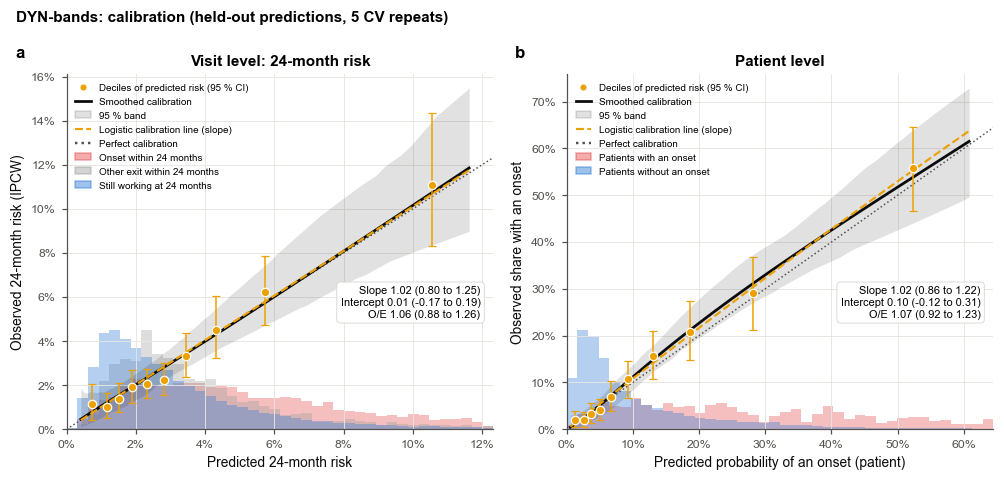

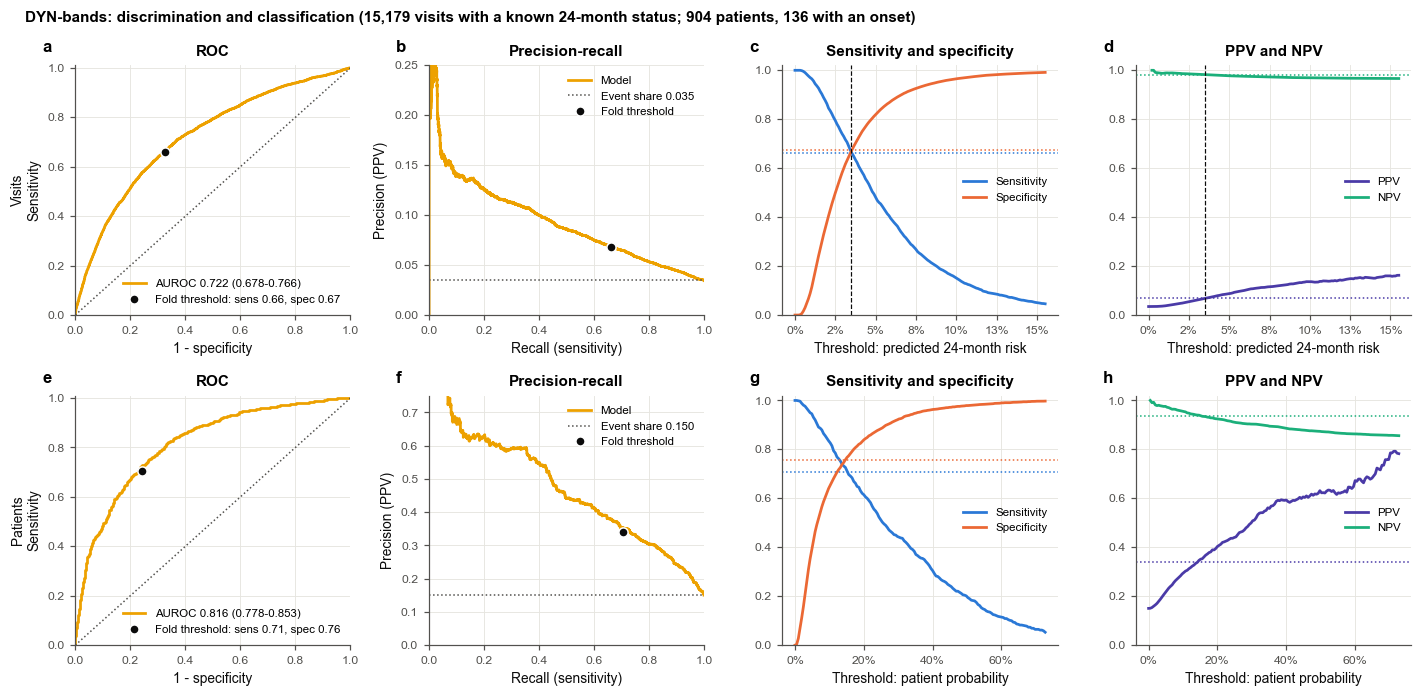

In [76]:
model_section(DYN_BANDS)

## 12.2 Baseline (index visit and demographics; primary comparison)

Baseline: index visit + demographics + calendar year, one hazard


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.580 (0.529 to 0.633)
Time-matched patient sensitivity / specificity,-,0.418 / 0.661
Concordance (AUROC; patient: windows),0.618 (0.565 to 0.672),0.771 (0.732 to 0.811)
Risk-set C (calendar-time risk sets),-,0.582 (0.530 to 0.635)
Calibration slope,0.882 (0.520 to 1.215),1.034 (0.867 to 1.227)
Calibration intercept,-0.052 (-0.220 to 0.123),0.004 (-0.189 to 0.189)
Observed / expected,0.997 (0.822 to 1.186),1.003 (0.857 to 1.148)
"Threshold (24-month risk, median over folds)",3.7 %,fold patient threshold
Sensitivity,0.576 (0.501 to 0.650),0.750 (0.689 to 0.815)


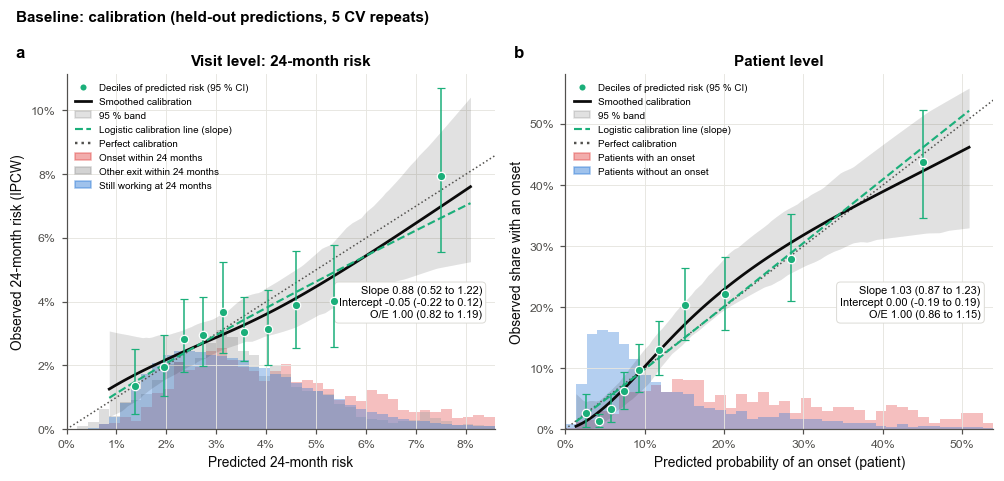

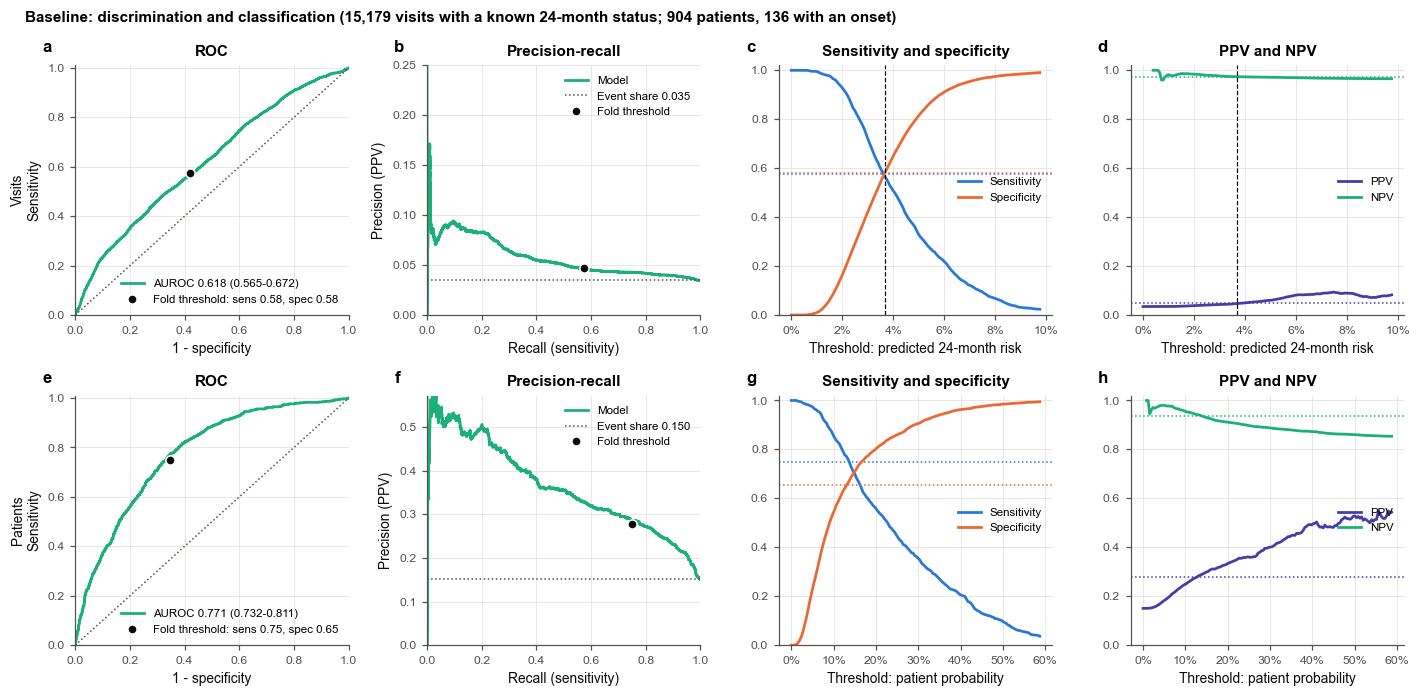

In [77]:
model_section(BASELINE)

## 12.3 Logistic regression on the main model's inputs (secondary comparison)

LogReg: logistic regression of the 24-month label on DYN's inputs at the landmark visit


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.724 (0.684 to 0.764)
Time-matched patient sensitivity / specificity,-,0.581 / 0.715
Concordance (AUROC; patient: windows),0.721 (0.678 to 0.763),0.806 (0.769 to 0.846)
Risk-set C (calendar-time risk sets),-,0.725 (0.685 to 0.766)
Calibration slope,0.908 (0.738 to 1.098),0.904 (0.773 to 1.078)
Calibration intercept,-0.063 (-0.258 to 0.116),-0.000 (-0.218 to 0.212)
Observed / expected,0.987 (0.820 to 1.171),1.000 (0.858 to 1.147)
"Threshold (24-month risk, median over folds)",3.6 %,fold patient threshold
Sensitivity,0.633 (0.568 to 0.701),0.710 (0.641 to 0.780)


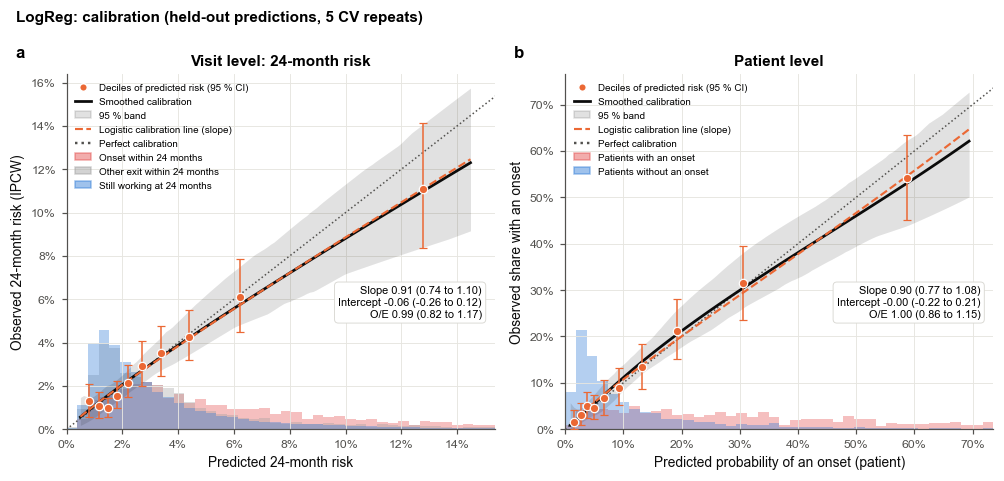

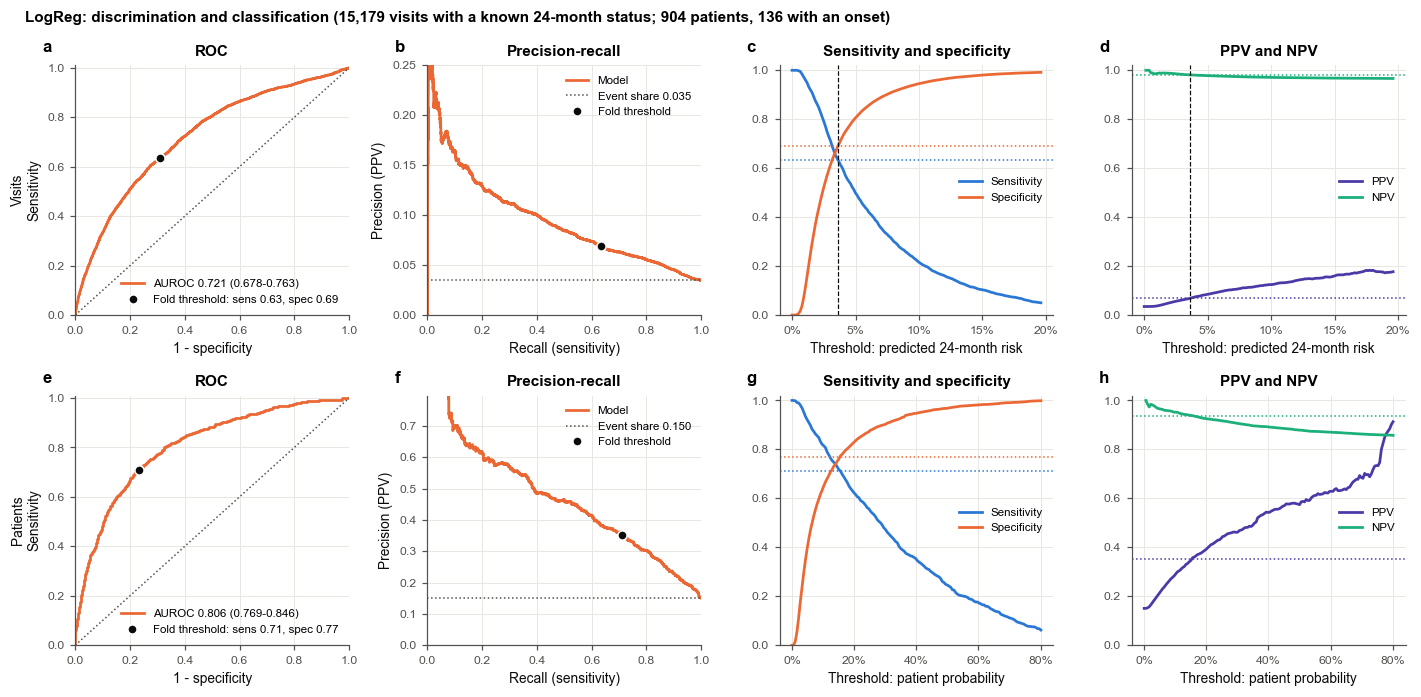

In [78]:
model_section(LOGREG)

## 12.4 Band-hazard regression on the main model's inputs

Reg-DYN: Poisson regression on DYN's inputs at the landmark visit, band hazards


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.720 (0.679 to 0.764)
Time-matched patient sensitivity / specificity,-,0.576 / 0.699
Concordance (AUROC; patient: windows),0.718 (0.674 to 0.761),0.804 (0.765 to 0.843)
Risk-set C (calendar-time risk sets),-,0.724 (0.681 to 0.766)
Calibration slope,1.001 (0.782 to 1.214),1.024 (0.871 to 1.244)
Calibration intercept,-0.044 (-0.231 to 0.126),-0.015 (-0.210 to 0.199)
Observed / expected,1.001 (0.831 to 1.191),0.990 (0.853 to 1.136)
"Threshold (24-month risk, median over folds)",3.5 %,fold patient threshold
Sensitivity,0.643 (0.576 to 0.710),0.681 (0.614 to 0.751)


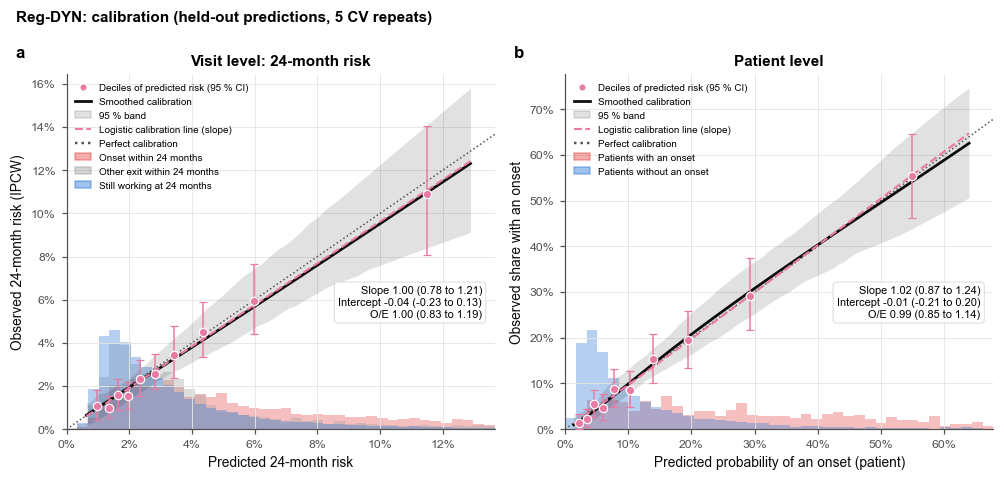

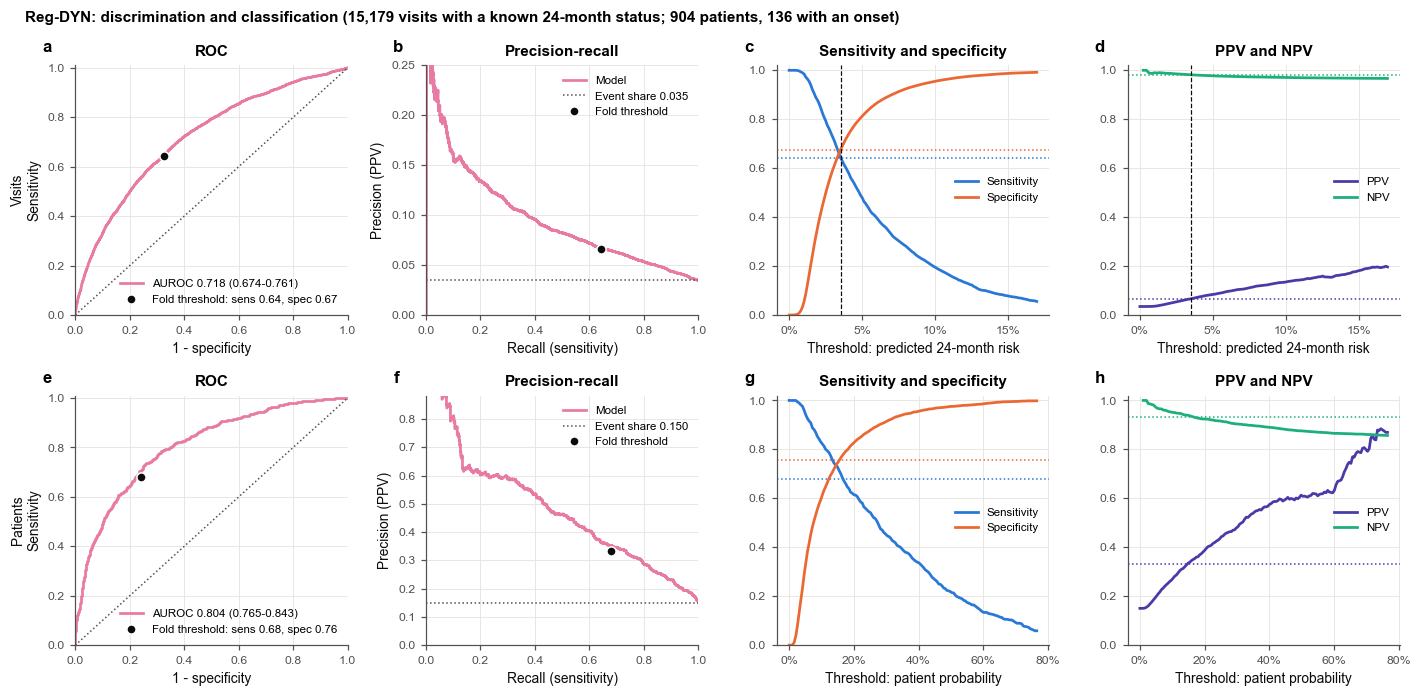

In [79]:
model_section(REG_DYN)

## 12.5 S0: grid LSTM over all history, scores pooled over 24 months (a 'trait' model)

S0: grid LSTM, all history, current status, one hazard, scores pooled over 24 months


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.711 (0.670 to 0.754)
Time-matched patient sensitivity / specificity,-,0.611 / 0.669
Concordance (AUROC; patient: windows),0.716 (0.667 to 0.761),0.807 (0.767 to 0.845)
Risk-set C (calendar-time risk sets),-,0.726 (0.686 to 0.768)
Calibration slope,1.027 (0.783 to 1.263),1.061 (0.884 to 1.227)
Calibration intercept,-0.033 (-0.216 to 0.137),0.024 (-0.169 to 0.237)
Observed / expected,1.014 (0.839 to 1.206),1.017 (0.877 to 1.168)
"Threshold (24-month risk, median over folds)",3.9 %,fold patient threshold
Sensitivity,0.631 (0.557 to 0.710),0.729 (0.663 to 0.796)


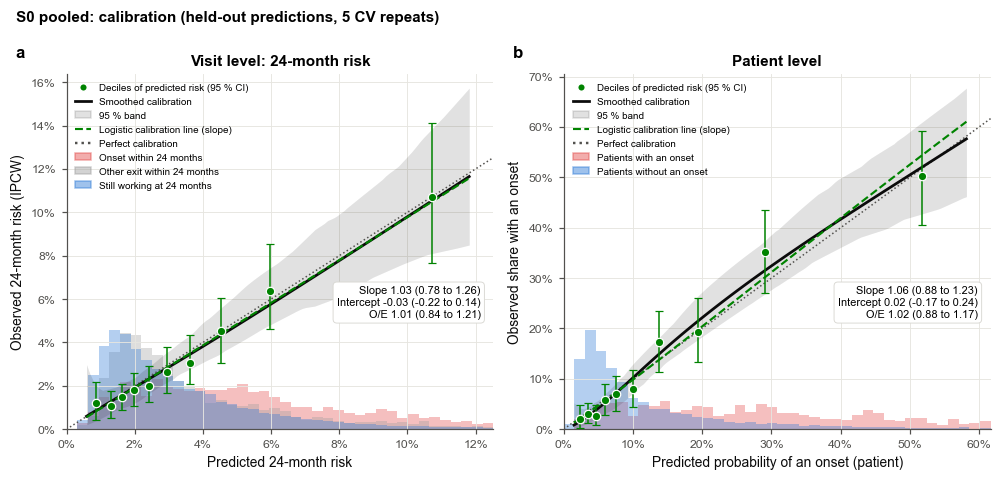

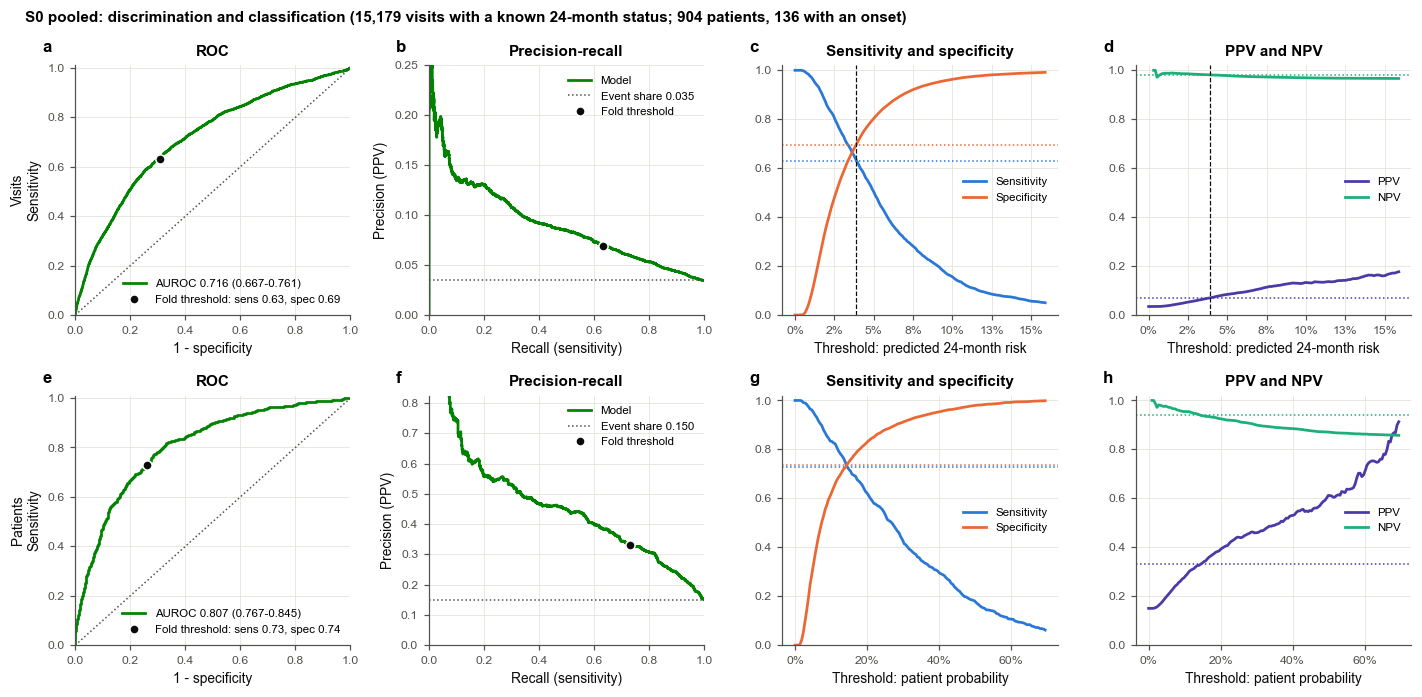

In [80]:
model_section(V8_MAIN)

## 12.6 Two-part model: trait offset + LSTM on change only

Two-part: Baseline offset (trait) + LSTM on change only, band hazards


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.688 (0.646 to 0.733)
Time-matched patient sensitivity / specificity,-,0.600 / 0.609
Concordance (AUROC; patient: windows),0.694 (0.650 to 0.742),0.817 (0.782 to 0.853)
Risk-set C (calendar-time risk sets),-,0.699 (0.660 to 0.742)
Calibration slope,1.062 (0.808 to 1.320),1.109 (0.935 to 1.284)
Calibration intercept,0.005 (-0.158 to 0.178),0.078 (-0.120 to 0.276)
Observed / expected,1.052 (0.875 to 1.245),1.057 (0.905 to 1.207)
"Threshold (24-month risk, median over folds)",3.6 %,fold patient threshold
Sensitivity,0.654 (0.584 to 0.724),0.724 (0.656 to 0.789)


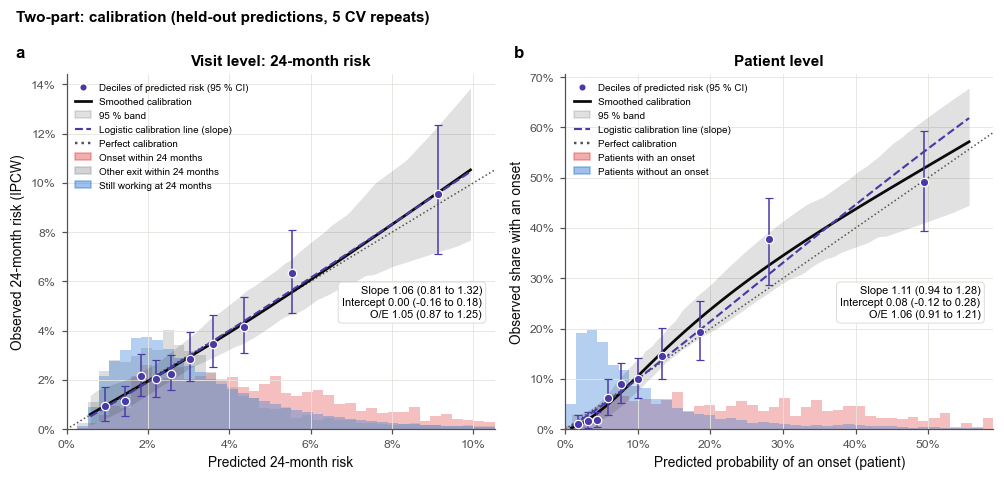

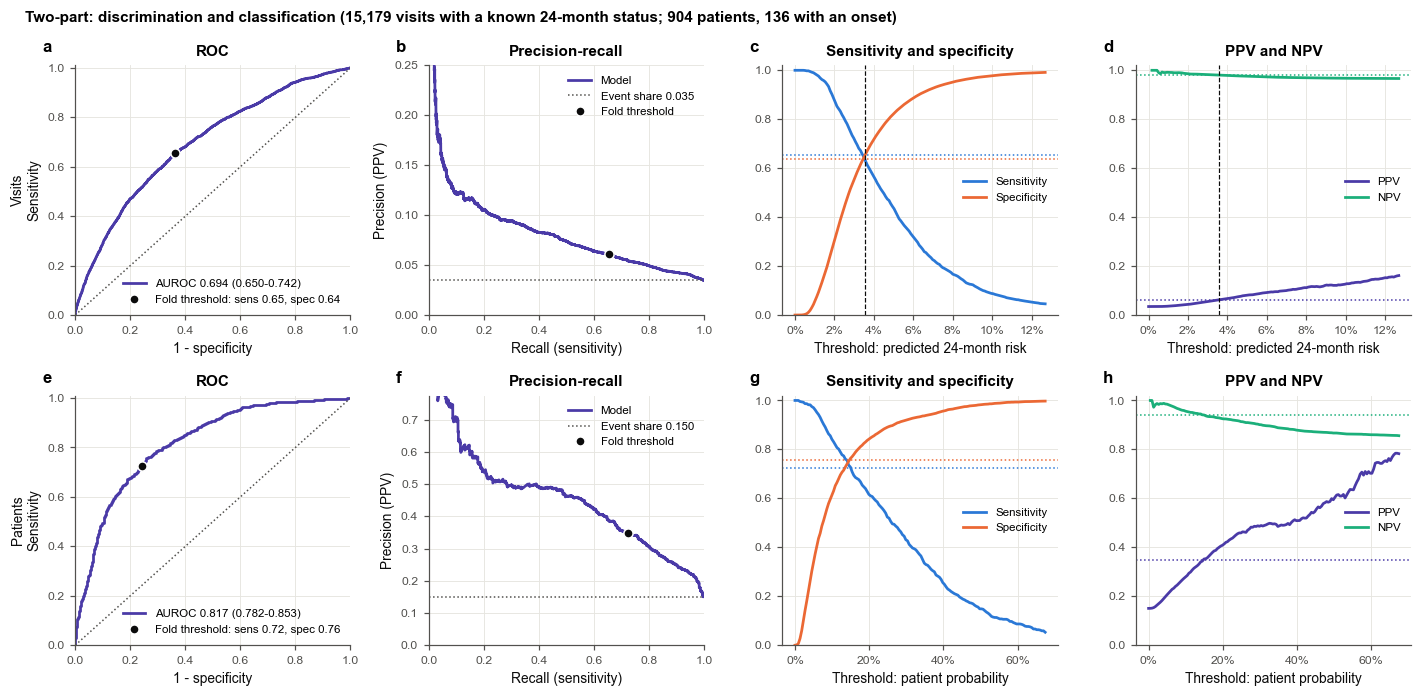

In [81]:
model_section(TWO_PART)

## 12.7 Average of the dynamic LSTM and the dynamic regression

Average: DYN + Reg-DYN


,Visit level,Patient level
Metric,,
Time-matched patient AUROC (primary),-,0.733 (0.695 to 0.774)
Time-matched patient sensitivity / specificity,-,0.613 / 0.691
Concordance (AUROC; patient: windows),0.727 (0.684 to 0.769),0.819 (0.782 to 0.857)
Risk-set C (calendar-time risk sets),-,0.743 (0.702 to 0.785)
Calibration slope,1.084 (0.874 to 1.303),1.019 (0.873 to 1.212)
Calibration intercept,-0.011 (-0.196 to 0.163),0.008 (-0.204 to 0.228)
Observed / expected,1.033 (0.856 to 1.225),1.005 (0.867 to 1.157)
"Threshold (24-month risk, median over folds)",3.7 %,fold patient threshold
Sensitivity,0.627 (0.560 to 0.694),0.728 (0.663 to 0.792)


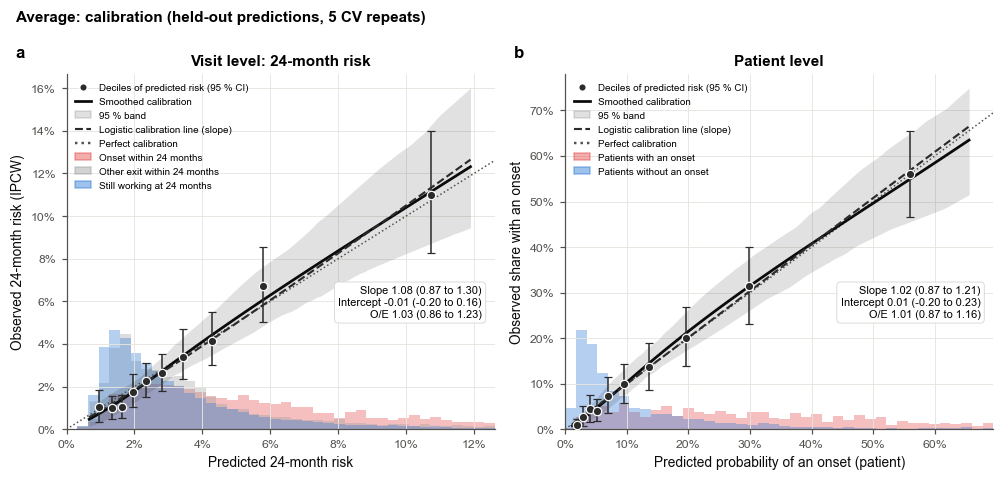

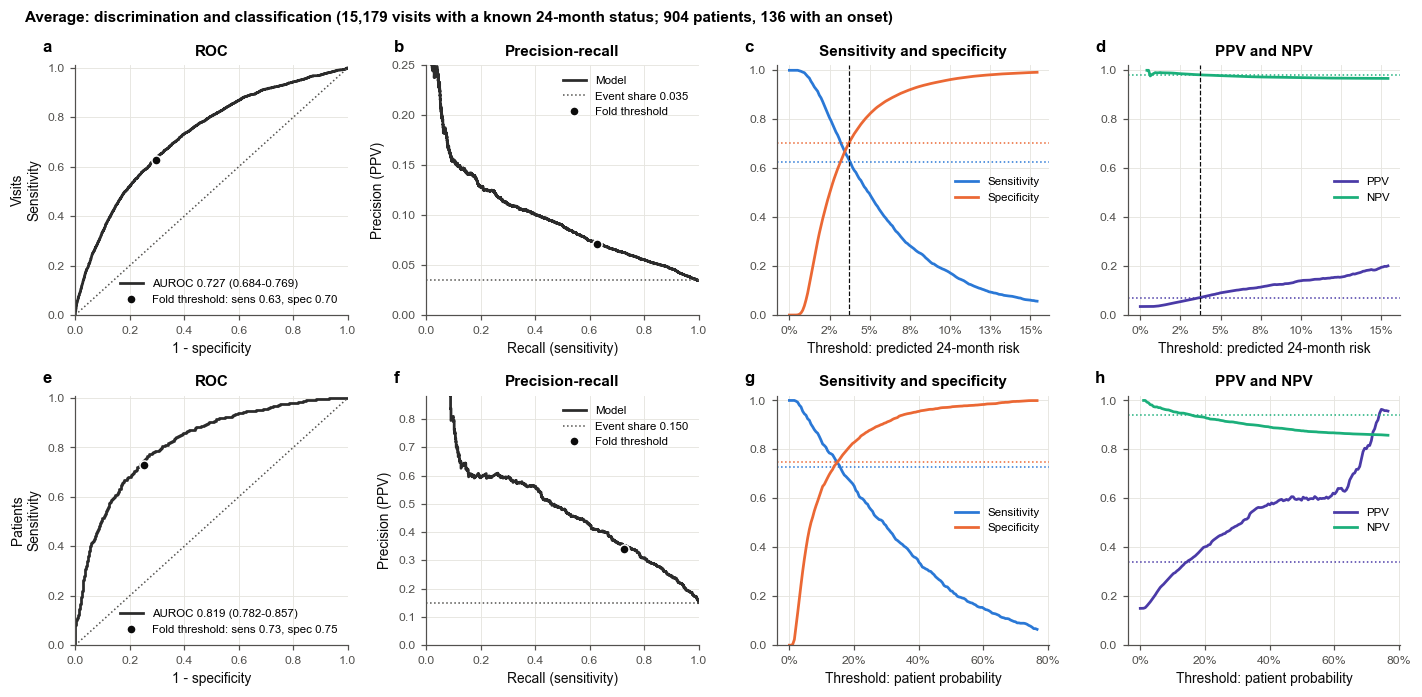

In [82]:
model_section(AVG_MODEL)

## 12.8 Every model: the main metrics

One row per model; the 24-month risk at the patient level (time-matched) and the visit level, value (95 % CI), ranked by the
primary metric. The ranking is descriptive: only the prespecified contrasts (Section 8) are tested.

,Time-matched patient AUROC (primary),"Visit AUROC, 24 months",Risk-set C,Patient AUROC (windows),Visit calibration slope,Visit O/E,Patient sensitivity,Patient specificity,Patient PPV,Visit sensitivity,Visit specificity,Visit PPV
Model,,,,,,,,,,,,
DYN,0.735 (0.697 to 0.775),0.727 (0.684 to 0.767),0.748 (0.709 to 0.788),0.822 (0.784 to 0.859),1.051 (0.868 to 1.261),1.033 (0.855 to 1.231),0.706 (0.637 to 0.776),0.782 (0.755 to 0.807),0.366 (0.308 to 0.422),0.649 (0.582 to 0.717),0.688 (0.663 to 0.713),0.070 (0.056 to 0.084)
Average,0.733 (0.695 to 0.774),0.727 (0.684 to 0.769),0.743 (0.702 to 0.785),0.819 (0.782 to 0.857),1.084 (0.874 to 1.303),1.033 (0.856 to 1.225),0.728 (0.663 to 0.792),0.749 (0.719 to 0.776),0.340 (0.286 to 0.393),0.627 (0.560 to 0.694),0.703 (0.678 to 0.730),0.071 (0.057 to 0.087)
S1 no-pool,0.728 (0.688 to 0.768),0.725 (0.680 to 0.770),0.743 (0.703 to 0.785),0.819 (0.782 to 0.857),1.039 (0.820 to 1.261),1.026 (0.854 to 1.218),0.753 (0.688 to 0.819),0.749 (0.720 to 0.777),0.349 (0.295 to 0.404),0.670 (0.598 to 0.742),0.676 (0.648 to 0.703),0.069 (0.055 to 0.084)
LogReg,0.724 (0.684 to 0.764),0.721 (0.678 to 0.763),0.725 (0.685 to 0.766),0.806 (0.769 to 0.846),0.908 (0.738 to 1.098),0.987 (0.820 to 1.171),0.710 (0.641 to 0.780),0.768 (0.740 to 0.795),0.352 (0.297 to 0.408),0.633 (0.568 to 0.701),0.691 (0.664 to 0.717),0.069 (0.055 to 0.084)
Reg-DYN,0.720 (0.679 to 0.764),0.718 (0.674 to 0.761),0.724 (0.681 to 0.766),0.804 (0.765 to 0.843),1.001 (0.782 to 1.214),1.001 (0.831 to 1.191),0.681 (0.614 to 0.751),0.757 (0.729 to 0.783),0.332 (0.279 to 0.385),0.643 (0.576 to 0.710),0.673 (0.645 to 0.701),0.066 (0.053 to 0.081)
Reg-pooled,0.714 (0.671 to 0.756),0.711 (0.665 to 0.755),0.733 (0.692 to 0.775),0.784 (0.741 to 0.825),1.002 (0.765 to 1.213),0.997 (0.829 to 1.188),0.707 (0.641 to 0.775),0.735 (0.705 to 0.763),0.322 (0.269 to 0.370),0.666 (0.588 to 0.736),0.675 (0.647 to 0.702),0.069 (0.055 to 0.084)
S0 pooled,0.711 (0.670 to 0.754),0.716 (0.667 to 0.761),0.726 (0.686 to 0.768),0.807 (0.767 to 0.845),1.027 (0.783 to 1.263),1.014 (0.839 to 1.206),0.729 (0.663 to 0.796),0.738 (0.706 to 0.766),0.330 (0.278 to 0.382),0.631 (0.557 to 0.710),0.693 (0.665 to 0.721),0.069 (0.055 to 0.085)
DYN-bands,0.710 (0.671 to 0.752),0.722 (0.678 to 0.766),0.725 (0.685 to 0.766),0.816 (0.778 to 0.853),1.022 (0.804 to 1.248),1.060 (0.879 to 1.262),0.706 (0.639 to 0.773),0.758 (0.731 to 0.784),0.342 (0.288 to 0.396),0.662 (0.591 to 0.731),0.673 (0.647 to 0.699),0.068 (0.055 to 0.083)
S2 bands,0.708 (0.666 to 0.751),0.724 (0.679 to 0.769),0.720 (0.679 to 0.764),0.816 (0.777 to 0.853),1.013 (0.804 to 1.245),1.048 (0.870 to 1.250),0.732 (0.667 to 0.801),0.751 (0.722 to 0.779),0.343 (0.290 to 0.395),0.653 (0.581 to 0.725),0.674 (0.647 to 0.703),0.068 (0.054 to 0.083)


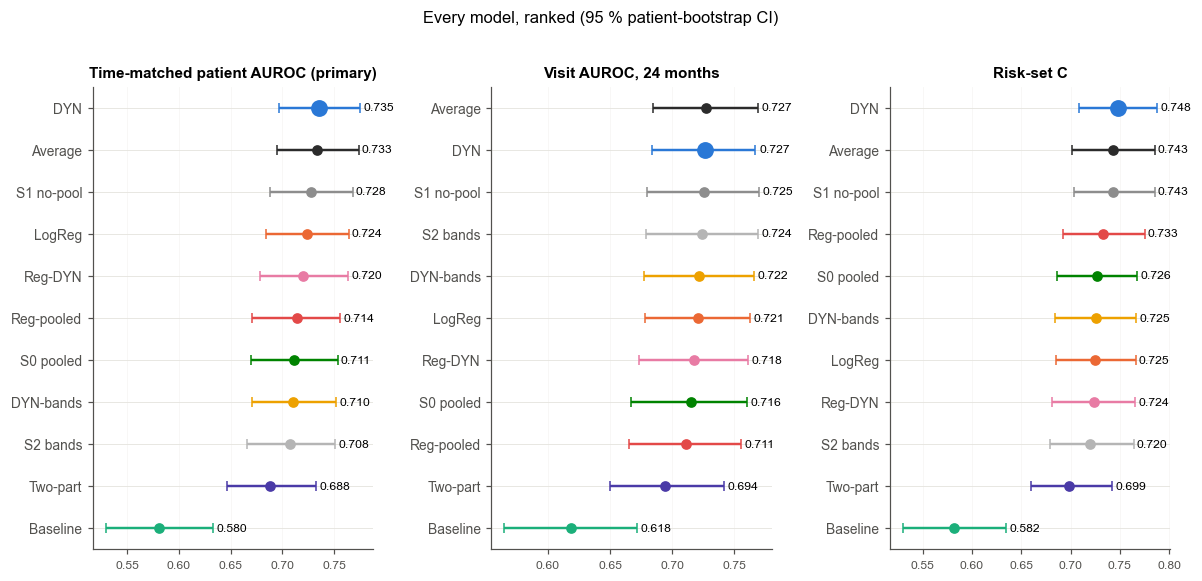

In [83]:
"""Every model on the main metrics (24 months)."""
SUM_KEYS = [("Time-matched patient AUROC (primary)", K_TM), (f"Visit AUROC, {H} months", K_VIS), ("Risk-set C", K_RS),
            ("Patient AUROC (windows)", K_PT),
            ("Visit calibration slope", ("visit", H, "cal_slope")), ("Visit O/E", ("visit", H, "oe")),
            ("Patient sensitivity", ("patient", H, MAIN_THRESHOLD, "sensitivity")),
            ("Patient specificity", ("patient", H, MAIN_THRESHOLD, "specificity")),
            ("Patient PPV", ("patient", H, MAIN_THRESHOLD, "ppv")),
            ("Visit sensitivity", ("visit", H, MAIN_THRESHOLD, "sensitivity")),
            ("Visit specificity", ("visit", H, MAIN_THRESHOLD, "specificity")),
            ("Visit PPV", ("visit", H, MAIN_THRESHOLD, "ppv"))]
ALL_TABLE = pd.DataFrame([{"Model": short_label(m), **{lab_: fmtk((m,) + k) for lab_, k in SUM_KEYS}}
                          for m in sorted(MODELS_RUN, key=lambda m: -ci((m,) + K_TM)[0])]).set_index("Model")
display(ALL_TABLE)
ALL_TABLE.to_csv(f"all_models_{TAG}.csv")
fig, axes = plt.subplots(1, 3, figsize=(11, 0.32 * len(MODELS_RUN) + 1.6))
for ax, (lab_, key) in zip(axes, SUM_KEYS[:3]):
    order = sorted(MODELS_RUN, key=lambda m: ci((m,) + key)[0])
    for y_, m in enumerate(order):
        a = ci((m,) + key)
        ax.errorbar(a[0], y_, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", color=model_color(m), capsize=3,
                    ms=10 if m == MAIN_MODEL else 6)
        ax.text(a[2] + 0.003, y_, f"{a[0]:.3f}", va="center", fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([short_label(m) for m in order], fontsize=9)
    ax.set_title(lab_); ax.grid(axis="x", alpha=0.3)
fig.suptitle("Every model, ranked (95 % patient-bootstrap CI)", y=1.02)
plt.tight_layout(); save_fig("ranking")

---
# 13. Objective 1 — Patients who go on to work disability score higher than those who do not

## 13.1 Primary and secondary tests (time-matched patient AUROC)

**H1a (primary)**: the dynamic LSTM separates the patients who go on to an onset from those still working on the
same date better than the Baseline (index-visit age, SDI and SLEDAI-2K; current age, education, race, calendar year).
Estimand: DYN − Baseline, time-matched patient AUROC (24-month window before each onset; Section 11.8).
**H1b (secondary)**: DYN − LogReg (logistic regression of the 24-month label on the same inputs). Verdicts:
**superior** if the lower 95 % bound > 0; **inferior** if the upper bound < 0; **equivalent** if the CI lies within
±0.02; otherwise inconclusive. The same contrasts on the patient sensitivity / specificity, the visit AUROC, the
risk-set C and the patient-window AUROC are shown alongside, with the difference in each CV repeat.
**H1d**: DYN − DYN-bands: does one hazard lose anything against a hazard per 6-month band?

H1a (primary) per CV repeat (DYN - Baseline): +0.150, +0.153, +0.152, +0.146, +0.172
H1b per CV repeat (DYN - LogReg): +0.012, +0.024, +0.003, +0.004, +0.014
H1d per CV repeat (DYN - DYN-bands): +0.025, +0.026, +0.015, +0.033, +0.026


DYN                        Comparator      Difference (95% CI)  p (bootstrap)       Verdict
Hypothesis    Metric                                                                                                                                        
H1a (primary) Time-matched patient AUROC      0.735 (0.697 to 0.775)   Baseline 0.580 (0.529 to 0.633)   0.155 (0.106 to 0.206)          0.000      superior
              Time-matched balanced accuracy  0.666 (0.635 to 0.696)   Baseline 0.539 (0.511 to 0.569)   0.126 (0.094 to 0.158)          0.000      superior
              Visit AUROC 24 mo               0.727 (0.684 to 0.767)   Baseline 0.618 (0.565 to 0.672)   0.108 (0.065 to 0.154)          0.000      superior
              Risk-set C                      0.748 (0.709 to 0.788)   Baseline 0.582 (0.530 to 0.635)   0.166 (0.114 to 0.218)          0.000      superior
              Patient AUROC (windows)         0.822 (0.784 to 0.859)   Baseline 0.771 (0.732 to 0.811)   0.052 (0.016 to 0.090)          0.006      superior
H1b           Time-matched patient AUROC      0.735 (0.697 to 0.775)     LogReg 0.724 (0.684 to 0.764)  0.011 (-0.007 to 0.031)          0.220  inconclusive
              Time-matched balanced accuracy  0.666 (0.635 to 0.696)     LogReg 0.648 (0.618 to 0.678)  0.018 (-0.000 to 0.035)          0.054  inconclusive
              Visit AUROC 24 mo               0.727 (0.684 to 0.767)     LogReg 0.721 (0.678 to 0.763)  0.005 (-0.008 to 0.018)          0.450    equivalent
              Risk-set C                      0.748 (0.709 to 0.788)     LogReg 0.725 (0.685 to 0.766)   0.024 (0.006 to 0.042)          0.004      superior
              Patient AUROC (windows)         0.822 (0.784 to 0.859)     LogReg 0.806 (0.769 to 0.846)   0.016 (0.001 to 0.030)          0.038      superior
H1d           Time-matched patient AUROC      0.735 (0.697 to 0.775)  DYN-bands 0.710 (0.671 to 0.752)   0.025 (0.008 to 0.042)          0.000      superior
              Time-matched balanced accuracy  0.666 (0.635 to 0.696)  DYN-bands 0.636 (0.606 to 0.666)   0.029 (0.012 to 0.047)          0.002      superior
              Visit AUROC 24 mo               0.727 (0.684 to 0.767)  DYN-bands 0.722 (0.678 to 0.766)  0.005 (-0.011 to 0.020)          0.630    equivalent
              Risk-set C                      0.748 (0.709 to 0.788)  DYN-bands 0.725 (0.685 to 0.766)   0.023 (0.006 to 0.039)          0.008      superior
              Patient AUROC (windows)         0.822 (0.784 to 0.859)  DYN-bands 0.816 (0.778 to 0.853)  0.007 (-0.007 to 0.021)          0.382  inconclusive

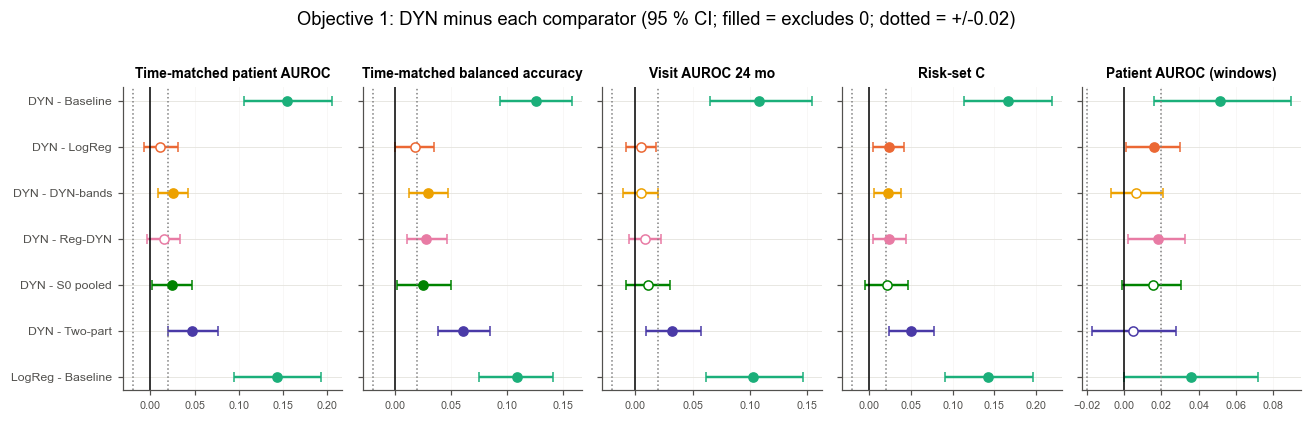

In [84]:
"""H1a (primary) and H1b: DYN - Baseline and DYN - LogReg."""


def forest(D, ycol, metrics, title, fname, color_of=None, ref=0.0, margin=None):
    """Forest plot of paired differences (filled = CI excludes 0), one panel per metric."""
    labs = list(dict.fromkeys(D[ycol]))
    yy = np.arange(len(labs))[::-1]
    fig, axes = plt.subplots(1, len(metrics), figsize=(2.4 * len(metrics), 0.3 * len(labs) + 1.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, met in zip(axes, metrics):
        d = D[D["Metric"] == met].set_index(ycol).reindex(labs)
        for y_, (lab_, r_) in zip(yy, d.iterrows()):
            if np.isnan(r_["Difference"]):
                continue
            col = color_of(lab_) if color_of else "k"
            sig = r_["Lower"] > ref or r_["Upper"] < ref
            ax.errorbar(r_["Difference"], y_, xerr=[[r_["Difference"] - r_["Lower"]], [r_["Upper"] - r_["Difference"]]],
                        fmt="o", color=col, mfc=col if sig else "white", capsize=3)
        ax.axvline(ref, color="k", lw=1)
        if margin:
            for s_ in (-margin, margin):
                ax.axvline(s_, color="grey", ls=":", lw=1)
        ax.grid(axis="x", alpha=0.3); ax.set_yticks(yy); ax.set_yticklabels(labs, fontsize=8)
        ax.set_title(met, fontsize=9); ax.tick_params(axis="x", labelsize=7)
    fig.suptitle(title, y=1.02, fontsize=12)
    plt.tight_layout(); save_fig(f"{fname}")


CMP_KEYS = [("Patient AUROC", K_PT), ("Visit AUROC", K_VIS), ("Risk-set C", K_RS),
            ("Patient balanced accuracy", ("patient", H, MAIN_THRESHOLD, "balanced_accuracy")),
            ("Visit balanced accuracy", ("visit", H, MAIN_THRESHOLD, "balanced_accuracy"))]


def compare(pairs, keys=CMP_KEYS, n_comp=1):
    rows = []
    for a, b in pairs:
        if a not in MODELS_RUN or b not in MODELS_RUN:
            continue
        for lab_, key in keys:
            d = diff(a, b, key, n_comp)
            rows.append({"Comparison": f"{short_label(a)} - {short_label(b)}", "Metric": lab_,
                         "First": ci((a,) + key)[0], "Second": ci((b,) + key)[0], "Difference": d[0],
                         "Lower": d[1], "Upper": d[2], "p (bootstrap)": d[3]})
    return pd.DataFrame(rows)


def show_cmp(D):
    s = D.copy()
    s["Difference (95% CI)"] = [fmt(a, b, c) for a, b, c in zip(s["Difference"], s["Lower"], s["Upper"])]
    display(s.pivot(index="Comparison", columns="Metric", values="Difference (95% CI)")
            .reindex(list(dict.fromkeys(s["Comparison"])))[list(dict.fromkeys(s["Metric"]))])



def repeat_tm(a, b, key=K_TM):
    """a - b in each CV repeat (time-matched patient AUROC, point estimate)."""
    d = TM[key[1]]
    return [tm_stats_one(a, r, d)["auroc"][0] - tm_stats_one(b, r, d)["auroc"][0] for r in REPEATS]


OBJ1_KEYS = [("Time-matched patient AUROC", K_TM),
             ("Time-matched balanced accuracy", ("tm", "main", "balanced_accuracy")),
             (f"Visit AUROC {H} mo", K_VIS), ("Risk-set C", K_RS), ("Patient AUROC (windows)", K_PT)]
rows = []
for hyp, (a, b_) in [("H1a (primary)", (MAIN_MODEL, BASELINE)), ("H1b", (MAIN_MODEL, LOGREG)),
                     ("H1d", (MAIN_MODEL, DYN_BANDS))]:
    for lab_, key in OBJ1_KEYS:
        d = diff(a, b_, key)
        rows.append({"Hypothesis": hyp, "Metric": lab_, short_label(a): fmtk((a,) + key),
                     "Comparator": f"{short_label(b_)} {fmtk((b_,) + key)}", "Difference (95% CI)": fmt(*d[:3]),
                     "p (bootstrap)": round(d[3], 3), "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})
    d = diff(a, b_, K_TM)
    HYP_ROWS.append({"Hypothesis": hyp, "Estimand": f"{short_label(a)} - {short_label(b_)}, time-matched patient AUROC",
                     "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0 (equivalence +/-0.02)",
                     "Met": d[1] > 0, "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})
    print(f"{hyp} per CV repeat ({short_label(a)} - {short_label(b_)}): " +
          ", ".join(f"{x:+.3f}" for x in repeat_tm(a, b_)))
PRIMARY = pd.DataFrame(rows).set_index(["Hypothesis", "Metric"])
display(PRIMARY)
PRIMARY.to_csv(f"primary_tests_{TAG}.csv")
_H1_PAIRS = [(MAIN_MODEL, BASELINE), (MAIN_MODEL, LOGREG), (MAIN_MODEL, DYN_BANDS), (MAIN_MODEL, REG_DYN),
             (MAIN_MODEL, V8_MAIN), (MAIN_MODEL, TWO_PART), (LOGREG, BASELINE)]
H1 = compare(_H1_PAIRS, keys=OBJ1_KEYS)
_col = {f"{short_label(a)} - {short_label(b_)}": model_color(b_) for a, b_ in _H1_PAIRS}
forest(H1, "Comparison", [k for k, _ in OBJ1_KEYS], "Objective 1: DYN minus each comparator (95 % CI; filled = "
       "excludes 0; dotted = +/-0.02)", "objective1_forest", color_of=_col.get, margin=EQUIV_MARGIN)
H1.to_csv(f"objective1_contrasts_{TAG}.csv", index=False)

## 13.2 The time-matched patient AUROC of every model, and the ROC of the key models

Every model's time-matched patient AUROC, sensitivity and specificity (fold thresholds), with the ROC curves of
the main model, the Baseline and LogReg (case-control pairs pooled over the onsets, each onset's controls weighted
equally; first CV repeat).

,Time-matched AUROC,Sensitivity,Specificity,Balanced accuracy,Visit AUROC 24 mo
Model,,,,,
DYN,0.735 (0.697 to 0.775),0.649 (0.586 to 0.715),0.682 (0.645 to 0.719),0.666 (0.635 to 0.696),0.727 (0.684 to 0.767)
Average,0.733 (0.695 to 0.774),0.613 (0.549 to 0.680),0.691 (0.651 to 0.729),0.652 (0.622 to 0.682),0.727 (0.684 to 0.769)
S1 no-pool,0.728 (0.688 to 0.768),0.654 (0.590 to 0.719),0.659 (0.621 to 0.698),0.657 (0.627 to 0.688),0.725 (0.680 to 0.770)
LogReg,0.724 (0.684 to 0.764),0.581 (0.514 to 0.653),0.715 (0.676 to 0.751),0.648 (0.618 to 0.678),0.721 (0.678 to 0.763)
Reg-DYN,0.720 (0.679 to 0.764),0.576 (0.511 to 0.643),0.699 (0.659 to 0.737),0.638 (0.607 to 0.666),0.718 (0.674 to 0.761)
Reg-pooled,0.714 (0.671 to 0.756),0.648 (0.580 to 0.715),0.656 (0.618 to 0.694),0.652 (0.618 to 0.686),0.711 (0.665 to 0.755)
S0 pooled,0.711 (0.670 to 0.754),0.611 (0.543 to 0.681),0.669 (0.632 to 0.706),0.640 (0.608 to 0.674),0.716 (0.667 to 0.761)
DYN-bands,0.710 (0.671 to 0.752),0.596 (0.532 to 0.665),0.676 (0.638 to 0.715),0.636 (0.606 to 0.666),0.722 (0.678 to 0.766)
S2 bands,0.708 (0.666 to 0.751),0.556 (0.483 to 0.628),0.691 (0.652 to 0.731),0.623 (0.592 to 0.657),0.724 (0.679 to 0.769)


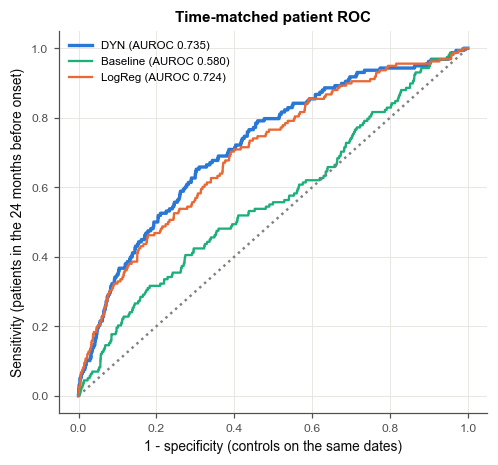

In [85]:
"""Time-matched patient metrics of every model; ROC curves."""
rows = [{"Model": short_label(m), "Time-matched AUROC": fmtk((m,) + K_TM),
          "Sensitivity": fmtk((m, "tm", "main", "sensitivity")), "Specificity": fmtk((m, "tm", "main", "specificity")),
          "Balanced accuracy": fmtk((m, "tm", "main", "balanced_accuracy")), f"Visit AUROC {H} mo": fmtk((m,) + K_VIS)}
        for m in sorted(MODELS_RUN, key=lambda m: -ci((m,) + K_TM)[0])]
TM_TABLE = pd.DataFrame(rows).set_index("Model")
display(TM_TABLE)
TM_TABLE.to_csv(f"objective1_time_matched_{TAG}.csv")
fig, ax = plt.subplots(figsize=(4.6, 4.3))
d = TM["main"]
for m in KEY_MODELS:
    z = zpred(m, REPEATS[0])
    s = np.asarray(d["mat"] @ np.nan_to_num(z)).ravel()
    sc = np.r_[s[d["cases"]], s[d["pk"]]]
    yy = np.r_[np.ones(len(d["cases"])), np.zeros(len(d["pk"]))]
    ww = np.r_[np.ones(len(d["cases"])) / len(d["cases"]), d["w"] / d["w"].sum()]
    fpr, tpr, _ = roc_curve(yy, sc, sample_weight=ww)
    ax.plot(fpr, tpr, color=model_color(m), lw=2.2 if m == MAIN_MODEL else 1.5,
            label=f"{short_label(m)} (AUROC {ci((m,) + K_TM)[0]:.3f})")
ax.plot([0, 1], [0, 1], ":", color="grey"); ax.set_xlabel("1 - specificity (controls on the same dates)")
ax.set_ylabel(f"Sensitivity (patients in the {H} months before onset)"); ax.legend()
ax.set_title("Time-matched patient ROC")
plt.tight_layout(); save_fig("tm_roc")

## 13.3 H1c: calibration — every model

Calibration slope and intercept of the 24-month risk (visit level, IPCW) and of the patient probability; O/E at
both levels. Criterion (H1c, visit level): slope in [0.8, 1.2] and the intercept's 95 % CI containing 0. The risks
are recalibrated inside each training fold, so this checks that the recalibration transports to held-out patients.

,Visit slope,Visit intercept,Visit O/E,H1c met,Patient slope,Patient intercept,Patient O/E
Model,,,,,,,
S0 pooled,1.027 (0.783 to 1.263),-0.033 (-0.216 to 0.137),1.014 (0.839 to 1.206),True,1.061 (0.884 to 1.227),0.024 (-0.169 to 0.237),1.017 (0.877 to 1.168)
S1 no-pool,1.039 (0.820 to 1.261),-0.019 (-0.203 to 0.161),1.026 (0.854 to 1.218),True,1.064 (0.906 to 1.242),0.033 (-0.175 to 0.254),1.022 (0.881 to 1.177)
S2 bands,1.013 (0.804 to 1.245),-0.002 (-0.180 to 0.172),1.048 (0.870 to 1.250),True,1.019 (0.847 to 1.208),0.083 (-0.112 to 0.297),1.058 (0.914 to 1.212)
DYN-bands,1.022 (0.804 to 1.248),0.011 (-0.172 to 0.186),1.060 (0.879 to 1.262),True,1.021 (0.857 to 1.220),0.100 (-0.115 to 0.308),1.070 (0.919 to 1.228)
DYN,1.051 (0.868 to 1.261),-0.011 (-0.195 to 0.170),1.033 (0.855 to 1.231),True,1.065 (0.922 to 1.253),0.045 (-0.177 to 0.262),1.031 (0.887 to 1.184)
Two-part,1.062 (0.808 to 1.320),0.005 (-0.158 to 0.178),1.052 (0.875 to 1.245),True,1.109 (0.935 to 1.284),0.078 (-0.120 to 0.276),1.057 (0.905 to 1.207)
Reg-DYN,1.001 (0.782 to 1.214),-0.044 (-0.231 to 0.126),1.001 (0.831 to 1.191),True,1.024 (0.871 to 1.244),-0.015 (-0.210 to 0.199),0.990 (0.853 to 1.136)
LogReg,0.908 (0.738 to 1.098),-0.063 (-0.258 to 0.116),0.987 (0.820 to 1.171),True,0.904 (0.773 to 1.078),-0.000 (-0.218 to 0.212),1.000 (0.858 to 1.147)
Reg-pooled,1.002 (0.765 to 1.213),-0.043 (-0.228 to 0.132),0.997 (0.829 to 1.188),True,1.032 (0.872 to 1.216),-0.005 (-0.204 to 0.207),0.996 (0.856 to 1.146)


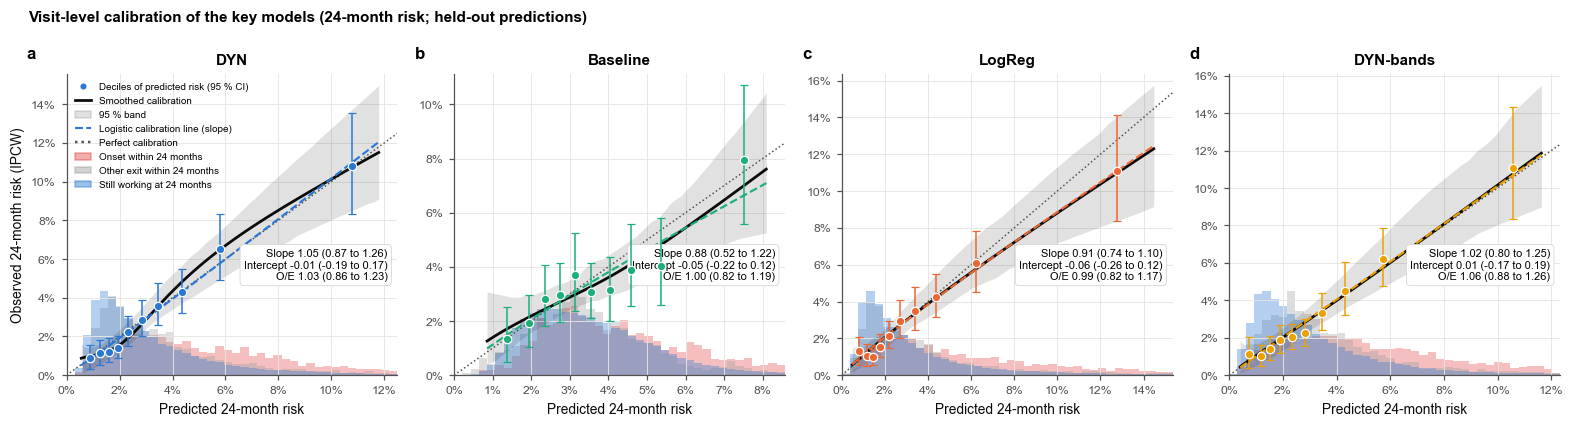

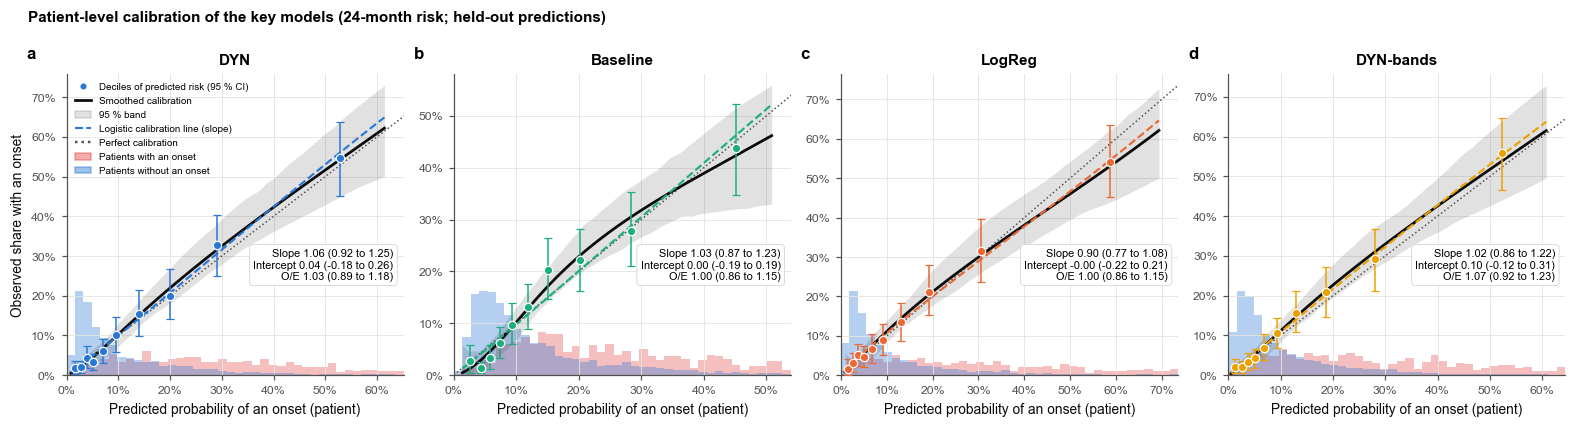

In [86]:
"""H1c: calibration of every model; calibration plots of the key models."""
rows = []
for m in MODELS_RUN:
    sl, ic = ci((m, "visit", H, "cal_slope")), ci((m, "visit", H, "cal_intercept"))
    met = CAL_SLOPE_RANGE[0] <= sl[0] <= CAL_SLOPE_RANGE[1] and ic[1] <= 0 <= ic[2]
    rows.append({"Model": short_label(m), "Visit slope": fmt(*sl), "Visit intercept": fmt(*ic),
                 "Visit O/E": fmtk((m, "visit", H, "oe")), "H1c met": met,
                 "Patient slope": fmtk((m, "patient", H, "cal_slope")),
                 "Patient intercept": fmtk((m, "patient", H, "cal_intercept")),
                 "Patient O/E": fmtk((m, "patient", H, "oe"))})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H1c", "Estimand": "Main: visit calibration slope / intercept",
                         "Estimate (95% CI)": f"{fmt(*sl)} / {fmt(*ic)}",
                         "Criterion": "slope in [0.8, 1.2], intercept CI includes 0", "Met": met})
CAL_TABLE = pd.DataFrame(rows).set_index("Model")
display(CAL_TABLE)
CAL_TABLE.to_csv(f"objective1_calibration_{TAG}.csv")
_cal_models = [m for m in [MAIN_MODEL, BASELINE, LOGREG, DYN_BANDS] if m in MODELS_RUN]
for level in ["visit", "patient"]:
    fig, axes = plt.subplots(1, len(_cal_models), figsize=(3.6 * len(_cal_models), 3.9), squeeze=False)
    for k_, (ax, m) in enumerate(zip(axes[0], _cal_models)):
        plot_calibration(ax, m, level, short_label(m), legend=(k_ == 0))
        if k_:
            ax.set_ylabel("")
        panel_label(ax, "abcd"[k_])
    fig.suptitle(f"{'Visit' if level == 'visit' else 'Patient'}-level calibration of the key models "
                 f"({H}-month risk; held-out predictions)", x=0.02, ha="left", fontsize=10, fontweight="bold")
    plt.tight_layout()
    save_fig(f"calibration_key_models_{level}")

## 13.4 Decision curves and fixed risk thresholds (descriptive)

Visit-level net benefit per landmark visit (IPCW) of alarming when the 24-month risk ≥ *t*, against alarming at
every visit and at none, over thresholds of 1-16 % (shaded: 2-10 %, the range of interest). The table counts the
thresholds from 2 % to 10 % at which each model's net benefit is above both (point estimate, and lower 95 % bound).
Then sensitivity, specificity, PPV and NPV at fixed 24-month risks of 5 % and 10 %.

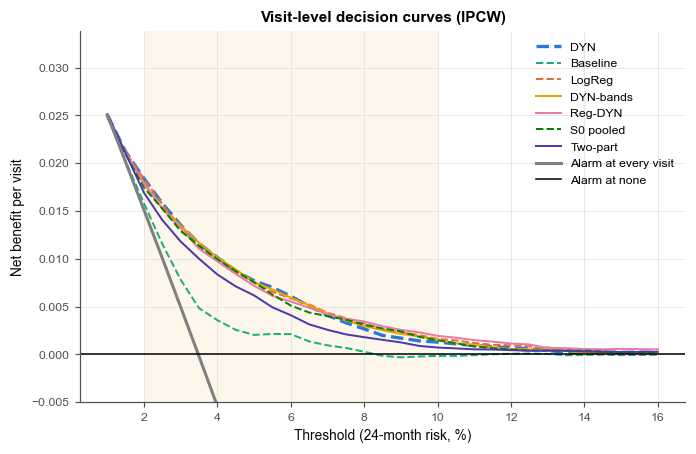

,Thresholds 2-10 % with NB above both (point),... (lower 95 % bound),NB at 2%,NB at 4%,NB at 6%,NB at 10%
Model,,,,,,
S0 pooled,17/17,12/17,0.0174 (0.0118 to 0.0238),0.0100 (0.0053 to 0.0150),0.0051 (0.0015 to 0.0091),0.0015 (-0.0007 to 0.0037)
S1 no-pool,17/17,12/17,0.0182 (0.0125 to 0.0246),0.0107 (0.0061 to 0.0154),0.0057 (0.0024 to 0.0095),0.0011 (-0.0008 to 0.0032)
S2 bands,17/17,12/17,0.0178 (0.0122 to 0.0243),0.0103 (0.0058 to 0.0154),0.0062 (0.0026 to 0.0101),0.0014 (-0.0005 to 0.0035)
DYN-bands,17/17,12/17,0.0178 (0.0122 to 0.0241),0.0101 (0.0058 to 0.0152),0.0059 (0.0026 to 0.0095),0.0016 (-0.0003 to 0.0036)
DYN,17/17,12/17,0.0184 (0.0126 to 0.0247),0.0101 (0.0058 to 0.0147),0.0061 (0.0029 to 0.0096),0.0013 (-0.0006 to 0.0032)
Two-part,17/17,10/17,0.0169 (0.0111 to 0.0228),0.0083 (0.0041 to 0.0131),0.0041 (0.0012 to 0.0073),0.0007 (-0.0006 to 0.0022)
Reg-DYN,17/17,12/17,0.0180 (0.0122 to 0.0241),0.0097 (0.0052 to 0.0147),0.0055 (0.0022 to 0.0092),0.0019 (-0.0004 to 0.0042)
LogReg,17/17,12/17,0.0183 (0.0127 to 0.0245),0.0099 (0.0055 to 0.0146),0.0059 (0.0023 to 0.0096),0.0016 (-0.0008 to 0.0042)
Reg-pooled,17/17,7/17,0.0170 (0.0113 to 0.0233),0.0103 (0.0057 to 0.0152),0.0042 (0.0007 to 0.0079),0.0014 (-0.0007 to 0.0038)


,Model,24-month risk >=,Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,S0 pooled,5%,0.505 (0.425 to 0.589),0.803 (0.778 to 0.826),0.085 (0.066 to 0.107),0.978 (0.972 to 0.983),0.654 (0.614 to 0.696),0.208 (0.184 to 0.233)
1,S0 pooled,10%,0.156 (0.102 to 0.218),0.963 (0.952 to 0.973),0.133 (0.086 to 0.188),0.969 (0.963 to 0.975),0.560 (0.533 to 0.590),0.041 (0.031 to 0.053)
2,S1 no-pool,5%,0.513 (0.443 to 0.587),0.810 (0.787 to 0.832),0.088 (0.070 to 0.109),0.979 (0.973 to 0.984),0.661 (0.626 to 0.696),0.202 (0.179 to 0.224)
3,S1 no-pool,10%,0.155 (0.104 to 0.211),0.960 (0.950 to 0.969),0.125 (0.084 to 0.172),0.969 (0.963 to 0.975),0.558 (0.532 to 0.585),0.044 (0.034 to 0.055)
4,S2 bands,5%,0.512 (0.436 to 0.594),0.810 (0.786 to 0.833),0.089 (0.069 to 0.111),0.979 (0.973 to 0.984),0.661 (0.624 to 0.702),0.201 (0.178 to 0.225)
5,S2 bands,10%,0.157 (0.108 to 0.216),0.962 (0.950 to 0.972),0.132 (0.089 to 0.181),0.969 (0.963 to 0.975),0.559 (0.536 to 0.587),0.042 (0.031 to 0.054)
6,DYN-bands,5%,0.481 (0.412 to 0.556),0.819 (0.798 to 0.840),0.088 (0.069 to 0.109),0.978 (0.972 to 0.983),0.650 (0.614 to 0.689),0.191 (0.170 to 0.213)
7,DYN-bands,10%,0.152 (0.106 to 0.202),0.965 (0.954 to 0.974),0.138 (0.096 to 0.192),0.969 (0.963 to 0.975),0.558 (0.536 to 0.582),0.039 (0.030 to 0.051)
8,DYN,5%,0.488 (0.421 to 0.555),0.817 (0.797 to 0.836),0.088 (0.069 to 0.108),0.978 (0.973 to 0.983),0.653 (0.619 to 0.688),0.193 (0.174 to 0.214)
9,DYN,10%,0.149 (0.104 to 0.197),0.964 (0.956 to 0.971),0.130 (0.089 to 0.177),0.969 (0.963 to 0.975),0.556 (0.534 to 0.580),0.040 (0.033 to 0.049)


In [87]:
"""Decision curves; fixed risk thresholds."""
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for m in FIG_MODELS:
    if m in MODELS_RUN:
        ax.plot(NB_GRID * 100, [ci((m, "visit", H, "nb", t))[0] for t in NB_GRID], color=model_color(m),
                ls=model_ls(m), lw=2.2 if m == MAIN_MODEL else 1.3, label=short_label(m))
ax.plot(NB_GRID * 100, [ci((MAIN_MODEL, "visit", H, "nb_all", t))[0] for t in NB_GRID], color="grey", lw=2,
        label="Alarm at every visit")
ax.axhline(0, color="k", lw=1, label="Alarm at none")
ax.axvspan(NB_RANGE[0] * 100, NB_RANGE[1] * 100, color="#eda100", alpha=0.08, lw=0)
ax.set_ylim(-0.005, None); ax.set_xlabel(f"Threshold ({H}-month risk, %)"); ax.set_ylabel("Net benefit per visit")
ax.set_title("Visit-level decision curves (IPCW)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("decision_curves")

_ts = [t for t in NB_GRID if NB_RANGE[0] - 1e-9 <= t <= NB_RANGE[1] + 1e-9]
rows = []
for m in MODELS_RUN:
    above, above_lo = 0, 0
    for t in _ts:
        nb = ci((m, "visit", H, "nb", t)); nba = ci((m, "visit", H, "nb_all", t))[0]
        above += nb[0] > max(nba, 0); above_lo += nb[1] > max(nba, 0)
    rows.append({"Model": short_label(m), "Thresholds 2-10 % with NB above both (point)": f"{above}/{len(_ts)}",
                 "... (lower 95 % bound)": f"{above_lo}/{len(_ts)}",
                 **{f"NB at {t:.0%}": fmtk((m, "visit", H, "nb", t), 4) for t in NB_SHOW}})
NB_TABLE = pd.DataFrame(rows).set_index("Model")
display(NB_TABLE)
NB_TABLE.to_csv(f"objective1_h1d_net_benefit_{TAG}.csv")
rows = []
for m in MODELS_RUN:
    for t in FIXED_RISKS:
        rows.append({"Model": short_label(m), f"{H}-month risk >=": f"{t:.0%}",
                     **{METRIC_LABELS[x]: fmtk((m, "visit", H, "fixed", t, x)) for x in CONF_METRICS}})
FIXED_TABLE = pd.DataFrame(rows)
display(FIXED_TABLE)
FIXED_TABLE.to_csv(f"objective1_fixed_thresholds_{TAG}.csv", index=False)

## 13.5 Risk tiers: the clinical output

A single yes/no alarm has a low PPV because onsets are rare. The model is more useful as a **risk tier**: the
recalibrated 24-month risk in four fixed tiers (< 2 %, 2-4 %, 4-10 %, ≥ 10 %; fixed in advance, not tuned), read as

* **< 2 % — low**: routine follow-up; the **rule-out** tier (what share of visits it covers, and what share of the
  onsets it misses);
* **2-4 % — average** (the cohort's 24-month onset risk is printed below);
* **4-10 % — raised**: ask about work at the visit;
* **≥ 10 % — high**: discuss work, refer (occupational therapy, social work, vocational rehabilitation).

Four views, for the main model and the comparators:
1. **By visit**: share of visits and of patients ever in the tier, mean predicted vs observed 24-month risk (IPCW,
   95 % CI) and the share of all 24-month onsets that arose from the tier.
2. **Rule-out**: cumulative tiers below 2 % and below 4 %: visits covered, observed risk (1 − NPV) and onsets missed.
3. **By patient on the same dates** (time-matched, Section 11.8): each onset patient's mean risk over the 24 months
   before the onset, and each control's mean risk over the same calendar window, put in a tier; the share of onset
   patients and of controls in each tier and the likelihood ratio (onset share / control share).
4. **Movement and era**: how often a patient's tier changes from one visit to the next, and the tiers in the recent
   era (landmarks from 2012 on).

Cohort 24-month onset risk (IPCW): 3.5 %


Share of visits Share of patients ever in tier Mean predicted         Observed (IPCW)         Share of onsets
Model     Tier                                                                                                                 
DYN       < 2 %             40.3%                          65.8%          0.013  0.011 (0.007 to 0.016)  0.121 (0.075 to 0.172)
          2-4 %             33.3%                          78.1%          0.029  0.028 (0.021 to 0.035)  0.274 (0.223 to 0.327)
          4-10 %            22.6%                          59.5%          0.059  0.065 (0.051 to 0.080)  0.456 (0.399 to 0.515)
          >= 10 %            3.8%                          17.4%          0.144  0.130 (0.089 to 0.177)  0.149 (0.104 to 0.197)
Baseline  < 2 %             21.5%                          48.3%          0.015  0.016 (0.008 to 0.025)  0.073 (0.040 to 0.113)
          2-4 %             45.8%                          63.1%          0.029  0.030 (0.023 to 0.039)  0.421 (0.346 to 0.497)
          4-10 %            32.0%                          42.2%          0.054  0.049 (0.037 to 0.061)  0.486 (0.400 to 0.574)
          >= 10 %            0.8%                           1.6%          0.117  0.085 (0.025 to 0.192)  0.021 (0.005 to 0.046)
LogReg    < 2 %             43.1%                          71.0%          0.013  0.012 (0.007 to 0.017)  0.140 (0.093 to 0.195)
          2-4 %             30.6%                          72.5%          0.028  0.029 (0.021 to 0.038)  0.264 (0.210 to 0.318)
          4-10 %            20.7%                          57.1%          0.060  0.060 (0.047 to 0.075)  0.381 (0.327 to 0.436)
          >= 10 %            5.6%                          24.6%          0.154  0.124 (0.088 to 0.163)  0.215 (0.160 to 0.274)
DYN-bands < 2 %             41.2%                          64.5%          0.012  0.013 (0.008 to 0.019)  0.141 (0.090 to 0.194)
          2-4 %             32.8%                          75.8%          0.029  0.026 (0.020 to 0.034)  0.257 (0.206 to 0.311)
          4-10 %            22.3%                          55.0%          0.059  0.065 (0.051 to 0.081)  0.450 (0.387 to 0.515)
          >= 10 %            3.6%                          13.0%          0.142  0.138 (0.096 to 0.192)  0.152 (0.106 to 0.202)

Visits covered Observed 24-month risk (1 - NPV) Onsets missed (share of all)
Model     Rule-out tier                                                                             
DYN       below 2 %              40.3%           0.011 (0.007 to 0.016)       0.121 (0.075 to 0.172)
          below 4 %              73.6%           0.019 (0.014 to 0.024)       0.395 (0.324 to 0.465)
Baseline  below 2 %              21.5%           0.016 (0.008 to 0.025)       0.073 (0.040 to 0.113)
          below 4 %              67.2%           0.027 (0.020 to 0.034)       0.493 (0.407 to 0.579)
LogReg    below 2 %              43.1%           0.012 (0.007 to 0.017)       0.140 (0.093 to 0.195)
          below 4 %              73.7%           0.020 (0.015 to 0.025)       0.404 (0.336 to 0.467)
DYN-bands below 2 %              41.2%           0.013 (0.008 to 0.019)       0.141 (0.090 to 0.194)
          below 4 %              74.1%           0.019 (0.015 to 0.024)       0.398 (0.323 to 0.468)

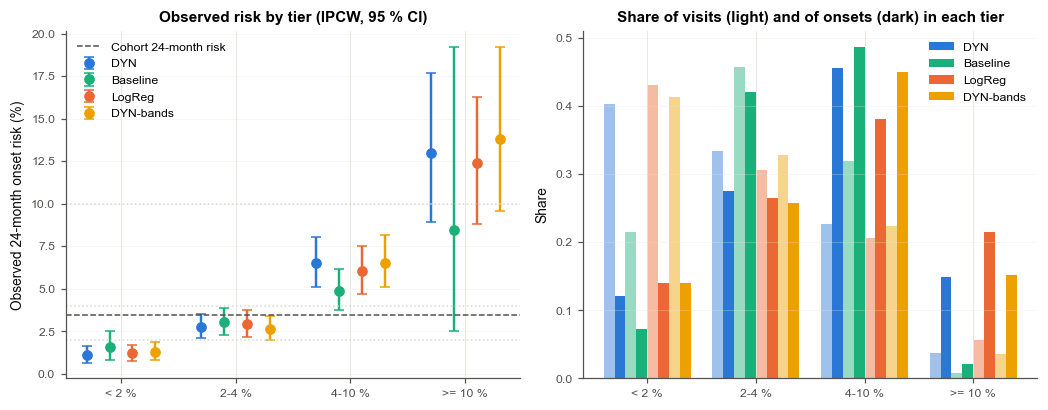

In [88]:
"""Risk tiers by visit and the rule-out tiers."""
TIER_MODELS = [m for m in KEY_MODELS + [DYN_BANDS] if m in MODELS_RUN]
TIER_NAMES = [n for _, _, n in RISK_TIERS]
print(f"Cohort {H}-month onset risk (IPCW): {100 * CIF_IPCW[H]:.1f} %")
rows = []
for m in TIER_MODELS:
    for name in TIER_NAMES:
        k = (m, "visit", H, "tier", name)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits": f"{ci(k + ('share_visits',))[0]:.1%}",
                     "Share of patients ever in tier": f"{ci(k + ('share_patients',))[0]:.1%}",
                     "Mean predicted": f"{ci(k + ('mean_pred',))[0]:.3f}",
                     "Observed (IPCW)": fmtk(k + ("observed",)), "Share of onsets": fmtk(k + ("share_onsets",))})
TIERS = pd.DataFrame(rows)
display(TIERS.set_index(["Model", "Tier"]))
TIERS.to_csv(f"objective1_risk_tiers_{TAG}.csv", index=False)

rows = []
for m in TIER_MODELS:
    for _, _, name in RULE_OUT_TIERS:
        k = (m, "visit", H, "tier", name)
        rows.append({"Model": short_label(m), "Rule-out tier": name,
                     "Visits covered": f"{ci(k + ('share_visits',))[0]:.1%}",
                     f"Observed {H}-month risk (1 - NPV)": fmtk(k + ("observed",)),
                     "Onsets missed (share of all)": fmtk(k + ("share_onsets",))})
RULE_OUT = pd.DataFrame(rows)
display(RULE_OUT.set_index(["Model", "Rule-out tier"]))
RULE_OUT.to_csv(f"objective1_rule_out_{TAG}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
xx = np.arange(len(TIER_NAMES))
wd = 0.8 / len(TIER_MODELS)
for j, m in enumerate(TIER_MODELS):
    obs = np.array([ci((m, "visit", H, "tier", n, "observed")) for n in TIER_NAMES])
    shv = [ci((m, "visit", H, "tier", n, "share_visits"))[0] for n in TIER_NAMES]
    sho = np.array([ci((m, "visit", H, "tier", n, "share_onsets")) for n in TIER_NAMES])
    off = (j - (len(TIER_MODELS) - 1) / 2) * wd
    axes[0].errorbar(xx + off, 100 * obs[:, 0], yerr=[100 * (obs[:, 0] - obs[:, 1]), 100 * (obs[:, 2] - obs[:, 0])],
                     fmt="o", color=model_color(m), capsize=3, label=short_label(m))
    axes[1].bar(xx + off - wd / 4, shv, wd / 2, color=model_color(m), alpha=0.45)
    axes[1].bar(xx + off + wd / 4, sho[:, 0], wd / 2, color=model_color(m), label=short_label(m))
for lo_, _, _ in RISK_TIERS[1:]:
    axes[0].axhline(100 * lo_, color="#d9d8d3", ls=":", lw=1)
axes[0].axhline(100 * CIF_IPCW[H], color=INK_2, ls="--", lw=1, label=f"Cohort {H}-month risk")
axes[0].set_xticks(xx); axes[0].set_xticklabels(TIER_NAMES); axes[0].set_ylabel(f"Observed {H}-month onset risk (%)")
axes[0].set_title("Observed risk by tier (IPCW, 95 % CI)"); axes[0].legend(fontsize=8); axes[0].grid(axis="y", alpha=0.3)
axes[1].set_xticks(xx); axes[1].set_xticklabels(TIER_NAMES); axes[1].set_ylabel("Share")
axes[1].set_title("Share of visits (light) and of onsets (dark) in each tier"); axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); save_fig("risk_tiers")

Onset patients (24 mo before onset) Patients still working, same dates     Likelihood ratio
Model     Tier                                                                                               
DYN       < 2 %                0.103 (0.061 to 0.148)             0.306 (0.265 to 0.350)  0.33 (0.21 to 0.47)
          2-4 %                0.249 (0.194 to 0.306)             0.375 (0.352 to 0.396)  0.67 (0.52 to 0.83)
          4-10 %               0.519 (0.455 to 0.582)             0.286 (0.253 to 0.319)  1.81 (1.58 to 2.07)
          >= 10 %              0.129 (0.089 to 0.176)             0.033 (0.023 to 0.043)  3.96 (2.65 to 5.89)
Baseline  < 2 %                0.076 (0.045 to 0.110)             0.113 (0.084 to 0.147)  0.67 (0.43 to 0.94)
          2-4 %                0.406 (0.337 to 0.475)             0.432 (0.395 to 0.471)  0.94 (0.79 to 1.09)
          4-10 %               0.492 (0.418 to 0.564)             0.444 (0.395 to 0.489)  1.11 (0.95 to 1.28)
          >= 10 %              0.025 (0.010 to 0.044)             0.010 (0.006 to 0.018)  2.42 (1.04 to 4.56)
LogReg    < 2 %                0.132 (0.086 to 0.179)             0.344 (0.301 to 0.390)  0.38 (0.26 to 0.50)
          2-4 %                0.254 (0.196 to 0.313)             0.340 (0.319 to 0.363)  0.75 (0.58 to 0.93)
          4-10 %               0.410 (0.346 to 0.476)             0.261 (0.228 to 0.295)  1.57 (1.31 to 1.86)
          >= 10 %              0.204 (0.148 to 0.266)             0.055 (0.041 to 0.069)  3.72 (2.71 to 5.04)
DYN-bands < 2 %                0.119 (0.077 to 0.163)             0.283 (0.242 to 0.329)  0.42 (0.29 to 0.55)
          2-4 %                0.272 (0.216 to 0.328)             0.387 (0.364 to 0.408)  0.70 (0.56 to 0.87)
          4-10 %               0.477 (0.411 to 0.548)             0.298 (0.262 to 0.334)  1.60 (1.38 to 1.86)
          >= 10 %              0.132 (0.091 to 0.178)             0.032 (0.022 to 0.045)  4.06 (2.78 to 6.05)

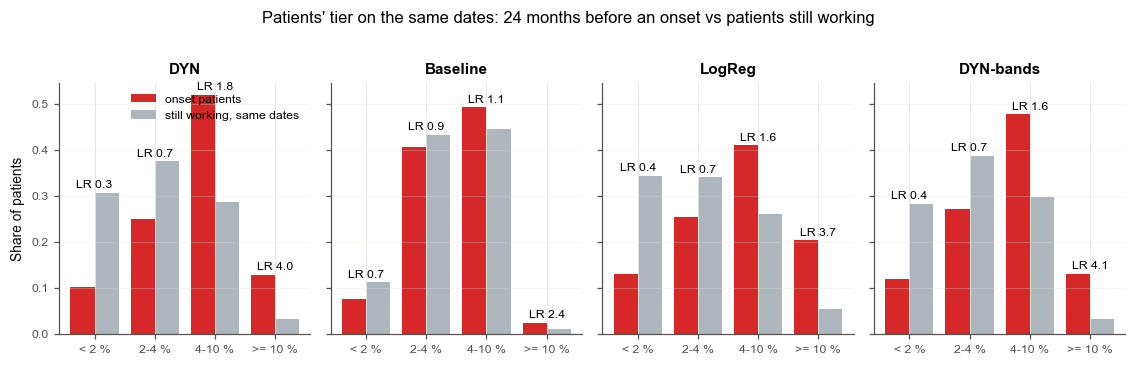

Tier at the next visit,< 2 %,2-4 %,4-10 %,>= 10 %
Tier at a visit,,,,
< 2 %,0.911,0.083,0.005,0.000
2-4 %,0.182,0.698,0.115,0.005
4-10 %,0.013,0.250,0.674,0.063
>= 10 %,0.002,0.021,0.444,0.533


DYN: the tier stays the same at 77% of consecutive visits and moves by more than one tier at 0.8%. Patients ever in the >= 10 % tier: 17%; of them, 32% have an onset (vs 11% of the others).
Recent era (landmarks from 2012 on):


Share of visits (labelled, IPCW)         Observed (IPCW)         Share of onsets
Model     Tier                                                                                      
DYN       < 2 %               0.567 (0.533 to 0.600)  0.010 (0.004 to 0.016)  0.278 (0.142 to 0.417)
          2-4 %               0.288 (0.268 to 0.309)  0.019 (0.011 to 0.028)  0.271 (0.181 to 0.371)
          4-10 %              0.132 (0.113 to 0.153)  0.053 (0.029 to 0.080)  0.349 (0.240 to 0.469)
          >= 10 %             0.013 (0.009 to 0.019)  0.160 (0.051 to 0.286)  0.103 (0.036 to 0.181)
          below 2 %           0.567 (0.533 to 0.600)  0.010 (0.004 to 0.016)  0.278 (0.142 to 0.417)
          below 4 %           0.855 (0.830 to 0.877)  0.013 (0.008 to 0.018)  0.549 (0.400 to 0.698)
Baseline  < 2 %               0.335 (0.304 to 0.366)  0.013 (0.006 to 0.021)  0.209 (0.104 to 0.337)
          2-4 %               0.573 (0.545 to 0.600)  0.021 (0.013 to 0.030)  0.591 (0.446 to 0.722)
          4-10 %              0.091 (0.072 to 0.110)  0.044 (0.019 to 0.077)  0.196 (0.091 to 0.329)
          >= 10 %             0.001 (0.000 to 0.003)  0.074 (0.053 to 1.000)  0.004 (0.000 to 0.012)
          below 2 %           0.335 (0.304 to 0.366)  0.013 (0.006 to 0.021)  0.209 (0.104 to 0.337)
          below 4 %           0.908 (0.889 to 0.927)  0.018 (0.011 to 0.024)  0.800 (0.670 to 0.905)
LogReg    < 2 %               0.589 (0.554 to 0.623)  0.011 (0.005 to 0.017)  0.326 (0.182 to 0.476)
          2-4 %               0.270 (0.247 to 0.292)  0.021 (0.013 to 0.032)  0.285 (0.197 to 0.386)
          4-10 %              0.119 (0.102 to 0.139)  0.046 (0.024 to 0.071)  0.273 (0.172 to 0.374)
          >= 10 %             0.022 (0.015 to 0.032)  0.105 (0.040 to 0.196)  0.116 (0.050 to 0.202)
          below 2 %           0.589 (0.554 to 0.623)  0.011 (0.005 to 0.017)  0.326 (0.182 to 0.476)
          below 4 %           0.858 (0.834 to 0.881)  0.014 (0.009 to 0.020)  0.611 (0.478 to 0.741)
DYN-bands < 2 %               0.618 (0.587 to 0.648)  0.011 (0.006 to 0.018)  0.353 (0.212 to 0.498)
          2-4 %               0.278 (0.258 to 0.298)  0.023 (0.013 to 0.034)  0.315 (0.211 to 0.425)
          4-10 %              0.096 (0.080 to 0.114)  0.056 (0.030 to 0.087)  0.267 (0.162 to 0.393)
          >= 10 %             0.008 (0.004 to 0.013)  0.178 (0.063 to 0.363)  0.065 (0.019 to 0.124)
          below 2 %           0.618 (0.587 to 0.648)  0.011 (0.006 to 0.018)  0.353 (0.212 to 0.498)
          below 4 %           0.896 (0.875 to 0.915)  0.015 (0.009 to 0.021)  0.668 (0.517 to 0.797)

Risk tiers (DYN): the < 2 % tier covers 40% of visits with an observed 24-month risk of 0.011 (0.007 to 0.016) and
misses 0.121 (0.075 to 0.172) of the onsets; the >= 10 % tier covers 4% of visits with an observed risk of 0.130
(0.089 to 0.177) and holds 0.149 (0.104 to 0.197) of the onsets. On the same dates, onset patients are in the >= 10 %
tier 13% of the time vs 3% of patients still working (LR 4.0); in the < 2 % tier 10% vs 31% (LR 0.33).


In [89]:
"""Risk tiers by patient on the same dates (time-matched), tier movement and the recent era."""


def tm_tiers(m):
    """Per tier: share of onset patients and of time-matched controls (each onset's controls weighted equally), and
    the likelihood ratio; repeat means of the bootstrap arrays (point = first entry)."""
    d = TM["main"]
    Wc = _BOTH[:, d["case_pid"]]
    acc = {n: [] for n in TIER_NAMES}
    for r in REPEATS:
        p_ = _expit(np.asarray(d["mat"] @ np.nan_to_num(zpred(m, r))).ravel())
        for lo, hi, n in RISK_TIERS:
            inn = (p_ >= lo) & (p_ < hi)
            case = (Wc @ inn[d["cases"]].astype(np.float32)) / Wc.sum(1)
            Kc = sparse.coo_matrix((d["w"] * inn[d["pk"]], (d["ppc"], d["ppk"])), shape=(P_, P_)).toarray()
            ctrl = _pair_sum_fast(_BOTH, Kc) / d["wden"]
            acc[n].append((case, ctrl))
    out = {}
    for n in TIER_NAMES:
        case = np.mean([a for a, _ in acc[n]], 0); ctrl = np.mean([b for _, b in acc[n]], 0)
        lr = case / np.where(ctrl > 0, ctrl, np.nan)
        out[n] = {k_: (v[0], np.nanpercentile(v[1:], 2.5), np.nanpercentile(v[1:], 97.5))
                  for k_, v in [("case", case), ("ctrl", ctrl), ("lr", lr)]}
    return out


TM_TIERS = {m: tm_tiers(m) for m in TIER_MODELS}
rows = [{"Model": short_label(m), "Tier": n, f"Onset patients ({H} mo before onset)": fmt(*v["case"]),
         "Patients still working, same dates": fmt(*v["ctrl"]), "Likelihood ratio": fmt(*v["lr"], nd=2)}
        for m, t_ in TM_TIERS.items() for n, v in t_.items()]
TM_TIER_TABLE = pd.DataFrame(rows)
display(TM_TIER_TABLE.set_index(["Model", "Tier"]))
TM_TIER_TABLE.to_csv(f"objective1_tiers_time_matched_{TAG}.csv", index=False)

fig, axes = plt.subplots(1, len(TIER_MODELS), figsize=(2.6 * len(TIER_MODELS), 3.2), sharey=True)
for ax, m in zip(np.atleast_1d(axes), TIER_MODELS):
    t_ = TM_TIERS[m]
    ax.bar(xx - 0.2, [t_[n]["case"][0] for n in TIER_NAMES], 0.4, color="#d62828", label="onset patients")
    ax.bar(xx + 0.2, [t_[n]["ctrl"][0] for n in TIER_NAMES], 0.4, color="#adb5bd", label="still working, same dates")
    for x_, n in zip(xx, TIER_NAMES):
        ax.text(x_, max(t_[n]["case"][0], t_[n]["ctrl"][0]) + 0.01, f"LR {t_[n]['lr'][0]:.1f}", ha="center", fontsize=8)
    ax.set_xticks(xx); ax.set_xticklabels(TIER_NAMES); ax.set_title(short_label(m)); ax.grid(axis="y", alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("Share of patients"); np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle(f"Patients' tier on the same dates: {H} months before an onset vs patients still working", y=1.02)
plt.tight_layout(); save_fig("risk_tiers_time_matched")

# tier movement between consecutive visits (main model, mean over repeats)
_tier_of = lambda p_: np.digitize(p_, [lo for lo, _, _ in RISK_TIERS[1:]])
_tz = _tier_of(_expit(mean_z(MAIN_MODEL)))
_a, _b = [], []
for pid, li in PT_ROWS.items():
    if len(li) > 1:
        _a.append(_tz[li[:-1]]); _b.append(_tz[li[1:]])
_a, _b = np.concatenate(_a), np.concatenate(_b)
MOVE = pd.crosstab(pd.Categorical(np.array(TIER_NAMES)[_a], TIER_NAMES), pd.Categorical(np.array(TIER_NAMES)[_b], TIER_NAMES),
                   normalize="index", rownames=["Tier at a visit"], colnames=["Tier at the next visit"])
display(MOVE.round(3))
MOVE.to_csv(f"objective1_tier_movement_{TAG}.csv")
_ever_hi = pd.Series(_tz == 3).groupby(PID_ALL).max()
_ev_pt = pd.Series(land["pt_event"].values).groupby(PID_ALL).max()
print(f"{short_label(MAIN_MODEL)}: the tier stays the same at {np.mean(_a == _b):.0%} of consecutive visits and moves "
      f"by more than one tier at {np.mean(np.abs(_a - _b) > 1):.1%}. Patients ever in the {TIER_HIGH} tier: "
      f"{_ever_hi.mean():.0%}; of them, {_ev_pt[_ever_hi].mean():.0%} have an onset (vs "
      f"{_ev_pt[~_ever_hi].mean():.0%} of the others).")

rows = []
for m in TIER_MODELS:
    for _, _, name in RISK_TIERS + RULE_OUT_TIERS:
        k = (m, "visit", H, "tier_recent", name)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits (labelled, IPCW)": fmtk(k + ("share_visits",)),
                     "Observed (IPCW)": fmtk(k + ("observed",)), "Share of onsets": fmtk(k + ("share_onsets",))})
TIERS_RECENT = pd.DataFrame(rows)
print(f"Recent era (landmarks from {TIER_RECENT_FROM} on):")
display(TIERS_RECENT.set_index(["Model", "Tier"]))
TIERS_RECENT.to_csv(f"objective1_risk_tiers_recent_{TAG}.csv", index=False)
_T = lambda k_: ci((MAIN_MODEL, "visit", H, "tier") + k_)
_lo, _lo_m = _T((RULE_OUT_MAIN, "observed")), _T((RULE_OUT_MAIN, "share_onsets"))
_hi, _hi_o = _T((TIER_HIGH, "observed")), _T((TIER_HIGH, "share_onsets"))
_tmt = TM_TIERS[MAIN_MODEL]
TIER_SUMMARY = (f"Risk tiers ({short_label(MAIN_MODEL)}): the {TIER_LOW} tier covers "
                f"{_T((RULE_OUT_MAIN, 'share_visits'))[0]:.0%} of visits with an observed {H}-month risk of "
                f"{fmt(*_lo)} and misses {fmt(*_lo_m)} of the onsets; the {TIER_HIGH} tier covers "
                f"{_T((TIER_HIGH, 'share_visits'))[0]:.0%} of visits with an observed risk of {fmt(*_hi)} and holds "
                f"{fmt(*_hi_o)} of the onsets. On the same dates, onset patients are in the {TIER_HIGH} tier "
                f"{_tmt[TIER_HIGH]['case'][0]:.0%} of the time vs {_tmt[TIER_HIGH]['ctrl'][0]:.0%} of patients still "
                f"working (LR {_tmt[TIER_HIGH]['lr'][0]:.1f}); in the {TIER_LOW} tier {_tmt[TIER_LOW]['case'][0]:.0%} vs "
                f"{_tmt[TIER_LOW]['ctrl'][0]:.0%} (LR {_tmt[TIER_LOW]['lr'][0]:.2f}).")
print(textwrap.fill(TIER_SUMMARY, 118))

## 13.6 Calibration and discrimination by calendar era

Visit AUROC, patient AUROC and visit O/E within each calendar era (landmark year; for patients, the year of the
window's last landmark). The pooled AUROC also reflects differences between eras (pre-2000 onset risk was higher);
the within-era values are the ones a clinic would see today.

In [90]:
"""Discrimination and calibration by era."""
rows = []
for m in MODELS_RUN:
    row = {"Model": short_label(m)}
    for _, _, e in ERA_BANDS:
        row[f"Visit AUROC {e}"] = fmtk((m, "visit", H, "sub", f"Era: {e}", "auroc"))
    for _, _, e in ERA_BANDS:
        row[f"Patient AUROC {e}"] = fmtk((m, "patient", H, "sub", f"Era: {e}", "auroc"))
    for _, _, e in ERA_BANDS:
        row[f"Visit O/E {e}"] = f"{ci((m, 'visit', H, 'sub', f'Era: {e}', 'oe'))[0]:.2f}"
    rows.append(row)
ERA_TABLE = pd.DataFrame(rows).set_index("Model")
_era = ERA_TABLE.columns.str.startswith("Visit AUROC") | ERA_TABLE.columns.str.startswith("Patient AUROC")
display(ERA_TABLE.loc[:, _era]); display(ERA_TABLE.loc[:, ~_era])
ERA_TABLE.to_csv(f"objective1_by_era_{TAG}.csv")
_ey = LAND_SUB["era"].values
print(f"Landmarks with a known {H}-month status / onsets by era: " + ", ".join(
    f"{e} {int((_ey[ROWS_IPCW] == e).sum()):,} / {int(Y_IPCW[_ey[ROWS_IPCW] == e].sum())}" for _, _, e in ERA_BANDS))

,Visit AUROC < 2000,Visit AUROC 2000-05,Visit AUROC 2006-11,Visit AUROC >= 2012,Patient AUROC < 2000,Patient AUROC 2000-05,Patient AUROC 2006-11,Patient AUROC >= 2012
Model,,,,,,,,
S0 pooled,0.811 (0.742 to 0.874),0.632 (0.546 to 0.725),0.648 (0.561 to 0.732),0.693 (0.577 to 0.799),0.751 (0.630 to 0.856),0.697 (0.589 to 0.790),0.636 (0.529 to 0.745),0.782 (0.697 to 0.861)
S1 no-pool,0.788 (0.724 to 0.851),0.658 (0.577 to 0.740),0.652 (0.563 to 0.744),0.715 (0.609 to 0.816),0.745 (0.625 to 0.849),0.711 (0.604 to 0.802),0.636 (0.528 to 0.747),0.808 (0.730 to 0.885)
S2 bands,0.805 (0.740 to 0.860),0.649 (0.567 to 0.733),0.659 (0.577 to 0.740),0.700 (0.598 to 0.799),0.738 (0.607 to 0.847),0.715 (0.610 to 0.807),0.613 (0.506 to 0.716),0.783 (0.701 to 0.859)
DYN-bands,0.813 (0.747 to 0.865),0.643 (0.567 to 0.720),0.678 (0.595 to 0.764),0.683 (0.579 to 0.782),0.767 (0.650 to 0.869),0.709 (0.602 to 0.798),0.626 (0.517 to 0.730),0.769 (0.688 to 0.845)
DYN,0.798 (0.742 to 0.853),0.650 (0.572 to 0.726),0.674 (0.592 to 0.755),0.710 (0.610 to 0.805),0.768 (0.654 to 0.869),0.713 (0.606 to 0.798),0.661 (0.554 to 0.764),0.799 (0.721 to 0.871)
Two-part,0.736 (0.656 to 0.814),0.629 (0.546 to 0.714),0.639 (0.547 to 0.738),0.675 (0.581 to 0.761),0.656 (0.513 to 0.775),0.707 (0.597 to 0.797),0.666 (0.557 to 0.771),0.785 (0.711 to 0.858)
Reg-DYN,0.808 (0.743 to 0.863),0.657 (0.578 to 0.737),0.675 (0.597 to 0.752),0.681 (0.585 to 0.775),0.748 (0.624 to 0.855),0.722 (0.612 to 0.811),0.632 (0.522 to 0.740),0.767 (0.682 to 0.849)
LogReg,0.805 (0.743 to 0.860),0.657 (0.580 to 0.732),0.693 (0.613 to 0.764),0.673 (0.571 to 0.770),0.733 (0.610 to 0.839),0.719 (0.611 to 0.808),0.652 (0.540 to 0.760),0.762 (0.677 to 0.840)
Reg-pooled,0.807 (0.744 to 0.871),0.654 (0.570 to 0.741),0.641 (0.555 to 0.719),0.690 (0.582 to 0.793),0.741 (0.621 to 0.848),0.708 (0.598 to 0.801),0.627 (0.519 to 0.732),0.766 (0.677 to 0.847)


,Visit O/E < 2000,Visit O/E 2000-05,Visit O/E 2006-11,Visit O/E >= 2012
Model,,,,
S0 pooled,0.97,1.01,1.13,0.80
S1 no-pool,0.96,1.01,1.17,0.82
S2 bands,0.91,0.95,1.16,0.96
DYN-bands,0.95,0.97,1.18,0.93
DYN,0.99,1.02,1.16,0.82
Two-part,0.96,1.06,1.13,0.86
Reg-DYN,0.87,0.99,1.19,0.80
LogReg,0.87,0.95,1.17,0.80
Reg-pooled,1.00,1.02,1.19,0.72


Landmarks with a known 24-month status / onsets by era: < 2000 1,967 / 106, 2000-05 2,698 / 144, 2006-11 3,989 / 173, >= 2012 6,525 / 141


## 13.7 Performance by subgroup (sex, race, age, calendar era)

Visit and patient AUROC of the main model, the Baseline and LogReg within each subgroup (95 % CI).

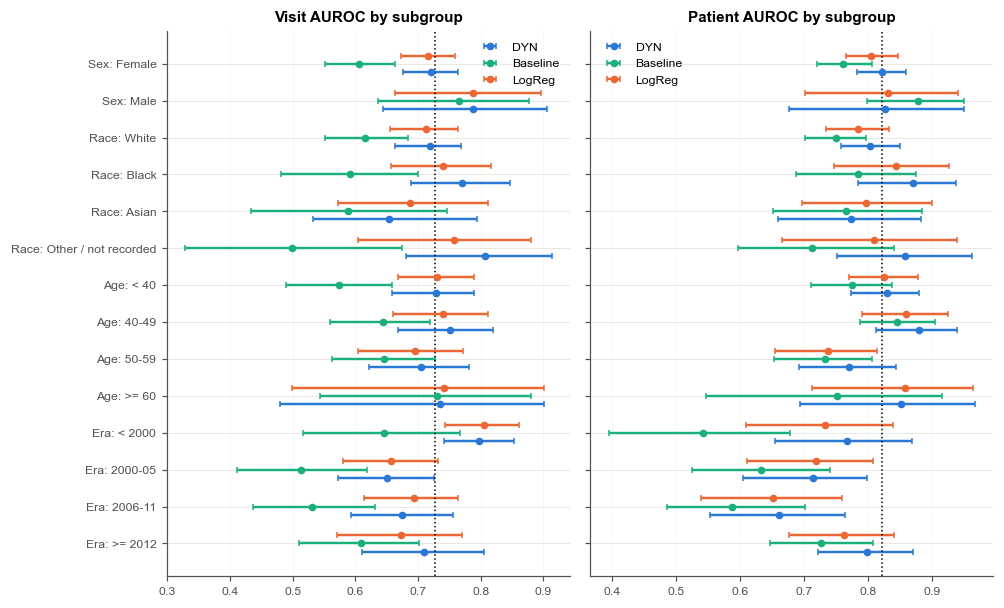

,DYN visit,DYN patient,Baseline visit,Baseline patient,LogReg visit,LogReg patient
Subgroup,,,,,,
Sex: Female,0.721 (0.676 to 0.763),0.822 (0.783 to 0.860),0.606 (0.551 to 0.663),0.762 (0.721 to 0.807),0.716 (0.672 to 0.758),0.806 (0.766 to 0.847)
Sex: Male,0.787 (0.644 to 0.906),0.827 (0.677 to 0.949),0.765 (0.635 to 0.877),0.879 (0.799 to 0.949),0.787 (0.663 to 0.897),0.831 (0.701 to 0.941)
Race: White,0.719 (0.663 to 0.769),0.803 (0.758 to 0.850),0.615 (0.551 to 0.683),0.751 (0.702 to 0.797),0.712 (0.656 to 0.764),0.784 (0.735 to 0.833)
Race: Black,0.771 (0.689 to 0.846),0.870 (0.784 to 0.938),0.591 (0.482 to 0.700),0.784 (0.687 to 0.875),0.740 (0.656 to 0.817),0.844 (0.746 to 0.927)
Race: Asian,0.654 (0.532 to 0.793),0.774 (0.660 to 0.883),0.589 (0.433 to 0.746),0.765 (0.651 to 0.885),0.686 (0.573 to 0.812),0.798 (0.697 to 0.900)
Race: Other / not recorded,0.807 (0.681 to 0.913),0.858 (0.751 to 0.963),0.498 (0.329 to 0.674),0.713 (0.597 to 0.841),0.757 (0.604 to 0.880),0.810 (0.665 to 0.940)
Age: < 40,0.729 (0.659 to 0.790),0.830 (0.773 to 0.880),0.573 (0.490 to 0.658),0.776 (0.711 to 0.838),0.730 (0.667 to 0.788),0.825 (0.770 to 0.878)
Age: 40-49,0.750 (0.668 to 0.820),0.879 (0.812 to 0.939),0.644 (0.559 to 0.719),0.846 (0.787 to 0.904),0.739 (0.660 to 0.812),0.860 (0.790 to 0.925)
Age: 50-59,0.705 (0.621 to 0.781),0.771 (0.693 to 0.843),0.645 (0.563 to 0.727),0.733 (0.653 to 0.806),0.696 (0.605 to 0.772),0.738 (0.655 to 0.814)


In [91]:
"""Subgroup AUROC forest."""
_sub_names = [n for n in SUBGROUPS if n.split(":")[0] in ("Sex", "Race", "Age", "Era")]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 0.3 * len(_sub_names) + 1.4), sharey=True)
yy = np.arange(len(_sub_names))[::-1]
for ax, lev in zip(axes, ["visit", "patient"]):
    for j, m in enumerate(KEY_MODELS):
        if m not in MODELS_RUN:
            continue
        for y_, n in zip(yy, _sub_names):
            a = ci((m, lev, H, "sub", n, "auroc"))
            if np.isnan(a[0]):
                continue
            ax.errorbar(a[0], y_ + (j - 1) * 0.22, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", ms=4,
                        color=model_color(m), capsize=2, label=short_label(m) if y_ == yy[0] else None)
    ax.axvline(ci((MAIN_MODEL,) + (K_VIS if lev == "visit" else K_PT))[0], color="k", ls=":", lw=1)
    ax.set_yticks(yy); ax.set_yticklabels(_sub_names, fontsize=8); ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"{lev.capitalize()} AUROC by subgroup"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("subgroups")
SUB_TABLE = pd.DataFrame([{"Subgroup": n, **{f"{short_label(m)} {lev}": fmtk((m, lev, H, "sub", n, "auroc"))
                                             for m in KEY_MODELS if m in MODELS_RUN
                                             for lev in ["visit", "patient"]}} for n in _sub_names]).set_index("Subgroup")
display(SUB_TABLE)
SUB_TABLE.to_csv(f"objective1_subgroups_{TAG}.csv")

## 13.8 Patient windows — all models

Every patient-level metric (24 months, 24-month windows; Section 9), both threshold rules and both patient rules.

In [92]:
"""Patient-level table of every model."""
rows = []
for m in MODELS_RUN:
    for c in THRESHOLD_RULES:
        rows.append({"Model": short_label(m), "Rule": PATIENT_RULE_LABELS["meanlogit"], "Threshold": THRESHOLD_LABELS[c],
                     "AUROC": fmtk((m, "patient", H, "auroc")),
                     **{METRIC_LABELS[x]: fmtk((m, "patient", H, c, x)) for x in CONF_METRICS}})
    rows.append({"Model": short_label(m), "Rule": PATIENT_RULE_LABELS["run2"], "Threshold": THRESHOLD_LABELS["cost"],
                 "AUROC": fmtk((m, "patient", H, "run2", "auroc")),
                 **{METRIC_LABELS[x]: fmtk((m, "patient", H, "run2", x)) for x in CONF_METRICS}})
PATIENT_TABLE = pd.DataFrame(rows)
display(PATIENT_TABLE)
PATIENT_TABLE.to_csv(f"objective1_patient_level_{TAG}.csv", index=False)
rows = []
for m in MODELS_RUN:
    for c in THRESHOLD_RULES:
        rows.append({"Model": short_label(m), "Threshold": THRESHOLD_LABELS[c],
                     f"Threshold ({H}-month risk)": f"{100 * ci((m, 'visit', H, c, 'threshold'))[0]:.1f} %",
                     **{METRIC_LABELS[x]: fmtk((m, "visit", H, c, x)) for x in CONF_METRICS}})
VISIT_TABLE = pd.DataFrame(rows)
print("Visit level (IPCW), both threshold rules:")
display(VISIT_TABLE)
VISIT_TABLE.to_csv(f"objective1_visit_level_{TAG}.csv", index=False)

,Model,Rule,Threshold,AUROC,Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,S0 pooled,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.807 (0.767 to 0.845),0.729 (0.663 to 0.796),0.738 (0.706 to 0.766),0.330 (0.278 to 0.382),0.939 (0.921 to 0.957),0.733 (0.697 to 0.772),0.333 (0.306 to 0.361)
1,S0 pooled,mean logit over the window,Max PPV (sensitivity >= 25%),0.807 (0.767 to 0.845),0.299 (0.227 to 0.373),0.951 (0.937 to 0.963),0.522 (0.418 to 0.621),0.885 (0.863 to 0.907),0.625 (0.590 to 0.663),0.086 (0.071 to 0.104)
2,S0 pooled,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.803 (0.761 to 0.840),0.716 (0.648 to 0.784),0.748 (0.720 to 0.776),0.335 (0.281 to 0.390),0.937 (0.919 to 0.955),0.732 (0.695 to 0.770),0.322 (0.295 to 0.351)
3,S1 no-pool,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.819 (0.782 to 0.857),0.753 (0.688 to 0.819),0.749 (0.720 to 0.777),0.349 (0.295 to 0.404),0.945 (0.929 to 0.961),0.751 (0.715 to 0.786),0.326 (0.299 to 0.355)
4,S1 no-pool,mean logit over the window,Max PPV (sensitivity >= 25%),0.819 (0.782 to 0.857),0.284 (0.216 to 0.352),0.957 (0.942 to 0.969),0.536 (0.431 to 0.640),0.883 (0.862 to 0.904),0.620 (0.588 to 0.655),0.080 (0.064 to 0.096)
5,S1 no-pool,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.813 (0.775 to 0.851),0.746 (0.678 to 0.816),0.739 (0.711 to 0.767),0.337 (0.286 to 0.388),0.943 (0.925 to 0.960),0.742 (0.705 to 0.778),0.334 (0.306 to 0.362)
6,S2 bands,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.816 (0.777 to 0.853),0.732 (0.667 to 0.801),0.751 (0.722 to 0.779),0.343 (0.290 to 0.395),0.941 (0.923 to 0.958),0.742 (0.706 to 0.778),0.322 (0.294 to 0.350)
7,S2 bands,mean logit over the window,Max PPV (sensitivity >= 25%),0.816 (0.777 to 0.853),0.299 (0.227 to 0.372),0.963 (0.949 to 0.974),0.587 (0.477 to 0.695),0.886 (0.864 to 0.907),0.631 (0.596 to 0.668),0.077 (0.062 to 0.094)
8,S2 bands,2 consecutive alarms,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.812 (0.772 to 0.849),0.690 (0.622 to 0.760),0.771 (0.745 to 0.796),0.349 (0.295 to 0.405),0.934 (0.916 to 0.952),0.730 (0.692 to 0.765),0.299 (0.274 to 0.325)
9,DYN-bands,mean logit over the window,"Max Youden (cost-weighted, R = (1 - pi) / pi)",0.816 (0.778 to 0.853),0.706 (0.639 to 0.773),0.758 (0.731 to 0.784),0.342 (0.288 to 0.396),0.936 (0.918 to 0.953),0.732 (0.693 to 0.768),0.312 (0.286 to 0.339)


Visit level (IPCW), both threshold rules:


,Model,Threshold,Threshold (24-month risk),Sensitivity,Specificity,PPV,NPV,Balanced accuracy,Share flagged
0,S0 pooled,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.9 %,0.631 (0.557 to 0.710),0.693 (0.665 to 0.721),0.069 (0.055 to 0.085),0.981 (0.976 to 0.986),0.662 (0.624 to 0.701),0.318 (0.291 to 0.347)
1,S0 pooled,Max PPV (sensitivity >= 25%),7.8 %,0.284 (0.209 to 0.361),0.917 (0.900 to 0.934),0.111 (0.077 to 0.147),0.973 (0.966 to 0.978),0.601 (0.562 to 0.637),0.089 (0.073 to 0.108)
2,S1 no-pool,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.7 %,0.670 (0.598 to 0.742),0.676 (0.648 to 0.703),0.069 (0.055 to 0.084),0.983 (0.978 to 0.987),0.673 (0.637 to 0.710),0.336 (0.309 to 0.364)
3,S1 no-pool,Max PPV (sensitivity >= 25%),8.3 %,0.259 (0.197 to 0.329),0.931 (0.917 to 0.944),0.119 (0.086 to 0.154),0.972 (0.966 to 0.978),0.595 (0.565 to 0.628),0.075 (0.062 to 0.090)
4,S2 bands,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.6 %,0.653 (0.581 to 0.725),0.674 (0.647 to 0.703),0.068 (0.054 to 0.083),0.982 (0.977 to 0.986),0.664 (0.628 to 0.700),0.337 (0.309 to 0.365)
5,S2 bands,Max PPV (sensitivity >= 25%),8.3 %,0.297 (0.230 to 0.371),0.923 (0.905 to 0.938),0.122 (0.088 to 0.161),0.973 (0.967 to 0.978),0.610 (0.576 to 0.646),0.085 (0.069 to 0.102)
6,DYN-bands,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.5 %,0.662 (0.591 to 0.731),0.673 (0.647 to 0.699),0.068 (0.055 to 0.083),0.982 (0.977 to 0.987),0.667 (0.632 to 0.704),0.339 (0.313 to 0.364)
7,DYN-bands,Max PPV (sensitivity >= 25%),7.8 %,0.279 (0.217 to 0.349),0.930 (0.914 to 0.944),0.126 (0.092 to 0.164),0.973 (0.967 to 0.978),0.605 (0.573 to 0.639),0.077 (0.063 to 0.092)
8,DYN,"Max Youden (cost-weighted, R = (1 - pi) / pi)",3.7 %,0.649 (0.582 to 0.717),0.688 (0.663 to 0.713),0.070 (0.056 to 0.084),0.982 (0.977 to 0.987),0.669 (0.634 to 0.705),0.323 (0.298 to 0.349)
9,DYN,Max PPV (sensitivity >= 25%),7.9 %,0.261 (0.207 to 0.319),0.929 (0.916 to 0.941),0.117 (0.087 to 0.148),0.972 (0.966 to 0.977),0.595 (0.568 to 0.625),0.078 (0.066 to 0.091)


## 13.9 Conclusion — Objective 1

In [93]:
"""Objective 1 conclusion."""
_m = MAIN_MODEL
_h1 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H1")]
txt = (f"Main model ({model_label(_m)}): time-matched patient AUROC {fmtk((_m,) + K_TM)} (Baseline "
       f"{fmtk((BASELINE,) + K_TM)}, LogReg {fmtk((LOGREG,) + K_TM)}). It flags "
       f"{ci((_m, 'tm', 'main', 'sensitivity'))[0]:.0%} of patients in the {H} months before their onset and "
       f"{1 - ci((_m, 'tm', 'main', 'specificity'))[0]:.0%} of the patients still working on the same dates. Visit AUROC "
       f"({H} months) {fmtk((_m,) + K_VIS)}; calibration slope {ci((_m, 'visit', H, 'cal_slope'))[0]:.2f}, O/E "
       f"{ci((_m, 'visit', H, 'oe'))[0]:.2f}. Hypotheses: " + "; ".join(
           f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {r_.get('Verdict') or ('met' if r_['Met'] else 'not met')}"
           for r_ in _h1) + ". " + TIER_SUMMARY)
OBJ_CONCLUSIONS["Objective 1"] = txt
print(textwrap.fill(txt, 118))

Main model (DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [main]): time-matched
patient AUROC 0.735 (0.697 to 0.775) (Baseline 0.580 (0.529 to 0.633), LogReg 0.724 (0.684 to 0.764)). It flags 65% of
patients in the 24 months before their onset and 32% of the patients still working on the same dates. Visit AUROC (24
months) 0.727 (0.684 to 0.767); calibration slope 1.05, O/E 1.03. Hypotheses: H1a (primary) (DYN - Baseline, time-
matched patient AUROC) 0.155 (0.106 to 0.206): superior; H1b (DYN - LogReg, time-matched patient AUROC) 0.011 (-0.007
to 0.031): inconclusive; H1d (DYN - DYN-bands, time-matched patient AUROC) 0.025 (0.008 to 0.042): superior; H1c
(Main: visit calibration slope / intercept) 1.051 (0.868 to 1.261) / -0.011 (-0.195 to 0.170): met. Risk tiers (DYN):
the < 2 % tier covers 40% of visits with an observed 24-month risk of 0.011 (0.007 to 0.016) and misses 0.121 (0.075
to 0.172) of the onsets; the >= 10 % tier covers 4% of visits wi

---
# 14. Objective 2 — The risk is higher the closer a patient is to reporting work disability

## 14.1 Discrimination by time before the onset

The time-matched patient AUROC (Section 11.8) with the case window moved back from the onset: the patients'
scores 0-6, 6-12, 12-24, 24-36 and 36-48 months before their onset against everyone still working on the onset
date, scored over the same calendar window. If the risk rises as the onset approaches, the AUROC falls with the
distance from the onset. **H2a**: the main model's AUROC in the 24 months before the onset minus its AUROC 24-36
months before it; lower 95 % bound > 0. Also: does the main model's advantage over the Baseline and LogReg grow
near the onset?

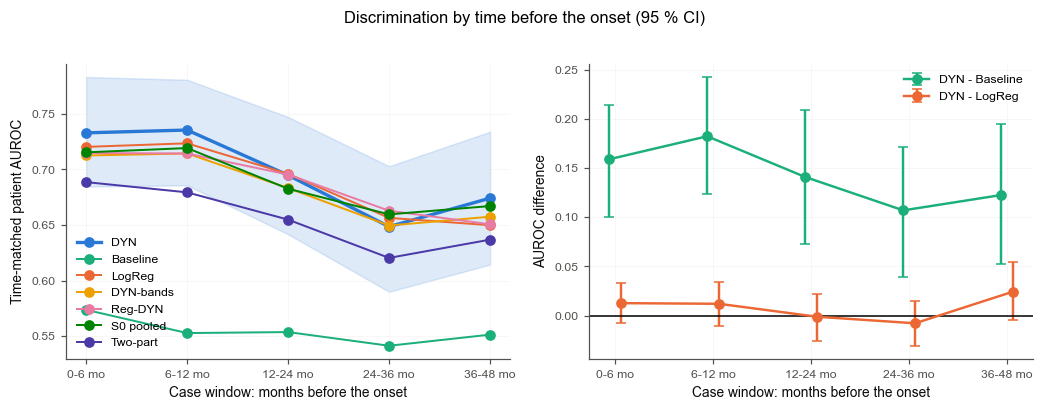

,0-6 mo before,6-12 mo before,12-24 mo before,24-36 mo before,36-48 mo before,0-24 mo (main window)
Model,,,,,,
DYN,0.733 (0.685 to 0.783),0.735 (0.686 to 0.781),0.695 (0.642 to 0.747),0.649 (0.590 to 0.703),0.674 (0.614 to 0.734),0.735 (0.697 to 0.775)
Baseline,0.574 (0.513 to 0.634),0.553 (0.496 to 0.614),0.554 (0.489 to 0.618),0.541 (0.474 to 0.615),0.551 (0.481 to 0.624),0.580 (0.529 to 0.633)
LogReg,0.720 (0.668 to 0.772),0.724 (0.675 to 0.771),0.696 (0.645 to 0.743),0.656 (0.596 to 0.715),0.650 (0.582 to 0.711),0.724 (0.684 to 0.764)
DYN-bands,0.713 (0.662 to 0.764),0.714 (0.667 to 0.765),0.683 (0.632 to 0.735),0.650 (0.588 to 0.708),0.658 (0.595 to 0.717),0.710 (0.671 to 0.752)
Reg-DYN,0.715 (0.663 to 0.769),0.714 (0.664 to 0.763),0.695 (0.645 to 0.744),0.663 (0.603 to 0.720),0.651 (0.584 to 0.713),0.720 (0.679 to 0.764)
S0 pooled,0.715 (0.667 to 0.767),0.719 (0.671 to 0.767),0.683 (0.630 to 0.731),0.660 (0.597 to 0.720),0.667 (0.607 to 0.726),0.711 (0.670 to 0.754)
Two-part,0.689 (0.638 to 0.742),0.679 (0.628 to 0.730),0.655 (0.602 to 0.708),0.620 (0.559 to 0.683),0.637 (0.567 to 0.701),0.688 (0.646 to 0.733)


,AUROC 0-24 mo before minus 24-36 mo before,Met (lower bound > 0)
Model,,
DYN,0.087 (0.041 to 0.134),True
Baseline,0.039 (-0.004 to 0.085),False
LogReg,0.067 (0.016 to 0.117),True
DYN-bands,0.060 (0.009 to 0.109),True
Reg-DYN,0.057 (0.006 to 0.105),True
S0 pooled,0.051 (0.007 to 0.094),True
Two-part,0.067 (0.018 to 0.116),True


Onsets / pairs per window: main: 158 / 44,009, 0-6: 115 / 32,231, 6-12: 111 / 29,349, 12-24: 104 / 26,797, 24-36: 86 / 19,426, 36-48: 77 / 16,520


In [94]:
"""Time-matched AUROC by time before the onset; H2a."""
_tto = [k for k in TM_WINDOWS if k != "main"]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
rows = []
for m in [m for m in FIG_MODELS if m in MODELS_RUN]:
    v = np.array([ci((m, "tm", k, "auroc")) for k in _tto])
    axes[0].plot(range(len(_tto)), v[:, 0], "o-", color=model_color(m), lw=2.2 if m == MAIN_MODEL else 1.3,
                 label=short_label(m))
    if m == MAIN_MODEL:
        axes[0].fill_between(range(len(_tto)), v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    rows.append({"Model": short_label(m), **{f"{k} mo before": fmt(*v_) for k, v_ in zip(_tto, v)},
                 f"0-{H} mo (main window)": fmtk((m,) + K_TM)})
for j, b_ in enumerate([BASELINE, LOGREG]):
    d = np.array([diff(MAIN_MODEL, b_, ("tm", k, "auroc"))[:3] for k in _tto])
    xs = np.arange(len(_tto)) + (j - 0.5) * 0.12
    axes[1].errorbar(xs, d[:, 0], yerr=[d[:, 0] - d[:, 1], d[:, 2] - d[:, 0]], fmt="o-", capsize=3,
                     color=model_color(b_), label=f"DYN - {short_label(b_)}")
for ax in axes:
    ax.set_xticks(range(len(_tto))); ax.set_xticklabels([f"{k} mo" for k in _tto])
    ax.set_xlabel("Case window: months before the onset"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("Time-matched patient AUROC"); axes[1].axhline(0, color="k", lw=1)
axes[1].set_ylabel("AUROC difference")
fig.suptitle("Discrimination by time before the onset (95 % CI)", y=1.02)
plt.tight_layout(); save_fig("by_time_to_onset")
TTO_TABLE = pd.DataFrame(rows).set_index("Model")
display(TTO_TABLE)
TTO_TABLE.to_csv(f"objective2_by_time_to_onset_{TAG}.csv")
_near, _far = ("tm", "main", "auroc"), ("tm", f"{H2A_FAR[0]}-{H2A_FAR[1]}", "auroc")
rows = []
for m in [m for m in FIG_MODELS if m in MODELS_RUN]:
    d = _diff_summary(STATS[(m,) + _near][0] - STATS[(m,) + _far][0], STATS[(m,) + _near][1] - STATS[(m,) + _far][1])
    rows.append({"Model": short_label(m), f"AUROC 0-{H} mo before minus {H2A_FAR[0]}-{H2A_FAR[1]} mo before": fmt(*d[:3]),
                 "Met (lower bound > 0)": d[1] > 0})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H2a", "Estimand": f"Main: time-matched AUROC 0-{H} minus {H2A_FAR[0]}-{H2A_FAR[1]} months before onset",
                         "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0", "Met": d[1] > 0})
display(pd.DataFrame(rows).set_index("Model"))
print("Onsets / pairs per window: " + ", ".join(f"{k}: {TM[k]['n_onsets']} / {len(TM[k]['pc']):,}" for k in TM))

## 14.2 Does each patient's risk rise as the onset approaches?

Each model's 24-month logit is **centred on the calendar year** (minus the mean logit of every landmark in the same
year), so the downward calendar trend in the risk does not look like a fall within patients. Then:

* **Onset-aligned trajectories**: the centred logit of patients with an onset by 6-month bins before the onset,
  against patients who never have an onset, aligned at their last landmark (mean and 95 % CI over patients).
* **H2b**: a linear mixed model of the centred logit on time (years, −4 to 0 before the anchor) with a random
  intercept per patient, onset patients and never-onset patients together: the **interaction** (how much faster the
  risk rises in onset patients than in never-onset patients over the same 4 years) > 0 for the main model (lower
  95 % bound > 0). Slopes reported for every key model.
* **Within-patient C** (centred): the same onset patient's landmarks ≤ 12 months before the onset scored against
  those > 24 months before (0.5 = no rise).

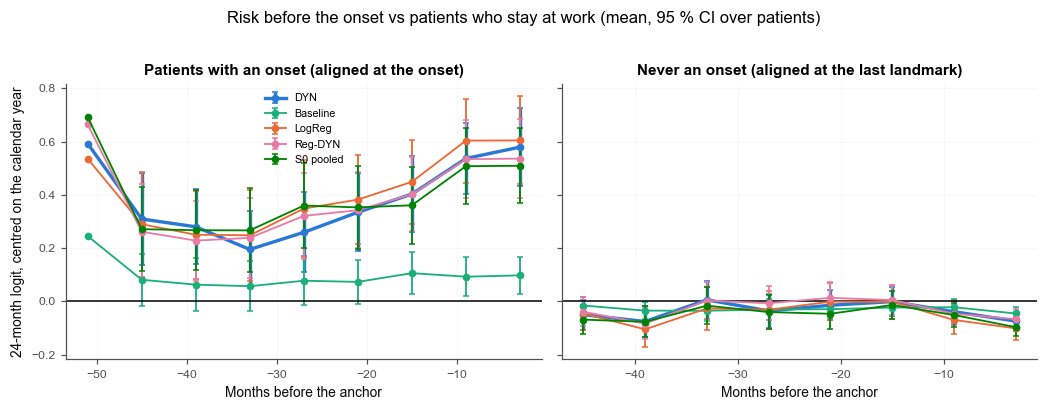

,"Slope per year, never-onset","Extra slope per year, onset patients (interaction)","Slope per year, onset patients",Level difference at the anchor (onset - never)
Model,,,,
DYN,-0.027 (-0.034 to -0.020),0.089 (0.066 to 0.111),0.062,0.623
Baseline,-0.001 (-0.001 to -0.000),-0.003 (-0.005 to -0.001),-0.004,0.144
LogReg,-0.019 (-0.028 to -0.010),0.085 (0.057 to 0.112),0.066,0.692
Reg-DYN,-0.006 (-0.014 to 0.002),0.068 (0.044 to 0.091),0.062,0.593
S0 pooled,-0.029 (-0.033 to -0.024),0.072 (0.058 to 0.086),0.043,0.621


Within-patient C: 79 onset patients with landmarks <= 12 and > 24 months before the onset


,Within-patient C (year-centred),Minus Baseline
Model,,
S0 pooled,0.608 (0.529 to 0.684),0.188 (0.096 to 0.285)
S1 no-pool,0.614 (0.542 to 0.678),0.194 (0.103 to 0.289)
S2 bands,0.630 (0.559 to 0.694),0.210 (0.122 to 0.306)
DYN-bands,0.645 (0.577 to 0.708),0.225 (0.137 to 0.312)
DYN,0.634 (0.570 to 0.699),0.214 (0.129 to 0.305)
Two-part,0.584 (0.513 to 0.656),0.164 (0.079 to 0.254)
Reg-DYN,0.622 (0.555 to 0.689),0.201 (0.110 to 0.296)
LogReg,0.618 (0.549 to 0.683),0.198 (0.108 to 0.291)
Reg-pooled,0.585 (0.503 to 0.665),0.165 (0.063 to 0.267)


In [95]:
"""Year-centred risk: trajectories, mixed model (H2b) and within-patient C."""
import statsmodels.formula.api as smf

_YR = np.floor(land["CAL_YEAR"].values).astype(int)


def centred(m):
    out = []
    for r in REPEATS:
        z = zpred(m, r)
        yrm = pd.Series(z).groupby(_YR).transform("mean").values
        out.append(z - yrm)
    return out                                        # one array per repeat


ZC = {m: centred(m) for m in MODELS_RUN}
_anchor = {p: FIRST_ONSET[p].value / 8.64e13 for p in EVER_ONSET}
_ctrl = [p for p in PT_ROWS if p not in EVER_ONSET]
_anchor.update({p: _LAND_T[PT_ROWS[p]].max() + 1 for p in _ctrl})


def aligned(m):
    """Long table: patient, onset patient or not, months before the anchor, centred logit (mean over repeats)."""
    zc = np.mean(ZC[m], 0)
    recs = []
    for pid, li in PT_ROWS.items():
        mo = (_anchor[pid] - _LAND_T[li]) / MONTH_DAYS
        k = (mo > 0) & (mo <= TRAJ_MAX_MONTHS)
        recs.append(pd.DataFrame({"pid": pid, "event": int(pid in EVER_ONSET), "mo": mo[k], "zc": zc[li][k]}))
    return pd.concat(recs, ignore_index=True)


ALIGNED = {m: aligned(m) for m in KEY_MODELS + [REG_DYN, V8_MAIN] if m in MODELS_RUN}
_bins = np.arange(0, TRAJ_MAX_MONTHS + 1, 6)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), sharey=True)
for ax, ev, ttl in zip(axes, [1, 0], ["Patients with an onset (aligned at the onset)",
                                     "Never an onset (aligned at the last landmark)"]):
    for m, A in ALIGNED.items():
        a = A[A["event"] == ev].copy()
        a["bin"] = np.digitize(a["mo"], _bins)
        g = a.groupby(["bin", "pid"])["zc"].mean().groupby("bin").agg(["mean", "sem"])
        xs = -(_bins[g.index.values - 1] + 3)
        ax.errorbar(xs, g["mean"], yerr=1.96 * g["sem"], fmt="o-", ms=4, capsize=2, color=model_color(m),
                    lw=2.2 if m == MAIN_MODEL else 1.2, label=short_label(m))
    ax.axhline(0, color="k", lw=1); ax.grid(alpha=0.3); ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("Months before the anchor")
axes[0].set_ylabel(f"{H}-month logit, centred on the calendar year"); axes[0].legend(fontsize=7)
fig.suptitle("Risk before the onset vs patients who stay at work (mean, 95 % CI over patients)", y=1.02)
plt.tight_layout(); save_fig("trajectories")

rows = []
for m, A in ALIGNED.items():
    A = A.assign(t=-A["mo"] / 12.0)
    fit = smf.mixedlm("zc ~ t * event", A, groups=A["pid"]).fit(reml=True)
    ci_ = fit.conf_int()
    sl0 = (fit.params["t"], *ci_.loc["t"])
    it = (fit.params["t:event"], *ci_.loc["t:event"])
    rows.append({"Model": short_label(m), "Slope per year, never-onset": fmt(*sl0),
                 "Extra slope per year, onset patients (interaction)": fmt(*it),
                 "Slope per year, onset patients": f"{sl0[0] + it[0]:.3f}",
                 "Level difference at the anchor (onset - never)": f"{fit.params['event']:.3f}"})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H2b", "Estimand": "Main: extra rise per year before onset vs never-onset "
                         "(mixed model, year-centred logit)", "Estimate (95% CI)": fmt(*it),
                         "Criterion": "lower bound > 0", "Met": it[1] > 0})
MIXED = pd.DataFrame(rows).set_index("Model")
display(MIXED)
MIXED.to_csv(f"objective2_mixed_model_{TAG}.csv")

# within-patient C on the centred logits
_pn, _pf, _pp, _pw = [], [], [], []
for pid in EVER_ONSET:
    li = PT_ROWS[pid]
    mo = (_anchor[pid] - _LAND_T[li]) / MONTH_DAYS
    near, far = li[(mo > 0) & (mo <= WITHIN_NEAR_MONTHS)], li[mo > WITHIN_FAR_MONTHS]
    if len(near) and len(far):
        a_, b_ = np.meshgrid(near, far, indexing="ij")
        _pn.append(a_.ravel()); _pf.append(b_.ravel())
        _pp.append(np.full(a_.size, PID_INDEX[pid])); _pw.append(np.full(a_.size, 1.0 / a_.size))
W_NEAR, W_FAR, W_PIDX, W_WT = (np.concatenate(x) for x in (_pn, _pf, _pp, _pw))
for m in MODELS_RUN:
    vals = []
    for zc in ZC[m]:
        conc = (zc[W_NEAR] > zc[W_FAR]) + 0.5 * (zc[W_NEAR] == zc[W_FAR])
        Wb = _BOTH[:, W_PIDX] * W_WT[None, :]
        vals.append((Wb @ conc) / Wb.sum(1))
    v = np.mean(vals, 0)
    STATS[(m, "within", H, "c")] = (float(v[0]), v[1:])
WITHIN_T = pd.DataFrame([{"Model": short_label(m), "Within-patient C (year-centred)": fmtk((m, "within", H, "c")),
                          "Minus Baseline": fmt(*diff(m, BASELINE, ("within", H, "c"))[:3])} for m in MODELS_RUN]
                        ).set_index("Model")
print(f"Within-patient C: {len(np.unique(W_PIDX))} onset patients with landmarks <= {WITHIN_NEAR_MONTHS} and > "
      f"{WITHIN_FAR_MONTHS} months before the onset")
display(WITHIN_T)
WITHIN_T.to_csv(f"objective2_within_patient_{TAG}.csv")

## 14.3 Alarms before the onset: lead time, re-assessment and alarm rules

**Lead time** (patient windows, Section 9, at 24 months): from the landmark at which the running mean
first reaches the patient threshold to the onset (criterion of **H2c**: lower 95 % bound ≥ 3 months). Then every
assessment scored as it would be in a clinic (re-assessed at every landmark visit, every 6 months or every 12 months;
the latest landmark score carried forward while the patient is at risk), with four alarm rules whose thresholds are
learned on the training fold's out-of-fold scores (max Youden on the 24-month label): **level** (risk above the
threshold), **confirmed** (twice in a row), **rise** (the risk minus the patient's own usual risk, an EWMA of their
earlier scores, above a threshold) and **level or rise**. An alarm is true if an onset follows within 24 months,
false if the patient is known to be onset-free for 24 months after it. Reported: alarms per patient-year, the share
of resolved alarms that are false, the PPV of an alarm, alarms per patient-year in patients who never have an onset,
**the share of onsets with an alarm in the 24 months before them**, and the flip rate. Descriptive.

In [96]:
"""Lead time (H2c)."""
rows = []
for m in MODELS_RUN:
    lm = ci((m, "patient", H, "lead_median"))
    rows.append({"Model": short_label(m), "Median lead time (months)": fmt(*lm, nd=1),
                 "Event patients flagged (windows)": fmtk((m, "patient", H, MAIN_THRESHOLD, "sensitivity")),
                 f"Flagged >= {LEAD_TIME_MIN_MONTHS} months ahead": fmtk((m, "patient", H, "lead_ge6"))})
    if m == MAIN_MODEL:
        HYP_ROWS.append({"Hypothesis": "H2c", "Estimand": "Main: median lead time, flagged event patients (months)",
                         "Estimate (95% CI)": fmt(*lm, nd=1), "Criterion": f"lower bound >= {LEAD_TIME_MIN_MONTHS}",
                         "Met": lm[1] >= LEAD_TIME_MIN_MONTHS})
LEAD = pd.DataFrame(rows).set_index("Model")
display(LEAD)
LEAD.to_csv(f"objective2_lead_time_{TAG}.csv")

,Median lead time (months),Event patients flagged (windows),Flagged >= 3 months ahead
Model,,,
S0 pooled,19.4 (16.2 to 20.9),0.729 (0.663 to 0.796),0.707 (0.643 to 0.780)
S1 no-pool,19.2 (15.6 to 20.6),0.753 (0.688 to 0.819),0.718 (0.650 to 0.785)
S2 bands,19.3 (16.0 to 20.8),0.732 (0.667 to 0.801),0.706 (0.641 to 0.775)
DYN-bands,19.2 (16.1 to 20.5),0.706 (0.639 to 0.773),0.703 (0.634 to 0.773)
DYN,18.1 (15.5 to 19.9),0.706 (0.637 to 0.776),0.694 (0.624 to 0.767)
Two-part,18.9 (15.8 to 20.1),0.724 (0.656 to 0.789),0.721 (0.656 to 0.795)
Reg-DYN,18.5 (15.5 to 20.3),0.681 (0.614 to 0.751),0.678 (0.612 to 0.751)
LogReg,19.1 (15.8 to 20.4),0.710 (0.641 to 0.780),0.676 (0.608 to 0.752)
Reg-pooled,19.1 (15.6 to 20.8),0.707 (0.641 to 0.775),0.687 (0.619 to 0.760)


Assessments per patient-year at risk: visit 2.01, 6 months 1.85, 12 months 0.96


Alarms per patient-year  Share of assessments alarming  False alarms, share of resolved alarms  PPV of an alarm (onset within 24 months)  \
Model    Alarm rule                                                                                                                                                
DYN      level                            0.607                          0.302                                   0.925                                     0.075   
         confirmed                        0.458                          0.228                                   0.923                                     0.077   
         rise                             0.464                          0.231                                   0.940                                     0.060   
         level_or_rise                    0.792                          0.394                                   0.937                                     0.063   
Reg-DYN  level                            0.638                          0.317                                   0.929                                     0.071   
         confirmed                        0.486                          0.242                                   0.927                                     0.073   
         rise                             0.450                          0.224                                   0.944                                     0.056   
         level_or_rise                    0.808                          0.402                                   0.938                                     0.062   
LogReg   level                            0.605                          0.301                                   0.927                                     0.073   
         confirmed                        0.448                          0.223                                   0.922                                     0.078   
         rise                             0.462                          0.230                                   0.945                                     0.055   
         level_or_rise                    0.802                          0.399                                   0.938                                     0.062   
Baseline level                            0.785                          0.390                                   0.949                                     0.051   
         confirmed                        0.726                          0.361                                   0.952                                     0.048   
         rise                             0.749                          0.372                                   0.950                                     0.050   
         level_or_rise                    1.078                          0.536                                   0.951                                     0.049   

                        Alarms per patient-year, never-onset patients  Onsets with an alarm in the 24 months before  Flip rate (alarm, then no alarm next)  
Model    Alarm rule                                                                                                                                         
DYN      level                                                  0.528                                         0.701                                  0.212  
         confirmed                                              0.392                                         0.527                                  0.163  
         rise                                                   0.429                                         0.580                                  0.488  
         level_or_rise                                          0.718                                         0.779                                  0.275  
Reg-DYN  level                                                  0.563                                         0.691              

Alarms per patient-year  Share of assessments alarming  False alarms, share of resolved alarms  PPV of an alarm (onset within 24 months)  \
Re-assessment Alarm rule                                                                                                                                                
visit         level                            0.607                          0.302                                   0.925                                     0.075   
              confirmed                        0.458                          0.228                                   0.923                                     0.077   
              rise                             0.464                          0.231                                   0.940                                     0.060   
              level_or_rise                    0.792                          0.394                                   0.937                                     0.063   
6 months      level                            0.505                          0.273                                   0.941                                     0.059   
              confirmed                        0.380                          0.206                                   0.942                                     0.058   
              rise                             0.373                          0.201                                   0.957                                     0.043   
              level_or_rise                    0.671                          0.363                                   0.950                                     0.050   
12 months     level                            0.268                          0.279                                   0.938                                     0.062   
              confirmed                        0.167                          0.174                                   0.942                                     0.058   
              rise                             0.179                          0.187                                   0.963                                     0.037   
              level_or_rise                    0.350                          0.364                                   0.949                                     0.051   

                             Alarms per patient-year, never-onset patients  Onsets with an alarm in the 24 months before  Flip rate (alarm, then no alarm next)  
Re-assessment Alarm rule                                                                                                                                         
visit         level                                                  0.528                                         0.701                                  0.212  
              confirmed                                              0.392                                         0.527                                  0.163  
              rise                                                   0.429                                         0.580                                  0.488  
              level_or_rise                                          0.718                                         0.779                                  0.275  
6 months      level                                                  0.452                                         0.671                                  0.202  
              confirmed                                              0.338                                         0.464                                  0.180  
              rise                                                   0.357                                         0.461                                  0.440  
              level_or_rise                                          0.623                                         0.748                                  0.251  
12 months     level                       

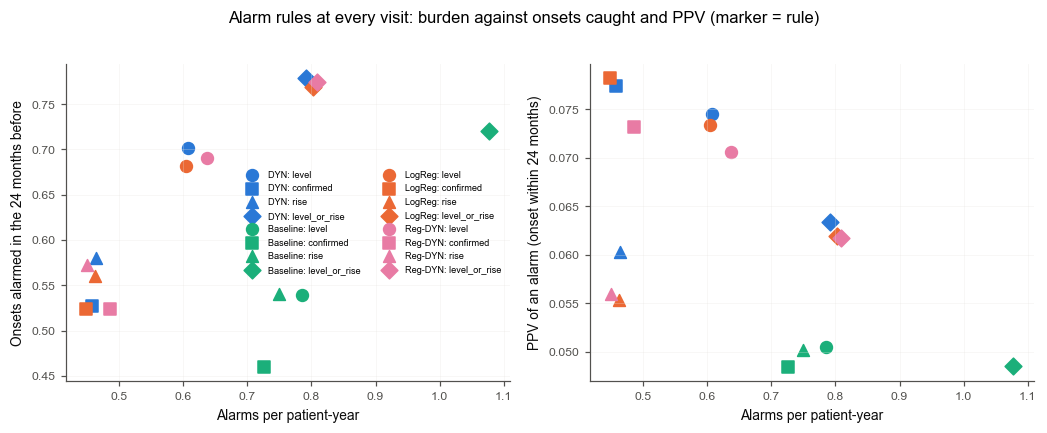

In [97]:
"""Alarm burden and false alarms by re-assessment schedule and alarm rule."""


def ewma_rise(z, rows):
    """Score at each row minus the EWMA of the same patient's EARLIER scores (rows in date order within patient)."""
    s_ = pd.Series(z[rows])
    prev = s_.groupby(PID_ALL[rows]).transform(lambda x: x.ewm(alpha=EWMA_LAMBDA, adjust=False).mean().shift(1))
    out = np.full(N_LAND, np.nan)
    out[rows] = (s_ - prev).values
    return out


THR_RISE, RISE = {}, {}
for m in MODELS_RUN:
    for r in REPEATS:
        thr = np.full(N_LAND, np.nan)
        for f in range(CV_N_SPLITS):
            tr, zo = OOF_H[(m, r, f)]
            zf = np.full(N_LAND, np.nan); zf[tr] = zo
            ro = ewma_rise(zf, np.sort(tr))[tr]
            lab = LABEL_H[H][tr]
            k = ~np.isnan(lab) & ~np.isnan(ro)
            thr[rows_of(OUTER[r][f][1])] = choose_thresholds(lab[k], ro[k])["cost"]
        THR_RISE[(m, r)] = thr
        RISE[(m, r)] = ewma_rise(zpred(m, r), np.arange(N_LAND))


def assessment_schedule(every_months):
    """Assessments of every patient: (latest landmark row, date in days, position within the patient)."""
    lr_, tau_, seq_ = [], [], []
    for pid, li in PT_ROWS.items():
        t = _LAND_T[li]
        if every_months == 0:
            tau, lr = t, li
        else:
            tau = np.arange(t[0], t[-1] + 1e-6, every_months * MONTH_DAYS)
            lr = li[np.searchsorted(t, tau, side="right") - 1]
            ok = tau < INT_END[lr]                       # still at risk since the latest landmark
            tau, lr = tau[ok], lr[ok]
        lr_.append(lr); tau_.append(tau); seq_.append(np.arange(len(lr)))
    lr, tau, sq = np.concatenate(lr_), np.concatenate(tau_), np.concatenate(seq_)
    rem = _END[lr] - tau                                 # follow-up left after the assessment
    true = (C_ALL[lr] == 1) & (rem <= HORIZON_DAYS)
    false = ~true & ((rem > HORIZON_DAYS) | (C_ALL[lr] >= 2))
    fo = pd.Series(PID_ALL[lr]).map(FIRST_ONSET).values.astype("datetime64[ns]")
    fo_d = (fo - np.datetime64("1970-01-01")) / np.timedelta64(1, "D")
    pre_onset = (tau < fo_d) & (tau >= fo_d - H * MONTH_DAYS)
    return {"lr": lr, "tau": tau, "seq": sq, "pid": PID_ALL[lr], "true": true, "false": false, "pre_onset": pre_onset}


ASSESS = {k: assessment_schedule(v) for k, v in ASSESS_SCHEDULES.items()}
_PY_ALL = INT_YRS.sum()
_never = ~np.isin(PID_ALL, list(EVER_ONSET))
_PY_NEVER = INT_YRS[_never].sum()
print("Assessments per patient-year at risk: " + ", ".join(f"{k} {len(a['lr']) / _PY_ALL:.2f}" for k, a in ASSESS.items()))


def alarm_stats(m, r, sched, rule):
    A = ASSESS[sched]
    lr = A["lr"]
    level = zpred(m, r)[lr] >= THR_V[m][r][H][MAIN_THRESHOLD][lr]
    rise = np.nan_to_num(RISE[(m, r)][lr], nan=-np.inf) >= THR_RISE[(m, r)][lr]
    if rule == "level":
        on = level
    elif rule == "confirmed":
        on = level & np.r_[False, level[:-1]] & (A["seq"] > 0)
    elif rule == "rise":
        on = rise
    else:
        on = level | rise
    has_next = np.r_[A["seq"][1:] > 0, False]
    resolved = on & (A["true"] | A["false"])
    ev_alarmed = pd.Series(on & A["pre_onset"]).groupby(A["pid"]).max()
    ev_alarmed = ev_alarmed.reindex(list(EVER_ONSET)).fillna(False).astype(float)
    never_on = on & ~np.isin(A["pid"], list(EVER_ONSET))
    return {"Alarms per patient-year": on.sum() / _PY_ALL, "Share of assessments alarming": on.mean(),
            "False alarms, share of resolved alarms": (on & A["false"]).sum() / max(resolved.sum(), 1),
            "PPV of an alarm (onset within 24 months)": (on & A["true"]).sum() / max(resolved.sum(), 1),
            "Alarms per patient-year, never-onset patients": never_on.sum() / _PY_NEVER,
            "Onsets with an alarm in the 24 months before": float(ev_alarmed.mean()),
            "Flip rate (alarm, then no alarm next)": (on & np.r_[~on[1:], True] & has_next).sum()
            / max((on & has_next).sum(), 1)}


rows = []
for m in MODELS_RUN:
    for sched in ASSESS_SCHEDULES:
        for rule in ALARM_RULE_LABELS:
            vals = pd.DataFrame([alarm_stats(m, r, sched, rule) for r in REPEATS]).mean()
            rows.append({"Model": short_label(m), "Re-assessment": sched, "Alarm rule": rule, **vals.to_dict()})
ALARMS = pd.DataFrame(rows)
ALARMS.to_csv(f"objective1_alarms_{TAG}.csv", index=False)
_am = [m for m in KEY_MODELS + [REG_DYN] if m in MODELS_RUN]
display(ALARMS[(ALARMS["Model"].isin([short_label(m) for m in _am])) & (ALARMS["Re-assessment"] == "visit")]
        .set_index(["Model", "Alarm rule"]).drop(columns="Re-assessment").round(3))
display(ALARMS[(ALARMS["Model"] == short_label(MAIN_MODEL))].set_index(["Re-assessment", "Alarm rule"])
        .drop(columns="Model").round(3))
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
_v = ALARMS[ALARMS["Re-assessment"] == "visit"]
for m in _am:
    d = _v[_v["Model"] == short_label(m)].set_index("Alarm rule")
    for rule, mk in zip(ALARM_RULE_LABELS, ["o", "s", "^", "D"]):
        axes[0].scatter(d.loc[rule, "Alarms per patient-year"], d.loc[rule, "Onsets with an alarm in the 24 months before"],
                        color=model_color(m), marker=mk, s=60, label=f"{short_label(m)}: {rule}")
        axes[1].scatter(d.loc[rule, "Alarms per patient-year"], d.loc[rule, "PPV of an alarm (onset within 24 months)"],
                        color=model_color(m), marker=mk, s=60)
axes[0].set_xlabel("Alarms per patient-year"); axes[0].set_ylabel("Onsets alarmed in the 24 months before")
axes[1].set_xlabel("Alarms per patient-year"); axes[1].set_ylabel("PPV of an alarm (onset within 24 months)")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=6, ncol=2)
fig.suptitle("Alarm rules at every visit: burden against onsets caught and PPV (marker = rule)", y=1.02)
plt.tight_layout(); save_fig("alarms")

## 14.4 Conclusion — Objective 2

In [98]:
"""Objective 2 conclusion."""
_h2 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H2")]
_a = ALARMS.set_index(["Model", "Re-assessment", "Alarm rule"])
txt = (f"Time-matched AUROC of the main model by months before the onset: " + ", ".join(
    f"{k} {ci((MAIN_MODEL, 'tm', k, 'auroc'))[0]:.3f}" for k in _tto) + ". Within-patient C (year-centred): "
       f"{fmtk((MAIN_MODEL, 'within', H, 'c'))}. At every visit, the level alarm catches "
       f"{_a.loc[(short_label(MAIN_MODEL), 'visit', 'level'), 'Onsets with an alarm in the 24 months before']:.0%} of "
       f"onsets in the 24 months before them (level or rise: "
       f"{_a.loc[(short_label(MAIN_MODEL), 'visit', 'level_or_rise'), 'Onsets with an alarm in the 24 months before']:.0%}). "
       "Hypotheses: " + "; ".join(f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: "
                                  f"{'met' if r_['Met'] else 'not met'}" for r_ in _h2) + ".")
OBJ_CONCLUSIONS["Objective 2"] = txt
print(textwrap.fill(txt, 118))

Time-matched AUROC of the main model by months before the onset: 0-6 0.733, 6-12 0.735, 12-24 0.695, 24-36 0.649,
36-48 0.674. Within-patient C (year-centred): 0.634 (0.570 to 0.699). At every visit, the level alarm catches 70% of
onsets in the 24 months before them (level or rise: 78%). Hypotheses: H2a (Main: time-matched AUROC 0-24 minus 24-36
months before onset) 0.087 (0.041 to 0.134): met; H2b (Main: extra rise per year before onset vs never-onset (mixed
model, year-centred logit)) 0.089 (0.066 to 0.111): met; H2c (Main: median lead time, flagged event patients (months))
18.1 (15.5 to 19.9): met.


---
# 15. Objective 3 — Patients who stay at work, especially healthy-looking ones, score low

## 15.1 Risk in healthy-looking patients who never have an onset

**Healthy-looking** at a visit: low disease activity (modified LLDAS), no damage (SDI 0), prednisone ≤ 5 mg/day and
none of fatigue, arthralgia, dyspnoea or fibromyalgia recorded. Three groups of landmark visits: **before an onset**
(an onset within 24 months), and visits of patients who **never have an onset**, healthy-looking or not. For each
model: the mean predicted 24-month risk and the share of visits flagged (fold threshold) in each group, and the
time-matched patient AUROC against **healthy-looking controls only** and against the **other controls** (whether
the control's window ends at a healthy-looking visit). Hypotheses:

* **H3a**: the main model flags fewer healthy-looking stayers than other stayers (difference in share flagged, upper
  95 % bound < 0);
* **H3b**: DYN − Baseline, time-matched AUROC against healthy-looking controls, lower bound > 0;
* **H3c**: DYN − LogReg, the same.

Landmark visits / patients per group: Before an onset (within 24 months): 564 / 139, Never an onset: healthy-looking: 2,223 / 303, Never an onset: other: 12,834 / 855
Healthy-looking visits among all landmarks: 14%; among those before an onset: 3%


Model,S0 pooled,S1 no-pool,S2 bands,DYN-bands,DYN,Two-part,Reg-DYN,LogReg,Reg-pooled,Baseline,Average
Mean 24-mo risk: Before an onset (within 24 months),0.063 (0.055 to 0.072),0.063 (0.056 to 0.071),0.063 (0.055 to 0.072),0.062 (0.054 to 0.071),0.063 (0.056 to 0.071),0.054 (0.048 to 0.062),0.066 (0.058 to 0.076),0.071 (0.062 to 0.081),0.063 (0.055 to 0.072),0.045 (0.041 to 0.049),0.064 (0.056 to 0.072)
Mean 24-mo risk: Never an onset: healthy-looking,0.015 (0.015 to 0.016),0.014 (0.014 to 0.015),0.014 (0.013 to 0.015),0.015 (0.014 to 0.015),0.015 (0.014 to 0.015),0.017 (0.016 to 0.018),0.013 (0.013 to 0.014),0.012 (0.012 to 0.013),0.014 (0.014 to 0.015),0.024 (0.023 to 0.026),0.014 (0.013 to 0.014)
Mean 24-mo risk: Never an onset: other,0.034 (0.032 to 0.037),0.034 (0.032 to 0.036),0.033 (0.031 to 0.035),0.033 (0.031 to 0.035),0.034 (0.032 to 0.036),0.033 (0.032 to 0.035),0.035 (0.033 to 0.038),0.036 (0.034 to 0.038),0.036 (0.034 to 0.038),0.035 (0.034 to 0.036),0.034 (0.032 to 0.036)
Flagged: Before an onset (within 24 months),0.632 (0.558 to 0.710),0.670 (0.599 to 0.742),0.654 (0.582 to 0.726),0.662 (0.592 to 0.730),0.650 (0.583 to 0.717),0.655 (0.584 to 0.724),0.643 (0.576 to 0.711),0.633 (0.568 to 0.701),0.667 (0.590 to 0.735),0.575 (0.501 to 0.650),0.627 (0.562 to 0.695)
Flagged: Never an onset: healthy-looking,0.018 (0.011 to 0.025),0.015 (0.010 to 0.022),0.022 (0.015 to 0.030),0.023 (0.016 to 0.032),0.018 (0.013 to 0.024),0.055 (0.041 to 0.069),0.006 (0.003 to 0.010),0.010 (0.005 to 0.015),0.016 (0.010 to 0.023),0.164 (0.126 to 0.204),0.007 (0.004 to 0.011)
Flagged: Never an onset: other,0.304 (0.275 to 0.332),0.325 (0.298 to 0.353),0.320 (0.291 to 0.348),0.321 (0.295 to 0.348),0.310 (0.285 to 0.335),0.356 (0.329 to 0.382),0.333 (0.305 to 0.363),0.311 (0.285 to 0.337),0.332 (0.303 to 0.360),0.397 (0.368 to 0.425),0.296 (0.270 to 0.324)
"Flagged, healthy minus other stayers",-0.286 (-0.317 to -0.257),-0.310 (-0.340 to -0.282),-0.298 (-0.327 to -0.268),-0.298 (-0.325 to -0.268),-0.292 (-0.318 to -0.264),-0.301 (-0.331 to -0.271),-0.327 (-0.357 to -0.298),-0.301 (-0.329 to -0.274),-0.316 (-0.345 to -0.287),-0.233 (-0.279 to -0.181),-0.289 (-0.316 to -0.262)
Time-matched AUROC vs healthy-looking controls,0.902 (0.867 to 0.933),0.918 (0.885 to 0.948),0.899 (0.866 to 0.929),0.896 (0.860 to 0.929),0.920 (0.892 to 0.947),0.894 (0.861 to 0.925),0.934 (0.907 to 0.958),0.930 (0.900 to 0.956),0.926 (0.898 to 0.950),0.765 (0.710 to 0.820),0.934 (0.907 to 0.958)
Time-matched AUROC vs other controls,0.677 (0.632 to 0.723),0.694 (0.650 to 0.738),0.674 (0.630 to 0.719),0.677 (0.635 to 0.720),0.702 (0.662 to 0.744),0.651 (0.606 to 0.699),0.682 (0.636 to 0.730),0.687 (0.643 to 0.732),0.676 (0.629 to 0.723),0.547 (0.498 to 0.601),0.697 (0.655 to 0.741)


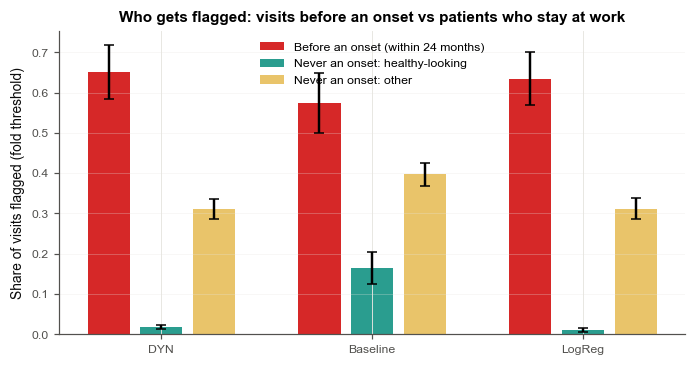

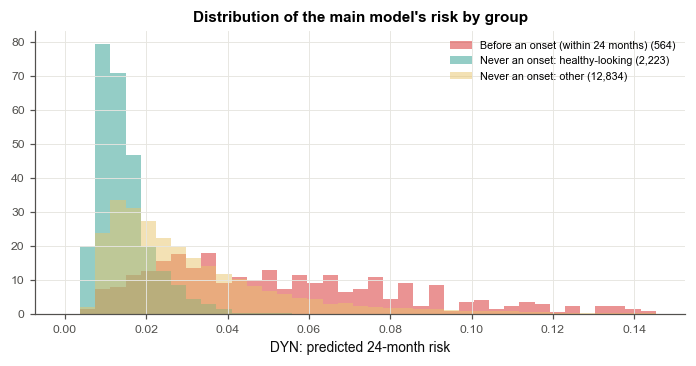

In [99]:
"""Healthy-looking stayers: risk, flags and time-matched AUROC."""
_v = visits.loc[LAND_VROW]
HEALTHY = ((_v["LLDAS_NOW"].values == 1) & (_v["score_n"].fillna(0).values == 0)
           & (_v["STERAVER_0"].values <= HEALTHY_PRED_MAX)
           & ~(_v[["FATIGUE", "ARTHRALGIA", "DYSPNOEA", "FIBROMYALGIA"]].fillna(0).values > 0).any(1))
NEVER = ~np.isin(PID_ALL, list(EVER_ONSET))
NEAR = (C_ALL == 1) & (T_ALL <= HORIZON_DAYS)
GROUPS = {NEAR_LABEL: NEAR, "Never an onset: healthy-looking": NEVER & HEALTHY,
          "Never an onset: other": NEVER & ~HEALTHY}
print("Landmark visits / patients per group: " + ", ".join(
    f"{k}: {int(v.sum()):,} / {len(np.unique(PID_ALL[v]))}" for k, v in GROUPS.items()))
print(f"Healthy-looking visits among all landmarks: {HEALTHY.mean():.0%}; among those before an onset: "
      f"{HEALTHY[NEAR].mean():.0%}")
_d = TM["main"]
_hk = HEALTHY[_d["last"][_d["pk"]]]
for lab_, mk in [("healthy", _hk), ("other", ~_hk)]:
    _d[f"den_{lab_}"] = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(mk.sum()), (_d["ppc"][mk], _d["ppk"][mk])),
                                                                 shape=(P_, P_)).toarray())
for m in MODELS_RUN:
    acc = {}
    for r in REPEATS:
        z = zpred(m, r)
        p = _expit(z)
        thr = THR_V[m][r][H][MAIN_THRESHOLD]
        flag = (z >= thr).astype(np.float32)
        for g, mask in GROUPS.items():
            Wg = _W_ALL[:, mask]
            acc.setdefault(("mean_risk", g), []).append((Wg @ p[mask]) / Wg.sum(1))
            acc.setdefault(("flagged", g), []).append((Wg @ flag[mask]) / Wg.sum(1))
        s = np.asarray(_d["mat"] @ np.nan_to_num(z)).ravel()
        for lab_, mk in [("healthy", _hk), ("other", ~_hk)]:
            a, b_ = s[_d["pc"][mk]], s[_d["pk"][mk]]
            K = sparse.coo_matrix(((a > b_) + 0.5 * (a == b_), (_d["ppc"][mk], _d["ppk"][mk])), shape=(P_, P_)).toarray()
            acc.setdefault(("tm_auroc", lab_), []).append(_pair_sum_fast(_BOTH, K) / _d[f"den_{lab_}"])
    for k, v in acc.items():
        v = np.mean(v, 0)
        STATS[(m, "obj3") + k] = (float(v[0]), v[1:])
    fh = STATS[(m, "obj3", "flagged", "Never an onset: healthy-looking")]
    fo = STATS[(m, "obj3", "flagged", "Never an onset: other")]
    STATS[(m, "obj3", "flag_diff")] = (fh[0] - fo[0], fh[1] - fo[1])
rows = []
for m in MODELS_RUN:
    row = {"Model": short_label(m)}
    for g in GROUPS:
        row[f"Mean {H}-mo risk: {g}"] = fmtk((m, "obj3", "mean_risk", g))
    for g in GROUPS:
        row[f"Flagged: {g}"] = fmtk((m, "obj3", "flagged", g))
    row["Flagged, healthy minus other stayers"] = fmtk((m, "obj3", "flag_diff"))
    row["Time-matched AUROC vs healthy-looking controls"] = fmtk((m, "obj3", "tm_auroc", "healthy"))
    row["Time-matched AUROC vs other controls"] = fmtk((m, "obj3", "tm_auroc", "other"))
    rows.append(row)
OBJ3 = pd.DataFrame(rows).set_index("Model")
display(OBJ3.T)
OBJ3.to_csv(f"objective3_healthy_{TAG}.csv")
_fd = ci((MAIN_MODEL, "obj3", "flag_diff"))
HYP_ROWS.append({"Hypothesis": "H3a", "Estimand": "Main: share flagged, healthy-looking minus other stayers",
                 "Estimate (95% CI)": fmt(*_fd), "Criterion": "upper bound < 0", "Met": _fd[2] < 0})
for hyp, b_ in [("H3b", BASELINE), ("H3c", LOGREG)]:
    d = diff(MAIN_MODEL, b_, ("obj3", "tm_auroc", "healthy"))
    HYP_ROWS.append({"Hypothesis": hyp, "Estimand": f"DYN - {short_label(b_)}, time-matched AUROC vs healthy-looking "
                     "controls", "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0", "Met": d[1] > 0,
                     "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})
fig, ax = plt.subplots(figsize=(6.4, 3.4))
_gcol = ["#d62828", "#2a9d8f", "#e9c46a"]
_km = [m for m in KEY_MODELS if m in MODELS_RUN]
for j, m in enumerate(_km):
    for k, g in enumerate(GROUPS):
        a = ci((m, "obj3", "flagged", g))
        ax.bar(j * 4 + k, a[0], color=_gcol[k], yerr=[[a[0] - a[1]], [a[2] - a[0]]], capsize=3,
               label=g if j == 0 else None)
ax.set_xticks([j * 4 + 1 for j in range(len(_km))]); ax.set_xticklabels([short_label(m) for m in _km])
ax.set_ylabel("Share of visits flagged (fold threshold)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
ax.set_title("Who gets flagged: visits before an onset vs patients who stay at work")
plt.tight_layout(); save_fig("healthy_flags")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
pz = _expit(np.mean([zpred(MAIN_MODEL, r) for r in REPEATS], 0))
bins = np.linspace(0, np.percentile(pz, 99), 40)
for (g, mask), c in zip(GROUPS.items(), _gcol):
    ax.hist(pz[mask], bins=bins, density=True, alpha=0.5, color=c, label=f"{g} ({int(mask.sum()):,})")
ax.set_xlabel(f"{short_label(MAIN_MODEL)}: predicted {H}-month risk"); ax.legend(fontsize=7)
ax.set_title("Distribution of the main model's risk by group")
plt.tight_layout(); save_fig("healthy_hist")

## 15.2 Who are the false positives?

Visits of patients who never have an onset that the main model flags, against those it does not flag, and against
visits before an onset: the mean of key variables and the standardised mean difference (SMD) of flagged vs not
flagged stayers. Shows what makes a stayer look high-risk.

In [100]:
"""Profile of the main model's false positives."""
_zm = np.mean([zpred(MAIN_MODEL, r) for r in REPEATS], 0)
_tm = np.nanmean([THR_V[MAIN_MODEL][r][H][MAIN_THRESHOLD] for r in REPEATS], 0)
FP = NEVER & (_zm >= _tm)
TN = NEVER & (_zm < _tm)
rows = []
for c in FP_PROFILE_VARS:
    x = _v[c].astype(float).values
    a, b_, n_ = np.nanmean(x[FP]), np.nanmean(x[TN]), np.nanmean(x[NEAR])
    sd = np.sqrt((np.nanvar(x[FP]) + np.nanvar(x[TN])) / 2)
    rows.append({"Variable": DISPLAY_NAMES.get(c, c), "Flagged stayers (false positives)": round(a, 2),
                 "Unflagged stayers": round(b_, 2), "Before an onset": round(n_, 2),
                 "SMD flagged vs unflagged": round((a - b_) / sd if sd > 0 else np.nan, 2)})
FPT = pd.DataFrame(rows).set_index("Variable").sort_values("SMD flagged vs unflagged", key=np.abs, ascending=False)
print(f"Stayer visits flagged: {int(FP.sum()):,} of {int(NEVER.sum()):,} ({FP.sum() / NEVER.sum():.0%}); healthy-looking "
      f"among them: {HEALTHY[FP].mean():.0%} (among unflagged: {HEALTHY[TN].mean():.0%})")
display(FPT)
FPT.to_csv(f"objective3_false_positives_{TAG}.csv")

Stayer visits flagged: 3,894 of 15,057 (26%); healthy-looking among them: 1% (among unflagged: 20%)


,Flagged stayers (false positives),Unflagged stayers,Before an onset,SMD flagged vs unflagged
Variable,,,,
Calendar year (adjustment),2006.64,2013.09,2006.96,-0.91
"Prednisone, average dose since last visit (mg/day)",9.71,2.35,9.05,0.90
Fibromyalgia tender points (0-18),5.22,0.72,3.93,0.87
"Acute visits, last 12 months",0.74,0.20,0.58,0.82
Fibromyalgia,0.30,0.03,0.23,0.79
SLEDAI-2K,5.28,2.83,5.24,0.59
"Clinic visits per year, last 12 mo",3.89,3.18,3.79,0.57
Arthralgia,0.43,0.18,0.44,0.56
Fatigue,0.21,0.04,0.22,0.53


## 15.3 Conclusion — Objective 3

In [101]:
"""Objective 3 conclusion."""
_h3 = [r_ for r_ in HYP_ROWS if r_["Hypothesis"].startswith("H3")]
_m = MAIN_MODEL
txt = (f"Main model: mean {H}-month risk {ci((_m, 'obj3', 'mean_risk', NEAR_LABEL))[0]:.3f} "
       f"before an onset, {ci((_m, 'obj3', 'mean_risk', 'Never an onset: other'))[0]:.3f} in other stayers and "
       f"{ci((_m, 'obj3', 'mean_risk', 'Never an onset: healthy-looking'))[0]:.3f} in healthy-looking stayers; share "
       f"flagged {ci((_m, 'obj3', 'flagged', NEAR_LABEL))[0]:.0%} / "
       f"{ci((_m, 'obj3', 'flagged', 'Never an onset: other'))[0]:.0%} / "
       f"{ci((_m, 'obj3', 'flagged', 'Never an onset: healthy-looking'))[0]:.0%}. Time-matched AUROC against "
       f"healthy-looking controls {fmtk((_m, 'obj3', 'tm_auroc', 'healthy'))}, against other controls "
       f"{fmtk((_m, 'obj3', 'tm_auroc', 'other'))}. Largest differences of flagged vs unflagged stayers: " + ", ".join(
           f"{i} (SMD {r_['SMD flagged vs unflagged']:+.2f})" for i, r_ in FPT.head(4).iterrows()) + ". Hypotheses: " +
       "; ".join(f"{r_['Hypothesis']} ({r_['Estimand']}) {r_['Estimate (95% CI)']}: {'met' if r_['Met'] else 'not met'}"
                 for r_ in _h3) + ".")
OBJ_CONCLUSIONS["Objective 3"] = txt
print(textwrap.fill(txt, 118))

Main model: mean 24-month risk 0.063 before an onset, 0.034 in other stayers and 0.015 in healthy-looking stayers;
share flagged 65% / 31% / 2%. Time-matched AUROC against healthy-looking controls 0.920 (0.892 to 0.947), against
other controls 0.702 (0.662 to 0.744). Largest differences of flagged vs unflagged stayers: Calendar year (adjustment)
(SMD -0.91), Prednisone, average dose since last visit (mg/day) (SMD +0.90), Fibromyalgia tender points (0-18) (SMD
+0.87), Acute visits, last 12 months (SMD +0.82). Hypotheses: H3a (Main: share flagged, healthy-looking minus other
stayers) -0.292 (-0.318 to -0.264): met; H3b (DYN - Baseline, time-matched AUROC vs healthy-looking controls) 0.155
(0.106 to 0.210): met; H3c (DYN - LogReg, time-matched AUROC vs healthy-looking controls) -0.009 (-0.028 to 0.010):
not met.


---
# 16. Objective 4 — What drives the main model's risk (SHAP)

## 16.1 SHAP values of the dynamic LSTM

The main model is refitted on the five outer folds of CV repeat 1 exactly as in the cross-validation (same training
patients, preprocessing and seeds; 5 networks per fold), keeping the networks. Each fold's ensemble explains **its
own test patients** (patients it never saw): every test landmark of a patient within 48 months before an onset plus a
random sample of the other test landmarks, landmarks with a full 2-year window (5 grid points). Output explained: the
**onset log-hazard** (ensemble mean; the one-hazard model's 24-month risk rises with it). Method: expected
gradients (`shap.GradientExplainer`) with a background of training-fold landmarks. Each value is attributed to an
input **at a grid point** (t − 24, t − 18, ..., t months), so SHAP shows both *which* inputs and *when*.

Two passes per fold:
* **All eras**: test landmarks of every calendar year against a background of training landmarks of every year.
* **Recent era** (landmarks from 2012 on, the period closest to how the model would be used): recent test landmarks
  against a background of recent training landmarks. The calendar year then barely differs from the background, so
  the attribution goes to the clinical inputs.

**Calendar year is an adjustment, not a risk driver.** Its two inputs (linear and spline) are kept in the model
(they set the risk level of each era), but they are left out of the importance rankings, domain shares and plots
below; their share of the attribution is reported on its own line ("calendar adjustment"). SHAP values are additive,
so leaving them out does not change the other inputs' values. The calendar year can still interact with the clinical
inputs inside the network; the recent-era pass shows the drivers with the era held almost fixed.

In [102]:
"""Refit the main model on the outer folds of repeat 1 (networks kept); SHAP for its test patients, all eras and recent."""
import shap


_BAND_MAIN = is_band(MAIN_MODEL)


class NearOnsetEnsemble(nn.Module):
    """The fold's ensemble on dense full windows (n, T, F): the onset log-hazard (one-hazard model) or the mean onset
    log-hazard of bands 1-2 (months 0-12, band model)."""

    def __init__(self, states, n_in):
        super().__init__()
        self.nets = nn.ModuleList()
        for st_ in states:
            net = GridNet(n_in, SEQ_CFG["hidden"], SEQ_CFG["dropout"], n_out=2 * N_BANDS if _BAND_MAIN else 2)
            net.load_state_dict(st_); net.eval()
            self.nets.append(net)

    def forward(self, x):
        outs = []
        for net in self.nets:
            _, (h, _) = net.rnn(x)
            z = net.head(torch.cat([h[-1], x[:, -1]], -1))
            outs.append(z[:, :2].mean(1) if _BAND_MAIN else z[:, 0])
        return torch.stack(outs, 1).mean(1, keepdim=True)


SHAP_RECENT_FROM = ERA_BANDS[-1][0]                  # the recent era: landmarks from 2012 on
_d_main = parse_model(MAIN_MODEL)
_st, _ln = grid_window(_d_main["lookback"])
T_SH = lookback_points(_d_main["lookback"])
FULL = LG_LEN >= T_SH
RECENT = land["CAL_YEAR"].values >= SHAP_RECENT_FROM
SHAP_RES = _load(SHAP_PATH, {})


def _shap_pass(model, VX, te_rows, tr_rows, seed):
    """SHAP of `model` for the near-onset test landmarks + a sample of the others, against a training background."""
    rng = np.random.RandomState(seed)
    mo_before = np.array([(FIRST_ONSET[PID_ALL[i]].value / 8.64e13 - _LAND_T[i]) / MONTH_DAYS
                          if PID_ALL[i] in EVER_ONSET else np.nan for i in te_rows])
    near = te_rows[(mo_before > 0) & (mo_before <= TRAJ_MAX_MONTHS)]
    other = np.setdiff1d(te_rows, near)
    n_other = max(0, SHAP_N_EXPLAIN - len(near))
    ex_rows = np.sort(np.r_[near, rng.choice(other, min(n_other, len(other)), replace=False)])
    bg_rows = rng.choice(tr_rows, min(SHAP_N_BACKGROUND, len(tr_rows)), replace=False)
    dense = lambda rows: np.stack([VX[_st[i]:_st[i] + T_SH] for i in rows]).astype(np.float32)
    Xe, Xb = dense(ex_rows), dense(bg_rows)
    expl = shap.GradientExplainer(model, torch.from_numpy(Xb))
    sv = expl.shap_values(torch.from_numpy(Xe), nsamples=SHAP_SAMPLES)
    sv = np.asarray(sv[0] if isinstance(sv, list) else sv)
    if sv.ndim == 4:
        sv = sv[..., 0]
    with torch.no_grad():
        out = model(torch.from_numpy(Xe)).numpy().ravel()
    return {"rows": ex_rows, "sv": sv.astype(np.float32), "X": Xe, "out": out, "n_near": len(near)}


for f in range(CV_N_SPLITS):
    if f in SHAP_RES and ("recent", f) in SHAP_RES:
        continue
    t0 = time.time()
    r = SHAP_REPEAT
    tr_p, te_p = OUTER[r][f]
    prep = GridPrep(grid_cols_of(MAIN_MODEL)).fit(rows_of(tr_p))
    VX = prep.transform(GRID_RAW)
    res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")(
        delayed(fit_grid)(SEQ_CFG, VX, _st, _ln, tr_p, SEED + 1000 * CV_INNER_SPLITS + 31 * s + 7 * r + f, te_p,
                          _d_main["hazard"], False, None, True) for s in range(SEQ_SEEDS_FINAL))
    model = NearOnsetEnsemble([x[2] for x in res], VX.shape[1])
    te_rows = rows_of(te_p); te_rows = te_rows[FULL[te_rows]]
    tr_rows = rows_of(tr_p); tr_rows = tr_rows[FULL[tr_rows]]
    torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
    if f not in SHAP_RES:
        SHAP_RES[f] = {**_shap_pass(model, VX, te_rows, tr_rows, SEED + f), "names": prep.names}
    SHAP_RES[("recent", f)] = {**_shap_pass(model, VX, te_rows[RECENT[te_rows]], tr_rows[RECENT[tr_rows]],
                                            SEED + 100 + f), "names": prep.names}
    _save(SHAP_RES, SHAP_PATH)
    print(f"  fold {f + 1}: all eras {len(SHAP_RES[f]['rows'])} landmarks ({SHAP_RES[f]['n_near'] if 'n_near' in SHAP_RES[f] else '-'}"
          f" within 48 months before an onset) | recent era {len(SHAP_RES[('recent', f)]['rows'])} "
          f"({SHAP_RES[('recent', f)]['n_near']}) | {(time.time() - t0) / 60:.1f} min", flush=True)


def _stack(key):
    parts = [SHAP_RES[key(f)] for f in range(CV_N_SPLITS)]
    return (np.concatenate([p["rows"] for p in parts]), np.concatenate([p["sv"] for p in parts]),
            np.concatenate([p["X"] for p in parts]), np.concatenate([p["out"] for p in parts]),
            np.concatenate([np.full(len(p["rows"]), f) for f, p in enumerate(parts)]))


SH_ROWS, SV, SX, SH_OUT, SH_FOLD = _stack(lambda f: f)                     # SV: (n, T, F)
SH_ROWS_R, SV_R, SX_R, SH_OUT_R, SH_FOLD_R = _stack(lambda f: ("recent", f))
SH_NAMES = SHAP_RES[0]["names"]
SV_SUM, SV_SUM_R = SV.sum(1), SV_R.sum(1)                                  # per input, over the grid points


def sh_display(c):
    if c.endswith("__MISSING"):
        return f"{DISPLAY_NAMES.get(c[:-9], c[:-9])}: missing"
    return DISPLAY_NAMES.get(c, c)


def sh_domain(c):
    if c.endswith("__MISSING"):
        return "Missing-value indicators"
    return FEATURE_GROUP.get(c, FEATURE_GROUP.get(c.split("__")[0], "Other"))


SH_DISPLAY = np.array([sh_display(c) for c in SH_NAMES])
SH_DOMAIN = np.array([sh_domain(c) for c in SH_NAMES])
IS_CAL = np.array([c.split("__")[0] in YEAR_COLS for c in SH_NAMES])     # the calendar adjustment
CLIN = ~IS_CAL                                                             # every other input: the risk drivers
CLIN_NAMES = [c for c, k in zip(SH_NAMES, CLIN) if k]


def cal_share(sv_sum):
    """Calendar adjustment's share of the total mean |SHAP| (all inputs)."""
    a = np.abs(sv_sum).mean(0)
    return a[IS_CAL].sum() / a.sum()


for lab_, rows_, sv_, out_ in [("All eras", SH_ROWS, SV, SH_OUT), (f"Recent era ({SHAP_RECENT_FROM} on)", SH_ROWS_R,
                                                                     SV_R, SH_OUT_R)]:
    print(f"SHAP, {lab_}: {len(rows_):,} test landmarks from {len(np.unique(PID_ALL[rows_]))} patients; "
          f"{sv_.shape[1]} grid points x {sv_.shape[2]} inputs ({CLIN.sum()} clinical + {IS_CAL.sum()} calendar). "
          f"Additivity: corr(sum of SHAP, output) = {np.corrcoef(sv_.sum((1, 2)), out_)[0, 1]:.3f}. "
          f"Calendar adjustment: {cal_share(sv_.sum(1)):.0%} of the total |SHAP|")

SHAP, All eras: 7,500 test landmarks from 782 patients; 5 grid points x 67 inputs (65 clinical + 2 calendar). Additivity: corr(sum of SHAP, output) = 0.993. Calendar adjustment: 12% of the total |SHAP|
SHAP, Recent era (2012 on): 6,742 test landmarks from 629 patients; 5 grid points x 67 inputs (65 clinical + 2 calendar). Additivity: corr(sum of SHAP, output) = 0.994. Calendar adjustment: 8% of the total |SHAP|


## 16.2 Global importance: inputs, domains, and current status vs history

Mean |SHAP| of each **clinical** input summed over its grid points (log-hazard units); shares are of the clinical
total. The calendar adjustment is printed on its own line. The beeswarm shows the direction (colour = the input's
standardised value at the landmark). Then each domain's share and each grid point's share (the landmark visit itself
vs the 6-24 months before it), clinical inputs only.

,Input,Domain,Mean |SHAP|,Mean SHAP,Share of clinical total
score_n,SDI damage score,Damage,0.1537,0.0057,0.0519
age_at_record,Age,Demographics,0.1519,-0.0011,0.0513
SLEDAI2_I,SLEDAI-2K,Disease activity,0.1229,0.0096,0.0415
score_n__DEV,SDI: now minus own usual,Change from own baseline,0.1189,0.0119,0.0401
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),Era of care,0.1129,-0.0014,0.0381
EDU_HIGHER,Education: higher,Work,0.1118,0.0014,0.0377
STERAVER_0,"Prednisone, average dose since last visit (mg/...",Treatment,0.1107,0.0123,0.0374
TENDER_POINTS,Fibromyalgia tender points (0-18),Pain,0.1101,-0.0033,0.0372
SMOKER,Current smoker,Smoking,0.0951,0.0087,0.0321
VISIT_RATE_1Y,"Clinic visits per year, last 12 mo",Care pattern,0.0909,0.0059,0.0307


Calendar adjustment (all eras; calendar year, linear + spline): mean |SHAP| 0.403, 12% of all attribution; not a risk driver, left out of the rankings


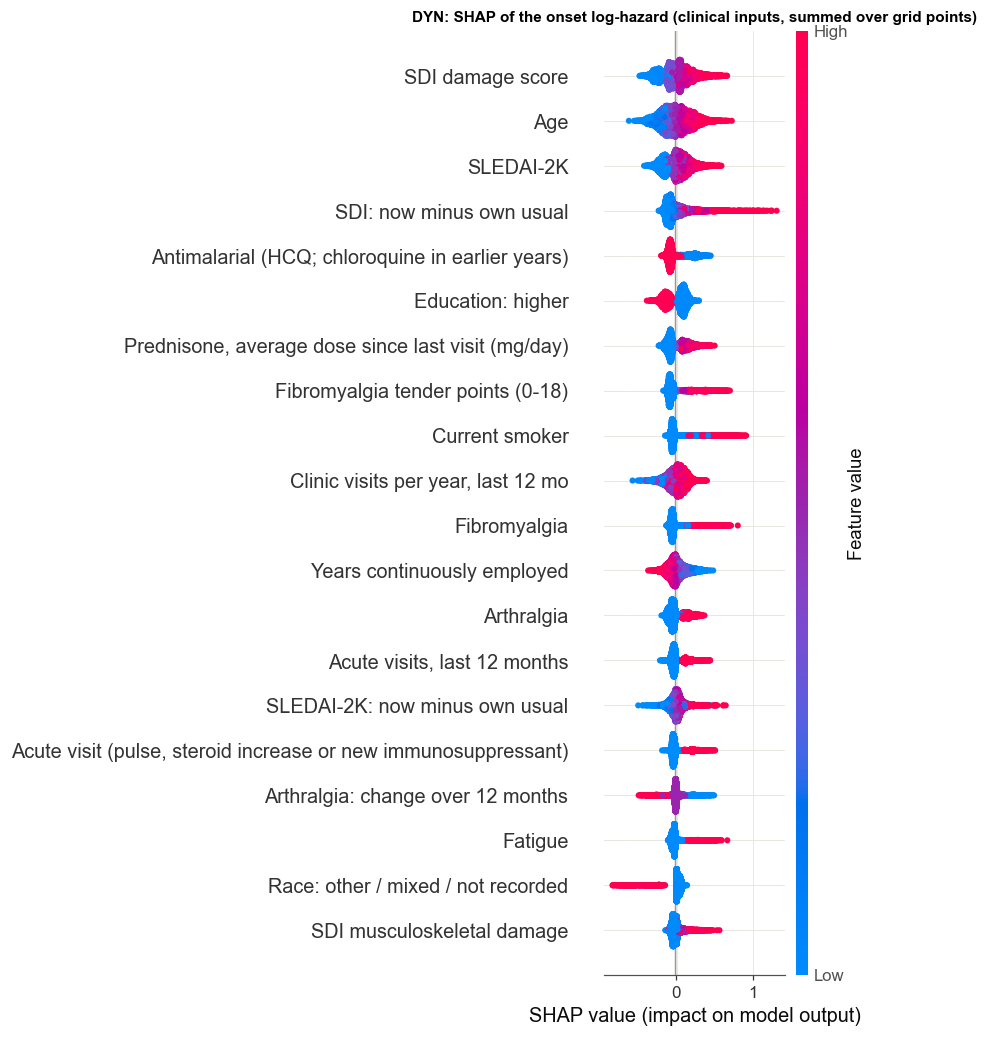

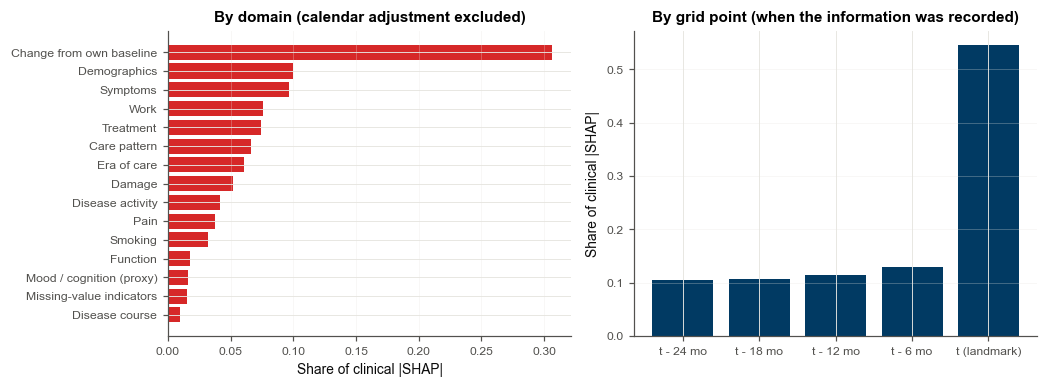

,Share of clinical |SHAP|
Domain,
Change from own baseline,0.306
Demographics,0.100
Symptoms,0.096
Work,0.075
Treatment,0.074
Care pattern,0.066
Era of care,0.061
Damage,0.052
Disease activity,0.041


,Share of clinical |SHAP|
t - 24 mo,0.105
t - 18 mo,0.107
t - 12 mo,0.114
t - 6 mo,0.129
t (landmark),0.545


Change-from-own-baseline inputs: 31% of the clinical |SHAP|; the landmark grid point: 54%


In [103]:
"""Global SHAP importance (clinical inputs; the calendar adjustment separately)."""


def importance(sv_sum):
    imp = pd.DataFrame({"Input": SH_DISPLAY[CLIN], "Domain": SH_DOMAIN[CLIN],
                        "Mean |SHAP|": np.abs(sv_sum[:, CLIN]).mean(0), "Mean SHAP": sv_sum[:, CLIN].mean(0)},
                       index=CLIN_NAMES).sort_values("Mean |SHAP|", ascending=False)
    imp["Share of clinical total"] = imp["Mean |SHAP|"] / imp["Mean |SHAP|"].sum()
    return imp


def cal_line(sv_sum, label):
    a = np.abs(sv_sum).mean(0)
    return (f"Calendar adjustment ({label}; calendar year, linear + spline): mean |SHAP| {a[IS_CAL].sum():.3f}, "
            f"{a[IS_CAL].sum() / a.sum():.0%} of all attribution; not a risk driver, left out of the rankings")


IMP = importance(SV_SUM)
display(IMP.head(25).round(4))
print(cal_line(SV_SUM, "all eras"))
IMP.to_csv(f"objective4_shap_importance_{TAG}.csv")
plt.figure()
shap.summary_plot(SV_SUM[:, CLIN], SX[:, -1, CLIN], feature_names=list(SH_DISPLAY[CLIN]), max_display=20, show=False)
plt.title("DYN: SHAP of the onset log-hazard (clinical inputs, summed over grid points)", fontsize=10)
plt.tight_layout(); save_fig("shap_beeswarm")


def domain_shares(imp):
    d = imp.groupby("Domain")["Mean |SHAP|"].sum().sort_values(ascending=False)
    return (d / d.sum()).rename("Share of clinical |SHAP|")


def time_shares(sv):
    a = np.abs(sv[:, :, CLIN]).sum(2).mean(0)
    return pd.Series(a / a.sum(), index=[f"t - {6 * (T_SH - 1 - k)} mo" if k < T_SH - 1 else "t (landmark)"
                                         for k in range(T_SH)], name="Share of clinical |SHAP|")


DOMS, TIME_SHARE = domain_shares(IMP), time_shares(SV)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
axes[0].barh(DOMS.index[::-1], DOMS.values[::-1], color="#d62828"); axes[0].set_xlabel("Share of clinical |SHAP|")
axes[0].set_title("By domain (calendar adjustment excluded)"); axes[0].grid(axis="x", alpha=0.3)
axes[1].bar(TIME_SHARE.index, TIME_SHARE.values, color="#013a63"); axes[1].set_ylabel("Share of clinical |SHAP|")
axes[1].set_title("By grid point (when the information was recorded)"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); save_fig("shap_domains_time")
display(DOMS.to_frame().round(3)); display(TIME_SHARE.to_frame().round(3))
_chg = IMP.loc[IMP["Domain"] == "Change from own baseline", "Share of clinical total"].sum()
print(f"Change-from-own-baseline inputs: {_chg:.0%} of the clinical |SHAP|; the landmark grid point: "
      f"{TIME_SHARE.iloc[-1]:.0%}")

## 16.3 How the top inputs act (dependence)

The SHAP value of each of the six most important clinical inputs (summed over grid points) against the input's
value at the landmark (original units), coloured by whether the landmark is within 12 months before an onset.

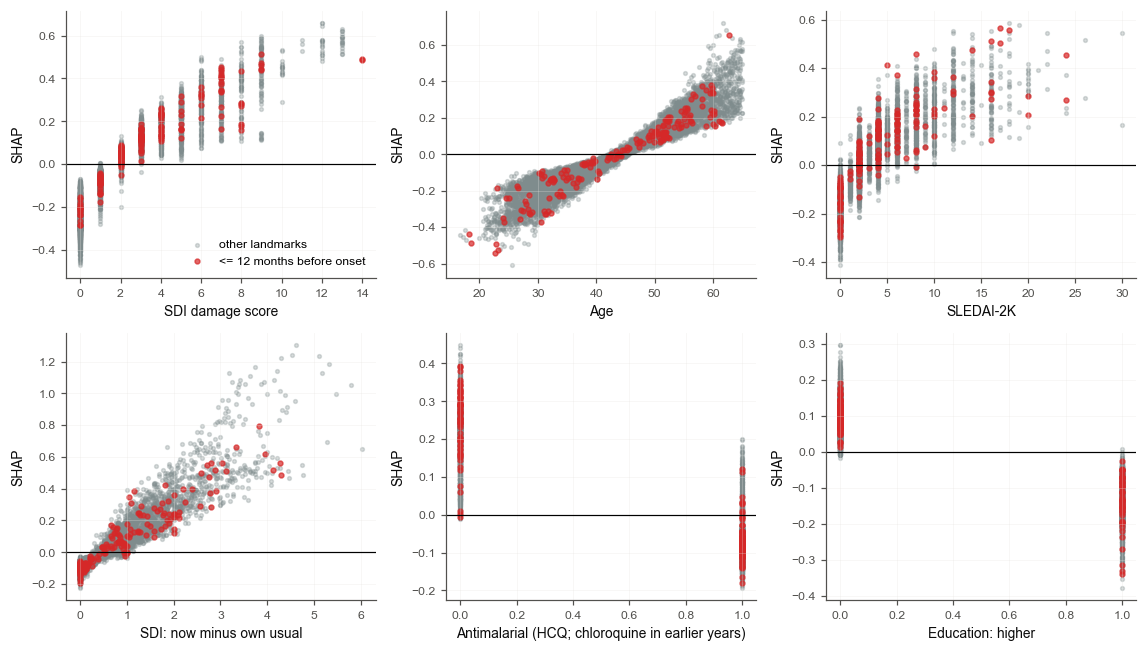

In [104]:
"""Dependence plots of the six most important clinical inputs."""
_raw_last = GRID_RAW[LG_START[SH_ROWS] + LG_LEN[SH_ROWS] - 1]
_near12 = np.array([(PID_ALL[i] in EVER_ONSET) and 0 < (FIRST_ONSET[PID_ALL[i]].value / 8.64e13 - _LAND_T[i])
                    / MONTH_DAYS <= 12 for i in SH_ROWS])
top6 = [c for c in IMP.index if not c.endswith("__MISSING")][:6]
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6))
for ax, c in zip(axes.ravel(), top6):
    j = SH_NAMES.index(c)
    x = _raw_last[:, GRID_COLS.index(c)] if c in GRID_COLS else SX[:, -1, j]
    ax.scatter(x[~_near12], SV_SUM[~_near12, j], s=6, alpha=0.3, color="#7f8c8d", label="other landmarks")
    ax.scatter(x[_near12], SV_SUM[_near12, j], s=10, alpha=0.7, color="#d62828", label="<= 12 months before onset")
    ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(sh_display(c), fontsize=9); ax.set_ylabel("SHAP")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); save_fig("shap_dependence")

## 16.4 What drives the rise before the onset, and what keeps healthy-looking stayers low

Mean signed SHAP per clinical domain (summed over its inputs and grid points) in landmarks of onset patients by
months before the onset, and in landmarks of patients who never have an onset (healthy-looking or not). Positive =
pushes the risk up relative to the background. The calendar adjustment is a separate column, not in the clinical
total; in the plot it is the grey dashed line.

,Change from own baseline,Demographics,Symptoms,Work,Treatment,Care pattern,Era of care,Damage,Disease activity,Pain,Smoking,Function,Mood / cognition (proxy),Missing-value indicators,Disease course,"Total, clinical",Calendar adjustment,Landmarks
group,,,,,,,,,,,,,,,,,,
Onset in 36-48 mo,0.180,0.022,0.225,0.043,0.072,0.013,0.024,0.050,0.028,0.073,0.056,0.011,0.007,-0.004,-0.006,0.792,0.312,138
Onset in 24-36 mo,0.010,0.036,0.202,0.054,0.062,0.012,0.028,0.068,0.046,0.046,0.047,0.022,0.008,-0.009,-0.010,0.624,0.278,139
Onset in 12-24 mo,0.140,0.035,0.193,0.033,0.064,0.009,0.043,0.070,0.058,0.048,0.048,0.026,0.002,-0.003,-0.007,0.757,0.277,174
Onset in 6-12 mo,0.241,0.021,0.247,0.036,0.140,-0.001,0.063,0.107,0.077,0.067,0.040,0.023,0.011,0.005,-0.007,1.072,0.245,106
Onset in 0-6 mo,0.278,0.022,0.196,0.058,0.130,0.017,0.059,0.091,0.080,0.059,0.056,0.020,0.016,0.003,-0.012,1.072,0.193,79
Never: other,0.055,0.009,0.002,0.008,0.043,0.005,0.002,0.032,0.012,-0.005,0.003,0.011,0.011,0.001,0.001,0.189,-0.030,5371
Never: healthy-looking,-0.168,-0.062,-0.165,-0.004,-0.101,-0.007,-0.026,-0.226,-0.038,-0.058,-0.009,-0.022,-0.019,0.004,0.005,-0.899,-0.088,910


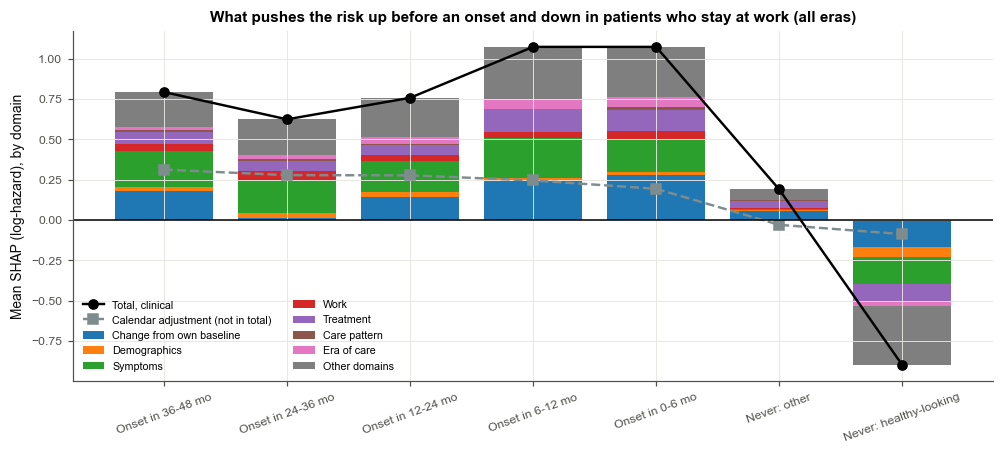

In [105]:
"""SHAP by time before the onset and in stayers."""
G_ORDER = [f"Onset in {a}-{b_} mo" for a, b_ in TTO_BINS][::-1] + ["Never: other", "Never: healthy-looking"]


def shap_by_group(rows, sv_sum, doms):
    mo = np.array([(FIRST_ONSET[PID_ALL[i]].value / 8.64e13 - _LAND_T[i]) / MONTH_DAYS if PID_ALL[i] in EVER_ONSET
                   else np.nan for i in rows])
    g = np.full(len(rows), None, object)
    for a, b_ in TTO_BINS:
        g[(mo > a) & (mo <= b_)] = f"Onset in {a}-{b_} mo"
    nev = ~np.isin(PID_ALL[rows], list(EVER_ONSET))
    g[nev & HEALTHY[rows]] = "Never: healthy-looking"
    g[nev & ~HEALTHY[rows]] = "Never: other"
    d = pd.DataFrame({k: sv_sum[:, CLIN & (SH_DOMAIN == k)].sum(1) for k in doms.index})
    d["Calendar adjustment"] = sv_sum[:, IS_CAL].sum(1)
    d["group"] = g
    out = d.dropna(subset=["group"]).groupby("group").mean().reindex(G_ORDER)
    out.insert(len(doms), "Total, clinical", out[list(doms.index)].sum(1))
    out["Landmarks"] = d.groupby("group").size().reindex(G_ORDER)
    return out


BYGRP = shap_by_group(SH_ROWS, SV_SUM, DOMS)
display(BYGRP.round(3))
BYGRP.to_csv(f"objective4_shap_by_group_{TAG}.csv")


def plot_by_group(bygrp, doms, title, path):
    top_d = list(doms.index[:7])
    fig, ax = plt.subplots(figsize=(9.2, 4.2))
    bottom_p, bottom_n = np.zeros(len(G_ORDER)), np.zeros(len(G_ORDER))
    cmap = plt.get_cmap("tab10")
    for k, d in enumerate(top_d + ["Other domains"]):
        v = bygrp[d].values if d != "Other domains" else bygrp[[c for c in doms.index if c not in top_d]].sum(1).values
        v = np.nan_to_num(v)
        pos, neg = np.clip(v, 0, None), np.clip(v, None, 0)
        ax.bar(range(len(G_ORDER)), pos, bottom=bottom_p, color=cmap(k), label=d)
        ax.bar(range(len(G_ORDER)), neg, bottom=bottom_n, color=cmap(k))
        bottom_p += pos; bottom_n += neg
    ax.plot(range(len(G_ORDER)), bygrp["Total, clinical"].values, "ko-", label="Total, clinical")
    ax.plot(range(len(G_ORDER)), bygrp["Calendar adjustment"].values, "s--", color="#7f8c8d",
            label="Calendar adjustment (not in total)")
    ax.axhline(0, color="k", lw=1); ax.set_xticks(range(len(G_ORDER)))
    ax.set_xticklabels(G_ORDER, rotation=20, fontsize=8)
    ax.set_ylabel("Mean SHAP (log-hazard), by domain"); ax.legend(fontsize=7, ncol=2); ax.set_title(title)
    plt.tight_layout(); save_fig(path)


plot_by_group(BYGRP, DOMS, "What pushes the risk up before an onset and down in patients who stay at work (all eras)",
              "shap_by_group")

## 16.5 Stability across folds

Each fold's ensemble explains different patients: the share of folds in which each clinical input is among the ten
most important, and the rank correlation of the folds' importance vectors (clinical inputs).

In [106]:
"""SHAP stability across folds (clinical inputs)."""


def stability(sv_sum, fold, imp):
    imp_f = pd.DataFrame({f"Fold {f + 1}": np.abs(sv_sum[fold == f][:, CLIN]).mean(0) for f in range(CV_N_SPLITS)},
                         index=CLIN_NAMES)
    top10 = (imp_f.rank(ascending=False) <= 10)
    stab = pd.DataFrame({"Input": SH_DISPLAY[CLIN],
                         "Overall rank": imp["Mean |SHAP|"].rank(ascending=False).reindex(CLIN_NAMES).values,
                         "Folds in top 10": top10.sum(1).values}, index=CLIN_NAMES).sort_values("Overall rank")
    rho = imp_f.corr(method="spearman").values[np.triu_indices(CV_N_SPLITS, 1)]
    return stab.head(20), rho


STAB, _rho = stability(SV_SUM, SH_FOLD, IMP)
display(STAB)
STAB.to_csv(f"objective4_shap_stability_{TAG}.csv")
print(f"Rank correlation of the folds' importance vectors: median {np.median(_rho):.2f} (range {_rho.min():.2f} to "
      f"{_rho.max():.2f})")

,Input,Overall rank,Folds in top 10
score_n,SDI damage score,1.0,5
age_at_record,Age,2.0,5
SLEDAI2_I,SLEDAI-2K,3.0,4
score_n__DEV,SDI: now minus own usual,4.0,4
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),5.0,4
EDU_HIGHER,Education: higher,6.0,4
STERAVER_0,"Prednisone, average dose since last visit (mg/...",7.0,3
TENDER_POINTS,Fibromyalgia tender points (0-18),8.0,4
SMOKER,Current smoker,9.0,3
VISIT_RATE_1Y,"Clinic visits per year, last 12 mo",10.0,3


Rank correlation of the folds' importance vectors: median 0.76 (range 0.69 to 0.80)


## 16.6 Recent era: the drivers where the model would be used

The same analyses on the recent-era pass (test landmarks from 2012 on, explained against recent training
landmarks). The calendar year varies little here, so its share should be small and the clinical ranking is the one
that applies to current patients. Side by side with the all-era ranking; then the domains, the beeswarm, the groups
(near-onset groups are smaller: fewer onsets in recent years) and the fold stability.

Calendar adjustment (recent era, 2012 on; calendar year, linear + spline): mean |SHAP| 0.237, 8% of all attribution; not a risk driver, left out of the rankings
Calendar adjustment (all eras, for comparison; calendar year, linear + spline): mean |SHAP| 0.403, 12% of all attribution; not a risk driver, left out of the rankings


,Input,Domain,Recent: rank,Recent: share,Recent: mean SHAP,All eras: rank,All eras: share
age_at_record,Age,Demographics,1,0.056,0.005,2,0.051
score_n,SDI damage score,Damage,2,0.051,-0.006,1,0.052
score_n__DEV,SDI: now minus own usual,Change from own baseline,3,0.044,0.006,4,0.040
SLEDAI2_I,SLEDAI-2K,Disease activity,4,0.041,0.001,3,0.041
EDU_HIGHER,Education: higher,Work,5,0.041,0.001,6,0.038
STERAVER_0,"Prednisone, average dose since last visit (mg/...",Treatment,6,0.034,0.000,7,0.037
TENDER_POINTS,Fibromyalgia tender points (0-18),Pain,7,0.034,0.003,8,0.037
VISIT_RATE_1Y,"Clinic visits per year, last 12 mo",Care pattern,8,0.031,0.006,10,0.031
AM_CLASS,Antimalarial (HCQ; chloroquine in earlier years),Era of care,9,0.031,-0.001,5,0.038
YRS_CONT_EMPLOYED,Years continuously employed,Work,10,0.030,0.005,12,0.029


Rank correlation, recent vs all eras (clinical inputs): 0.98; top-10 overlap 9/10


,Recent era,All eras
Domain,,
Change from own baseline,0.312,0.306
Demographics,0.115,0.100
Work,0.083,0.075
Symptoms,0.082,0.096
Care pattern,0.074,0.066
Treatment,0.071,0.074
Era of care,0.054,0.061
Damage,0.051,0.052
Disease activity,0.041,0.041


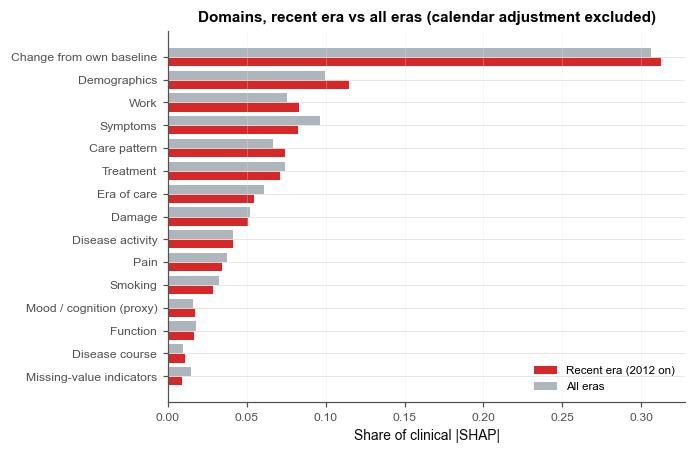

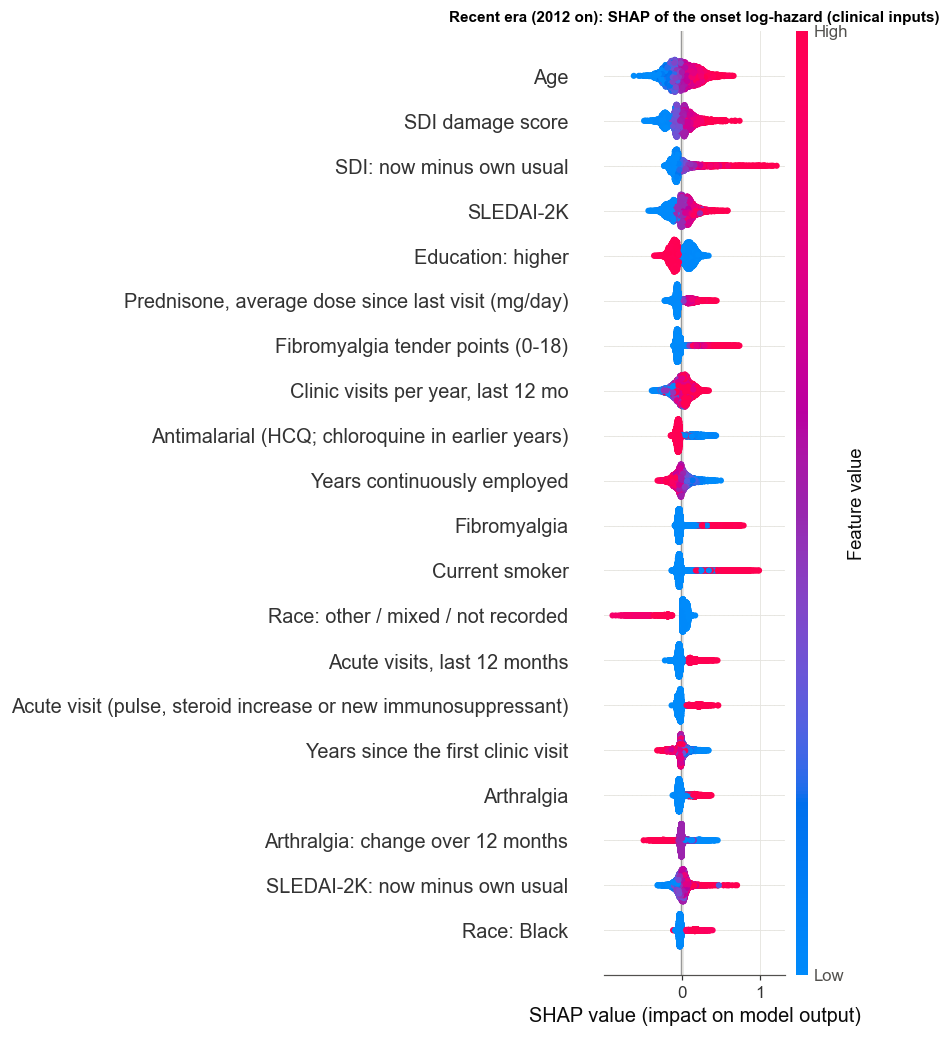

,Change from own baseline,Demographics,Work,Symptoms,Care pattern,Treatment,Era of care,Damage,Disease activity,Pain,Smoking,Mood / cognition (proxy),Function,Disease course,Missing-value indicators,"Total, clinical",Calendar adjustment,Landmarks
group,,,,,,,,,,,,,,,,,,
Onset in 36-48 mo,0.090,0.132,0.078,0.186,-0.016,0.059,0.016,0.081,0.030,0.053,0.018,0.023,-0.024,-0.002,-0.022,0.702,0.248,26
Onset in 24-36 mo,0.005,0.054,0.095,0.085,-0.058,0.000,-0.028,0.045,0.048,0.078,0.014,0.009,-0.020,0.014,-0.012,0.328,0.307,36
Onset in 12-24 mo,0.005,0.029,0.042,0.153,-0.052,-0.035,-0.006,-0.033,0.067,0.078,0.050,-0.022,-0.020,0.011,-0.015,0.252,0.173,38
Onset in 6-12 mo,0.179,0.045,0.035,0.270,-0.037,0.093,-0.023,0.028,0.069,0.137,0.076,0.016,-0.010,-0.010,-0.004,0.862,0.155,28
Onset in 0-6 mo,0.097,0.060,0.096,0.263,-0.014,0.031,0.010,0.061,0.078,0.061,0.142,0.020,-0.003,-0.018,0.001,0.886,0.202,28
Never: other,0.044,0.024,0.009,0.031,0.009,0.016,0.005,0.021,0.005,0.005,0.001,0.000,0.006,0.003,0.001,0.181,0.007,5319
Never: healthy-looking,-0.193,-0.053,0.001,-0.102,0.016,-0.087,-0.018,-0.200,-0.033,-0.034,-0.003,-0.025,-0.016,0.009,-0.001,-0.738,-0.011,975


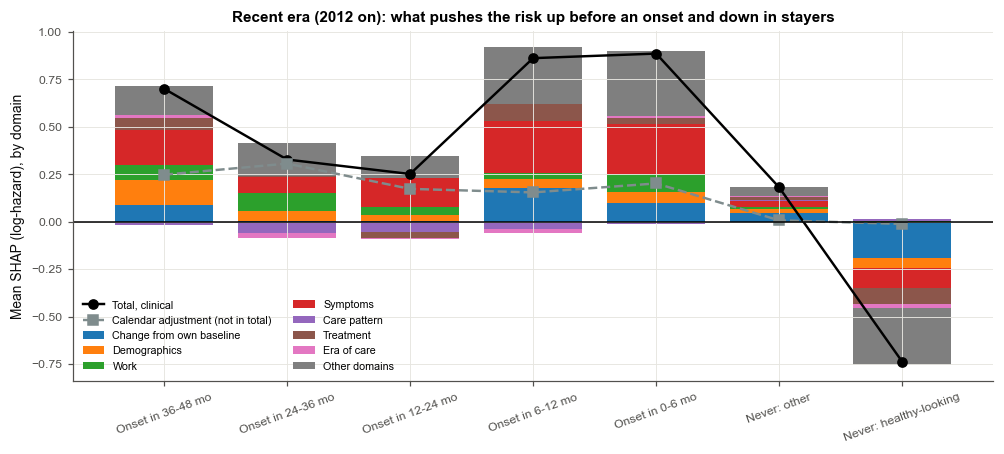

Recent era, rank correlation of the folds' importance vectors: median 0.77 (range 0.69 to 0.82)


In [107]:
"""SHAP in the recent era vs all eras."""
IMP_R = importance(SV_SUM_R)
print(cal_line(SV_SUM_R, f"recent era, {SHAP_RECENT_FROM} on"))
print(cal_line(SV_SUM, "all eras, for comparison"))
CMP = pd.DataFrame({"Input": IMP_R["Input"], "Domain": IMP_R["Domain"],
                    "Recent: rank": np.arange(1, len(IMP_R) + 1),
                    "Recent: share": IMP_R["Share of clinical total"],
                    "Recent: mean SHAP": IMP_R["Mean SHAP"],
                    "All eras: rank": IMP["Mean |SHAP|"].rank(ascending=False).reindex(IMP_R.index).astype(int),
                    "All eras: share": IMP["Share of clinical total"].reindex(IMP_R.index)})
display(CMP.head(25).round(3))
CMP.to_csv(f"objective4_shap_recent_vs_all_{TAG}.csv")
from scipy.stats import spearmanr
_rho_era = spearmanr(IMP_R["Mean |SHAP|"], IMP["Mean |SHAP|"].reindex(IMP_R.index)).correlation
_top10_overlap = len(set(IMP_R.index[:10]) & set(IMP.index[:10]))
print(f"Rank correlation, recent vs all eras (clinical inputs): {_rho_era:.2f}; top-10 overlap {_top10_overlap}/10")

DOMS_R = domain_shares(IMP_R)
_dcmp = pd.DataFrame({"Recent era": DOMS_R, "All eras": DOMS}).sort_values("Recent era", ascending=False)
display(_dcmp.round(3))
fig, ax = plt.subplots(figsize=(6.4, 4.2))
_y = np.arange(len(_dcmp))
ax.barh(_y + 0.2, _dcmp["Recent era"].values, 0.4, color="#d62828", label=f"Recent era ({SHAP_RECENT_FROM} on)")
ax.barh(_y - 0.2, _dcmp["All eras"].values, 0.4, color="#adb5bd", label="All eras")
ax.set_yticks(_y); ax.set_yticklabels(_dcmp.index); ax.invert_yaxis(); ax.set_xlabel("Share of clinical |SHAP|")
ax.legend(); ax.grid(axis="x", alpha=0.3); ax.set_title("Domains, recent era vs all eras (calendar adjustment excluded)")
plt.tight_layout(); save_fig("shap_domains_recent")

plt.figure()
shap.summary_plot(SV_SUM_R[:, CLIN], SX_R[:, -1, CLIN], feature_names=list(SH_DISPLAY[CLIN]), max_display=20,
                  show=False)
plt.title(f"Recent era ({SHAP_RECENT_FROM} on): SHAP of the onset log-hazard (clinical inputs)", fontsize=10)
plt.tight_layout(); save_fig("shap_beeswarm_recent")

BYGRP_R = shap_by_group(SH_ROWS_R, SV_SUM_R, DOMS_R)
display(BYGRP_R.round(3))
BYGRP_R.to_csv(f"objective4_shap_by_group_recent_{TAG}.csv")
plot_by_group(BYGRP_R, DOMS_R, f"Recent era ({SHAP_RECENT_FROM} on): what pushes the risk up before an onset and down "
              f"in stayers", "shap_by_group_recent")
STAB_R, _rho_r = stability(SV_SUM_R, SH_FOLD_R, IMP_R)
print(f"Recent era, rank correlation of the folds' importance vectors: median {np.median(_rho_r):.2f} "
      f"(range {_rho_r.min():.2f} to {_rho_r.max():.2f})")

## 16.7 Conclusion — Objective 4

In [108]:
"""Objective 4 conclusion."""
_near_tot = BYGRP.loc["Onset in 0-6 mo", "Total, clinical"]
_near_tot_r = BYGRP_R.loc["Onset in 0-6 mo", "Total, clinical"]
_chg_r = IMP_R.loc[IMP_R["Domain"] == "Change from own baseline", "Share of clinical total"].sum()
txt = ("Calendar year is treated as an adjustment, not a driver: it carries "
       f"{cal_share(SV_SUM):.0%} of all attribution across eras and {cal_share(SV_SUM_R):.0%} within the recent era "
       f"({SHAP_RECENT_FROM} on). Largest clinical inputs, all eras: " + ", ".join(
           f"{r_['Input']} ({r_['Share of clinical total']:.0%})" for _, r_ in IMP.head(8).iterrows())
       + f". Recent era: " + ", ".join(
           f"{r_['Input']} ({r_['Share of clinical total']:.0%})" for _, r_ in IMP_R.head(8).iterrows())
       + f" (rank correlation with all eras {_rho_era:.2f}, top-10 overlap {_top10_overlap}/10). Domains (all eras): "
       + ", ".join(f"{d} {v:.0%}" for d, v in DOMS.head(5).items()) + "; recent era: "
       + ", ".join(f"{d} {v:.0%}" for d, v in DOMS_R.head(5).items())
       + f". Change-from-own-baseline inputs carry {_chg:.0%} of the clinical attribution (recent era {_chg_r:.0%}); "
       f"the landmark grid point {TIME_SHARE.iloc[-1]:.0%}. Mean clinical SHAP: onset in 0-6 months {_near_tot:+.2f} "
       f"(recent era {_near_tot_r:+.2f}), healthy-looking stayers "
       f"{BYGRP.loc['Never: healthy-looking', 'Total, clinical']:+.2f} (recent era "
       f"{BYGRP_R.loc['Never: healthy-looking', 'Total, clinical']:+.2f}). Fold agreement (rank correlation) median "
       f"{np.median(_rho):.2f} (recent era {np.median(_rho_r):.2f}).")
OBJ_CONCLUSIONS["Objective 4"] = txt
print(textwrap.fill(txt, 118))

Calendar year is treated as an adjustment, not a driver: it carries 12% of all attribution across eras and 8% within
the recent era (2012 on). Largest clinical inputs, all eras: SDI damage score (5%), Age (5%), SLEDAI-2K (4%), SDI: now
minus own usual (4%), Antimalarial (HCQ; chloroquine in earlier years) (4%), Education: higher (4%), Prednisone,
average dose since last visit (mg/day) (4%), Fibromyalgia tender points (0-18) (4%). Recent era: Age (6%), SDI damage
score (5%), SDI: now minus own usual (4%), SLEDAI-2K (4%), Education: higher (4%), Prednisone, average dose since last
visit (mg/day) (3%), Fibromyalgia tender points (0-18) (3%), Clinic visits per year, last 12 mo (3%) (rank correlation
with all eras 0.98, top-10 overlap 9/10). Domains (all eras): Change from own baseline 31%, Demographics 10%, Symptoms
10%, Work 8%, Treatment 7%; recent era: Change from own baseline 31%, Demographics 11%, Work 8%, Symptoms 8%, Care
pattern 7%. Change-from-own-baseline inputs carry 31% of the 

---
# 17. Summary of the objectives

Every hypothesis with its estimate, 95 % CI and whether its criterion is met (H = objectives 1-3; S = secondary
analyses, Section 18). No hypothesis
gatekeeps another. Then the three conclusions.

In [109]:
"""Hypothesis table and conclusions."""
HYP = pd.DataFrame(HYP_ROWS)
HYP["Met"] = HYP["Met"].map({True: "yes", False: "no"})
if "Verdict" in HYP:
    HYP["Verdict"] = HYP["Verdict"].fillna("")
display(HYP.set_index("Hypothesis"))
HYP.to_csv(f"hypotheses_{TAG}.csv", index=False)
for k, v in OBJ_CONCLUSIONS.items():
    print(f"\n{k}:\n" + textwrap.fill(v, 118))

,Estimand,Estimate (95% CI),Criterion,Met,Verdict
Hypothesis,,,,,
H1a (primary),"DYN - Baseline, time-matched patient AUROC",0.155 (0.106 to 0.206),lower bound > 0 (equivalence +/-0.02),yes,superior
H1b,"DYN - LogReg, time-matched patient AUROC",0.011 (-0.007 to 0.031),lower bound > 0 (equivalence +/-0.02),no,inconclusive
H1d,"DYN - DYN-bands, time-matched patient AUROC",0.025 (0.008 to 0.042),lower bound > 0 (equivalence +/-0.02),yes,superior
H1c,Main: visit calibration slope / intercept,1.051 (0.868 to 1.261) / -0.011 (-0.195 to 0.170),"slope in [0.8, 1.2], intercept CI includes 0",yes,
H2a,Main: time-matched AUROC 0-24 minus 24-36 mont...,0.087 (0.041 to 0.134),lower bound > 0,yes,
H2b,Main: extra rise per year before onset vs neve...,0.089 (0.066 to 0.111),lower bound > 0,yes,
H2c,"Main: median lead time, flagged event patients...",18.1 (15.5 to 19.9),lower bound >= 3,yes,
H3a,"Main: share flagged, healthy-looking minus oth...",-0.292 (-0.318 to -0.264),upper bound < 0,yes,
H3b,"DYN - Baseline, time-matched AUROC vs healthy-...",0.155 (0.106 to 0.210),lower bound > 0,yes,superior



Objective 1:
Main model (DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [main]): time-matched
patient AUROC 0.735 (0.697 to 0.775) (Baseline 0.580 (0.529 to 0.633), LogReg 0.724 (0.684 to 0.764)). It flags 65% of
patients in the 24 months before their onset and 32% of the patients still working on the same dates. Visit AUROC (24
months) 0.727 (0.684 to 0.767); calibration slope 1.05, O/E 1.03. Hypotheses: H1a (primary) (DYN - Baseline, time-
matched patient AUROC) 0.155 (0.106 to 0.206): superior; H1b (DYN - LogReg, time-matched patient AUROC) 0.011 (-0.007
to 0.031): inconclusive; H1d (DYN - DYN-bands, time-matched patient AUROC) 0.025 (0.008 to 0.042): superior; H1c
(Main: visit calibration slope / intercept) 1.051 (0.868 to 1.261) / -0.011 (-0.195 to 0.170): met. Risk tiers (DYN):
the < 2 % tier covers 40% of visits with an observed 24-month risk of 0.011 (0.007 to 0.016) and misses 0.121 (0.075
to 0.172) of the onsets; the >= 10 % tier covers 4

---
# 18. Secondary analyses

Visit-level discrimination at every horizon; the design steps from the pooled 'trait' LSTM (S0) to the main model;
the evaluation rules compared; stability across calendar time; restricted risk sets. Hypotheses here are labelled S
and are secondary.

## 18.1 Every horizon from 6 to 48 months: visit and patient level

One fit gives the risk at every horizon (Section 11.6): each horizon has its own censoring-weighted label, its own
recalibration and its own thresholds inside the training folds. Patient level: windows of min(24, *h*) months
(Section 9.2). Left: AUROC by horizon, every model (main bold, 95 % band); right: the patient level.

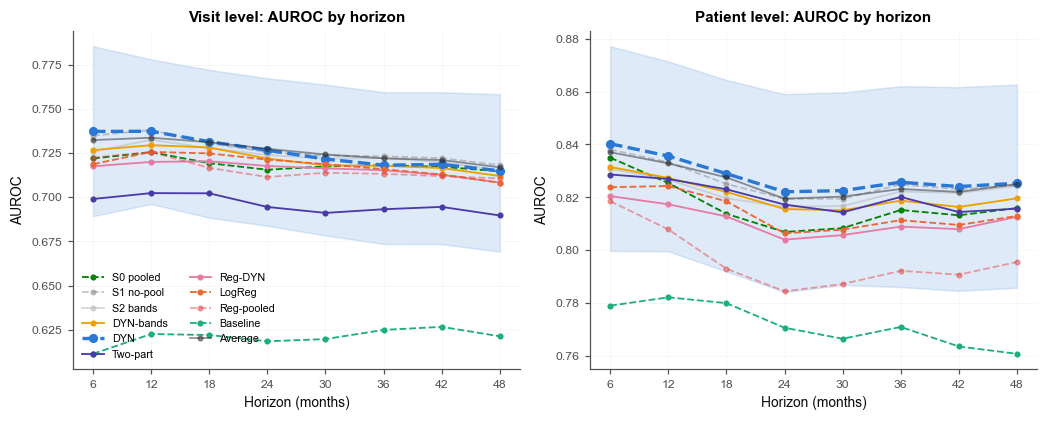

DYN: grid LSTM, last 2 years, current status + change from own baseline, one hazard [main]


,Landmarks (known status),Observed cumulative risk (IPCW),Patients / with onset,Visit AUROC,Patient AUROC,Visit calibration slope,Visit O/E,Visit sens / spec,Patient sens / spec,Patient PPV
Horizon (months),,,,,,,,,,
6,16836,0.008,986 / 110,0.737 (0.689 to 0.785),0.840 (0.800 to 0.877),1.05,1.04 (0.84 to 1.25),0.64 / 0.70,0.76 / 0.77,0.29
12,16180,0.018,970 / 131,0.737 (0.696 to 0.778),0.836 (0.800 to 0.871),1.06,1.04 (0.85 to 1.23),0.68 / 0.67,0.74 / 0.77,0.33
18,15619,0.027,943 / 136,0.731 (0.688 to 0.772),0.829 (0.792 to 0.864),1.05,1.03 (0.86 to 1.23),0.65 / 0.69,0.73 / 0.76,0.34
24,15179,0.035,904 / 136,0.727 (0.684 to 0.767),0.822 (0.784 to 0.859),1.05,1.03 (0.86 to 1.23),0.65 / 0.69,0.71 / 0.78,0.37
30,14796,0.042,877 / 135,0.722 (0.678 to 0.764),0.823 (0.787 to 0.860),1.04,1.03 (0.85 to 1.22),0.63 / 0.69,0.71 / 0.78,0.37
36,14471,0.048,854 / 132,0.718 (0.674 to 0.759),0.826 (0.786 to 0.862),1.04,1.02 (0.84 to 1.21),0.65 / 0.67,0.71 / 0.78,0.38
42,14122,0.054,830 / 131,0.718 (0.673 to 0.759),0.824 (0.785 to 0.862),1.04,1.01 (0.83 to 1.20),0.64 / 0.67,0.72 / 0.78,0.38
48,13609,0.061,801 / 130,0.715 (0.669 to 0.758),0.825 (0.786 to 0.863),1.05,1.00 (0.82 to 1.19),0.64 / 0.68,0.72 / 0.79,0.39


,Model,Level,6 mo,12 mo,18 mo,24 mo,30 mo,36 mo,42 mo,48 mo
0,S0 pooled,visit,0.722 (0.672 to 0.773),0.725 (0.683 to 0.770),0.719 (0.674 to 0.764),0.716 (0.667 to 0.761),0.717 (0.665 to 0.763),0.718 (0.668 to 0.765),0.717 (0.667 to 0.763),0.715 (0.663 to 0.762)
1,S1 no-pool,visit,0.735 (0.687 to 0.781),0.738 (0.695 to 0.780),0.730 (0.687 to 0.773),0.725 (0.680 to 0.770),0.724 (0.676 to 0.767),0.723 (0.674 to 0.767),0.722 (0.672 to 0.767),0.718 (0.667 to 0.765)
2,S2 bands,visit,0.726 (0.678 to 0.775),0.732 (0.690 to 0.777),0.728 (0.683 to 0.771),0.724 (0.679 to 0.769),0.722 (0.673 to 0.768),0.722 (0.673 to 0.769),0.720 (0.670 to 0.767),0.715 (0.664 to 0.764)
3,DYN-bands,visit,0.727 (0.679 to 0.775),0.729 (0.687 to 0.774),0.728 (0.685 to 0.772),0.722 (0.678 to 0.766),0.718 (0.671 to 0.764),0.718 (0.671 to 0.766),0.716 (0.668 to 0.764),0.712 (0.663 to 0.761)
4,DYN,visit,0.737 (0.689 to 0.785),0.737 (0.696 to 0.778),0.731 (0.688 to 0.772),0.727 (0.684 to 0.767),0.722 (0.678 to 0.764),0.718 (0.674 to 0.759),0.718 (0.673 to 0.759),0.715 (0.669 to 0.758)
5,Two-part,visit,0.699 (0.652 to 0.747),0.702 (0.657 to 0.748),0.702 (0.658 to 0.747),0.694 (0.650 to 0.742),0.691 (0.645 to 0.738),0.693 (0.647 to 0.742),0.694 (0.646 to 0.744),0.690 (0.640 to 0.741)
6,Reg-DYN,visit,0.717 (0.669 to 0.769),0.720 (0.677 to 0.765),0.720 (0.677 to 0.764),0.718 (0.674 to 0.761),0.716 (0.672 to 0.761),0.715 (0.671 to 0.761),0.713 (0.666 to 0.758),0.708 (0.659 to 0.757)
7,LogReg,visit,0.719 (0.670 to 0.769),0.726 (0.684 to 0.769),0.725 (0.682 to 0.765),0.721 (0.678 to 0.763),0.719 (0.676 to 0.762),0.716 (0.672 to 0.759),0.713 (0.666 to 0.758),0.708 (0.660 to 0.755)
8,Reg-pooled,visit,0.722 (0.671 to 0.774),0.726 (0.682 to 0.769),0.717 (0.671 to 0.760),0.711 (0.665 to 0.755),0.714 (0.663 to 0.760),0.713 (0.663 to 0.759),0.712 (0.663 to 0.758),0.711 (0.660 to 0.759)
9,Baseline,visit,0.611 (0.564 to 0.662),0.623 (0.575 to 0.672),0.622 (0.572 to 0.673),0.618 (0.565 to 0.672),0.620 (0.567 to 0.672),0.625 (0.570 to 0.678),0.627 (0.572 to 0.680),0.621 (0.566 to 0.676)


In [110]:
"""AUROC by horizon, every model; the main model's metrics by horizon."""
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
for ax, lev in zip(axes, ["visit", "patient"]):
    for m in MODELS_RUN:
        v = np.array([ci((m, lev, h, "auroc")) for h in HORIZONS])
        main = m == MAIN_MODEL
        ax.plot(HORIZONS, v[:, 0], "o-", color=model_color(m), ls=model_ls(m), lw=2.2 if main else 1.2,
                ms=5 if main else 3, label=short_label(m), alpha=1 if m in FIG_MODELS else 0.5)
        if main:
            ax.fill_between(HORIZONS, v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    ax.set_xticks(HORIZONS); ax.set_xlabel("Horizon (months)"); ax.set_ylabel("AUROC"); ax.grid(alpha=0.3)
    ax.set_title(f"{lev.capitalize()} level: AUROC by horizon")
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); save_fig("horizons_auroc")

rows = []
for h in HORIZONS:
    rows.append({"Horizon (months)": h, "Landmarks (known status)": len(IPCW_H[h][0]),
                 "Observed cumulative risk (IPCW)": round(CIF_IPCW[h], 3),
                 "Patients / with onset": f"{len(PTW[h]['pids'])} / {int(PTW[h]['event'].sum())}",
                 "Visit AUROC": fmtk((MAIN_MODEL, "visit", h, "auroc")),
                 "Patient AUROC": fmtk((MAIN_MODEL, "patient", h, "auroc")),
                 "Visit calibration slope": f"{ci((MAIN_MODEL, 'visit', h, 'cal_slope'))[0]:.2f}",
                 "Visit O/E": fmtk((MAIN_MODEL, "visit", h, "oe"), 2),
                 "Visit sens / spec": f"{ci((MAIN_MODEL, 'visit', h, MAIN_THRESHOLD, 'sensitivity'))[0]:.2f} / "
                                      f"{ci((MAIN_MODEL, 'visit', h, MAIN_THRESHOLD, 'specificity'))[0]:.2f}",
                 "Patient sens / spec": f"{ci((MAIN_MODEL, 'patient', h, MAIN_THRESHOLD, 'sensitivity'))[0]:.2f} / "
                                        f"{ci((MAIN_MODEL, 'patient', h, MAIN_THRESHOLD, 'specificity'))[0]:.2f}",
                 "Patient PPV": f"{ci((MAIN_MODEL, 'patient', h, MAIN_THRESHOLD, 'ppv'))[0]:.2f}"})
HORIZON_MAIN = pd.DataFrame(rows).set_index("Horizon (months)")
print(model_label(MAIN_MODEL))
display(HORIZON_MAIN)
HORIZON_MAIN.to_csv(f"objective2_horizons_main_{TAG}.csv")
HORIZON_ALL = pd.DataFrame([{"Model": short_label(m), "Level": lev,
                             **{f"{h} mo": fmtk((m, lev, h, "auroc")) for h in HORIZONS}}
                            for lev in ["visit", "patient"] for m in MODELS_RUN])
display(HORIZON_ALL)
HORIZON_ALL.to_csv(f"objective2_horizons_all_{TAG}.csv", index=False)

## 18.2 The comparators minus the main model, by horizon

Paired differences in AUROC at every horizon (95 % CI): where does the dynamic model gain or lose against each
alternative: at short or at long horizons?

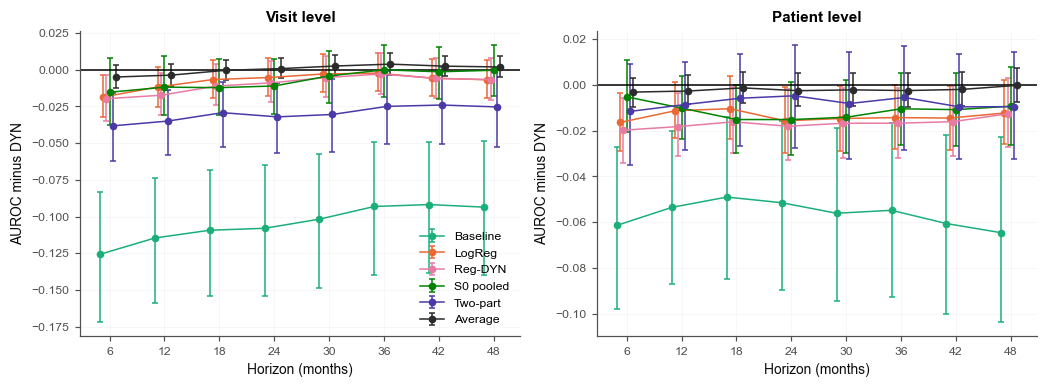

Horizon                                   6                          12                         18                         24                         30                         36  \
Level   Model                                                                                                                                                                         
patient Average     -0.003 (-0.010 to 0.003)   -0.003 (-0.009 to 0.004)   -0.001 (-0.008 to 0.005)   -0.003 (-0.009 to 0.005)   -0.002 (-0.009 to 0.005)   -0.003 (-0.010 to 0.005)   
        Baseline   -0.061 (-0.098 to -0.027)  -0.054 (-0.087 to -0.020)  -0.049 (-0.085 to -0.014)  -0.052 (-0.090 to -0.016)  -0.056 (-0.095 to -0.019)  -0.055 (-0.093 to -0.017)   
        LogReg     -0.016 (-0.029 to -0.004)   -0.011 (-0.023 to 0.001)   -0.010 (-0.024 to 0.004)  -0.016 (-0.030 to -0.001)  -0.015 (-0.029 to -0.000)   -0.014 (-0.028 to 0.000)   
        Reg-DYN    -0.020 (-0.034 to -0.006)  -0.018 (-0.031 to -0.003)  -0.016 (-0.030 to -0.001)  -0.018 (-0.033 to -0.002)  -0.017 (-0.032 to -0.002)  -0.017 (-0.032 to -0.002)   
        S0 pooled   -0.005 (-0.021 to 0.011)   -0.010 (-0.024 to 0.004)  -0.015 (-0.030 to -0.000)   -0.015 (-0.031 to 0.001)   -0.014 (-0.030 to 0.002)   -0.011 (-0.026 to 0.005)   
        Two-part    -0.012 (-0.035 to 0.009)   -0.009 (-0.028 to 0.010)   -0.006 (-0.027 to 0.014)   -0.005 (-0.028 to 0.017)   -0.008 (-0.033 to 0.014)   -0.006 (-0.029 to 0.017)   
visit   Average     -0.005 (-0.012 to 0.003)   -0.004 (-0.011 to 0.004)   -0.000 (-0.007 to 0.007)    0.001 (-0.006 to 0.008)    0.003 (-0.004 to 0.010)    0.004 (-0.003 to 0.011)   
        Baseline   -0.126 (-0.172 to -0.083)  -0.115 (-0.159 to -0.074)  -0.109 (-0.154 to -0.068)  -0.108 (-0.154 to -0.065)  -0.102 (-0.149 to -0.057)  -0.093 (-0.140 to -0.049)   
        LogReg     -0.019 (-0.032 to -0.004)   -0.012 (-0.025 to 0.002)   -0.007 (-0.019 to 0.007)   -0.005 (-0.018 to 0.008)   -0.003 (-0.015 to 0.011)   -0.002 (-0.014 to 0.011)   
        Reg-DYN    -0.020 (-0.035 to -0.004)  -0.017 (-0.031 to -0.002)   -0.011 (-0.024 to 0.004)   -0.009 (-0.022 to 0.006)   -0.005 (-0.019 to 0.009)   -0.003 (-0.017 to 0.012)   
        S0 pooled   -0.015 (-0.038 to 0.008)   -0.012 (-0.031 to 0.009)   -0.012 (-0.031 to 0.007)   -0.011 (-0.030 to 0.008)   -0.004 (-0.023 to 0.013)   -0.000 (-0.019 to 0.017)   
        Two-part   -0.038 (-0.062 to -0.016)  -0.035 (-0.058 to -0.013)  -0.029 (-0.053 to -0.008)  -0.032 (-0.057 to -0.009)  -0.030 (-0.056 to -0.007)  -0.025 (-0.051 to -0.001)   

Horizon                                   42                         48  
Level   Model                                                            
patient Average     -0.002 (-0.009 to 0.006)   -0.000 (-0.007 to 0.007)  
        Baseline   -0.061 (-0.100 to -0.022)  -0.065 (-0.104 to -0.023)  
        LogReg     -0.015 (-0.028 to -0.001)   -0.012 (-0.026 to 0.002)  
        Reg-DYN    -0.016 (-0.031 to -0.001)   -0.013 (-0.027 to 0.003)  
        S0 pooled   -0.011 (-0.027 to 0.005)   -0.009 (-0.026 to 0.008)  
        Two-part    -0.010 (-0.032 to 0.013)   -0.010 (-0.033 to 0.014)  
visit   Average      0.002 (-0.004 to 0.010)    0.002 (-0.005 to 0.009)  
        Baseline   -0.092 (-0.138 to -0.049)  -0.094 (-0.140 to -0.048)  
        LogReg      -0.006 (-0.018 to 0.008)   -0.007 (-0.019 to 0.006)  
        Reg-DYN     -0.006 (-0.019 to 0.008)   -0.007 (-0.020 to 0.008)  
        S0 pooled   -0.001 (-0.020 to 0.016)   -0.000 (-0.018 to 0.017)  
        Two-part    -0.024 (-0.051 to 0.002)   -0.025 (-0.052 to 0.000)

In [111]:
"""Differences from the main model by horizon."""
_cmp = [m for m in [BASELINE, LOGREG, REG_DYN, V8_MAIN, TWO_PART, AVG_MODEL] if m in MODELS_RUN]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
rows = []
for ax, lev in zip(axes, ["visit", "patient"]):
    for j, m in enumerate(_cmp):
        d = np.array([diff(m, MAIN_MODEL, (lev, h, "auroc"))[:3] for h in HORIZONS])
        xs = np.array(HORIZONS) + (j - len(_cmp) / 2) * 0.35
        ax.errorbar(xs, d[:, 0], yerr=[d[:, 0] - d[:, 1], d[:, 2] - d[:, 0]], fmt="o-", ms=4, capsize=2,
                    color=model_color(m), label=short_label(m), lw=1)
        rows += [{"Level": lev, "Model": short_label(m), "Horizon": h, "Difference (95% CI)": fmt(*d_)}
                 for h, d_ in zip(HORIZONS, d)]
    ax.axhline(0, color="k", lw=1); ax.set_xticks(HORIZONS); ax.set_xlabel("Horizon (months)")
    ax.set_ylabel(f"AUROC minus {short_label(MAIN_MODEL)}"); ax.set_title(f"{lev.capitalize()} level"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); save_fig("horizons_vs_main")
HOR_DIFF = pd.DataFrame(rows)
display(HOR_DIFF.pivot_table(index=["Level", "Model"], columns="Horizon", values="Difference (95% CI)", aggfunc="first"))
HOR_DIFF.to_csv(f"objective2_horizons_vs_main_{TAG}.csv", index=False)

## 18.3 Exclusive 12-month intervals (S3): is accuracy higher close to the visit than further ahead?

AUROC for an onset in months 0-12, 12-24, 24-36 and 36-48 **among the landmarks still at risk at the start of the
interval**, each with its own censoring-weighted label and recalibration. Unlike the cumulative horizons, the
intervals do not share onsets, so they show how accuracy changes with the time ahead. **S3**: the main model's
AUROC in months 0-12 minus months 36-48, lower 95 % bound > 0. Also the slope per year over the four intervals.

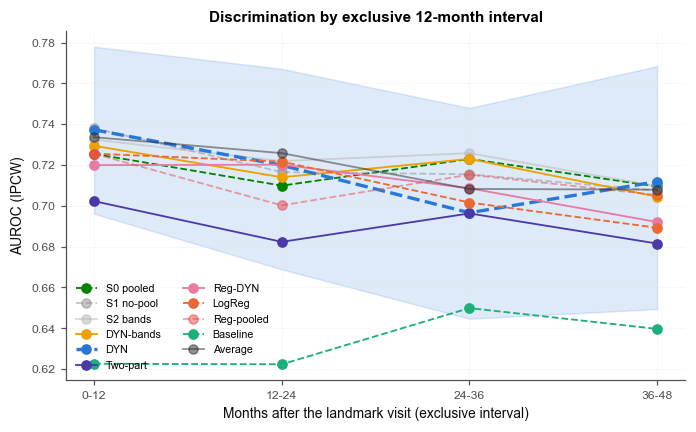

Landmarks at risk with a known status / onsets: 0-12 mo 16,180 / 301, 12-24 mo 14,502 / 263, 24-36 mo 13,218 / 193, 36-48 mo 11,885 / 182


,0-12 mo,12-24 mo,24-36 mo,36-48 mo,0-12 minus 36-48,Slope per year
Model,,,,,,
S0 pooled,0.725 (0.683 to 0.770),0.710 (0.656 to 0.760),0.723 (0.665 to 0.777),0.709 (0.644 to 0.769),0.016 (-0.034 to 0.068),-0.0035 (-0.0207 to 0.0136)
S1 no-pool,0.738 (0.695 to 0.780),0.717 (0.664 to 0.766),0.715 (0.658 to 0.769),0.707 (0.641 to 0.766),0.031 (-0.019 to 0.081),-0.0093 (-0.0259 to 0.0076)
S2 bands,0.732 (0.690 to 0.777),0.722 (0.670 to 0.770),0.726 (0.670 to 0.783),0.710 (0.649 to 0.768),0.023 (-0.024 to 0.074),-0.0065 (-0.0233 to 0.0104)
DYN-bands,0.729 (0.687 to 0.774),0.714 (0.662 to 0.764),0.723 (0.667 to 0.777),0.704 (0.643 to 0.761),0.025 (-0.024 to 0.077),-0.0066 (-0.0239 to 0.0105)
DYN,0.737 (0.696 to 0.778),0.720 (0.669 to 0.767),0.697 (0.645 to 0.748),0.712 (0.649 to 0.768),0.025 (-0.020 to 0.071),-0.0099 (-0.0262 to 0.0060)
Two-part,0.702 (0.657 to 0.748),0.682 (0.630 to 0.733),0.696 (0.639 to 0.751),0.682 (0.614 to 0.743),0.021 (-0.032 to 0.078),-0.0048 (-0.0251 to 0.0134)
Reg-DYN,0.720 (0.677 to 0.765),0.720 (0.672 to 0.768),0.709 (0.652 to 0.765),0.692 (0.625 to 0.757),0.028 (-0.024 to 0.083),-0.0095 (-0.0276 to 0.0085)
LogReg,0.726 (0.684 to 0.769),0.722 (0.674 to 0.769),0.702 (0.645 to 0.759),0.689 (0.621 to 0.753),0.036 (-0.019 to 0.092),-0.0129 (-0.0309 to 0.0057)
Reg-pooled,0.726 (0.682 to 0.769),0.700 (0.645 to 0.751),0.715 (0.658 to 0.771),0.705 (0.641 to 0.765),0.020 (-0.034 to 0.077),-0.0046 (-0.0229 to 0.0133)


In [112]:
"""Exclusive intervals; H2c."""
_x = np.array([(a + b) / 24 for a, b in INTERVALS])
rows = []
fig, ax = plt.subplots(figsize=(6.4, 4))
for m in MODELS_RUN:
    v = np.array([ci((m, "interval", iv, "auroc")) for iv in INTERVALS])
    main = m == MAIN_MODEL
    ax.plot(range(len(INTERVALS)), v[:, 0], "o-", color=model_color(m), ls=model_ls(m), lw=2.2 if main else 1.2,
            label=short_label(m), alpha=1 if m in FIG_MODELS else 0.5)
    if main:
        ax.fill_between(range(len(INTERVALS)), v[:, 1], v[:, 2], color=model_color(m), alpha=0.15)
    p0, b0 = STATS[(m, "interval", INTERVALS[0], "auroc")]
    p3, b3 = STATS[(m, "interval", INTERVALS[-1], "auroc")]
    dd = _diff_summary(p0 - p3, b0 - b3)
    xc = _x - _x.mean()
    pts = np.array([STATS[(m, "interval", iv, "auroc")][0] for iv in INTERVALS])
    bts = np.vstack([STATS[(m, "interval", iv, "auroc")][1] for iv in INTERVALS])
    sl = _diff_summary(float(xc @ pts / (xc @ xc)), xc @ bts / (xc @ xc))
    rows.append({"Model": short_label(m), **{f"{a}-{b} mo": fmt(*v_) for (a, b), v_ in zip(INTERVALS, v)},
                 "0-12 minus 36-48": fmt(*dd[:3]), "Slope per year": fmt(*sl[:3], nd=4)})
    if main:
        HYP_ROWS.append({"Hypothesis": "S3", "Estimand": "Main: AUROC months 0-12 minus 36-48",
                         "Estimate (95% CI)": fmt(*dd[:3]), "Criterion": "lower bound > 0", "Met": dd[1] > 0})
ax.set_xticks(range(len(INTERVALS))); ax.set_xticklabels([f"{a}-{b}" for a, b in INTERVALS])
ax.set_xlabel("Months after the landmark visit (exclusive interval)"); ax.set_ylabel("AUROC (IPCW)")
ax.set_title("Discrimination by exclusive 12-month interval"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); save_fig("intervals")
INTERVAL_TABLE = pd.DataFrame(rows).set_index("Model")
print("Landmarks at risk with a known status / onsets: " + ", ".join(
    f"{a}-{b} mo {len(IPCW_INT[(a, b)][0]):,} / {int(IPCW_INT[(a, b)][1].sum())}" for a, b in INTERVALS))
display(INTERVAL_TABLE)
INTERVAL_TABLE.to_csv(f"objective2_h2c_intervals_{TAG}.csv")

## 18.4 Cumulative horizons: every metric at 6 minus 48 months (main model, descriptive)

The cumulative horizons share onsets (every onset by 6 months is also an onset by 48 months), so this contrast is
descriptive; S3 (Section 18.3) is the test.

In [113]:
"""6 minus 48 months, main model."""
rows = []
for lev in ["visit", "patient"]:
    for lab_, key in [("AUROC", ("auroc",)), ("Sensitivity", (MAIN_THRESHOLD, "sensitivity")),
                      ("Specificity", (MAIN_THRESHOLD, "specificity")), ("PPV", (MAIN_THRESHOLD, "ppv")),
                      ("Balanced accuracy", (MAIN_THRESHOLD, "balanced_accuracy"))]:
        k6, k48 = (MAIN_MODEL, lev, HORIZONS[0]) + key, (MAIN_MODEL, lev, HORIZONS[-1]) + key
        d = _diff_summary(STATS[k6][0] - STATS[k48][0], STATS[k6][1] - STATS[k48][1])
        rows.append({"Level": lev, "Metric": lab_, f"{HORIZONS[0]} months": fmtk(k6), f"{HORIZONS[-1]} months": fmtk(k48),
                     "Difference (95% CI)": fmt(*d[:3])})
CUM = pd.DataFrame(rows)
display(CUM)
CUM.to_csv(f"objective2_cumulative_6_48_{TAG}.csv", index=False)

,Level,Metric,6 months,48 months,Difference (95% CI)
0,visit,AUROC,0.737 (0.689 to 0.785),0.715 (0.669 to 0.758),0.022 (-0.012 to 0.062)
1,visit,Sensitivity,0.638 (0.553 to 0.720),0.636 (0.568 to 0.705),0.002 (-0.062 to 0.067)
2,visit,Specificity,0.704 (0.681 to 0.728),0.677 (0.650 to 0.704),0.028 (0.018 to 0.037)
3,visit,PPV,0.017 (0.014 to 0.022),0.114 (0.091 to 0.138),-0.096 (-0.118 to -0.076)
4,visit,Balanced accuracy,0.671 (0.630 to 0.712),0.656 (0.620 to 0.693),0.015 (-0.018 to 0.048)
5,patient,AUROC,0.840 (0.800 to 0.877),0.825 (0.786 to 0.863),0.015 (-0.010 to 0.038)
6,patient,Sensitivity,0.756 (0.685 to 0.825),0.715 (0.649 to 0.788),0.041 (-0.014 to 0.096)
7,patient,Specificity,0.769 (0.743 to 0.794),0.787 (0.759 to 0.814),-0.018 (-0.042 to 0.005)
8,patient,PPV,0.292 (0.240 to 0.343),0.395 (0.334 to 0.453),-0.103 (-0.142 to -0.068)
9,patient,Balanced accuracy,0.763 (0.726 to 0.799),0.751 (0.714 to 0.789),0.012 (-0.018 to 0.040)


## 18.5 The design steps: the dynamic LSTM against the pooled 'trait' LSTM (S1)

**S1**: the dynamic LSTM (no pooling, 2 years of history, change from the patient's own baseline) discriminates the
**24-month** risk at the visit level better than S0 (all history, current status only, scores pooled over 24
months, so it describes a stable patient-level risk). Estimand: DYN − S0, visit AUROC at 24 months (IPCW, every
landmark with a known 24-month status). Verdict: **superior** if the lower 95 % bound > 0; **inferior** if the upper bound < 0;
**equivalent** if the CI lies within ±0.02; otherwise **inconclusive**. Secondary: the same contrast on the 6- and
12-month visit AUROC, the risk-set C and the patient-window AUROC. The difference in each CV repeat is shown.

In [114]:
"""Primary test."""


def repeat_diffs(a, b, key=K_VIS):
    """Point estimate of a - b in each CV repeat (visit AUROC at a horizon, or patient AUROC)."""
    out = []
    for r in REPEATS:
        if key[0] == "visit" and key[-1] == "auroc":
            rows, y, w = IPCW_H[key[1]]
            f_ = lambda m: wauc(y, zpred(m, r, key[1])[rows], (_BOTH[:1, ROW_PIDX[rows]] * w[None, :]))[0]
        elif key == K_PT:
            f_ = lambda m: wauc(PTW[H]["event"], patient_z(m, r), _BOTH[:1, PTW_PIDX[H]])[0]
        else:
            return []
        out.append(f_(a) - f_(b))
    return out


PRIM_KEYS = [(f"Visit AUROC, {H} months (primary)", K_VIS), ("Visit AUROC, 6 months", ("visit", 6, "auroc")),
             ("Visit AUROC, 12 months", ("visit", 12, "auroc")), ("Risk-set C", K_RS),
             ("Patient AUROC (windows)", K_PT)]
PRIMARY_S = []
for lab_, key in PRIM_KEYS:
    d = diff(MAIN_MODEL, V8_MAIN, key)
    rd = repeat_diffs(MAIN_MODEL, V8_MAIN, key)
    PRIMARY_S.append({"Metric": lab_, short_label(MAIN_MODEL): fmtk((MAIN_MODEL,) + key),
                    short_label(V8_MAIN): fmtk((V8_MAIN,) + key), "Difference (95% CI)": fmt(*d[:3]),
                    "p (bootstrap)": round(d[3], 3), "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN),
                    "Per repeat": ", ".join(f"{x:+.3f}" for x in rd) if rd else "-"})
PRIMARY_S = pd.DataFrame(PRIMARY_S).set_index("Metric")
display(PRIMARY_S)
PRIMARY_S.to_csv(f"secondary_design_steps_{TAG}.csv")
_d = diff(MAIN_MODEL, V8_MAIN, K_VIS)
HYP_ROWS.append({"Hypothesis": "S1", "Estimand": f"DYN - S0 pooled, visit AUROC {H} months",
                    "Estimate (95% CI)": fmt(*_d[:3]), "Criterion": "lower bound > 0 (equivalence +/-0.02)",
                    "Met": _d[1] > 0, "Verdict": verdict_superiority(_d[1], _d[2], EQUIV_MARGIN)})

,DYN,S0 pooled,Difference (95% CI),p (bootstrap),Verdict,Per repeat
Metric,,,,,,
"Visit AUROC, 24 months (primary)",0.727 (0.684 to 0.767),0.716 (0.667 to 0.761),0.011 (-0.008 to 0.030),0.262,inconclusive,"+0.011, +0.014, +0.006, +0.002, +0.022"
"Visit AUROC, 6 months",0.737 (0.689 to 0.785),0.722 (0.672 to 0.773),0.015 (-0.008 to 0.038),0.194,inconclusive,"+0.010, +0.020, +0.012, +0.004, +0.030"
"Visit AUROC, 12 months",0.737 (0.696 to 0.778),0.725 (0.683 to 0.770),0.012 (-0.009 to 0.031),0.270,inconclusive,"+0.014, +0.015, +0.006, +0.002, +0.021"
Risk-set C,0.748 (0.709 to 0.788),0.726 (0.686 to 0.768),0.022 (-0.005 to 0.047),0.096,inconclusive,-
Patient AUROC (windows),0.822 (0.784 to 0.859),0.807 (0.767 to 0.845),0.015 (-0.001 to 0.031),0.066,inconclusive,"+0.012, +0.020, +0.010, +0.013, +0.022"


## 18.6 One change at a time (S2), and the alternatives

| Pair | What it isolates |
|---|---|
| S1 − S0 | removing the 24-month pool (each visit's own score) and reading 2 years of grid instead of all history |
| DYN − S1 | the change-from-own-baseline inputs (one hazard; the main model) |
| S2 − S1 | a hazard per 6-month band (near-term risk can differ from long-term) |
| DYN-bands − S2 | the change-from-own-baseline inputs (band hazards) |
| DYN-bands − DYN | the bands, with the change inputs |
| Two-part − DYN | separating the trait (fixed Baseline offset) from the change (LSTM on change only) |
| DYN − Reg-DYN | the network, on the same inputs and target |
| Reg-DYN − Reg-pooled | the dynamic design in a regression (vs a pooled regression with last-year summaries) |
| Average − DYN | combining the LSTM and the regression |

Criterion: lower 95 % bound > 0 per metric; equivalence (±0.02) reported. Secondary to the primary test.

Metric,Visit AUROC 24 mo,Visit AUROC 6 mo,Risk-set C,Patient AUROC,Visit AUROC 12 mo
Comparison,,,,,
S1 no-pool - S0 pooled,0.010 (-0.002 to 0.023),0.013 (-0.005 to 0.030),0.016 (-0.001 to 0.033),0.013 (0.002 to 0.023),0.013 (-0.002 to 0.027)
DYN - S1 no-pool,0.001 (-0.011 to 0.013),0.002 (-0.010 to 0.014),0.006 (-0.012 to 0.023),0.003 (-0.009 to 0.014),-0.001 (-0.012 to 0.012)
S2 bands - S1 no-pool,-0.002 (-0.016 to 0.013),-0.009 (-0.020 to 0.002),-0.023 (-0.037 to -0.008),-0.003 (-0.016 to 0.010),-0.006 (-0.015 to 0.004)
DYN-bands - S2 bands,-0.002 (-0.014 to 0.010),0.001 (-0.011 to 0.012),0.006 (-0.009 to 0.021),-0.001 (-0.010 to 0.009),-0.003 (-0.017 to 0.010)
DYN-bands - DYN,-0.005 (-0.020 to 0.011),-0.011 (-0.022 to 0.001),-0.023 (-0.039 to -0.006),-0.007 (-0.021 to 0.007),-0.008 (-0.020 to 0.004)
Two-part - DYN,-0.032 (-0.057 to -0.009),-0.038 (-0.062 to -0.016),-0.050 (-0.078 to -0.024),-0.005 (-0.028 to 0.017),-0.035 (-0.058 to -0.013)
DYN - Reg-DYN,0.009 (-0.006 to 0.022),0.020 (0.004 to 0.035),0.024 (0.005 to 0.045),0.018 (0.002 to 0.033),0.017 (0.002 to 0.031)
Reg-DYN - Reg-pooled,0.006 (-0.015 to 0.027),-0.005 (-0.032 to 0.022),-0.009 (-0.037 to 0.017),0.020 (-0.000 to 0.037),-0.006 (-0.031 to 0.018)
Average - DYN,0.001 (-0.006 to 0.008),-0.005 (-0.012 to 0.003),-0.006 (-0.015 to 0.004),-0.003 (-0.009 to 0.005),-0.004 (-0.011 to 0.004)


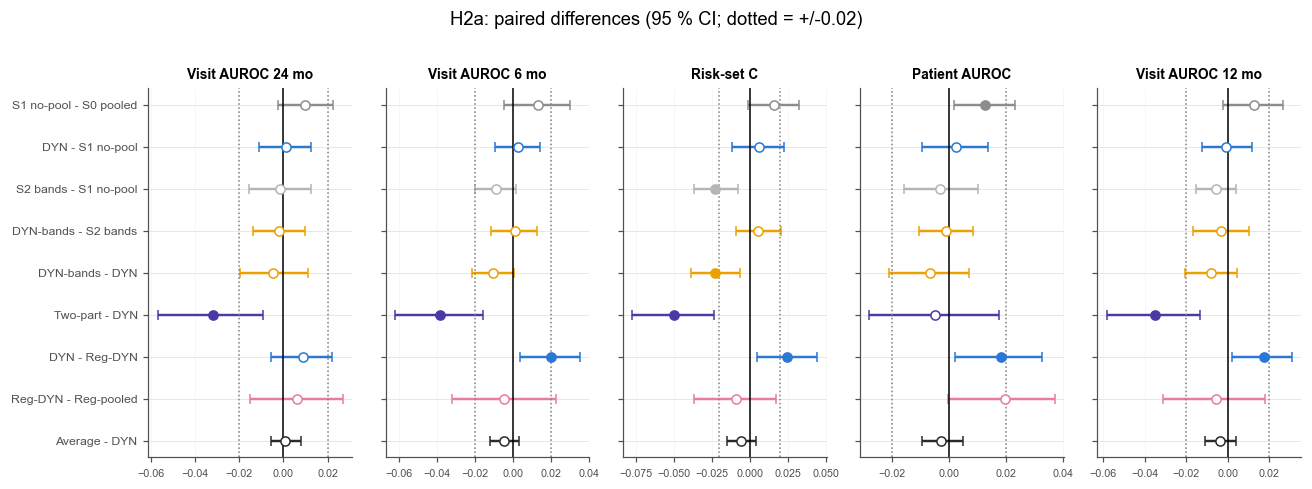

In [115]:
"""H2a pairs."""
H2A_PAIRS = [("S1_P0", V8_MAIN), (MAIN_MODEL, "S1_P0"), ("S2_BAND", "S1_P0"), (DYN_BANDS, "S2_BAND"),
             (DYN_BANDS, MAIN_MODEL), (TWO_PART, MAIN_MODEL),
             (MAIN_MODEL, REG_DYN), (REG_DYN, REG_MODEL), (AVG_MODEL, MAIN_MODEL)]
CMP_KEYS = [(f"Visit AUROC {H} mo", K_VIS), ("Visit AUROC 6 mo", ("visit", 6, "auroc")), ("Risk-set C", K_RS),
            ("Patient AUROC", K_PT), ("Visit AUROC 12 mo", ("visit", 12, "auroc"))]
H2A = compare(H2A_PAIRS, keys=CMP_KEYS)
H2A["Equivalent (+/-0.02)"] = (H2A["Lower"] > -EQUIV_MARGIN) & (H2A["Upper"] < EQUIV_MARGIN)
show_cmp(H2A)
H2A.to_csv(f"objective2_h2a_{TAG}.csv", index=False)
_col = {f"{short_label(a)} - {short_label(b)}": model_color(a) for a, b in H2A_PAIRS}
forest(H2A, "Comparison", [k for k, _ in CMP_KEYS], "H2a: paired differences (95 % CI; dotted = +/-0.02)", "h2a",
       color_of=_col.get, margin=EQUIV_MARGIN)
for a, b in H2A_PAIRS:
    d = diff(a, b, K_VIS)
    HYP_ROWS.append({"Hypothesis": "S2", "Estimand": f"{short_label(a)} - {short_label(b)}, visit AUROC {H} months",
                     "Estimate (95% CI)": fmt(*d[:3]), "Criterion": "lower bound > 0", "Met": d[1] > 0,
                     "Verdict": verdict_superiority(d[1], d[2], EQUIV_MARGIN)})

## 18.7 The evaluation rules side by side

Every model under each way of scoring it:

| Rule | Question it answers | Comparison made on |
|---|---|---|
| **E0: patient windows** (Section 9) | do the patients who go on to an onset score higher? | 24 months before onset vs the last 24 months of event-free follow-up (different calendar times) |
| **E1: risk-set C** (incident case / dynamic control) | on the date of each onset, does that patient score higher than everyone else at risk that day? | same date |
| **E2: time-dependent visit AUROC** (cumulative case / dynamic control, IPCW) at 6, 12 and 24 months | at a visit, does the risk separate onsets in the next *h* months from the rest? | every visit (primary: 24 months) |
| **E3: prospective alarms** | if the model ran in the clinic, how many onsets get an alarm in the 24 months before, how many alarms are true, how many alarms per patient-year? | every assessment (Section 14.3; at every visit, level rule) |
| Within-patient C | does a patient's risk rise before their onset? | the same patient, near vs far from onset |

Then: how well the rules agree across models (rank correlation), and whether the main conclusion (DYN − S0) changes
with the rule.

,E0 patient windows,E0b time-matched patient AUROC,E1 risk-set C,E2 visit AUROC 6 mo,E2 visit AUROC 12 mo,E2 visit AUROC 24 mo,Within-patient C,E3 onsets alarmed (level),E3 alarm PPV (level),E3 alarms / patient-year (level),E3 onsets alarmed (level or rise),E3 alarm PPV (level or rise)
Model,,,,,,,,,,,,
S0 pooled,0.807 (0.767 to 0.845),0.711 (0.670 to 0.754),0.726 (0.686 to 0.768),0.722 (0.672 to 0.773),0.725 (0.683 to 0.770),0.716 (0.667 to 0.761),0.608 (0.529 to 0.684),0.61,0.074,0.60,0.74,0.058
S1 no-pool,0.819 (0.782 to 0.857),0.728 (0.688 to 0.768),0.743 (0.703 to 0.785),0.735 (0.687 to 0.781),0.738 (0.695 to 0.780),0.725 (0.680 to 0.770),0.614 (0.542 to 0.678),0.68,0.074,0.63,0.77,0.064
S2 bands,0.816 (0.777 to 0.853),0.708 (0.666 to 0.751),0.720 (0.679 to 0.764),0.726 (0.678 to 0.775),0.732 (0.690 to 0.777),0.724 (0.679 to 0.769),0.630 (0.559 to 0.694),0.66,0.072,0.63,0.76,0.061
DYN-bands,0.816 (0.778 to 0.853),0.710 (0.671 to 0.752),0.725 (0.685 to 0.766),0.727 (0.679 to 0.775),0.729 (0.687 to 0.774),0.722 (0.678 to 0.766),0.645 (0.577 to 0.708),0.68,0.072,0.63,0.79,0.063
DYN,0.822 (0.784 to 0.859),0.735 (0.697 to 0.775),0.748 (0.709 to 0.788),0.737 (0.689 to 0.785),0.737 (0.696 to 0.778),0.727 (0.684 to 0.767),0.634 (0.570 to 0.699),0.70,0.075,0.61,0.78,0.063
Two-part,0.817 (0.782 to 0.853),0.688 (0.646 to 0.733),0.699 (0.660 to 0.742),0.699 (0.652 to 0.747),0.702 (0.657 to 0.748),0.694 (0.650 to 0.742),0.584 (0.513 to 0.656),0.68,0.065,0.70,0.79,0.057
Reg-DYN,0.804 (0.765 to 0.843),0.720 (0.679 to 0.764),0.724 (0.681 to 0.766),0.717 (0.669 to 0.769),0.720 (0.677 to 0.765),0.718 (0.674 to 0.761),0.622 (0.555 to 0.689),0.69,0.071,0.64,0.77,0.062
LogReg,0.806 (0.769 to 0.846),0.724 (0.684 to 0.764),0.725 (0.685 to 0.766),0.719 (0.670 to 0.769),0.726 (0.684 to 0.769),0.721 (0.678 to 0.763),0.618 (0.549 to 0.683),0.68,0.073,0.60,0.77,0.062
Reg-pooled,0.784 (0.741 to 0.825),0.714 (0.671 to 0.756),0.733 (0.692 to 0.775),0.722 (0.671 to 0.774),0.726 (0.682 to 0.769),0.711 (0.665 to 0.755),0.585 (0.503 to 0.665),0.65,0.073,0.64,0.77,0.057


Rank correlation across models between the rules (Spearman):


,E0 patient windows,E0b time-matched patient AUROC,E1 risk-set C,E2 visit AUROC 6 mo,E2 visit AUROC 12 mo,E2 visit AUROC 24 mo,Within-patient C,E3 onsets alarmed,E3 alarm PPV
E0 patient windows,1.00,0.53,0.57,0.74,0.74,0.77,0.53,0.42,0.59
E0b time-matched patient AUROC,0.53,1.00,0.86,0.70,0.72,0.75,0.51,0.49,0.83
E1 risk-set C,0.57,0.86,1.00,0.85,0.76,0.71,0.48,0.25,0.92
E2 visit AUROC 6 mo,0.74,0.70,0.85,1.00,0.95,0.88,0.68,0.32,0.76
E2 visit AUROC 12 mo,0.74,0.72,0.76,0.95,1.00,0.93,0.66,0.33,0.73
E2 visit AUROC 24 mo,0.77,0.75,0.71,0.88,0.93,1.00,0.83,0.44,0.73
Within-patient C,0.53,0.51,0.48,0.68,0.66,0.83,1.00,0.58,0.48
E3 onsets alarmed,0.42,0.49,0.25,0.32,0.33,0.44,0.58,1.00,0.14
E3 alarm PPV,0.59,0.83,0.92,0.76,0.73,0.73,0.48,0.14,1.00


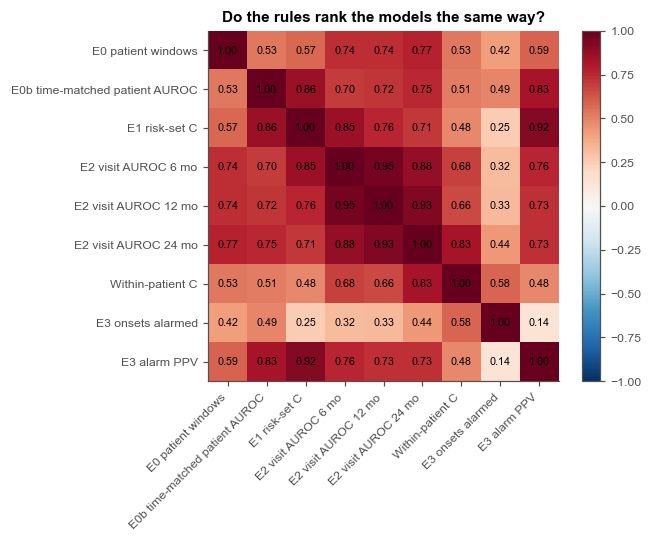

In [116]:
"""Every model under every evaluation rule."""
_al = ALARMS[(ALARMS["Re-assessment"] == "visit") & (ALARMS["Alarm rule"] == "level")].set_index("Model")
_alr = ALARMS[(ALARMS["Re-assessment"] == "visit") & (ALARMS["Alarm rule"] == "level_or_rise")].set_index("Model")
FRAME_KEYS = [("E0 patient windows", K_PT), ("E0b time-matched patient AUROC", K_TM), ("E1 risk-set C", K_RS), ("E2 visit AUROC 6 mo", ("visit", 6, "auroc")),
              ("E2 visit AUROC 12 mo", ("visit", 12, "auroc")), (f"E2 visit AUROC {H} mo", K_VIS),
              ("Within-patient C", ("within", H, "c"))]
rows, num = [], []
for m in MODELS_RUN:
    row = {"Model": short_label(m), **{lab_: fmtk((m,) + k) for lab_, k in FRAME_KEYS}}
    a_, b_ = _al.loc[short_label(m)], _alr.loc[short_label(m)]
    row.update({"E3 onsets alarmed (level)": f"{a_['Onsets with an alarm in the 24 months before']:.2f}",
                "E3 alarm PPV (level)": f"{a_['PPV of an alarm (onset within 24 months)']:.3f}",
                "E3 alarms / patient-year (level)": f"{a_['Alarms per patient-year']:.2f}",
                "E3 onsets alarmed (level or rise)": f"{b_['Onsets with an alarm in the 24 months before']:.2f}",
                "E3 alarm PPV (level or rise)": f"{b_['PPV of an alarm (onset within 24 months)']:.3f}"})
    rows.append(row)
    num.append({"Model": short_label(m), **{lab_: ci((m,) + k)[0] for lab_, k in FRAME_KEYS},
                "E3 onsets alarmed": a_["Onsets with an alarm in the 24 months before"],
                "E3 alarm PPV": a_["PPV of an alarm (onset within 24 months)"]})
FRAMES = pd.DataFrame(rows).set_index("Model")
display(FRAMES)
FRAMES.to_csv(f"objective3_evaluation_rules_{TAG}.csv")
NUM = pd.DataFrame(num).set_index("Model")
RHO = NUM.corr(method="spearman")
print("Rank correlation across models between the rules (Spearman):")
display(RHO.round(2))
RHO.to_csv(f"objective3_rule_agreement_{TAG}.csv")
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(RHO.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(RHO))); ax.set_xticklabels(RHO.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(RHO))); ax.set_yticklabels(RHO.index, fontsize=8)
for i in range(len(RHO)):
    for j in range(len(RHO)):
        ax.text(j, i, f"{RHO.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Do the rules rank the models the same way?")
plt.tight_layout(); save_fig("rule_agreement")

## 18.8 Does the rule change the conclusion?

The key contrasts under every rule with a bootstrap CI: DYN − Baseline (primary), DYN − LogReg (secondary),
DYN − S0 (the pooled 'trait' LSTM) and DYN − Reg-DYN.

In [117]:
"""Key contrasts under every rule."""
rows = []
for a, b in [(MAIN_MODEL, BASELINE), (MAIN_MODEL, LOGREG), (MAIN_MODEL, V8_MAIN), (MAIN_MODEL, REG_DYN)]:
    if a not in MODELS_RUN or b not in MODELS_RUN:
        continue
    row = {"Contrast": f"{short_label(a)} - {short_label(b)}"}
    for lab_, k in FRAME_KEYS:
        d = diff(a, b, k)
        row[lab_] = f"{fmt(*d[:3])} {verdict_superiority(d[1], d[2], EQUIV_MARGIN)[:5]}"
    rows.append(row)
RULE_CMP = pd.DataFrame(rows).set_index("Contrast")
display(RULE_CMP.T)
RULE_CMP.to_csv(f"objective3_contrasts_by_rule_{TAG}.csv")

Contrast,DYN - Baseline,DYN - LogReg,DYN - S0 pooled,DYN - Reg-DYN
E0 patient windows,0.052 (0.016 to 0.090) super,0.016 (0.001 to 0.030) super,0.015 (-0.001 to 0.031) incon,0.018 (0.002 to 0.033) super
E0b time-matched patient AUROC,0.155 (0.106 to 0.206) super,0.011 (-0.007 to 0.031) incon,0.024 (0.002 to 0.047) super,0.015 (-0.004 to 0.033) incon
E1 risk-set C,0.166 (0.114 to 0.218) super,0.024 (0.006 to 0.042) super,0.022 (-0.005 to 0.047) incon,0.024 (0.005 to 0.045) super
E2 visit AUROC 6 mo,0.126 (0.083 to 0.172) super,0.019 (0.004 to 0.032) super,0.015 (-0.008 to 0.038) incon,0.020 (0.004 to 0.035) super
E2 visit AUROC 12 mo,0.115 (0.074 to 0.159) super,0.012 (-0.002 to 0.025) incon,0.012 (-0.009 to 0.031) incon,0.017 (0.002 to 0.031) super
E2 visit AUROC 24 mo,0.108 (0.065 to 0.154) super,0.005 (-0.008 to 0.018) equiv,0.011 (-0.008 to 0.030) incon,0.009 (-0.006 to 0.022) incon
Within-patient C,0.214 (0.129 to 0.305) super,0.016 (-0.018 to 0.048) incon,0.026 (-0.028 to 0.078) incon,0.012 (-0.023 to 0.048) incon


## 18.9 Is discrimination stable across calendar time?

Visit AUROC (24 months, IPCW) of the main model, the Baseline and LogReg in overlapping 4-year windows of
landmark dates (step 1 year; windows with ≥ 10 onsets), from the same CV predictions, against each model's overall
AUROC. With many overlapping windows and few onsets in each, some windows fall outside the overall value by chance
alone: the share of windows whose 95 % CI excludes the overall AUROC shows how much a single window can be trusted.
Not a temporal validation (every model was trained on every era).

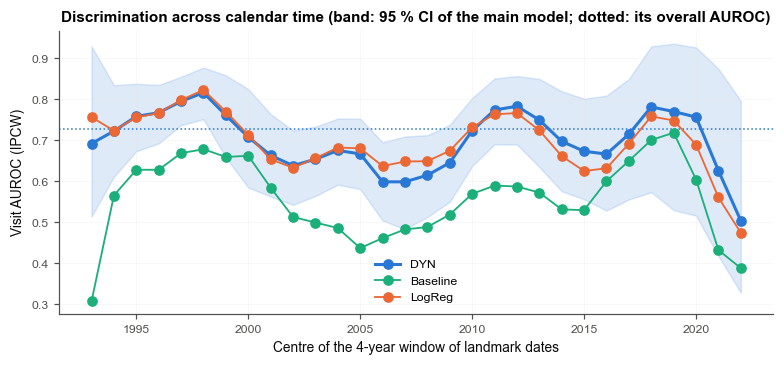

,windows,below,above,lowest,highest
Model,,,,,
Baseline,30,0.167,0.000,0.307,0.718
DYN,30,0.133,0.067,0.504,0.816
LogReg,30,0.067,0.067,0.474,0.823


In [118]:
"""Discrimination in rolling calendar windows."""
_yr_l = land["CAL_YEAR"].values
_y0, _y1 = int(np.floor(_yr_l[ROWS_IPCW].min())), int(np.ceil(_yr_l[ROWS_IPCW].max()))
_wins = [(a, a + CAL_WINDOW_YEARS) for a in range(_y0, _y1 - CAL_WINDOW_YEARS + 1, CAL_WINDOW_STEP)]
rows = []
for m in [m for m in KEY_MODELS if m in MODELS_RUN]:
    overall = ci((m,) + K_VIS)[0]
    for a, b in _wins:
        k = (_yr_l[ROWS_IPCW] >= a) & (_yr_l[ROWS_IPCW] < b)
        if Y_IPCW[k].sum() < CAL_WINDOW_MIN_ONSETS:
            continue
        rr = ROWS_IPCW[k]
        Wr = _BOTH[:, ROW_PIDX[rr]] * WI_IPCW[k][None, :]
        v = np.mean([wauc(Y_IPCW[k], zpred(m, r)[rr], Wr) for r in REPEATS], 0)
        lo, hi = np.nanpercentile(v[1:], [2.5, 97.5])
        rows.append({"Model": short_label(m), "Window": f"{a}-{b - 1}", "Start": a, "Landmarks": int(k.sum()),
                     "Onsets": int(Y_IPCW[k].sum()), "AUROC": v[0], "Lower": lo, "Upper": hi, "Overall": overall,
                     "CI below overall": hi < overall, "CI above overall": lo > overall})
CALWIN = pd.DataFrame(rows)
CALWIN.to_csv(f"objective1_calendar_windows_{TAG}.csv", index=False)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for m in KEY_MODELS:
    d = CALWIN[CALWIN["Model"] == short_label(m)]
    if len(d):
        x = d["Start"] + CAL_WINDOW_YEARS / 2
        ax.plot(x, d["AUROC"], "o-", color=model_color(m), lw=2 if m == MAIN_MODEL else 1.2, label=short_label(m))
        if m == MAIN_MODEL:
            ax.fill_between(x, d["Lower"], d["Upper"], color=model_color(m), alpha=0.15)
            ax.axhline(d["Overall"].iloc[0], color=model_color(m), ls=":", lw=1)
ax.set_xlabel(f"Centre of the {CAL_WINDOW_YEARS}-year window of landmark dates"); ax.set_ylabel("Visit AUROC (IPCW)")
ax.set_title("Discrimination across calendar time (band: 95 % CI of the main model; dotted: its overall AUROC)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("calendar_windows")
_s = CALWIN.groupby("Model").agg(windows=("Window", "size"), below=("CI below overall", "mean"),
                                 above=("CI above overall", "mean"), lowest=("AUROC", "min"), highest=("AUROC", "max"))
display(_s.round(3))

## 18.10 Patient-level discrimination with restricted risk sets

The patient AUROC compares the 24 months before an onset with the last 24 months of event-free follow-up, so the
two groups are scored at different calendar times; the risk-set C compares patients on the same date. This keeps
the risk-set design (each onset's last landmark against every control's latest landmark on the onset date) and
restricts the controls: patients known to be onset-free for 24 months; patients who never have an onset; and those
with the same time in clinic (first visit within 2 years of the case's). If matching on time in clinic narrows the
gap to the patient AUROC, part of that gap is the difference in scoring time rather than between-patient separation.

In [119]:
"""Restricted risk sets."""
_FIRST_DAY = pd.Series({pid: _VDAYS[_VIDX[pid][0]] for pid in PT_ROWS})
_first_row = _FIRST_DAY.reindex(PID_ALL).values
_ever = np.isin(PID_ALL, list(EVER_ONSET))
_rem = _END[RS_CTRL] - INT_END[RS_CASE]
RS_VARIANTS = {"All at risk (main)": np.ones(len(RS_CASE), bool),
               f"Onset-free {H} months": (_rem > HORIZON_DAYS) | (C_ALL[RS_CTRL] >= 2),
               "Never an onset": ~_ever[RS_CTRL],
               "Never an onset, matched time in clinic": ~_ever[RS_CTRL]
               & (np.abs(_first_row[RS_CTRL] - _first_row[RS_CASE]) <= 2 * 365.25)}
rows = []
for m in [m for m in FIG_MODELS if m in MODELS_RUN]:
    row = {"Model": short_label(m), "Patient AUROC (windows)": fmtk((m,) + K_PT)}
    for lab_, mk in RS_VARIANTS.items():
        den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(mk.sum()), (RS_PC[mk], RS_PK[mk])),
                                                      shape=(P_, P_)).toarray())
        vals = []
        for r in REPEATS:
            ps = patient_score_rs(m, zpred(m, r))
            a, b = ps[RS_CASE[mk]], ps[RS_CTRL[mk]]
            K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (RS_PC[mk], RS_PK[mk])), shape=(P_, P_)).toarray()
            vals.append(_pair_sum_fast(_BOTH, K) / den)
        v = np.mean(vals, 0)
        row[lab_] = fmt(v[0], *np.nanpercentile(v[1:], [2.5, 97.5]))
    rows.append(row)
RS_RESTRICTED = pd.DataFrame(rows).set_index("Model")
display(RS_RESTRICTED)
RS_RESTRICTED.to_csv(f"sensitivity_riskset_restricted_{TAG}.csv")
_pa = [ci((m,) + K_PT)[0] for m in MODELS_RUN]
_rc = [ci((m,) + K_RS)[0] for m in MODELS_RUN]
print(f"Rank correlation across models, patient AUROC vs risk-set C: {stats.spearmanr(_pa, _rc).correlation:.2f}")

,Patient AUROC (windows),All at risk (main),Onset-free 24 months,Never an onset,"Never an onset, matched time in clinic"
Model,,,,,
DYN,0.822 (0.784 to 0.859),0.748 (0.709 to 0.788),0.762 (0.721 to 0.802),0.761 (0.719 to 0.804),0.777 (0.735 to 0.815)
Baseline,0.771 (0.732 to 0.811),0.582 (0.530 to 0.635),0.587 (0.533 to 0.642),0.588 (0.529 to 0.646),0.607 (0.549 to 0.666)
LogReg,0.806 (0.769 to 0.846),0.725 (0.685 to 0.766),0.740 (0.699 to 0.781),0.736 (0.692 to 0.780),0.758 (0.717 to 0.799)
DYN-bands,0.816 (0.778 to 0.853),0.725 (0.685 to 0.766),0.738 (0.698 to 0.781),0.738 (0.693 to 0.781),0.754 (0.710 to 0.795)
Reg-DYN,0.804 (0.765 to 0.843),0.724 (0.681 to 0.766),0.739 (0.698 to 0.783),0.734 (0.689 to 0.779),0.758 (0.716 to 0.800)
S0 pooled,0.807 (0.767 to 0.845),0.726 (0.686 to 0.768),0.736 (0.694 to 0.780),0.741 (0.697 to 0.788),0.763 (0.720 to 0.804)
Two-part,0.817 (0.782 to 0.853),0.699 (0.660 to 0.742),0.715 (0.674 to 0.758),0.711 (0.667 to 0.759),0.725 (0.679 to 0.771)


Rank correlation across models, patient AUROC vs risk-set C: 0.57


---
# 19. TRIPOD+AI reporting

The items of the TRIPOD+AI checklist (Collins et al., BMJ 2024) that need analysis, then the checklist itself with
where each item is reported (Section 19.7):

* **19.1** Data sources, dates and participant flow (items 5b, 20a).
* **19.2** Participant characteristics and missing data (items 7, 11, 20b).
* **19.3** Sample size (item 10).
* **19.4** Fairness: discrimination, calibration and alarms by sex, race, age and education (items 14, 23a).
* **19.5** Performance by length of clinic history, and what happens for a new patient (item 27a).
* **19.6** Temporal hold-out: develop on the years before 2012, evaluate on 2012 onwards (items 12c, 16, 20c, 23a).

## 19.1 Data sources, dates and participant flow

One centre (the Toronto Lupus Clinic), routinely collected visit data. Dates of the first and last visits, of the
first and last landmarks and of the end of follow-up; then the flow from the extract to the analysed landmarks, with
the number of patients and landmarks at each step and the outcomes.

In [120]:
"""Dates and participant flow (TRIPOD+AI 5b, 20a)."""
_vd = visits["ASSDT"]
_ld = land["visit_date"]
DATES = pd.Series({
    "First visit in the extract": _vd.min().date(), "Last visit in the extract (end of follow-up)": _vd.max().date(),
    "First landmark": _ld.min().date(), "Last landmark": _ld.max().date(),
    "Median landmark date": _ld.sort_values().iloc[len(_ld) // 2].date()}, name="Date")
display(DATES.to_frame())
_n_ev_pt = land.loc[land["event"] == 1, "pid"].nunique()
_fu_yrs = land.groupby("pid")["time_days"].first().values / 365.25        # first landmark to the end of follow-up
_last_cause = land.groupby("pid")["cause"].last()
_ever_ev = land.groupby("pid")["pt_event"].max()
FLOW = pd.DataFrame([
    ("Patients in the extract", load_audit["raw_patients"], None, ""),
    ("Usable records (valid identifiers and dates)", load_audit["usable_patients"], None,
     f"excluded {load_audit['raw_patients'] - load_audit['usable_patients']:,}"),
    (f"Employed at >= 1 visit before age {AGE_CAP_YEARS}", int(patients_df["ever_employed"].sum()), None,
     f"excluded {load_audit['usable_patients'] - int(patients_df['ever_employed'].sum()):,} never employed before "
     f"{AGE_CAP_YEARS}"),
    (">= 1 landmark (an employed visit before 65 that is not the last visit)", land["pid"].nunique(), len(land),
     f"excluded {int(patients_df['ever_employed'].sum()) - land['pid'].nunique():,} (only one employed visit, or "
     f"their only employed visit was their last)"),
    ("  ... with a work-disability onset", _n_ev_pt, int(land["pt_event"].sum()), ""),
    ("  ... no onset, follow-up ends in a competing exit (retirement, other exit)",
     int(((_ever_ev == 0) & (_last_cause >= 2)).sum()), None, ""),
    ("  ... no onset, censored", int(((_ever_ev == 0) & (_last_cause == 0)).sum()), None, ""),
    (f"Landmarks with a known {H}-month status", int(LABELLED.sum()), None,
     f"unresolved {int((~LABELLED).sum()):,} (follow-up < {H} months without an event)"),
], columns=["Step", "Patients", "Landmarks", "Note"])
display(FLOW.set_index("Step"))
FLOW.to_csv(f"tripod_flow_{TAG}.csv", index=False)
print(f"Onsets (first per patient): {len(FIRST_ONSET)}; onsets in at-risk intervals: {int(D_ONSET.sum())}; competing "
      f"exits: {int(D_COMP.sum())}. Follow-up from the first landmark: median {np.median(_fu_yrs):.1f} years (IQR "
      f"{np.percentile(_fu_yrs, 25):.1f}-{np.percentile(_fu_yrs, 75):.1f}); landmarks per patient: median "
      f"{land.groupby('pid').size().median():.0f} (IQR {land.groupby('pid').size().quantile(.25):.0f}-"
      f"{land.groupby('pid').size().quantile(.75):.0f}).")

,Date
First visit in the extract,1973-04-04
Last visit in the extract (end of follow-up),2024-04-08
First landmark,1983-02-28
Last landmark,2024-01-22
Median landmark date,2011-06-30


,Patients,Landmarks,Note
Step,,,
Patients in the extract,1898,NaN,
Usable records (valid identifiers and dates),1898,NaN,excluded 0
Employed at >= 1 visit before age 65,1112,NaN,excluded 786 never employed before 65
>= 1 landmark (an employed visit before 65 that is not the last visit),1059,17338.0,"excluded 53 (only one employed visit, or their..."
... with a work-disability onset,150,2281.0,
"... no onset, follow-up ends in a competing exit (retirement, other exit)",133,NaN,
"... no onset, censored",776,NaN,
Landmarks with a known 24-month status,15148,NaN,"unresolved 2,190 (follow-up < 24 months withou..."


Onsets (first per patient): 150; onsets in at-risk intervals: 158; competing exits: 237. Follow-up from the first landmark: median 5.4 years (IQR 2.0-10.4); landmarks per patient: median 11 (IQR 5-24).


## 19.2 Participant characteristics (Table 1) and missing data

**Table 1**: each patient at their **first landmark**, by whether they later have a work-disability onset;
continuous variables as median (IQR), binary as n (%), with the standardised mean difference (SMD). **Missing data**
(item 11): the model inputs are not imputed before modelling; each training fold imputes the median and adds a
missing-value indicator (Section 11.4), so no landmark is dropped for missing inputs. The table below gives the share
missing per input over all landmarks, by outcome group, by sex and by race (item 7: is missingness similar across
groups?).

In [121]:
"""Table 1 and missing data (TRIPOD+AI 7, 11, 20b)."""
_first = land.groupby("pid").head(1).index.values
_T1 = LAND_X.iloc[_first].reset_index(drop=True).copy()
_T1["SEX_FEMALE"] = land["SEX_FEMALE"].values[_first]
_T1["CAL_YEAR"] = land["CAL_YEAR"].values[_first]
for g_ in ["White", "Black", "Asian", "Other / not recorded"]:
    _T1[f"Race: {g_}"] = (land["RACE_GROUP"].values[_first] == g_).astype(float)
_grp = land["pt_event"].values[_first] == 1
T1_CONT = ["age_at_record", "disease_duration_yrs", "SLEDAI2_I", "score_n", "STERAVER_0", "TENDER_POINTS",
           "CAL_YEAR"]          # years in clinic, visit rate and years employed are ~0 / not yet defined at the first one
T1_BIN = ["SEX_FEMALE", "Race: White", "Race: Black", "Race: Asian", "Race: Other / not recorded", "EDU_HIGHER",
          "SMOKER", "AM_CLASS", "IS_CLASS", "ADV_CLASS", "FATIGUE", "ARTHRALGIA", "FIBROMYALGIA", "DYSPNOEA"]
_lab = lambda c: {"SEX_FEMALE": "Female", "CAL_YEAR": "Calendar year of the first landmark"}.get(c, DISPLAY_NAMES.get(c, c))


def _smd(a, b):
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    sd = np.sqrt((np.var(a) + np.var(b)) / 2)
    return (np.mean(a) - np.mean(b)) / sd if sd > 0 else np.nan


rows = []
for c in T1_CONT + T1_BIN:
    if c not in _T1:
        continue
    x = _T1[c].astype(float).values
    row = {"Variable": _lab(c)}
    for nm, k in [("All", np.ones(len(x), bool)), ("Later onset", _grp), ("No onset", ~_grp)]:
        v = x[k]
        if c in T1_CONT:
            row[f"{nm} (n={k.sum()})"] = (f"{np.nanmedian(v):.1f} ({np.nanpercentile(v, 25):.1f}-"
                                          f"{np.nanpercentile(v, 75):.1f})")
        else:
            row[f"{nm} (n={k.sum()})"] = f"{int(np.nansum(v))} ({np.nanmean(v):.0%})"
    row["SMD"] = round(_smd(x[_grp], x[~_grp]), 2)
    row["Missing"] = f"{np.mean(np.isnan(x)):.0%}"
    rows.append(row)
TABLE1 = pd.DataFrame(rows).set_index("Variable")
display(TABLE1)
TABLE1.to_csv(f"tripod_table1_{TAG}.csv")

_MX = LAND_X[[c for c in V2_VARS if c in LAND_X]].astype(float).isna()
_ev_l = land["pt_event"].values == 1
_sex = LAND_SUB["sex"].values; _race = LAND_SUB["race"].values
MISS = pd.DataFrame({"All landmarks": _MX.mean(), "Later onset": _MX[_ev_l].mean(), "No onset": _MX[~_ev_l].mean(),
                     "Female": _MX[_sex == "Female"].mean(), "Male": _MX[_sex == "Male"].mean(),
                     **{f"Race: {g_}": _MX[_race == g_].mean() for g_ in ["White", "Black", "Asian",
                                                                           "Other / not recorded"]}})
MISS.index = [DISPLAY_NAMES.get(c, c) for c in MISS.index]
MISS = MISS[MISS["All landmarks"] > 0].sort_values("All landmarks", ascending=False)
print(f"Model inputs with any missing value at the landmark visit: {len(MISS)} of {_MX.shape[1]} "
      f"(the others are complete). Landmarks with >= 1 missing input: {_MX.any(axis=1).mean():.0%}.")
display((100 * MISS).round(1))
MISS.to_csv(f"tripod_missing_{TAG}.csv")
_maxdiff = (MISS.drop(columns=["All landmarks"]).max(1) - MISS.drop(columns=["All landmarks"]).min(1)).max()
print(f"Largest difference in the share missing between any two groups, over the inputs: {100 * _maxdiff:.1f} "
      f"percentage points.")

,All (n=1059),Later onset (n=150),No onset (n=909),SMD,Missing
Variable,,,,,
Age,34.5 (27.3-43.8),38.8 (29.3-47.0),33.9 (27.2-43.0),0.25,0%
Disease duration (yrs),5.3 (0.8-11.3),6.5 (0.8-14.2),5.2 (0.8-11.1),0.19,0%
SLEDAI-2K,4.0 (2.0-8.0),6.0 (2.0-10.0),4.0 (2.0-8.0),0.21,0%
SDI damage score,1.0 (0.0-2.0),1.0 (0.0-2.0),1.0 (0.0-1.0),0.39,0%
"Prednisone, average dose since last visit (mg/day)",0.0 (0.0-7.5),2.8 (0.0-10.0),0.0 (0.0-7.5),0.22,0%
Fibromyalgia tender points (0-18),0.0 (0.0-2.0),0.0 (0.0-8.0),0.0 (0.0-0.0),0.31,44%
Calendar year of the first landmark,2008.2 (1999.8-2016.0),2001.4 (1995.6-2007.7),2009.7 (2001.0-2016.7),-0.74,0%
Female,933 (88%),138 (92%),795 (88%),0.15,0%
Race: White,611 (58%),99 (66%),512 (56%),0.20,0%


Model inputs with any missing value at the landmark visit: 10 of 27 (the others are complete). Landmarks with >= 1 missing input: 28%.


,All landmarks,Later onset,No onset,Female,Male,Race: White,Race: Black,Race: Asian,Race: Other / not recorded
Fibromyalgia tender points (0-18),12.5,6.5,13.4,12.4,13.5,8.9,17.8,13.3,27.7
Education: higher,12.1,7.2,12.9,12.1,12.4,15.1,10.3,5.6,5.4
Fibromyalgia,6.4,13.2,5.4,6.4,6.3,7.0,6.9,5.3,3.2
Current smoker,0.5,0.1,0.6,0.5,0.9,0.7,0.3,0.3,0.1
Fatigue,0.2,0.3,0.2,0.3,0.1,0.1,0.1,0.8,0.4
Arthralgia,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.1,0.1
Dyspnoea,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0
SLEDAI-2K,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Age,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1
Disease duration (yrs),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1


Largest difference in the share missing between any two groups, over the inputs: 21.2 percentage points.


## 19.3 Sample size

Riley et al.'s criteria (BMJ 2020; Stat Med 2019) for a model of a binary outcome (here the 24-month onset at a
visit), for the **regression on the main model's inputs** (LogReg; the number of parameters P = its columns):
(i) expected shrinkage ≥ 0.9; (ii) optimism in Nagelkerke R² ≤ 0.05; (iii) the overall risk estimated within ± 0.05.
The anticipated Cox-Snell R² is derived from the observed AUROC and outcome rate (binormal model with equal
variances, Riley et al., Stat Med 2021). Calculated at two units, because landmarks are clustered within patients:
**landmarks** (optimistic: they are not independent) and **patients** (conservative: each patient's onset or not).
For the **LSTM**, whose parameters are not regression coefficients, these criteria do not apply directly; its number
of parameters is reported, and overfitting is controlled by a fixed configuration (nothing tuned), dropout, weight
decay, early stopping on held-out patients and recalibration inside each training fold; the CV calibration slope
(H1c) is the empirical check.

In [122]:
"""Sample size (TRIPOD+AI 10): Riley et al.'s criteria."""
from scipy.stats import norm as _norm


def r2cs_from_c(c, phi, n_sim=2_000_000, seed=SEED):
    """Cox-Snell R2 of a model with AUROC c at outcome rate phi (binormal, equal variances; exact log-odds)."""
    rng_ = np.random.RandomState(seed)
    mu = np.sqrt(2) * _norm.ppf(c)
    y = rng_.rand(n_sim) < phi
    x = rng_.randn(n_sim) + mu * y
    lp = np.log(phi / (1 - phi)) + mu * x - mu ** 2 / 2
    ll1 = np.sum(y * -np.logaddexp(0, -lp) + (~y) * -np.logaddexp(0, lp))
    ll0 = n_sim * (phi * np.log(phi) + (1 - phi) * np.log(1 - phi))
    return 1 - np.exp(2 * (ll0 - ll1) / n_sim)


def riley(P, phi, r2, S=0.9, delta=0.05, margin=0.05):
    maxr2 = 1 - np.exp(2 * (phi * np.log(phi) + (1 - phi) * np.log(1 - phi)))
    n1 = P / ((S - 1) * np.log(1 - r2 / S))
    s2 = r2 / (r2 + delta * maxr2)
    n2 = P / ((s2 - 1) * np.log(1 - r2 / s2))
    n3 = (1.96 / margin) ** 2 * phi * (1 - phi)
    return {"max R2 (Cox-Snell)": maxr2, "n (i) shrinkage >= 0.9": n1, "n (ii) optimism <= 0.05": n2,
            "n (iii) overall risk +/- 0.05": n3, "n required": max(n1, n2, n3)}


_coef = next(v["coef"] for k, v in ALL_FOLDS.items() if k[0] == LOGREG and v.get("coef"))
P_LOGREG = len(_coef["names"])
_F_IN = len(GridPrep(grid_cols_of(MAIN_MODEL)).names)                  # inputs per grid point, incl. indicators
_h = SEQ_CFG["hidden"]
P_LSTM = 4 * _h * (_F_IN + _h) + 8 * _h + (_h + _F_IN) * 2 + 2
_lab12 = LABELLED
_phi_l = float(np.nanmean(Y_ALL[_lab12]))
_n_l = int(_lab12.sum())
_pt_ev = land.loc[_lab12].groupby("pid")["pt_event"].max()
_phi_p, _n_p = float(_pt_ev.mean()), len(_pt_ev)
rows = []
for unit, n_avail, phi, c_obs in [("Landmarks", _n_l, _phi_l, ci((LOGREG,) + K_VIS)[0]),
                                  ("Patients", _n_p, _phi_p, ci((LOGREG,) + K_PT)[0])]:
    r2 = r2cs_from_c(c_obs, phi)
    rr = riley(P_LOGREG, phi, r2)
    p_max = n_avail * (0.9 - 1) * np.log(1 - r2 / 0.9)
    rows.append({"Unit": unit, "Available n": n_avail, "Outcome rate": round(phi, 4), "Events": int(round(phi * n_avail)),
                 "Observed AUROC (LogReg, CV)": round(c_obs, 3), "Anticipated R2 (Cox-Snell)": round(r2, 4),
                 **{k: (round(v, 4) if k.startswith("max") else int(np.ceil(v))) for k, v in rr.items()},
                 "Parameters P (LogReg)": P_LOGREG, "Events per parameter": round(phi * n_avail / P_LOGREG, 1),
                 "Max P for shrinkage >= 0.9": int(np.floor(p_max)), "Criteria met": n_avail >= rr["n required"]})
SAMPLE_SIZE = pd.DataFrame(rows).set_index("Unit").T
display(SAMPLE_SIZE)
SAMPLE_SIZE.to_csv(f"tripod_sample_size_{TAG}.csv")
print(f"LSTM (main model): {P_LSTM:,} parameters ({_F_IN} inputs per grid point, {_h} hidden units, a linear head on "
      f"the hidden state and the landmark point); {int(D_ONSET.sum())} onsets. CV calibration slope "
      f"{fmtk((MAIN_MODEL, 'visit', H, 'cal_slope'))} (a slope well below 1 would show overfitting).")

Unit,Landmarks,Patients
Available n,15148,917
Outcome rate,0.0365,0.1625
Events,553,149
"Observed AUROC (LogReg, CV)",0.721,0.806
Anticipated R2 (Cox-Snell),0.0244,0.1666
max R2 (Cox-Snell),0.269,0.5883
n (i) shrinkage >= 0.9,24001,3224
n (ii) optimism <= 0.05,4814,2016
n (iii) overall risk +/- 0.05,55,210
n required,24001,3224


LSTM (main model): 13,128 parameters (67 inputs per grid point, 32 hidden units, a linear head on the hidden state and the landmark point); 158 onsets. CV calibration slope 1.051 (0.868 to 1.261) (a slope well below 1 would show overfitting).


## 19.4 Fairness: performance by sex, race, age and education

For the main model and LogReg, at the visit level (24 months, IPCW, mean over the CV repeats, 95 % CI from the
patient bootstrap): AUROC, **O/E** (observed / expected onsets: calibration-in-the-large; > 1 = the model
under-predicts the group), the **share of stayers' visits alarmed** (false-alarm rate at the fold's visit threshold)
and the **share of onset visits alarmed** (sensitivity). Groups with fewer than 10 onset landmarks are shown but not
interpreted. Race and education are model inputs (social determinants of work disability); their inclusion is
discussed in Section 10.

Landmarks  Onset landmarks                   AUROC                     O/E Stayers' visits alarmed    Onset visits alarmed
Model  Group                                                                                                                                                 
DYN    Sex: Female                     13608              518  0.721 (0.676 to 0.763)  1.014 (0.830 to 1.215)  0.314 (0.287 to 0.340)  0.644 (0.575 to 0.715)
       Sex: Male                        1571               46  0.787 (0.644 to 0.906)  0.780 (0.311 to 1.322)  0.295 (0.230 to 0.379)  0.714 (0.401 to 0.953)
       Race: White                      9494              346  0.719 (0.663 to 0.769)  0.956 (0.754 to 1.194)  0.317 (0.284 to 0.349)  0.643 (0.554 to 0.724)
       Race: Black                      2293              124  0.771 (0.689 to 0.846)  1.182 (0.768 to 1.657)  0.416 (0.352 to 0.482)  0.825 (0.708 to 0.920)
       Race: Asian                      2352               78  0.654 (0.532 to 0.793)  1.044 (0.513 to 1.754)  0.248 (0.184 to 0.313)  0.434 (0.251 to 0.653)
       Race: Other / not recorded       1040               16  0.807 (0.681 to 0.913)  0.569 (0.141 to 1.139)  0.182 (0.125 to 0.243)  0.483 (0.067 to 0.841)
       Age: < 40                        6800              245  0.729 (0.659 to 0.790)  1.007 (0.741 to 1.294)  0.293 (0.263 to 0.324)  0.630 (0.528 to 0.729)
       Age: 40-49                       4700              129  0.750 (0.668 to 0.820)  0.716 (0.473 to 1.018)  0.327 (0.282 to 0.370)  0.692 (0.560 to 0.818)
       Age: 50-59                       3178              165  0.705 (0.621 to 0.781)  1.318 (0.922 to 1.742)  0.325 (0.278 to 0.375)  0.633 (0.486 to 0.760)
       Age: >= 60                        501               25  0.734 (0.480 to 0.901)  1.196 (0.397 to 2.198)  0.332 (0.238 to 0.427)  0.728 (0.383 to 0.949)
       Education: higher                6229              199  0.741 (0.667 to 0.810)  1.025 (0.743 to 1.371)  0.224 (0.193 to 0.258)  0.555 (0.431 to 0.684)
       Education: not higher            6948              316  0.724 (0.671 to 0.782)  1.101 (0.848 to 1.383)  0.371 (0.334 to 0.410)  0.716 (0.635 to 0.798)
LogReg Sex: Female                     13608              518  0.716 (0.672 to 0.758)  0.969 (0.797 to 1.165)  0.310 (0.282 to 0.338)  0.629 (0.558 to 0.700)
       Sex: Male                        1571               46  0.787 (0.663 to 0.897)  0.727 (0.292 to 1.216)  0.298 (0.233 to 0.379)  0.684 (0.408 to 0.904)
       Race: White                      9494              346  0.712 (0.656 to 0.764)  0.932 (0.736 to 1.169)  0.304 (0.271 to 0.336)  0.623 (0.534 to 0.708)
       Race: Black                      2293              124  0.740 (0.656 to 0.817)  1.048 (0.672 to 1.474)  0.457 (0.388 to 0.524)  0.790 (0.672 to 0.887)
       Race: Asian                      2352               78  0.686 (0.573 to 0.812)  0.975 (0.476 to 1.628)  0.246 (0.191 to 0.307)  0.466 (0.288 to 0.679)
       Race: Other / not recorded       1040               16  0.757 (0.604 to 0.880)  0.563 (0.137 to 1.141)  0.177 (0.111 to 0.250)  0.466 (0.160 to 0.786)
       Age: < 40                        6800              245  0.730 (0.667 to 0.788)  0.948 (0.698 to 1.214)  0.289 (0.258 to 0.323)  0.622 (0.525 to 0.722)
       Age: 40-49                       4700              129  0.739 (0.660 to 0.812)  0.678 (0.446 to 0.963)  0.333 (0.291 to 0.375)  0.690 (0.564 to 0.811)
       Age: 50-59                       3178              165  0.696 (0.605 to 0.772)  1.288 (0.912 to 1.710)  0.315 (0.265 to 0.366)  0.597 (0.459 to 0.728)
       Age: >= 60                        501               25  0.742 (0.499 to 0.900)  1.175 (0.376 to 2.125)  0.322 (0.234 to 0.422)  0.697 (0.340 to 0.964)
       Education: higher                6229              199  0.738 (0.669 to 0.802)  0.953 (0.689 to 1.274)  0.236 (0.201 to 0.273)  0.560 (0.443 to 0.685)
       Education: not higher            6948              316  0.723 (0.666 to 0.783)

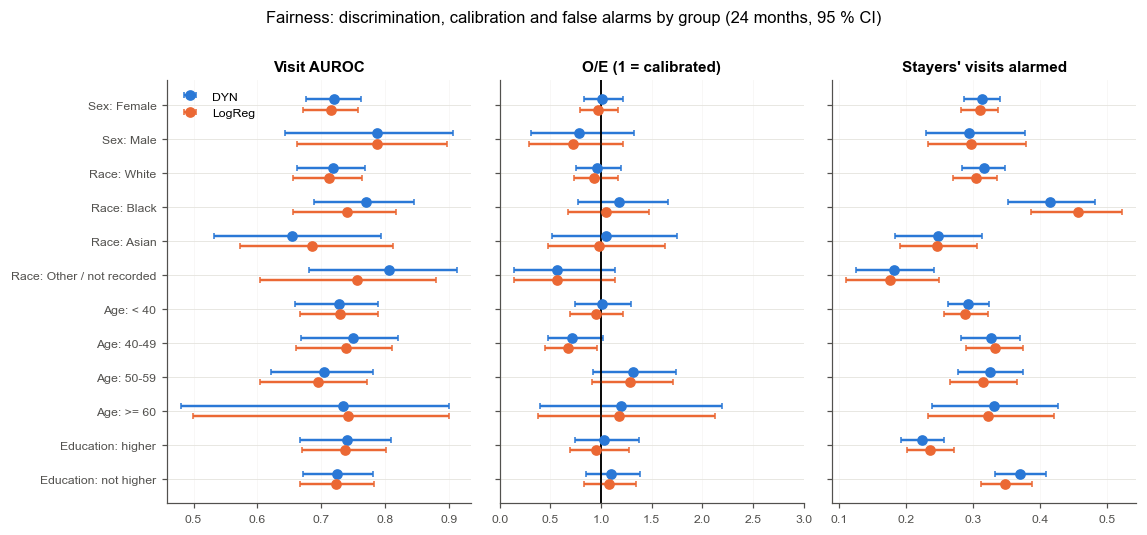

Groups whose O/E 95 % CI excludes 1 (main model): none


In [123]:
"""Fairness (TRIPOD+AI 14, 23a)."""
_rows_h, _y_h, _w_h = IPCW_H[H]
_Wr_h = _BOTH[:, ROW_PIDX[_rows_h]] * _w_h[None, :]
_edu = LAND_X["EDU_HIGHER"].values
FAIR_GROUPS = {f"Sex: {v_}": LAND_SUB["sex"].values == v_ for v_ in ["Female", "Male"]}
FAIR_GROUPS.update({f"Race: {v_}": LAND_SUB["race"].values == v_ for v_ in ["White", "Black", "Asian",
                                                                             "Other / not recorded"]})
FAIR_GROUPS.update({f"Age: {v_}": LAND_SUB["age_band"].values == v_ for _, _, v_ in AGE_BANDS})
FAIR_GROUPS.update({"Education: higher": _edu == 1, "Education: not higher": _edu == 0})


def _rmean(arrs):
    return np.nanmean(np.vstack(arrs), 0)


def group_metrics(m, mask_rows):
    k = mask_rows[_rows_h]
    y, Wr = _y_h[k], _Wr_h[:, k]
    out = {"auroc": [], "oe": [], "sens": [], "fpr": []}
    for r in REPEATS:
        z = zpred(m, r)[_rows_h][k]
        out["auroc"].append(wauc(y, z, Wr))
        out["oe"].append((Wr @ y) / (Wr @ _expit(z)))
        cs = confusion_stats(y, z >= THR_V[m][r][H][MAIN_THRESHOLD][_rows_h][k], Wr)
        out["sens"].append(cs["sensitivity"]); out["fpr"].append(1 - cs["specificity"])
    return {k_: _rmean(v) for k_, v in out.items()}, int(y.sum()), int(k.sum())


_f = lambda a: fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5]))
rows = []
FAIR_RAW = {}
for m in [MAIN_MODEL, LOGREG]:
    for g_, mask in FAIR_GROUPS.items():
        res_, n_ev, n_l = group_metrics(m, mask)
        FAIR_RAW[(m, g_)] = res_
        rows.append({"Model": short_label(m), "Group": g_, "Landmarks": n_l, "Onset landmarks": n_ev,
                     "AUROC": _f(res_["auroc"]), "O/E": _f(res_["oe"]),
                     "Stayers' visits alarmed": _f(res_["fpr"]), "Onset visits alarmed": _f(res_["sens"])})
FAIRNESS = pd.DataFrame(rows).set_index(["Model", "Group"])
display(FAIRNESS)
FAIRNESS.to_csv(f"tripod_fairness_{TAG}.csv")

_gl = list(FAIR_GROUPS)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 0.28 * len(_gl) + 1.4), sharey=True)
yy = np.arange(len(_gl))[::-1]
for j, m in enumerate([MAIN_MODEL, LOGREG]):
    off = 0.15 * (1 - 2 * j)
    for ax, (met, lab_, ref) in zip(axes, [("auroc", "Visit AUROC", None), ("oe", "O/E (1 = calibrated)", 1.0),
                                          ("fpr", "Stayers' visits alarmed", None)]):
        v = np.array([[FAIR_RAW[(m, g_)][met][0], *np.nanpercentile(FAIR_RAW[(m, g_)][met][1:], [2.5, 97.5])]
                      for g_ in _gl])
        ax.errorbar(v[:, 0], yy + off, xerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o", color=model_color(m),
                    capsize=2, label=short_label(m))
        if ref:
            ax.axvline(ref, color="k", lw=1)
        ax.set_title(lab_, fontsize=10); ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(yy); axes[0].set_yticklabels(_gl, fontsize=8); axes[0].legend(fontsize=8)
axes[1].set_xlim(0, 3)
fig.suptitle(f"Fairness: discrimination, calibration and false alarms by group ({H} months, 95 % CI)", y=1.01)
plt.tight_layout(); save_fig("fairness")
_oe_main = {g_: FAIR_RAW[(MAIN_MODEL, g_)]["oe"] for g_ in _gl}
_mis = [g_ for g_, a in _oe_main.items() if np.nanpercentile(a[1:], 2.5) > 1 or np.nanpercentile(a[1:], 97.5) < 1]
print("Groups whose O/E 95 % CI excludes 1 (main model): " + (", ".join(_mis) if _mis else "none"))

## 19.5 Performance by length of clinic history; a new patient

The main model reads up to 2 years of history on the 6-month grid; a patient new to the clinic has fewer grid
points (one at their first visit) and their change-from-own-baseline inputs are 0 (no earlier visit). Performance
by the history available at the landmark: < 6 months (the first grid point only), 6-24 months, the full 2 years
with < 10 years in the clinic, and ≥ 10 years. How a new patient is handled is stated in Section 19.7 (item 27a).

In [124]:
"""Performance by length of history (TRIPOD+AI 27a)."""
_yrs_hist = (LG_LEN - 1) * GRID_STEP_MONTHS / 12
HIST_GROUPS = {"< 6 months of history (first grid point only)": LG_LEN == 1,
               "6-24 months": (LG_LEN >= 2) & (LG_LEN < 5),
               "Full 2 years, < 10 years in clinic": (LG_LEN >= 5) & (land["YRS_IN_CLINIC"].values < 10),
               ">= 10 years in clinic": (LG_LEN >= 5) & (land["YRS_IN_CLINIC"].values >= 10)}
rows = []
for m in [MAIN_MODEL, LOGREG, BASELINE]:
    for g_, mask in HIST_GROUPS.items():
        res_, n_ev, n_l = group_metrics(m, mask)
        rows.append({"Model": short_label(m), "History": g_, "Landmarks": n_l, "Onset landmarks": n_ev,
                     "AUROC": _f(res_["auroc"]) if n_ev >= 5 else "-", "O/E": _f(res_["oe"]),
                     "Onset visits alarmed": _f(res_["sens"])})
HISTORY = pd.DataFrame(rows).set_index(["Model", "History"])
display(HISTORY)
HISTORY.to_csv(f"tripod_history_length_{TAG}.csv")
print(f"Landmarks by history: " + ", ".join(f"{g_}: {mask.mean():.0%}" for g_, mask in HIST_GROUPS.items()))

Landmarks  Onset landmarks                   AUROC                     O/E    Onset visits alarmed
Model    History                                                                                                                                          
DYN      < 6 months of history (first grid point only)       1264               81  0.651 (0.579 to 0.722)  1.242 (0.889 to 1.615)  0.800 (0.715 to 0.878)
         6-24 months                                         2304              101  0.764 (0.698 to 0.824)  0.922 (0.625 to 1.228)  0.839 (0.762 to 0.912)
         Full 2 years, < 10 years in clinic                  7419              273  0.726 (0.661 to 0.790)  1.024 (0.765 to 1.311)  0.604 (0.496 to 0.706)
         >= 10 years in clinic                               4192              109  0.694 (0.580 to 0.785)  0.851 (0.523 to 1.228)  0.477 (0.281 to 0.653)
LogReg   < 6 months of history (first grid point only)       1264               81  0.648 (0.575 to 0.720)  1.077 (0.772 to 1.406)  0.780 (0.685 to 0.871)
         6-24 months                                         2304              101  0.762 (0.697 to 0.828)  0.969 (0.662 to 1.290)  0.765 (0.670 to 0.858)
         Full 2 years, < 10 years in clinic                  7419              273  0.720 (0.658 to 0.782)  0.966 (0.727 to 1.233)  0.598 (0.490 to 0.703)
         >= 10 years in clinic                               4192              109  0.677 (0.544 to 0.779)  0.804 (0.488 to 1.161)  0.492 (0.311 to 0.650)
Baseline < 6 months of history (first grid point only)       1264               81  0.592 (0.504 to 0.678)  1.431 (1.025 to 1.876)  0.672 (0.555 to 0.784)
         6-24 months                                         2304              101  0.600 (0.512 to 0.688)  0.987 (0.671 to 1.340)  0.657 (0.507 to 0.790)
         Full 2 years, < 10 years in clinic                  7419              273  0.625 (0.542 to 0.708)  0.911 (0.678 to 1.169)  0.619 (0.507 to 0.723)
         >= 10 years in clinic                               4192              109  0.598 (0.510 to 0.695)  0.813 (0.492 to 1.184)  0.321 (0.203 to 0.469)

Landmarks by history: < 6 months of history (first grid point only): 8%, 6-24 months: 15%, Full 2 years, < 10 years in clinic: 48%, >= 10 years in clinic: 29%


## 19.6 Temporal hold-out: develop before 2012, evaluate from 2012

Every modelling choice in this notebook (the variables, the grid, the hazard form, the main model and the metrics)
was made after many earlier analyses of the same patients on the same cross-validation folds, so the CV estimates
are optimistic by an unknown amount (item 12c). The temporal hold-out is the least optimistic estimate available:

* **Development**: landmarks before 1 January 2012, with every follow-up **truncated at that date** (onsets,
  competing exits and time at risk after it are not seen; the 24-month label is resolved only if known by then).
* **Evaluation**: landmarks from 1 January 2012 (the recent era of Sections 13.5 and 16.6), outcomes as in the main
  analysis. Patients seen in both periods contribute to both, with no information from after 2012 in development.
* **Models**: the main model (5 seeds, its fixed configuration), LogReg (its most-chosen CV penalty) and the
  Baseline (its most-chosen CV penalty). The calendar year is clipped to the development years, as in use.
* **No recalibration**: the risks are the models' own, so O/E and the calibration intercept show how the risk
  transports to later years. The CV estimates on the same landmarks (recalibrated) are shown alongside.
* Metrics: visit AUROC, O/E, calibration slope and intercept (24 months, IPCW), the time-matched patient AUROC
  (onsets from 2014 whose 24-month window and controls lie entirely in the evaluation period), and the risk tiers.

Development: 9,052 landmarks, 660 patients, 110 onsets seen before 2012-01-01 | evaluation: 8,286 landmarks, 747 patients, 45 onsets | in both periods: 348 patients


,Development (mean),Evaluation (mean),SMD
Age,41.016,42.866,0.174
SLEDAI-2K,3.807,3.252,-0.144
SDI damage score,1.951,1.921,-0.014
"Prednisone, average dose since last visit (mg/day)",5.650,3.277,-0.312
Antimalarial (HCQ; chloroquine in earlier years),0.683,0.808,0.290
"Conventional immunosuppressant (AZA, MTX, MMF)",0.381,0.550,0.344
Fatigue,0.121,0.071,-0.171
Fibromyalgia,0.142,0.077,-0.208
Current smoker,0.119,0.064,-0.191
Education: higher,0.436,0.513,0.155


Evaluation: 6,525 landmarks with a known 24-month status (141 onset landmarks); time-matched: 38 onsets, 12,808 pairs


Model,DYN,LogReg,Baseline
Visit AUROC: temporal,0.671 (0.567 to 0.770),0.659 (0.568 to 0.749),0.583 (0.481 to 0.690)
"Visit AUROC: CV, same landmarks",0.710 (0.610 to 0.805),0.673 (0.571 to 0.770),0.608 (0.510 to 0.701)
O/E: temporal,0.641 (0.433 to 0.869),0.349 (0.237 to 0.476),0.679 (0.460 to 0.922)
"O/E: CV, same landmarks",0.817 (0.557 to 1.106),0.803 (0.547 to 1.099),0.787 (0.535 to 1.071)
Calibration slope: temporal,0.869,1.247,0.710
"Calibration slope: CV, same landmarks",1.149,0.836,0.887
Calibration intercept: temporal,-0.468,-1.101,-0.400
"Calibration intercept: CV, same landmarks",-0.211,-0.230,-0.246
Time-matched patient AUROC: temporal,0.691 (0.597 to 0.783),0.683 (0.603 to 0.768),0.623 (0.532 to 0.719)
"Time-matched patient AUROC: CV, same landmarks",0.726 (0.641 to 0.811),0.684 (0.598 to 0.776),0.598 (0.511 to 0.688)


Difference (95% CI)       Verdict
Comparison     Metric                                                           
DYN - LogReg   Visit AUROC                 0.012 (-0.014 to 0.040)  inconclusive
               Time-matched patient AUROC  0.007 (-0.025 to 0.043)  inconclusive
DYN - Baseline Visit AUROC                 0.089 (-0.041 to 0.224)  inconclusive
               Time-matched patient AUROC  0.068 (-0.055 to 0.199)  inconclusive

Share of visits Mean predicted         Observed (IPCW)         Share of onsets
Model    Tier                                                                                  
DYN      < 2 %             46.0%          0.014  0.012 (0.005 to 0.019)  0.271 (0.145 to 0.408)
         2-4 %             32.1%          0.028  0.016 (0.008 to 0.024)  0.251 (0.156 to 0.345)
         4-10 %            18.6%          0.059  0.035 (0.019 to 0.054)  0.325 (0.213 to 0.441)
         >= 10 %            3.3%          0.148  0.094 (0.036 to 0.161)  0.154 (0.066 to 0.261)
LogReg   < 2 %              0.0%          0.020  0.000 (0.000 to 0.000)  0.000 (0.000 to 0.000)
         2-4 %             26.0%          0.034  0.010 (0.004 to 0.017)  0.135 (0.061 to 0.219)
         4-10 %            66.2%          0.058  0.021 (0.014 to 0.029)  0.682 (0.596 to 0.766)
         >= 10 %            7.8%          0.129  0.047 (0.022 to 0.079)  0.183 (0.101 to 0.276)
Baseline < 2 %             25.5%          0.016  0.014 (0.004 to 0.027)  0.179 (0.052 to 0.328)
         2-4 %             57.5%          0.029  0.020 (0.012 to 0.030)  0.574 (0.397 to 0.741)
         4-10 %            16.8%          0.052  0.029 (0.011 to 0.052)  0.239 (0.107 to 0.397)
         >= 10 %            0.1%          0.108  0.106 (0.106 to 0.106)  0.007 (0.000 to 0.026)

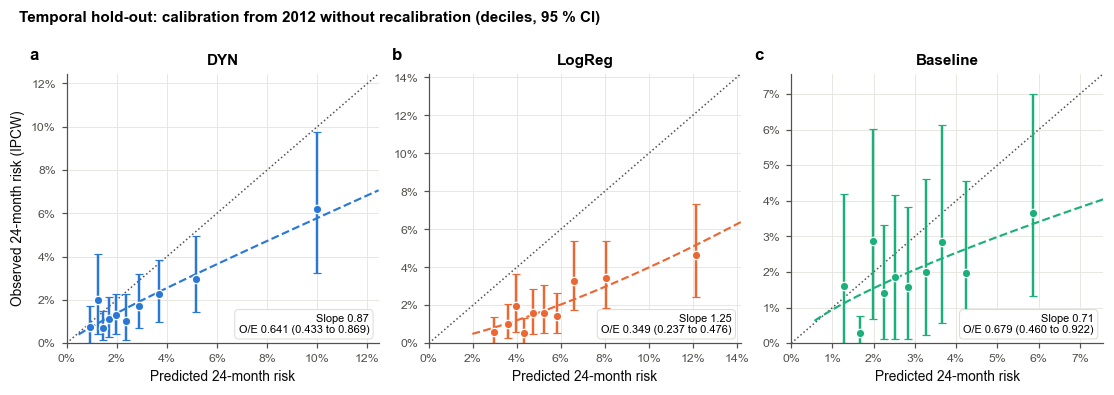

Temporal hold-out (develop < 2012, evaluate >= 2012), DYN: visit AUROC 0.671 (0.567 to 0.770), time-matched patient
AUROC 0.691 (0.597 to 0.783), O/E 0.641 (0.433 to 0.869), calibration slope 0.87. DYN - LogReg Visit AUROC: 0.012
(-0.014 to 0.040) (inconclusive); DYN - LogReg Time-matched patient AUROC: 0.007 (-0.025 to 0.043) (inconclusive); DYN
- Baseline Visit AUROC: 0.089 (-0.041 to 0.224) (inconclusive); DYN - Baseline Time-matched patient AUROC: 0.068
(-0.055 to 0.199) (inconclusive).


In [125]:
"""Temporal hold-out (TRIPOD+AI 12c, 16, 20c)."""
TEMPORAL_CUT = pd.Timestamp("2012-01-01")
TEMPORAL_MODELS = [MAIN_MODEL, LOGREG, BASELINE]
_cut = float((TEMPORAL_CUT - pd.Timestamp("1970-01-01")).days)
DEV = _LAND_T < _cut
VAL = ~DEV
_seen = T_ALL <= _cut - _LAND_T
_ydev = np.where((C_ALL == 1) & _seen & (T_ALL <= HORIZON_DAYS), 1.0,
                 np.where((np.minimum(T_ALL, _cut - _LAND_T) > HORIZON_DAYS)
                          | ((C_ALL >= 2) & _seen & (T_ALL <= HORIZON_DAYS)), 0.0, np.nan))
_ydev[np.isnan(Y_ALL) & (_ADMIN < HORIZON_DAYS)] = np.nan
_ydev[~DEV] = np.nan
A_DEV = {"D1": (D_ONSET * (INT_END <= _cut)).astype(np.float32), "D2": (D_COMP * (INT_END <= _cut)).astype(np.float32),
         "DT": np.clip((np.minimum(INT_END, _cut) - INT_START) / 365.25, 1e-6, None).astype(np.float32),
         "Y": _ydev, "LAB": ~np.isnan(_ydev), "USE": DEV}
dev_p, val_p = np.unique(PID_ALL[DEV]), np.unique(PID_ALL[VAL])
print(f"Development: {int(DEV.sum()):,} landmarks, {len(dev_p)} patients, {int(A_DEV['D1'][DEV].sum())} onsets seen "
      f"before {TEMPORAL_CUT.date()} | evaluation: {int(VAL.sum()):,} landmarks, {len(val_p)} patients, "
      f"{int(D_ONSET[VAL].sum())} onsets | in both periods: {len(np.intersect1d(dev_p, val_p))} patients")

# the development-period comparison of the inputs (item 20c)
_cmp_vars = ["age_at_record", "SLEDAI2_I", "score_n", "STERAVER_0", "AM_CLASS", "IS_CLASS", "FATIGUE", "FIBROMYALGIA",
             "SMOKER", "EDU_HIGHER", "VISIT_RATE_1Y", "YRS_IN_CLINIC"]
DEV_VS_VAL = pd.DataFrame({"Development (mean)": LAND_X.loc[DEV, _cmp_vars].astype(float).mean(),
                           "Evaluation (mean)": LAND_X.loc[VAL, _cmp_vars].astype(float).mean(),
                           "SMD": [_smd(LAND_X.loc[VAL, c].astype(float).values, LAND_X.loc[DEV, c].astype(float).values)
                                   for c in _cmp_vars]})
DEV_VS_VAL.index = [DISPLAY_NAMES.get(c, c) for c in DEV_VS_VAL.index]
DEV_VS_VAL.loc[f"{H}-month onset rate (resolved landmarks)"] = [np.nanmean(Y_ALL[DEV]), np.nanmean(Y_ALL[VAL]), np.nan]
display(DEV_VS_VAL.round(3))

TEMPORAL_PATH = f"temporal_state_{TAG}{'_smoke' if SMOKE else ''}.pkl"
TEMP = _load(TEMPORAL_PATH, {})
TEMP = {k_: v_ for k_, v_ in TEMP.items() if np.ndim(v_) == 2}          # raw scores only
for m in TEMPORAL_MODELS:
    if m in TEMP:
        continue
    t0 = time.time()
    vrows = rows_of(val_p)
    if is_reg(m):
        cfg = model_grid(m)[pd.Series(BEST_CFG[m]).value_counts().index[0]]
        frows = rows_of(dev_p)
        prep_rows = frows[DEV[frows] & (A_DEV["LAB"][frows] if parse_model(m)["target"] == "BIN" else True)]
        eta, _ = fit_reg(m, cfg, prep_rows, frows, vrows, arrs=A_DEV)
    else:
        d_ = parse_model(m)
        st_, ln_ = grid_window(d_["lookback"])
        VX = GridPrep(grid_cols_of(m)).fit(np.flatnonzero(DEV)).transform(GRID_RAW)
        res = Parallel(n_jobs=SEQ_N_JOBS, backend="loky")(
            delayed(fit_grid)(SEQ_CFG, VX, st_, ln_, dev_p, SEED + 500 + 31 * s, val_p, d_["hazard"], False, None,
                              False, A_DEV) for s in range(SEQ_SEEDS_FINAL))
        z = np.zeros((N_LAND, 2)); cnt = np.zeros(N_LAND)
        for rows_, zz in res:
            z[rows_] += zz; cnt[rows_] += 1
        eta = z[vrows] / np.maximum(cnt[vrows], 1)[:, None]
    ef = np.full((N_LAND, eta.shape[1]), np.nan); ef[vrows] = eta          # the raw scores: any horizon can be read
    ef[~VAL] = np.nan
    TEMP[m] = ef
    _save(TEMP, TEMPORAL_PATH)
    print(f"  {short_label(m)} fitted on the development period ({(time.time() - t0) / 60:.1f} min)")

TEMP_Z = {m: np.where(VAL, raw_logit(np.nan_to_num(TEMP[m]), H), np.nan) for m in TEMPORAL_MODELS}
_vr = VAL[_rows_h]
_rows_v, _y_v, _w_v = _rows_h[_vr], _y_h[_vr], _w_h[_vr]
_Wv = _BOTH[:, ROW_PIDX[_rows_v]] * _w_v[None, :]
_dtm = TM["main"]
_ent_val = np.asarray(_dtm["mat"] @ (~VAL).astype(float)).ravel() == 0          # every row of the entity is >= cut
_pm = _ent_val[_dtm["pc"]] & _ent_val[_dtm["pk"]]
_tm_den = _pair_sum_fast(_BOTH, sparse.coo_matrix((np.ones(_pm.sum()), (_dtm["ppc"][_pm], _dtm["ppk"][_pm])),
                                                  shape=(P_, P_)).toarray())


def temporal_metrics(z):
    zv = z[_rows_v]
    out = {"Visit AUROC": wauc(_y_v, zv, _Wv),
           "O/E": (_Wv @ _y_v) / (_Wv @ _expit(zv))}
    sl, ic = wcalibration(_y_v, zv, _w_v)
    out["Calibration slope"], out["Calibration intercept"] = np.array([sl]), np.array([ic])
    s = np.asarray(_dtm["mat"] @ np.nan_to_num(z)).ravel()
    a, b = s[_dtm["pc"][_pm]], s[_dtm["pk"][_pm]]
    K = sparse.coo_matrix(((a > b) + 0.5 * (a == b), (_dtm["ppc"][_pm], _dtm["ppk"][_pm])), shape=(P_, P_)).toarray()
    out["Time-matched patient AUROC"] = _pair_sum_fast(_BOTH, K) / _tm_den
    return out


_ff = lambda a: fmt(a[0], *np.nanpercentile(a[1:], [2.5, 97.5])) if len(a) > 1 else f"{a[0]:.3f}"
rows, TEMP_MET = [], {}
for m in TEMPORAL_MODELS:
    mt = temporal_metrics(TEMP_Z[m])
    cv = [temporal_metrics(zpred(m, r)) for r in REPEATS]
    TEMP_MET[m] = mt
    row = {"Model": short_label(m)}
    for k_ in mt:
        row[f"{k_}: temporal"] = _ff(mt[k_])
        row[f"{k_}: CV, same landmarks"] = _ff(np.mean([c_[k_] for c_ in cv], 0))
    rows.append(row)
TEMPORAL = pd.DataFrame(rows).set_index("Model").T
print(f"Evaluation: {len(_rows_v):,} landmarks with a known {H}-month status ({int(_y_v.sum())} onset landmarks); "
      f"time-matched: {len(np.unique(_dtm['pc'][_pm]))} onsets, {int(_pm.sum()):,} pairs")
display(TEMPORAL)
TEMPORAL.to_csv(f"tripod_temporal_{TAG}.csv")
rows = []
for a_, b_ in [(MAIN_MODEL, LOGREG), (MAIN_MODEL, BASELINE)]:
    for k_ in ["Visit AUROC", "Time-matched patient AUROC"]:
        dlt = TEMP_MET[a_][k_] - TEMP_MET[b_][k_]
        lo, hi = np.nanpercentile(dlt[1:], [2.5, 97.5])
        rows.append({"Comparison": f"{short_label(a_)} - {short_label(b_)}", "Metric": k_, "Difference (95% CI)":
                     fmt(dlt[0], lo, hi), "Verdict": verdict_superiority(lo, hi, EQUIV_MARGIN)})
TEMPORAL_CMP = pd.DataFrame(rows).set_index(["Comparison", "Metric"])
display(TEMPORAL_CMP)
TEMPORAL_CMP.to_csv(f"tripod_temporal_contrasts_{TAG}.csv")

# risk tiers in the evaluation period, the models' own risks
_y1v = (_y_v == 1).astype(np.float32)
rows = []
for m in TEMPORAL_MODELS:
    p_ = _expit(TEMP_Z[m][_rows_v])
    for lo, hi, name in RISK_TIERS:
        inn = ((p_ >= lo) & (p_ < hi)).astype(np.float32)
        rows.append({"Model": short_label(m), "Tier": name, "Share of visits": f"{(_w_v @ inn) / _w_v.sum():.1%}",
                     "Mean predicted": f"{p_[inn > 0].mean():.3f}" if inn.any() else "-",
                     "Observed (IPCW)": _ff(_ratio(_Wv @ (_y1v * inn), _Wv @ inn)),
                     "Share of onsets": _ff(_ratio(_Wv @ (_y1v * inn), _Wv @ _y1v))})
TEMPORAL_TIERS = pd.DataFrame(rows).set_index(["Model", "Tier"])
display(TEMPORAL_TIERS)
TEMPORAL_TIERS.to_csv(f"tripod_temporal_tiers_{TAG}.csv")

fig, axes = plt.subplots(1, len(TEMPORAL_MODELS), figsize=(3.4 * len(TEMPORAL_MODELS), 3.6), squeeze=False)
_Wbv = _BOTH[:, ROW_PIDX[_rows_v]]
for k_, (ax, m) in enumerate(zip(axes[0], TEMPORAL_MODELS)):
    p_ = _expit(TEMP_Z[m][_rows_v])
    cuts = np.quantile(p_, np.linspace(0, 1, CAL_DECILES + 1))
    b_ = np.clip(np.searchsorted(cuts, p_, side="right") - 1, 0, CAL_DECILES - 1)
    oh = np.eye(CAL_DECILES, dtype=np.float32)[b_]
    obs = (_Wbv @ (oh * (_w_v * _y_v)[:, None])) / (_Wbv @ (oh * _w_v[:, None]))
    pr = (oh * (_w_v * p_)[:, None]).sum(0) / (oh * _w_v[:, None]).sum(0)
    lo, hi = np.nanpercentile(obs[1:], [2.5, 97.5], 0)
    top = max(float(np.percentile(p_, 97.5)), pr[-1], float(np.nanmax(hi))) * 1.08
    lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p_)[:, None], _y_v, sample_weight=_w_v)
    g_ = np.linspace(max(p_.min(), 1e-4), top, 100)
    ax.plot([0, top], [0, top], ":", color=INK_2, lw=1)
    ax.plot(g_, _expit(lr_.intercept_[0] + lr_.coef_[0, 0] * _logit(g_)), "--", color=model_color(m), lw=1.4)
    ax.errorbar(pr, obs[0], yerr=[np.clip(obs[0] - lo, 0, None), np.clip(hi - obs[0], 0, None)], fmt="o",
                color=model_color(m), ms=5.5, mec="white", mew=0.8, capsize=2.5)
    t_ = TEMP_MET[m]
    ax.text(0.97, 0.03, f"Slope {t_['Calibration slope'][0]:.2f}\nO/E {_ff(t_['O/E'])}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=7.2, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#d9d8d3", lw=0.6))
    ax.set_xlim(0, top); ax.set_ylim(0, top); ax.set_title(short_label(m))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{100 * t:.0f}%"))
    ax.set_xlabel(f"Predicted {H}-month risk")
    if k_ == 0:
        ax.set_ylabel(f"Observed {H}-month risk (IPCW)")
    panel_label(ax, "abc"[k_])
fig.suptitle(f"Temporal hold-out: calibration from {TEMPORAL_CUT.year} without recalibration (deciles, 95 % CI)",
             x=0.02, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout(); save_fig("temporal_calibration")
_t = TEMP_MET[MAIN_MODEL]
TEMPORAL_SUMMARY = (f"Temporal hold-out (develop < {TEMPORAL_CUT.year}, evaluate >= {TEMPORAL_CUT.year}), "
                    f"{short_label(MAIN_MODEL)}: visit AUROC {_ff(_t['Visit AUROC'])}, time-matched patient AUROC "
                    f"{_ff(_t['Time-matched patient AUROC'])}, O/E {_ff(_t['O/E'])}, calibration slope "
                    f"{_t['Calibration slope'][0]:.2f}. " + "; ".join(
                        f"{i[0]} {i[1]}: {r_['Difference (95% CI)']} ({r_['Verdict']})"
                        for i, r_ in TEMPORAL_CMP.iterrows()) + ".")
print(textwrap.fill(TEMPORAL_SUMMARY, 118))

## 19.7 TRIPOD+AI checklist

Each item, whether it is reported, and where (N = notebook section; M = manuscript only). "Partly" means the
notebook gives what it can and the manuscript must complete it.

In [126]:
"""TRIPOD+AI checklist."""
_tm_t = _ff(TEMP_MET[MAIN_MODEL]["Time-matched patient AUROC"])
CHECKLIST = pd.DataFrame([
    ("1", "Title", "Identify as developing/evaluating a prediction model, target population, outcome", "M", "Manuscript"),
    ("2", "Abstract", "TRIPOD+AI for Abstracts", "M", "Manuscript"),
    ("3a", "Background", "Healthcare context, rationale, intended use", "Partly", "N1 (motivation); M"),
    ("3b", "Background", "Intended users and place in the care pathway", "Partly",
     "N13.5 (risk tiers: rheumatologist at a routine visit, to target vocational support); M"),
    ("3c", "Background", "Known health inequalities between groups", "M", "Manuscript (work disability by race, "
     "education, sex in SLE)"),
    ("4", "Objectives", "Objectives, development and/or evaluation", "Yes", "N0, N8 (objectives, hypotheses)"),
    ("5a", "Data", "Data sources, rationale, representativeness", "Partly", "N2, N19.1; M (single centre)"),
    ("5b", "Data", "Dates of data collection, follow-up end", "Yes", "N19.1"),
    ("6a", "Participants", "Setting, number and location of centres", "Partly", "N2, N19.1 (one centre); M"),
    ("6b", "Participants", "Eligibility criteria", "Yes", "N2, N4, N19.1 (flow)"),
    ("6c", "Participants", "Treatments received", "Yes", "N19.2 (Table 1: prednisone, antimalarial, immunosuppressants)"),
    ("7", "Data preparation", "Pre-processing, quality checks, consistency across groups", "Yes",
     "N11.3b, N11.4 (grid, preprocessing in training folds), N19.2 (missingness by group)"),
    ("8a", "Outcome", "Definition, horizon, how assessed, rationale", "Yes", "N2-N4"),
    ("8b", "Outcome", "Qualifications / demographics of outcome assessors", "M",
     "Manuscript (employment status recorded at clinic visits)"),
    ("8c", "Outcome", "Blinding of outcome assessment", "M", "Manuscript (not blinded: routine clinic data)"),
    ("9a", "Predictors", "Choice of initial predictors, pre-selection", "Partly",
     "N5 (27 clinical and social variables + change variables); M (literature basis)"),
    ("9b", "Predictors", "Definition, how and when measured", "Yes", "N5, N11.3b (on or before the landmark only)"),
    ("9c", "Predictors", "Assessor qualifications / blinding", "M", "Manuscript"),
    ("10", "Sample size", "How the sample size was arrived at; justification", "Yes", "N19.3 (Riley criteria)"),
    ("11", "Missing data", "How handled; reasons for omitting", "Yes", "N11.4, N19.2"),
    ("12a", "Analysis", "How the data were used (development / evaluation), splitting", "Yes",
     "N8, N11.5 (5x5 patient-grouped CV), N19.6 (temporal hold-out)"),
    ("12b", "Analysis", "Predictor handling (functional form, rescaling)", "Yes", "N11.3b, N11.4"),
    ("12c", "Analysis", "Model type, building steps, tuning, internal validation", "Yes",
     f"N6, N11.5, N12; post-hoc selection over many earlier analyses disclosed (N10, N19.6)"),
    ("12d", "Analysis", "Heterogeneity across clusters", "Partly", "N13.6 (by era); single centre"),
    ("12e", "Analysis", "Performance measures and rationale", "Yes", "N9, N11.7, N11.8"),
    ("12f", "Analysis", "Model updating after evaluation", "Yes", "N7 (recalibration in each training fold)"),
    ("12g", "Analysis", "For evaluation: how predictions were calculated", "Yes", "N11 (code); N19.6"),
    ("13", "Class imbalance", "Methods and recalibration", "Yes",
     "No resampling or weighting; recalibration inside each training fold (N7)"),
    ("14", "Fairness", "Methods to address fairness", "Yes", "N19.4 (by sex, race, age, education)"),
    ("15", "Model output", "Output form, thresholds and how chosen", "Yes", "N9, N11.6, N13.5 (risk tiers)"),
    ("16", "Training vs evaluation", "Differences between development and evaluation data", "Yes", "N19.6"),
    ("17", "Ethics", "Ethics approval, consent", "M", "Manuscript"),
    ("18a", "Open science", "Funding", "M", "Manuscript"),
    ("18b", "Open science", "Conflicts of interest", "M", "Manuscript"),
    ("18c", "Open science", "Protocol", "M", "Manuscript (no published protocol: state it)"),
    ("18d", "Open science", "Registration", "M", "Manuscript (not registered: state it)"),
    ("18e", "Open science", "Data sharing", "M", "Manuscript"),
    ("18f", "Open science", "Code sharing", "Partly", "This notebook and build scripts; M (repository link)"),
    ("19", "Patient and public involvement", "Details or statement of none", "M", "Manuscript (none: state it)"),
    ("20a", "Participants", "Flow, numbers with / without the outcome, follow-up", "Yes", "N19.1"),
    ("20b", "Participants", "Characteristics, key dates, missing data", "Yes", "N19.1, N19.2"),
    ("20c", "Participants", "Evaluation vs development distributions", "Yes", "N19.6"),
    ("21", "Model development", "Participants and events in each analysis", "Yes", "N11.3, N19.1, N19.6"),
    ("22", "Model specification", "Full model to allow predictions; access restrictions", "Partly",
     "Code here; trained weights + preprocessing parameters to be released (M)"),
    ("23a", "Performance", "Performance with CIs, incl. key subgroups", "Yes",
     f"N13-N16, N19.4, N19.5; temporal time-matched AUROC {_tm_t}"),
    ("23b", "Performance", "Heterogeneity across clusters", "Partly", "N13.6 (era)"),
    ("24", "Model updating", "Results of updating", "Yes", "N13.3 (recalibrated CV); N19.6 (without updating)"),
    ("25", "Interpretation", "Overall interpretation incl. fairness", "Partly", "N17 (conclusions); M"),
    ("26", "Limitations", "Limitations, biases, generalisability", "Partly", "N10; M"),
    ("27a", "Usability", "Handling poor quality or unavailable inputs", "Yes",
     "N11.4 (median + missing indicator), N19.5 (new patient: fewer grid points, change inputs 0)"),
    ("27b", "Usability", "User interaction / expertise needed", "M", "Manuscript (no user input beyond routine data)"),
    ("27c", "Usability", "Next steps, applicability, generalisability", "M", "Manuscript (external validation)"),
], columns=["Item", "Section", "Requirement", "Reported", "Where"]).set_index("Item")
display(CHECKLIST)
CHECKLIST.to_csv(f"tripod_ai_checklist_{TAG}.csv")
print(f"Reported in the notebook: {int((CHECKLIST['Reported'] == 'Yes').sum())} items; partly: "
      f"{int((CHECKLIST['Reported'] == 'Partly').sum())}; manuscript only: {int((CHECKLIST['Reported'] == 'M').sum())}.")
OBJ_CONCLUSIONS["TRIPOD+AI"] = TEMPORAL_SUMMARY

,Section,Requirement,Reported,Where
Item,,,,
1,Title,Identify as developing/evaluating a prediction...,M,Manuscript
2,Abstract,TRIPOD+AI for Abstracts,M,Manuscript
3a,Background,"Healthcare context, rationale, intended use",Partly,N1 (motivation); M
3b,Background,Intended users and place in the care pathway,Partly,N13.5 (risk tiers: rheumatologist at a routine...
3c,Background,Known health inequalities between groups,M,"Manuscript (work disability by race, education..."
4,Objectives,"Objectives, development and/or evaluation",Yes,"N0, N8 (objectives, hypotheses)"
5a,Data,"Data sources, rationale, representativeness",Partly,"N2, N19.1; M (single centre)"
5b,Data,"Dates of data collection, follow-up end",Yes,N19.1
6a,Participants,"Setting, number and location of centres",Partly,"N2, N19.1 (one centre); M"


Reported in the notebook: 26 items; partly: 11; manuscript only: 15.
